In [12]:
# ============================================================
# Install required SOTA tabular libraries (Kaggle-safe)
# ============================================================

import importlib.util
import sys

def install_if_missing(package_name):
    if importlib.util.find_spec(package_name) is None:
        print(f"Installing {package_name}...")
        !pip install -q {package_name}
    else:
        print(f"{package_name} already installed.")

install_if_missing("deepctr_torch")
install_if_missing("pytorch_tabnet")

Module 0 complete
Project           : TA-MoE Cardiovascular Risk Prediction
Experiment        : brfss2015_tamoe_v1
Seed              : 42
Target            : HeartDiseaseorAttack
Data path         : /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Test size         : 0.2
CV                : 5-fold x 2 repeats
Primary metric    : PR_AUC
Calibration       : platt
Output directory  : /kaggle/working/outputs


Module 0 complete.
Project        : TA-MoE Cardiovascular Risk Prediction
Target         : HeartDiseaseorAttack
Primary metric : PR_AUC
Data path      : /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Output dir     : /kaggle/working/outputs

Loaded dataset.
Raw shape: (253680, 22)

===== Dataset Summary =====
N samples       : 253,680
N features      : 21
Positive count  : 23,893
Negative count  : 229,787
Positive rate   : 0.094186
Negative rate   : 0.905814

===== Feature Groups =====
Binary features   : 14
Ordinal features  : 4
Continuous feats  : 3

===== Development / Hold-out Test Split =====
          split       n  positive_n  negative_n  positive_rate  negative_rate
0   development  202944       19114      183830       0.094184       0.905816
1  holdout_test   50736        4779       45957       0.094193       0.905807

===== Repeated Stratified CV on Development Set =====
   repeat_fold_id  train_size  va

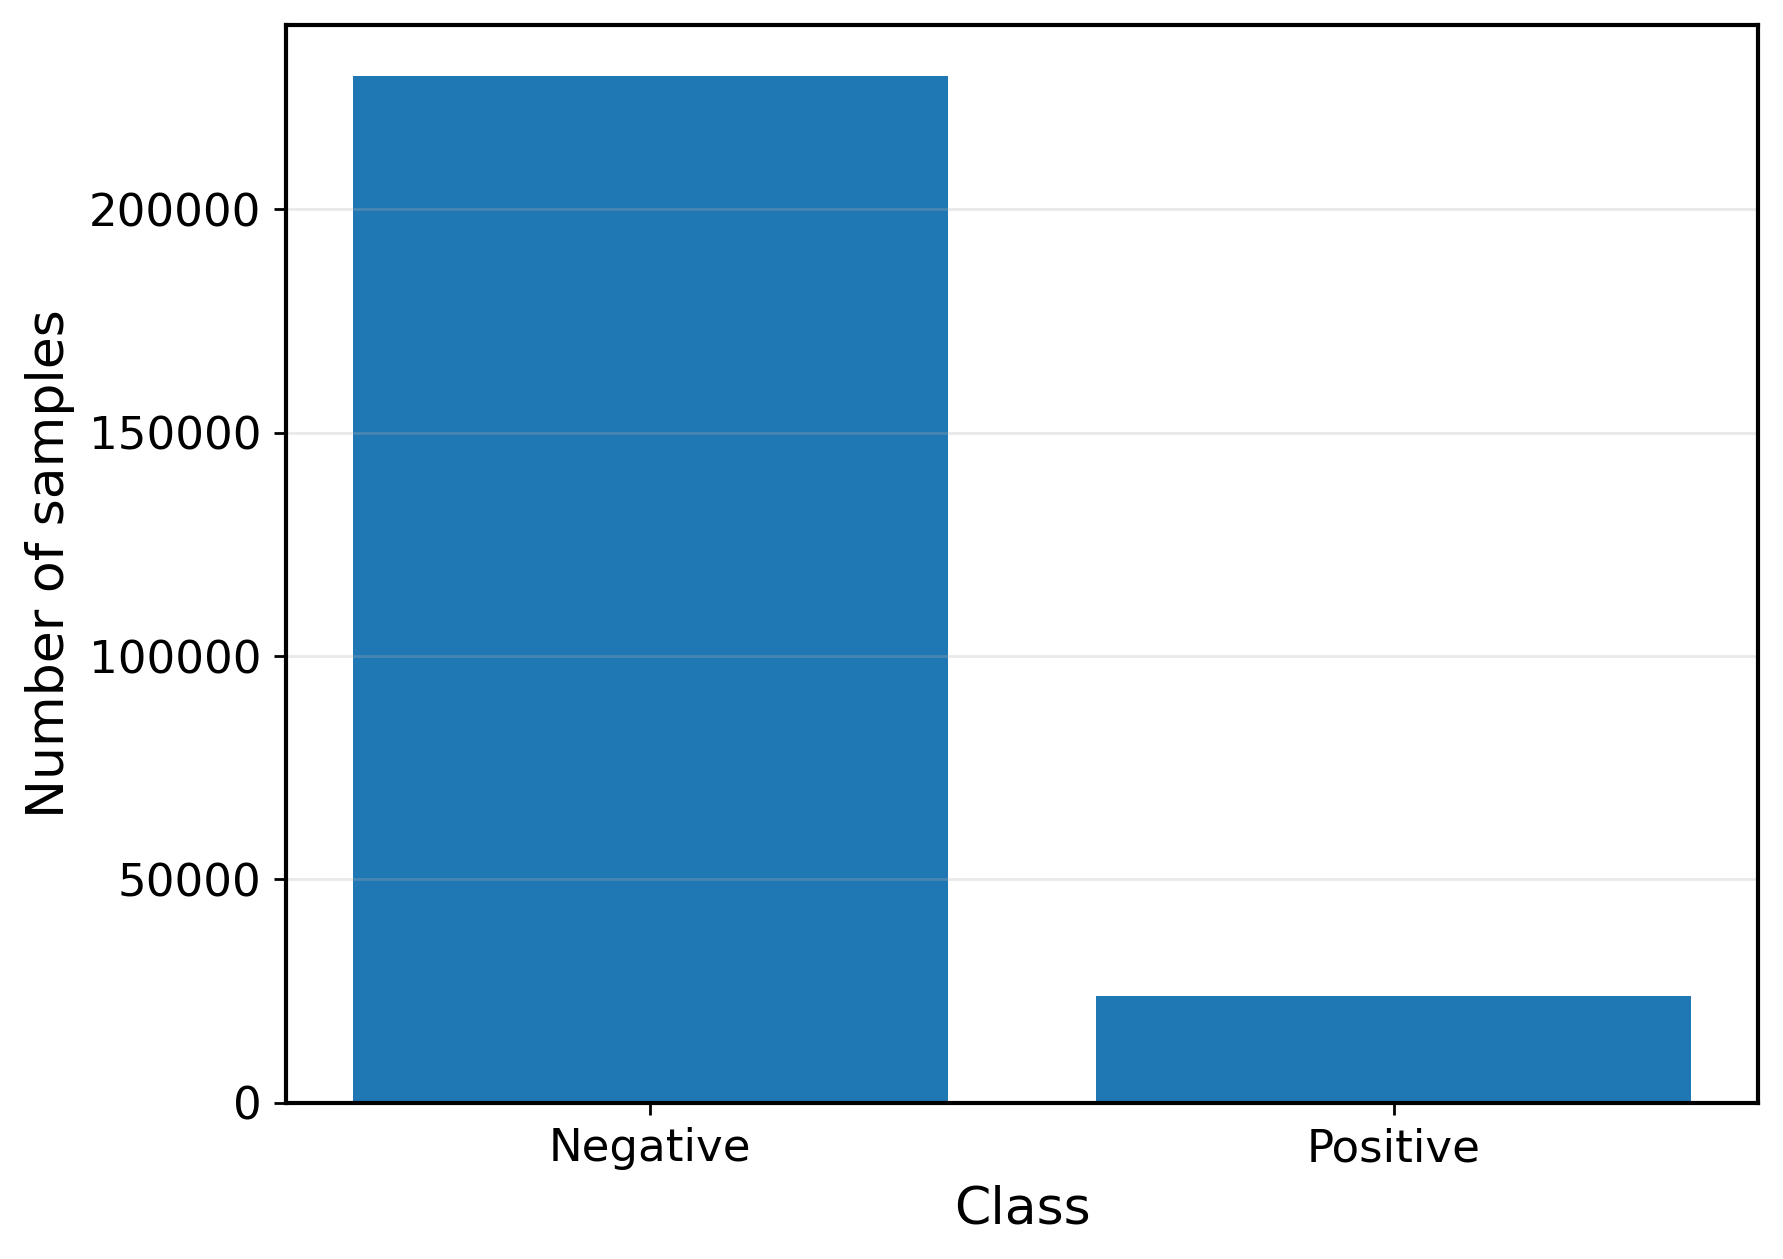

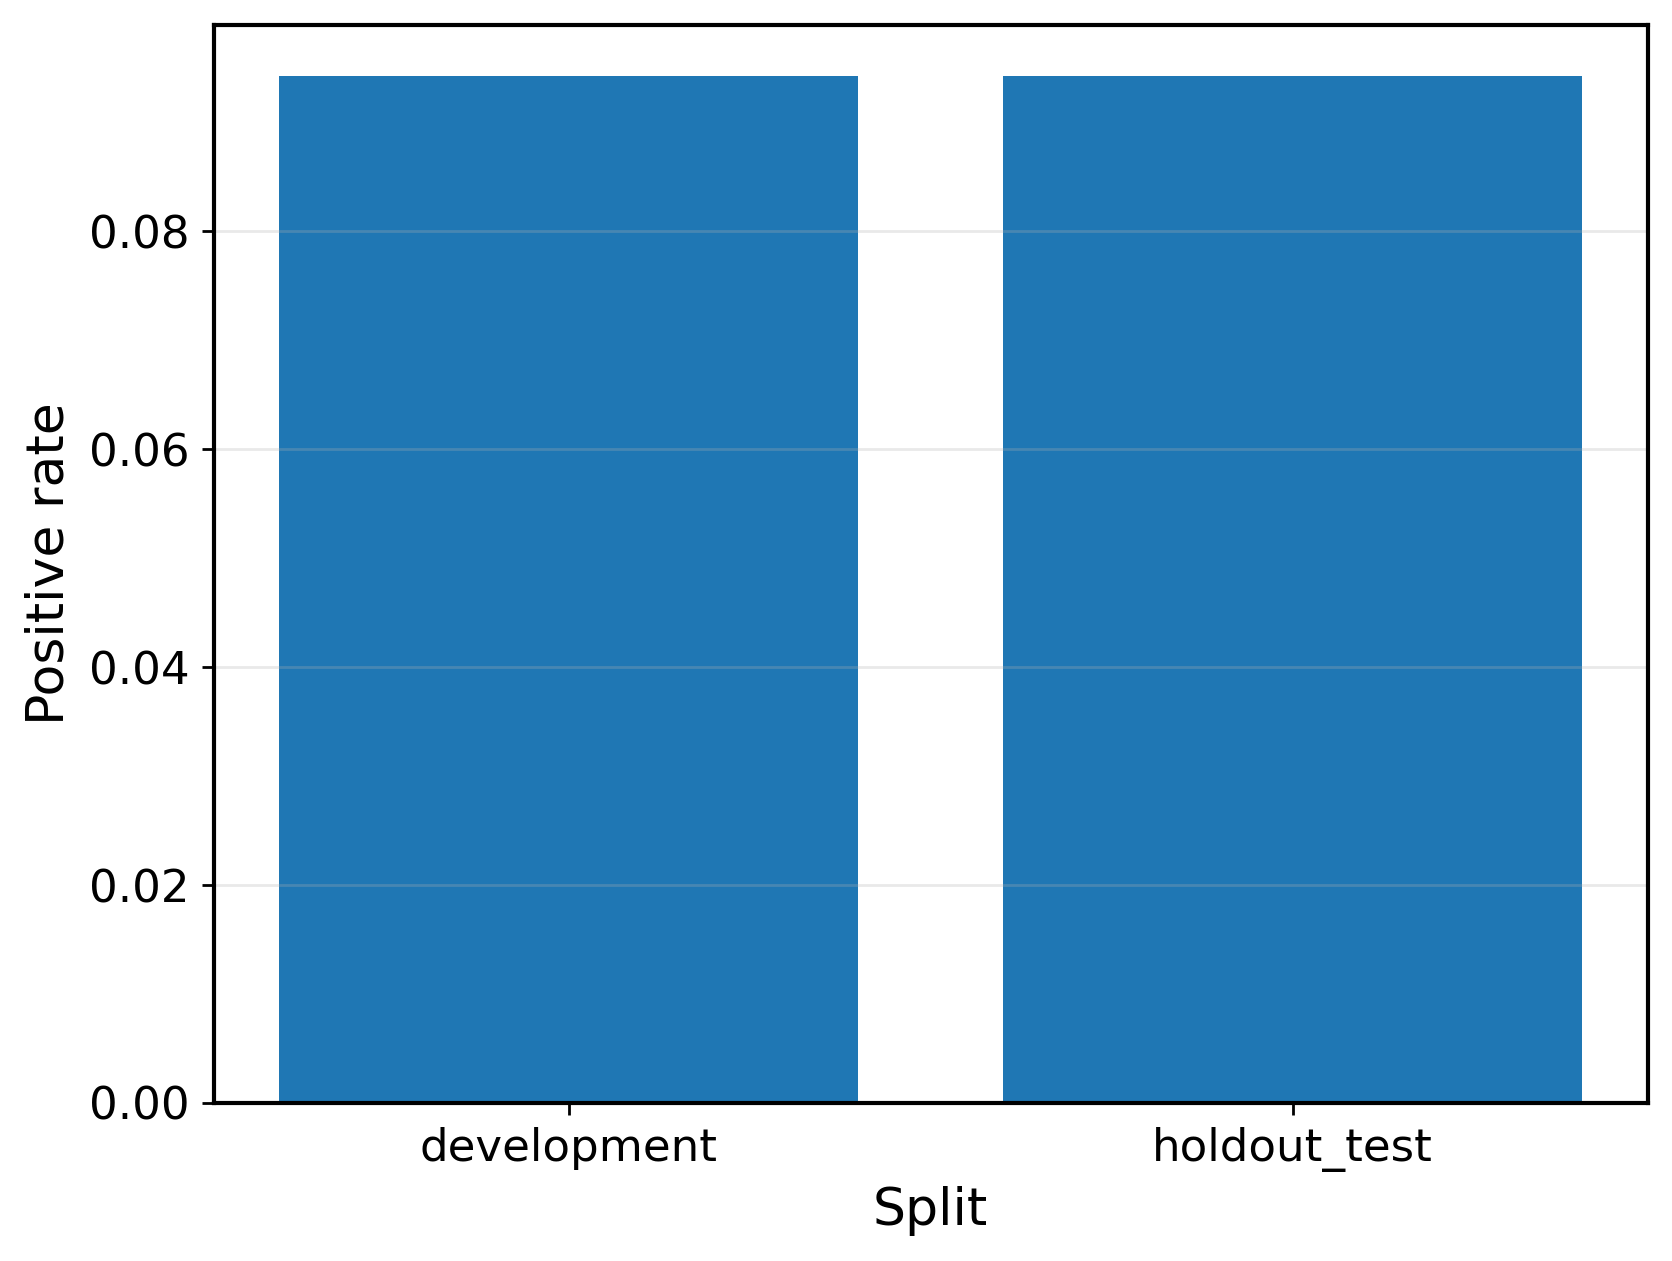

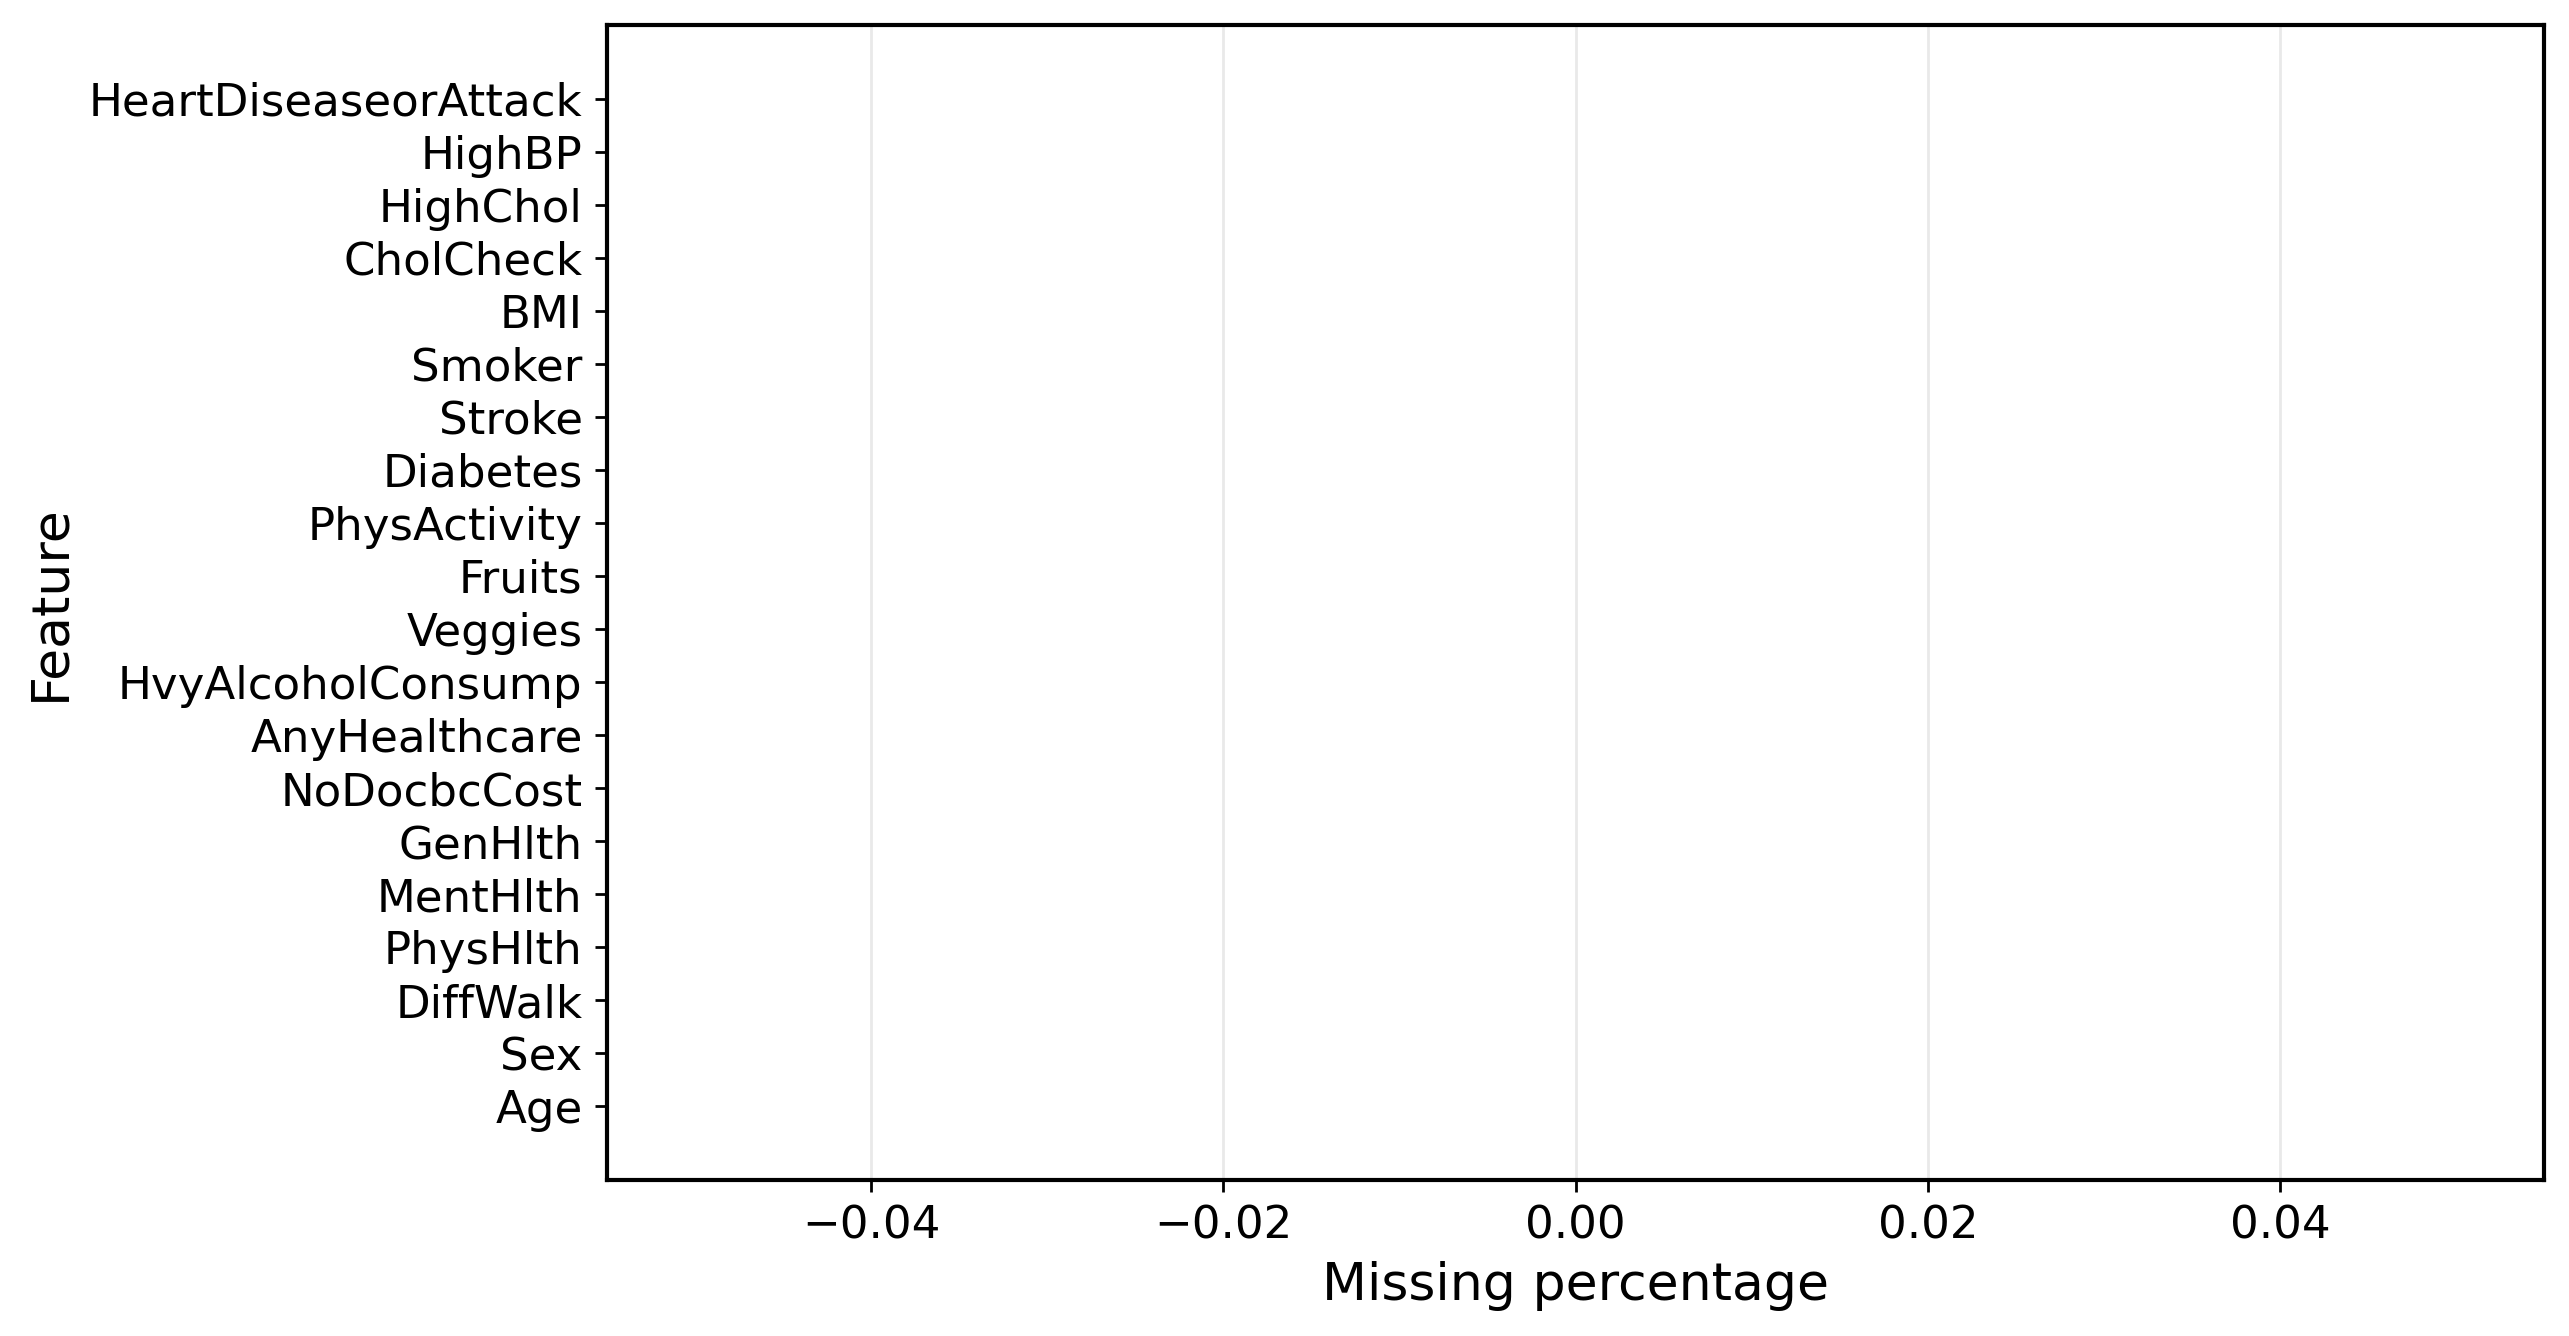


Module 1 complete.
Saved dataset audit tables, split summaries, and paper-ready figures.


In [1]:
# ============================================================
# TA-MoE for Cardiovascular Risk Prediction
# Rebuilt Research Pipeline — Modules 0–1
#
# Module 0 — Setup, configuration, reproducibility, paths
# Module 1 — Data loading, audit, feature typing, dev/test split
#
# Design goals:
# - Paper-oriented
# - Leakage-safe
# - Reproducible
# - Kaggle-friendly
# - Ready for later TA-MoE modules
# ============================================================

# ============================================================
# Module 0 — Setup and Configuration
# ============================================================

import os
import gc
import json
import time
import math
import random
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedStratifiedKFold

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Global configuration
# ------------------------------------------------------------
SEED = 42
PROJECT_NAME = "TA-MoE Cardiovascular Risk Prediction"
TARGET = "HeartDiseaseorAttack"

# final data split
TEST_SIZE = 0.20   # hold-out test set
DEV_SIZE = 1.0 - TEST_SIZE

# repeated stratified CV on dev set (for later modules)
N_SPLITS = 5
N_REPEATS = 3

# primary paper metric
PRIMARY_METRIC = "PR_AUC"

# plotting
PLOT_DPI = 400
SAVE_FIG_FORMATS = ["png", "pdf"]

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass

seed_everything(SEED)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs"

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
PRED_DIR = OUT_DIR / "preds"
MOD_DIR = OUT_DIR / "models"
LOG_DIR = OUT_DIR / "logs"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, PRED_DIR, MOD_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Matplotlib style
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 250,
    "savefig.dpi": PLOT_DPI,
    "figure.figsize": (8, 6),
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 10,
    "font.size": 12,
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.2,
    "grid.alpha": 0.28,
})

def save_figure_multi(base_path: Path):
    """Save the current matplotlib figure in all configured formats."""
    for ext in SAVE_FIG_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

# ------------------------------------------------------------
# Candidate data paths
# ------------------------------------------------------------
DATA_PATH_CANDIDATES = [
    "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/Heart_Disease_Health_Indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators.csv",
]

def find_data_path(candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

DATA_PATH = find_data_path(DATA_PATH_CANDIDATES)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset file not found. Please update DATA_PATH_CANDIDATES."
    )

# ------------------------------------------------------------
# Save environment metadata
# ------------------------------------------------------------
meta_info = {
    "project_name": PROJECT_NAME,
    "seed": SEED,
    "target": TARGET,
    "test_size": TEST_SIZE,
    "cv_n_splits": N_SPLITS,
    "cv_n_repeats": N_REPEATS,
    "primary_metric": PRIMARY_METRIC,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "data_path": DATA_PATH,
}

with open(LOG_DIR / "module0_environment.json", "w") as f:
    json.dump(meta_info, f, indent=2)

print("Module 0 complete.")
print(f"Project        : {PROJECT_NAME}")
print(f"Target         : {TARGET}")
print(f"Primary metric : {PRIMARY_METRIC}")
print(f"Data path      : {DATA_PATH}")
print(f"Output dir     : {OUT_DIR}")


# ============================================================
# Module 1 — Data Loading, Audit, and Dev/Test Split
# ============================================================

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
df = df.copy()
df.columns = [c.strip() for c in df.columns]

print("\nLoaded dataset.")
print("Raw shape:", df.shape)

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}"
    )

# ------------------------------------------------------------
# Target cleanup
# ------------------------------------------------------------
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)

FEATURES = [c for c in df.columns if c != TARGET]

# ------------------------------------------------------------
# Feature typing based on BRFSS schema
# ------------------------------------------------------------
CONT_COLS = [c for c in ["BMI", "MentHlth", "PhysHlth"] if c in FEATURES]
ORDINAL_COLS = [c for c in ["GenHlth", "Age", "Education", "Income"] if c in FEATURES]
BINARY_COLS = [c for c in FEATURES if c not in CONT_COLS + ORDINAL_COLS]
OTHER_COLS = [c for c in FEATURES if c not in BINARY_COLS + ORDINAL_COLS + CONT_COLS]

X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values

# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------
N = len(df)
pos_n = int((y_all == 1).sum())
neg_n = int((y_all == 0).sum())
pos_rate = float(np.mean(y_all))
neg_rate = 1.0 - pos_rate

print("\n===== Dataset Summary =====")
print(f"N samples       : {N:,}")
print(f"N features      : {len(FEATURES)}")
print(f"Positive count  : {pos_n:,}")
print(f"Negative count  : {neg_n:,}")
print(f"Positive rate   : {pos_rate:.6f}")
print(f"Negative rate   : {neg_rate:.6f}")

print("\n===== Feature Groups =====")
print(f"Binary features   : {len(BINARY_COLS)}")
print(f"Ordinal features  : {len(ORDINAL_COLS)}")
print(f"Continuous feats  : {len(CONT_COLS)}")
if OTHER_COLS:
    print(f"Other/Unexpected  : {OTHER_COLS}")

# ------------------------------------------------------------
# Feature audit
# ------------------------------------------------------------
audit_rows = []
for c in [TARGET] + FEATURES:
    s = df[c]
    s_num = pd.to_numeric(s, errors="coerce")
    audit_rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100.0),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(s_num.min()) if s_num.notna().any() else np.nan,
        "max": float(s_num.max()) if s_num.notna().any() else np.nan,
    })

audit_df = pd.DataFrame(audit_rows)

feature_group_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [
        "continuous" if c in CONT_COLS else
        "ordinal" if c in ORDINAL_COLS else
        "binary" if c in BINARY_COLS else
        "other"
        for c in FEATURES
    ]
})

dataset_summary_df = pd.DataFrame([{
    "project_name": PROJECT_NAME,
    "dataset_path": DATA_PATH,
    "target": TARGET,
    "n_samples": N,
    "n_features": len(FEATURES),
    "positive_n": pos_n,
    "negative_n": neg_n,
    "positive_rate": pos_rate,
    "negative_rate": neg_rate,
}])

audit_df.to_csv(TAB_DIR / "module1_feature_audit.csv", index=False)
feature_group_df.to_csv(TAB_DIR / "module1_feature_groups.csv", index=False)
dataset_summary_df.to_csv(TAB_DIR / "module1_dataset_summary.csv", index=False)

# ------------------------------------------------------------
# Development / hold-out test split
# ------------------------------------------------------------
X_dev, X_test, y_dev, y_test = train_test_split(
    X_all,
    y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=SEED,
)

split_summary_df = pd.DataFrame([
    {
        "split": "development",
        "n": int(len(y_dev)),
        "positive_n": int((y_dev == 1).sum()),
        "negative_n": int((y_dev == 0).sum()),
        "positive_rate": float(np.mean(y_dev)),
        "negative_rate": float(1.0 - np.mean(y_dev)),
    },
    {
        "split": "holdout_test",
        "n": int(len(y_test)),
        "positive_n": int((y_test == 1).sum()),
        "negative_n": int((y_test == 0).sum()),
        "positive_rate": float(np.mean(y_test)),
        "negative_rate": float(1.0 - np.mean(y_test)),
    },
])

split_summary_df.to_csv(TAB_DIR / "module1_dev_test_split_summary.csv", index=False)

print("\n===== Development / Hold-out Test Split =====")
print(split_summary_df)

# save split indices for reproducibility
dev_index = X_dev.index.to_numpy()
test_index = X_test.index.to_numpy()

np.savez_compressed(
    PRED_DIR / "module1_dev_test_indices.npz",
    dev_index=dev_index.astype(np.int32),
    test_index=test_index.astype(np.int32),
)

# ------------------------------------------------------------
# Repeated stratified CV object for later modules
# ------------------------------------------------------------
rskf_dev = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEED,
)

cv_rows = []
for fold_id, (tr_idx, va_idx) in enumerate(rskf_dev.split(X_dev, y_dev), 1):
    cv_rows.append({
        "repeat_fold_id": fold_id,
        "train_size": int(len(tr_idx)),
        "valid_size": int(len(va_idx)),
        "train_pos_rate": float(np.mean(y_dev[tr_idx])),
        "valid_pos_rate": float(np.mean(y_dev[va_idx])),
    })

cv_summary_df = pd.DataFrame(cv_rows)
cv_summary_df.to_csv(TAB_DIR / "module1_repeated_cv_summary.csv", index=False)

print("\n===== Repeated Stratified CV on Development Set =====")
print(cv_summary_df.head())

# ------------------------------------------------------------
# Paper-ready figures
# ------------------------------------------------------------
# full dataset class distribution
plt.figure(figsize=(7.6, 5.6))
plt.bar(["Negative", "Positive"], [neg_n, pos_n])
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_full_class_distribution")
plt.show()

# dev vs test positive rate
plt.figure(figsize=(7.4, 5.6))
plt.bar(split_summary_df["split"], split_summary_df["positive_rate"])
plt.xlabel("Split")
plt.ylabel("Positive rate")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_dev_test_positive_rate")
plt.show()

# top missingness
missing_plot_df = audit_df.sort_values("missing_pct", ascending=False).head(20)
plt.figure(figsize=(10, 6))
plt.barh(missing_plot_df["column"], missing_plot_df["missing_pct"])
plt.xlabel("Missing percentage")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module1_top_missingness")
plt.show()

print("\nModule 1 complete.")
print("Saved dataset audit tables, split summaries, and paper-ready figures.")

Loaded dataset.
Raw shape: (253680, 23)

===== Feature Schema =====
Binary        : 13
Ordinal       : 4
Count         : 2
Continuous    : 1
Multiclass    : 1
Other         : 0

===== Dataset Summary =====
N samples            : 253,680
N features           : 21
Dropped target-miss  : 0
Positive count       : 23,893
Negative count       : 229,787
Positive rate        : 0.094186
Negative rate        : 0.905814

===== Development / Hold-out Test Split =====
          split       n  positive_n  negative_n  positive_rate  negative_rate
0   development  202944       19114      183830       0.094184       0.905816
1  holdout_test   50736        4779       45957       0.094193       0.905807

===== Repeated Stratified CV on Development Set =====
   repeat_fold_id  train_size  valid_size  train_positive_rate  \
0               1      162355       40589             0.094183   
1               2      162355       40589             0.094183   
2               3      162355       40589            

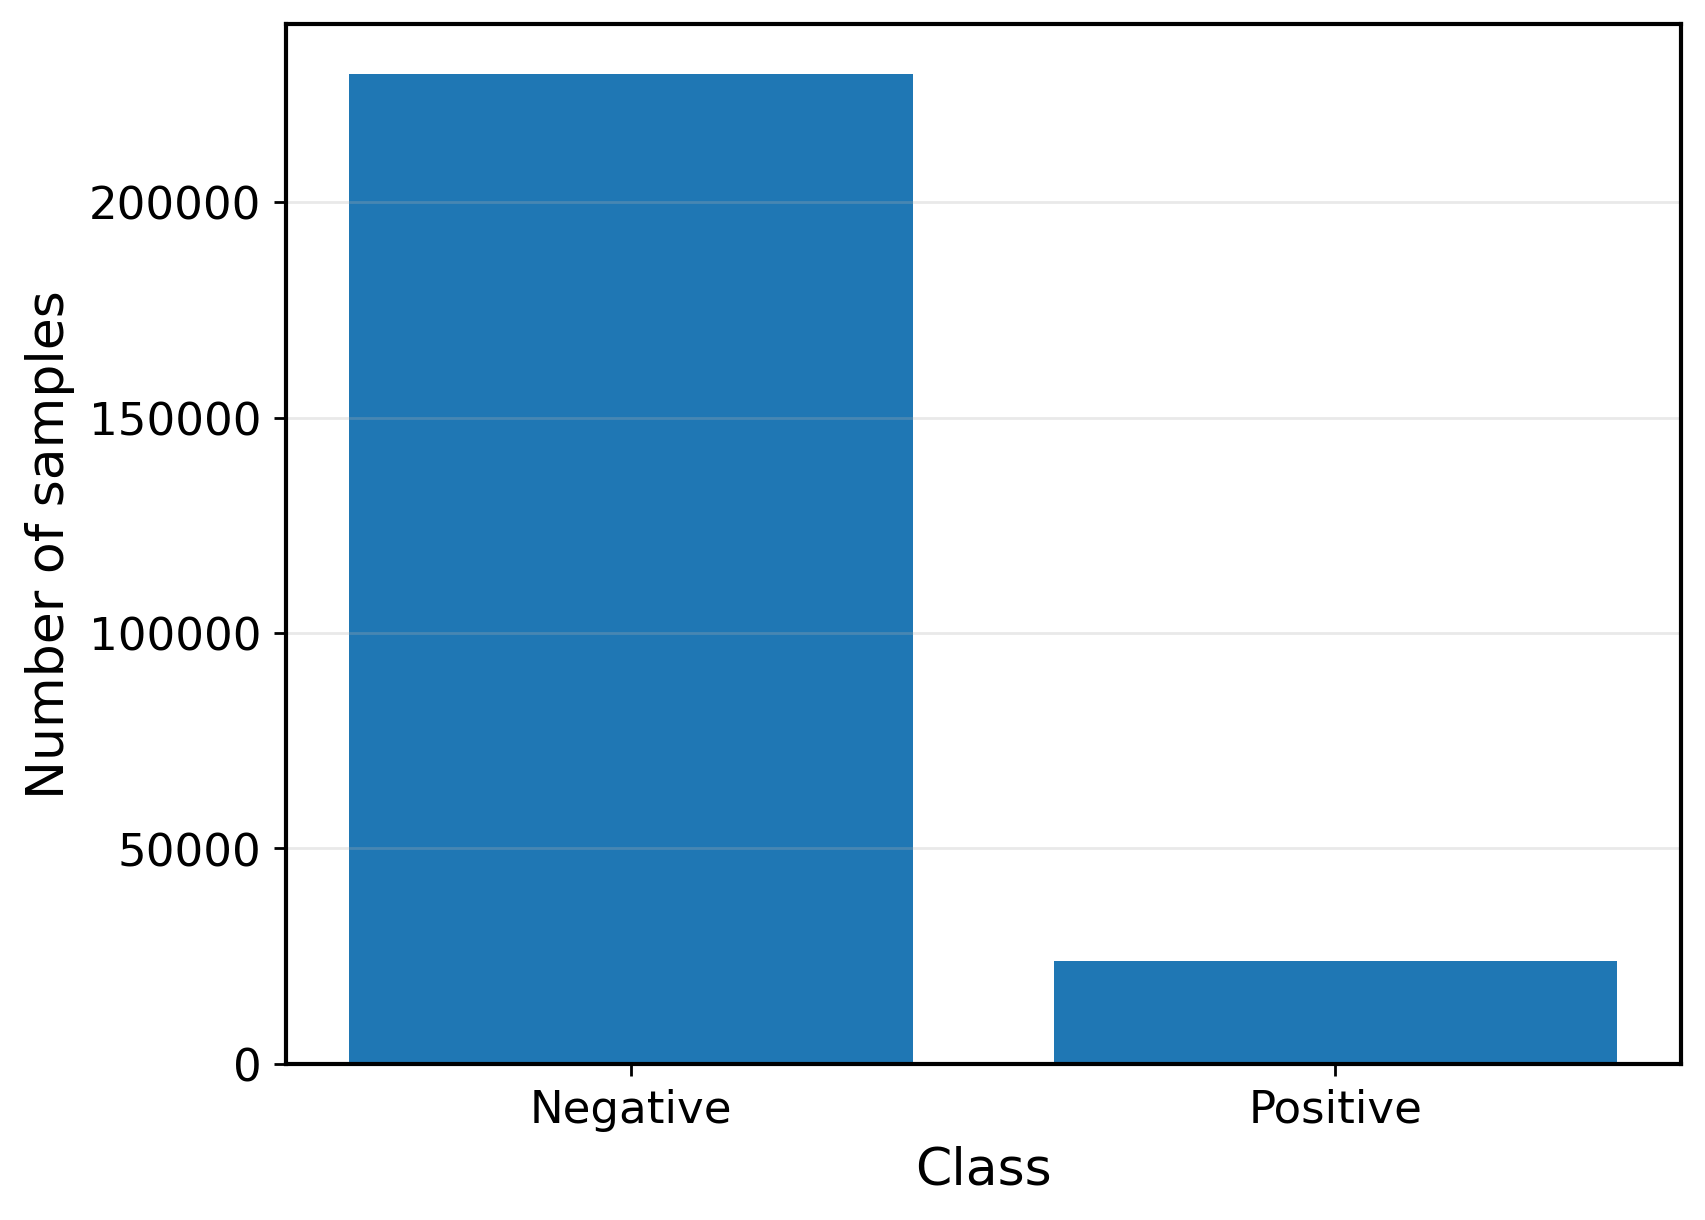

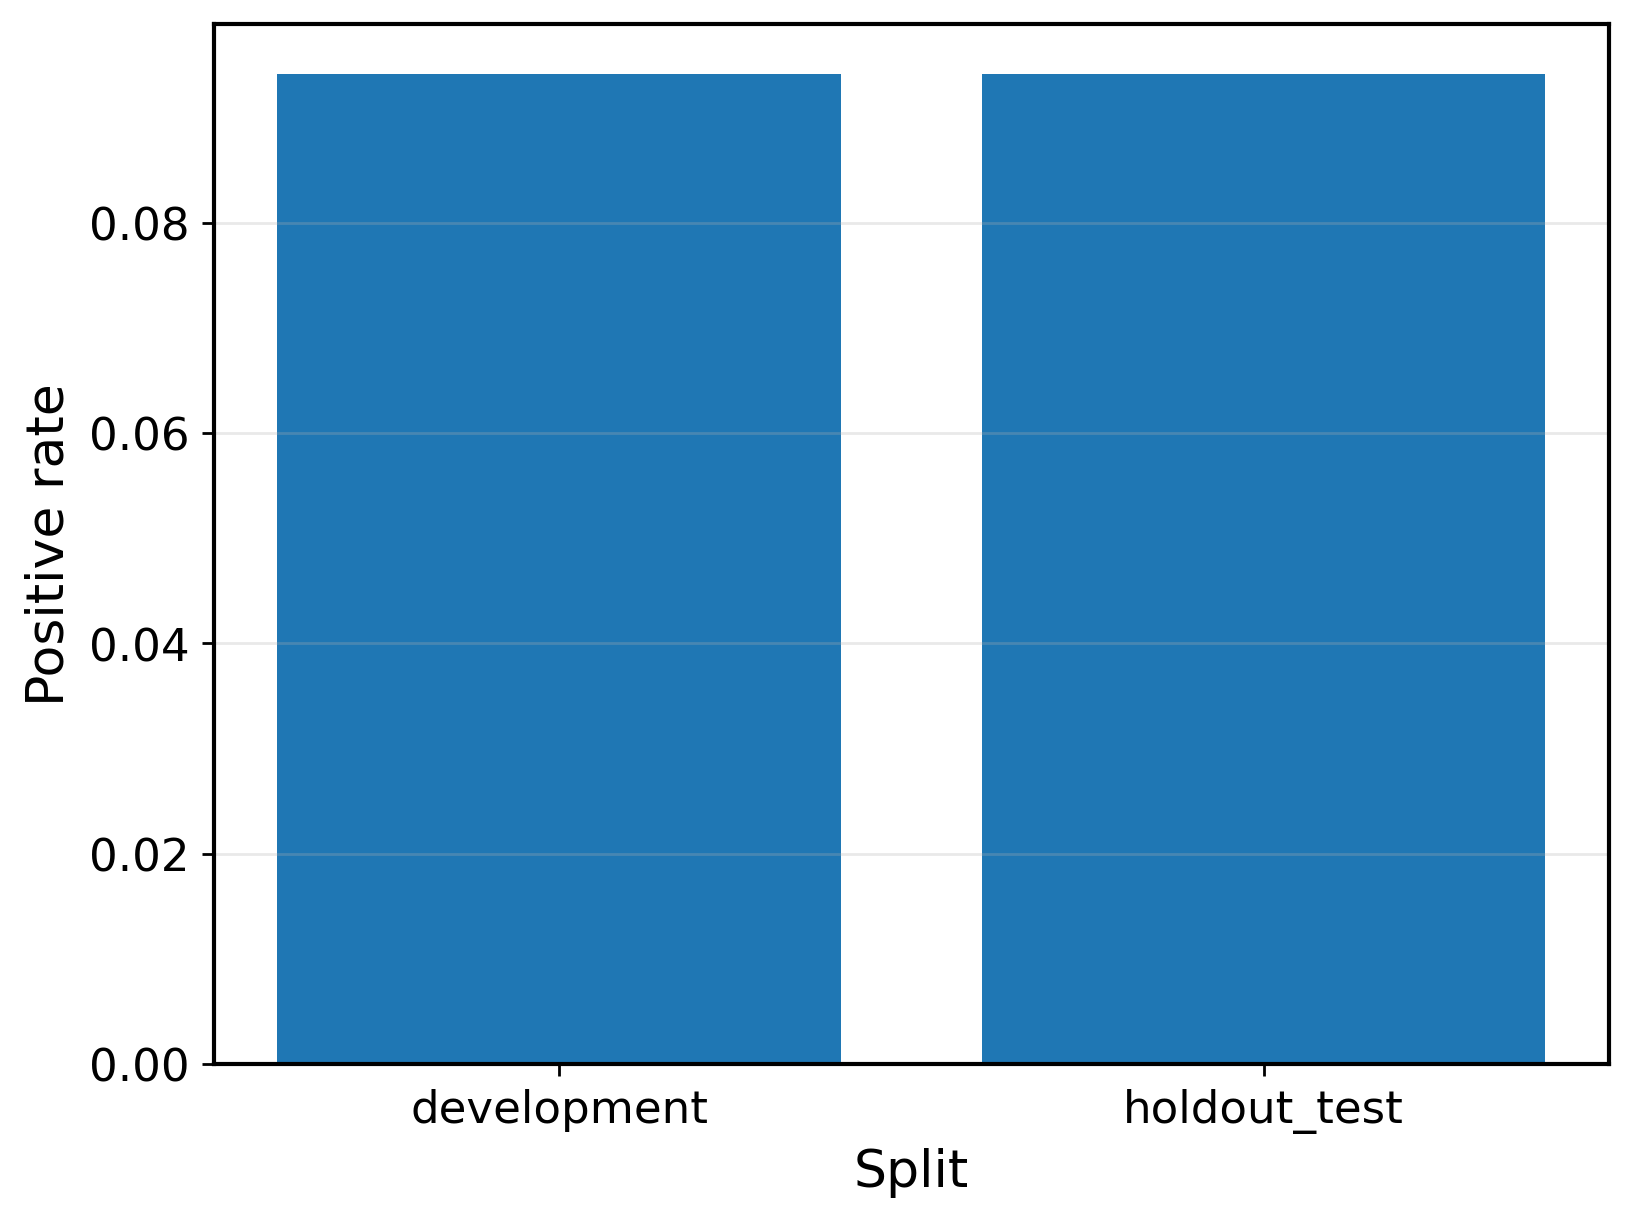

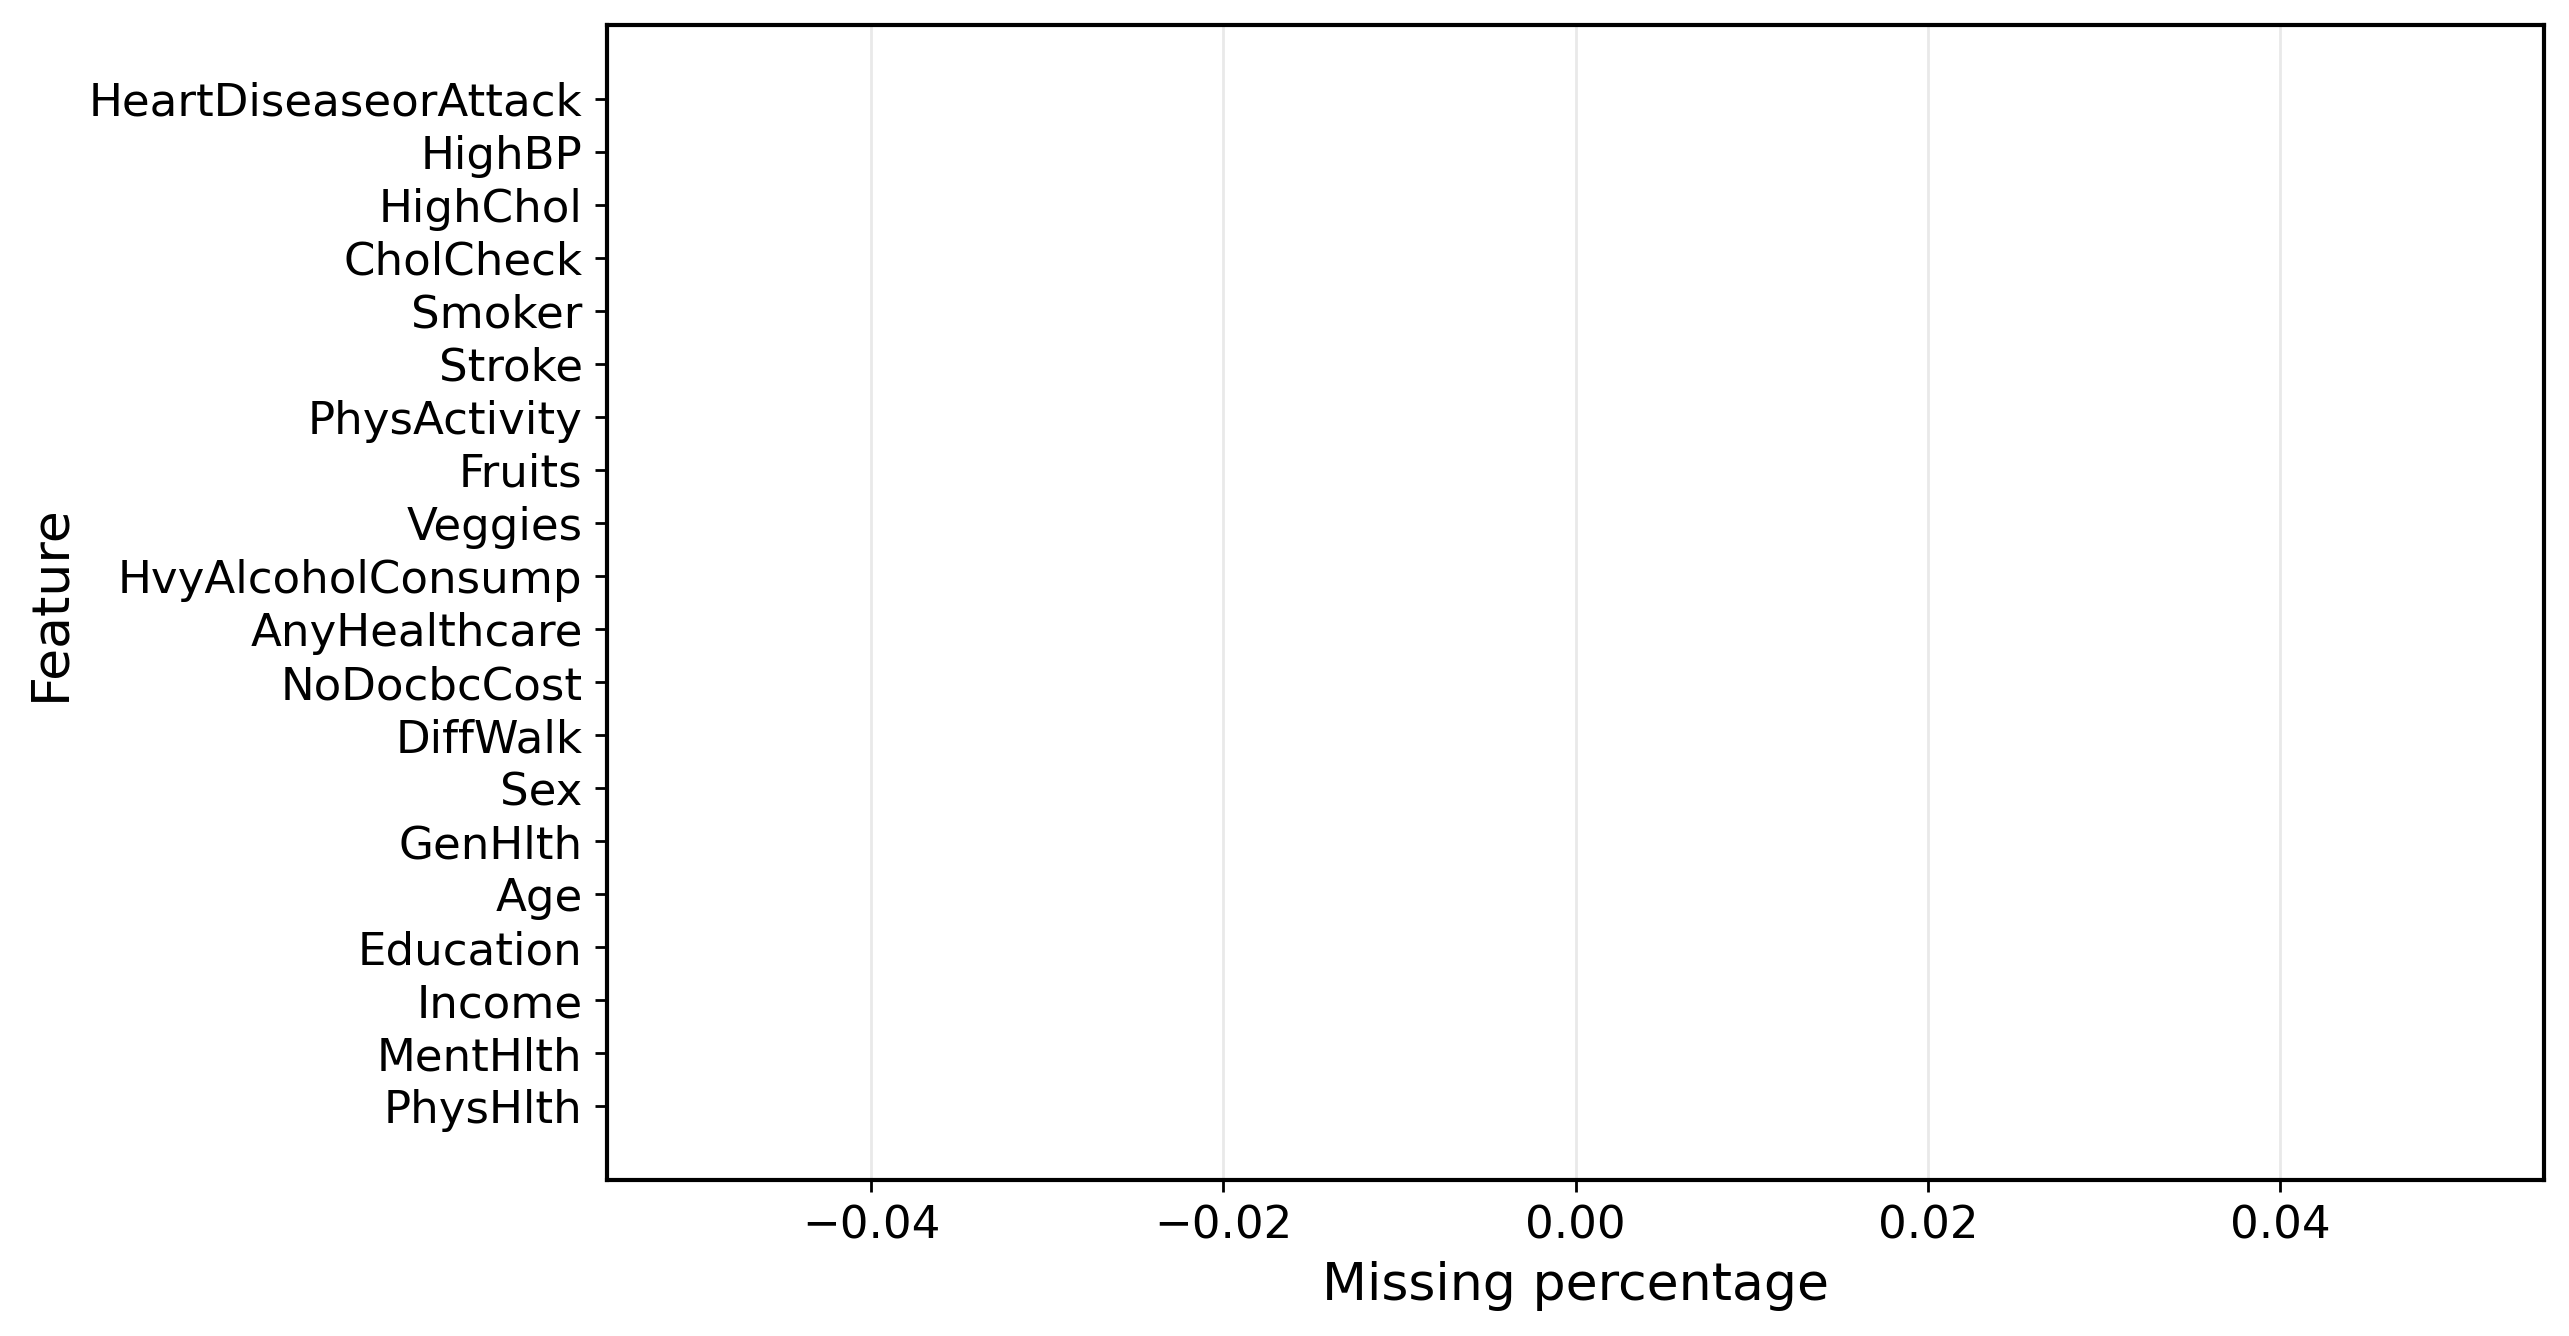


Module 1 complete.
Saved dataset audit, feature schema, split summaries, and exact repeated-CV indices.


In [2]:
# ============================================================
# Module 1 — Data Loading, Audit, Schema, and Dev/Test Split
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
N_REPEATS = 2
# ------------------------------------------------------------
# Safety checks from Module 0
# ------------------------------------------------------------
required_vars = [
    "SEED", "PROJECT_NAME", "TARGET",
    "TEST_SIZE", "N_SPLITS", "N_REPEATS",
    "FIG_DIR", "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "SAVE_FIG_FORMATS", "DATA_PATH"
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables from Module 0: {missing_vars}")

# ------------------------------------------------------------
# Figure saving helper
# ------------------------------------------------------------
def save_figure_multi(base_path: Path):
    for ext in SAVE_FIG_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH).copy()
df.columns = [c.strip() for c in df.columns]
df["orig_row_id"] = np.arange(len(df), dtype=np.int64)

print("Loaded dataset.")
print("Raw shape:", df.shape)

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}")

# ------------------------------------------------------------
# Target cleanup
# ------------------------------------------------------------
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
before_drop = len(df)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
after_drop = len(df)

df[TARGET] = df[TARGET].astype(int)

target_unique = sorted(df[TARGET].unique().tolist())
if not set(target_unique).issubset({0, 1}):
    raise ValueError(f"Target '{TARGET}' must be binary {{0,1}}, found values: {target_unique}")

# ------------------------------------------------------------
# Explicit BRFSS schema
# ------------------------------------------------------------
ALL_FEATURES = [c for c in df.columns if c not in [TARGET, "orig_row_id"]]

BINARY_COLS = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

ORDINAL_COLS = ["GenHlth", "Age", "Education", "Income"]

COUNT_COLS = ["MentHlth", "PhysHlth"]

CONT_COLS = ["BMI"]

MULTICLASS_COLS = ["Diabetes"]

# retain only those actually present
BINARY_COLS = [c for c in BINARY_COLS if c in ALL_FEATURES]
ORDINAL_COLS = [c for c in ORDINAL_COLS if c in ALL_FEATURES]
COUNT_COLS = [c for c in COUNT_COLS if c in ALL_FEATURES]
CONT_COLS = [c for c in CONT_COLS if c in ALL_FEATURES]
MULTICLASS_COLS = [c for c in MULTICLASS_COLS if c in ALL_FEATURES]

known_cols = set(BINARY_COLS + ORDINAL_COLS + COUNT_COLS + CONT_COLS + MULTICLASS_COLS)
OTHER_COLS = [c for c in ALL_FEATURES if c not in known_cols]

FEATURES = BINARY_COLS + ORDINAL_COLS + COUNT_COLS + CONT_COLS + MULTICLASS_COLS + OTHER_COLS

print("\n===== Feature Schema =====")
print(f"Binary        : {len(BINARY_COLS)}")
print(f"Ordinal       : {len(ORDINAL_COLS)}")
print(f"Count         : {len(COUNT_COLS)}")
print(f"Continuous    : {len(CONT_COLS)}")
print(f"Multiclass    : {len(MULTICLASS_COLS)}")
print(f"Other         : {len(OTHER_COLS)}")
if OTHER_COLS:
    print("Other columns detected:", OTHER_COLS)

# ------------------------------------------------------------
# Bounds / schema metadata
# ------------------------------------------------------------
ORDINAL_BOUNDS = {
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
}

COUNT_BOUNDS = {
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
}

MULTICLASS_BOUNDS = {
    "Diabetes": (0, 2),
}

# keep only available
ORDINAL_BOUNDS = {k: v for k, v in ORDINAL_BOUNDS.items() if k in ORDINAL_COLS}
COUNT_BOUNDS = {k: v for k, v in COUNT_BOUNDS.items() if k in COUNT_COLS}
MULTICLASS_BOUNDS = {k: v for k, v in MULTICLASS_BOUNDS.items() if k in MULTICLASS_COLS}

# ------------------------------------------------------------
# Working matrices
# ------------------------------------------------------------
X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values
row_id_all = df["orig_row_id"].values

# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------
N = len(df)
pos_n = int((y_all == 1).sum())
neg_n = int((y_all == 0).sum())
pos_rate = float(np.mean(y_all))
neg_rate = 1.0 - pos_rate

print("\n===== Dataset Summary =====")
print(f"N samples            : {N:,}")
print(f"N features           : {len(FEATURES)}")
print(f"Dropped target-miss  : {before_drop - after_drop:,}")
print(f"Positive count       : {pos_n:,}")
print(f"Negative count       : {neg_n:,}")
print(f"Positive rate        : {pos_rate:.6f}")
print(f"Negative rate        : {neg_rate:.6f}")

# ------------------------------------------------------------
# Audit table
# ------------------------------------------------------------
audit_rows = []
for c in [TARGET] + FEATURES:
    s = df[c]
    s_num = pd.to_numeric(s, errors="coerce")
    audit_rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100.0),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(s_num.min()) if s_num.notna().any() else np.nan,
        "max": float(s_num.max()) if s_num.notna().any() else np.nan,
    })

audit_df = pd.DataFrame(audit_rows)

feature_group_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [
        "binary" if c in BINARY_COLS else
        "ordinal" if c in ORDINAL_COLS else
        "count" if c in COUNT_COLS else
        "continuous" if c in CONT_COLS else
        "multiclass" if c in MULTICLASS_COLS else
        "other"
        for c in FEATURES
    ]
})

dataset_summary_df = pd.DataFrame([{
    "project_name": PROJECT_NAME,
    "dataset_path": DATA_PATH,
    "target": TARGET,
    "n_samples": N,
    "n_features": len(FEATURES),
    "positive_n": pos_n,
    "negative_n": neg_n,
    "positive_rate": pos_rate,
    "negative_rate": neg_rate,
}])

audit_df.to_csv(TAB_DIR / "module1_feature_audit.csv", index=False)
feature_group_df.to_csv(TAB_DIR / "module1_feature_groups.csv", index=False)
dataset_summary_df.to_csv(TAB_DIR / "module1_dataset_summary.csv", index=False)

# ------------------------------------------------------------
# Stratified development / hold-out test split
# ------------------------------------------------------------
X_dev, X_test, y_dev, y_test, rowid_dev, rowid_test = train_test_split(
    X_all,
    y_all,
    row_id_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=SEED,
)

X_dev = X_dev.copy()
X_test = X_test.copy()

split_summary_df = pd.DataFrame([
    {
        "split": "development",
        "n": int(len(y_dev)),
        "positive_n": int((y_dev == 1).sum()),
        "negative_n": int((y_dev == 0).sum()),
        "positive_rate": float(np.mean(y_dev)),
        "negative_rate": float(1.0 - np.mean(y_dev)),
    },
    {
        "split": "holdout_test",
        "n": int(len(y_test)),
        "positive_n": int((y_test == 1).sum()),
        "negative_n": int((y_test == 0).sum()),
        "positive_rate": float(np.mean(y_test)),
        "negative_rate": float(1.0 - np.mean(y_test)),
    },
])

split_summary_df.to_csv(TAB_DIR / "module1_dev_test_split_summary.csv", index=False)

print("\n===== Development / Hold-out Test Split =====")
print(split_summary_df)

# ------------------------------------------------------------
# Save exact dev/test row IDs
# ------------------------------------------------------------
np.savez_compressed(
    PRED_DIR / "module1_dev_test_row_ids.npz",
    dev_row_ids=rowid_dev.astype(np.int64),
    test_row_ids=rowid_test.astype(np.int64),
)

# ------------------------------------------------------------
# Repeated stratified CV object on development set
# ------------------------------------------------------------
rskf_dev = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEED
)

cv_rows = []
cv_index_dict = {}

for fold_id, (tr_idx, va_idx) in enumerate(rskf_dev.split(X_dev, y_dev), start=1):
    cv_rows.append({
        "repeat_fold_id": fold_id,
        "train_size": int(len(tr_idx)),
        "valid_size": int(len(va_idx)),
        "train_positive_rate": float(np.mean(y_dev[tr_idx])),
        "valid_positive_rate": float(np.mean(y_dev[va_idx])),
    })
    cv_index_dict[f"fold_{fold_id}_train_idx"] = tr_idx.astype(np.int32)
    cv_index_dict[f"fold_{fold_id}_valid_idx"] = va_idx.astype(np.int32)

cv_summary_df = pd.DataFrame(cv_rows)
cv_summary_df.to_csv(TAB_DIR / "module1_repeated_cv_summary.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module1_repeated_cv_indices.npz",
    **cv_index_dict
)

print("\n===== Repeated Stratified CV on Development Set =====")
print(cv_summary_df.head())

# ------------------------------------------------------------
# Save module-1 metadata
# ------------------------------------------------------------
module1_meta = {
    "target": TARGET,
    "n_samples": int(N),
    "n_features": int(len(FEATURES)),
    "feature_schema_counts": {
        "binary": len(BINARY_COLS),
        "ordinal": len(ORDINAL_COLS),
        "count": len(COUNT_COLS),
        "continuous": len(CONT_COLS),
        "multiclass": len(MULTICLASS_COLS),
        "other": len(OTHER_COLS),
    },
    "ordinal_bounds": ORDINAL_BOUNDS,
    "count_bounds": COUNT_BOUNDS,
    "multiclass_bounds": MULTICLASS_BOUNDS,
    "test_size": TEST_SIZE,
    "cv_n_splits": N_SPLITS,
    "cv_n_repeats": N_REPEATS,
}

with open(LOG_DIR / "module1_metadata.json", "w") as f:
    json.dump(module1_meta, f, indent=2)

# ------------------------------------------------------------
# Paper-ready figures
# ------------------------------------------------------------
plt.figure(figsize=(7.2, 5.4))
plt.bar(["Negative", "Positive"], [neg_n, pos_n])
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_full_class_distribution")
plt.show()

plt.figure(figsize=(7.2, 5.4))
plt.bar(split_summary_df["split"], split_summary_df["positive_rate"])
plt.xlabel("Split")
plt.ylabel("Positive rate")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_dev_test_positive_rate")
plt.show()

missing_plot_df = audit_df.sort_values("missing_pct", ascending=False).head(20)
plt.figure(figsize=(10, 6))
plt.barh(missing_plot_df["column"], missing_plot_df["missing_pct"])
plt.xlabel("Missing percentage")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module1_top_missingness")
plt.show()

print("\nModule 1 complete.")
print("Saved dataset audit, feature schema, split summaries, and exact repeated-CV indices.")

In [3]:
# ============================================================
# Module 2 — Preprocessing Utilities
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "FEATURES", "BINARY_COLS", "ORDINAL_COLS", "COUNT_COLS",
    "CONT_COLS", "MULTICLASS_COLS",
    "ORDINAL_BOUNDS", "COUNT_BOUNDS", "MULTICLASS_BOUNDS",
    "X_dev", "X_test", "y_dev", "y_test",
    "TAB_DIR", "LOG_DIR"
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 2: {missing_vars}")

# ------------------------------------------------------------
# Basic numeric helper
# ------------------------------------------------------------
def safe_numeric_series(s: pd.Series, fill_value: float = 0.0) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)
    return s_num.fillna(fill_value)

# ------------------------------------------------------------
# Type-aware sanitizers
# ------------------------------------------------------------
def sanitize_binary_series(s: pd.Series) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=0.0)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, 0, 1)
    return pd.Series(s_num, index=s.index)

def sanitize_ordinal_series(
    s: pd.Series,
    min_value: int,
    max_value: int,
    fill_value: int
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=fill_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_count_series(
    s: pd.Series,
    min_value: int = 0,
    max_value: int = 30
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=min_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_multiclass_series(
    s: pd.Series,
    min_value: int,
    max_value: int,
    fill_value: int
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=fill_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_continuous_series(
    s: pd.Series,
    fill_strategy: str = "median",
    fill_value_override: float | None = None
) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)

    if fill_value_override is not None:
        fill_value = float(fill_value_override)
    else:
        if fill_strategy == "median":
            fill_value = float(s_num.median()) if s_num.notna().any() else 0.0
        elif fill_strategy == "mean":
            fill_value = float(s_num.mean()) if s_num.notna().any() else 0.0
        else:
            fill_value = 0.0

    s_num = s_num.fillna(fill_value).astype(np.float32)
    return pd.Series(s_num, index=s.index)

# ------------------------------------------------------------
# Dataframe sanitation
# ------------------------------------------------------------
def sanitize_dataframe(
    X_df: pd.DataFrame,
    continuous_fill_map: dict | None = None
) -> pd.DataFrame:
    X_df = X_df.copy()

    for c in BINARY_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_binary_series(X_df[c])

    for c in ORDINAL_COLS:
        if c in X_df.columns:
            lo, hi = ORDINAL_BOUNDS[c]
            X_df[c] = sanitize_ordinal_series(
                X_df[c],
                min_value=lo,
                max_value=hi,
                fill_value=lo
            )

    for c in COUNT_COLS:
        if c in X_df.columns:
            lo, hi = COUNT_BOUNDS[c]
            X_df[c] = sanitize_count_series(
                X_df[c],
                min_value=lo,
                max_value=hi
            )

    for c in MULTICLASS_COLS:
        if c in X_df.columns:
            lo, hi = MULTICLASS_BOUNDS[c]
            X_df[c] = sanitize_multiclass_series(
                X_df[c],
                min_value=lo,
                max_value=hi,
                fill_value=lo
            )

    for c in CONT_COLS:
        if c in X_df.columns:
            fill_override = None
            if continuous_fill_map is not None and c in continuous_fill_map:
                fill_override = continuous_fill_map[c]

            X_df[c] = sanitize_continuous_series(
                X_df[c],
                fill_strategy="median",
                fill_value_override=fill_override
            )

    # fallback for any unexpected features
    handled = set(BINARY_COLS + ORDINAL_COLS + COUNT_COLS + MULTICLASS_COLS + CONT_COLS)
    other_cols = [c for c in X_df.columns if c not in handled]
    for c in other_cols:
        X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    return X_df[FEATURES].copy()

# ------------------------------------------------------------
# Train-fitted preprocessing object
# ------------------------------------------------------------
def fit_preprocessor_on_train(X_train_df: pd.DataFrame) -> dict:
    X_train_df = X_train_df.copy()

    # first sanitize using within-train fallback
    X_train_sanitized = sanitize_dataframe(X_train_df, continuous_fill_map=None)

    continuous_fill_map = {}
    continuous_mean_map = {}
    continuous_std_map = {}

    for c in CONT_COLS:
        if c in X_train_sanitized.columns:
            s = pd.to_numeric(X_train_sanitized[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
            fill_val = float(s.median()) if s.notna().any() else 0.0
            s_filled = s.fillna(fill_val).astype(np.float32)

            mean_val = float(s_filled.mean())
            std_val = float(s_filled.std())
            if std_val < 1e-8:
                std_val = 1.0

            continuous_fill_map[c] = fill_val
            continuous_mean_map[c] = mean_val
            continuous_std_map[c] = std_val

    preproc = {
        "features": FEATURES.copy(),
        "binary_cols": BINARY_COLS.copy(),
        "ordinal_cols": ORDINAL_COLS.copy(),
        "count_cols": COUNT_COLS.copy(),
        "continuous_cols": CONT_COLS.copy(),
        "multiclass_cols": MULTICLASS_COLS.copy(),
        "ordinal_bounds": ORDINAL_BOUNDS.copy(),
        "count_bounds": COUNT_BOUNDS.copy(),
        "multiclass_bounds": MULTICLASS_BOUNDS.copy(),
        "continuous_fill_map": continuous_fill_map,
        "continuous_mean_map": continuous_mean_map,
        "continuous_std_map": continuous_std_map,
    }
    return preproc

# ------------------------------------------------------------
# Transformers
# ------------------------------------------------------------
def transform_ml_matrix(X_df: pd.DataFrame, preproc: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(
        X_df,
        continuous_fill_map=preproc["continuous_fill_map"]
    )
    return X_df[preproc["features"]].copy()

def transform_dl_matrix(X_df: pd.DataFrame, preproc: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(
        X_df,
        continuous_fill_map=preproc["continuous_fill_map"]
    )

    for c in preproc["continuous_cols"]:
        if c in X_df.columns:
            mu = preproc["continuous_mean_map"][c]
            sd = preproc["continuous_std_map"][c]
            X_df[c] = (X_df[c].astype(np.float32) - mu) / sd

    return X_df[preproc["features"]].copy()

# ------------------------------------------------------------
# Dense / categorical split helper for future deep models
# ------------------------------------------------------------
def build_deep_feature_views(X_df: pd.DataFrame, preproc: dict):
    X_dl = transform_dl_matrix(X_df, preproc)

    dense_cols = preproc["continuous_cols"] + preproc["count_cols"]
    sparse_cols = preproc["binary_cols"] + preproc["ordinal_cols"] + preproc["multiclass_cols"]

    dense_cols = [c for c in dense_cols if c in X_dl.columns]
    sparse_cols = [c for c in sparse_cols if c in X_dl.columns]

    X_dense = X_dl[dense_cols].copy() if dense_cols else pd.DataFrame(index=X_dl.index)
    X_sparse = X_dl[sparse_cols].copy() if sparse_cols else pd.DataFrame(index=X_dl.index)

    return {
        "X_dl": X_dl,
        "X_dense": X_dense,
        "X_sparse": X_sparse,
        "dense_cols": dense_cols,
        "sparse_cols": sparse_cols,
    }

# ------------------------------------------------------------
# Convenience wrappers
# ------------------------------------------------------------
def fit_and_transform_train_ml(X_train_df: pd.DataFrame):
    preproc = fit_preprocessor_on_train(X_train_df)
    X_train_ml = transform_ml_matrix(X_train_df, preproc)
    return X_train_ml, preproc

def fit_and_transform_train_dl(X_train_df: pd.DataFrame):
    preproc = fit_preprocessor_on_train(X_train_df)
    X_train_dl = transform_dl_matrix(X_train_df, preproc)
    return X_train_dl, preproc

# ------------------------------------------------------------
# Optional engineered feature hook
# ------------------------------------------------------------
def add_engineered_features(X_df: pd.DataFrame) -> pd.DataFrame:
    # locked as identity for the current core pipeline
    return X_df.copy()

# ------------------------------------------------------------
# Preview on development data
# ------------------------------------------------------------
preproc_dev = fit_preprocessor_on_train(X_dev)

X_dev_preview = X_dev.head(10).copy()
X_dev_ml_preview = transform_ml_matrix(X_dev_preview, preproc_dev)
X_dev_dl_preview = transform_dl_matrix(X_dev_preview, preproc_dev)
deep_views_preview = build_deep_feature_views(X_dev_preview, preproc_dev)

X_dev_ml_preview.to_csv(TAB_DIR / "module2_ml_preview.csv", index=False)
X_dev_dl_preview.to_csv(TAB_DIR / "module2_dl_preview.csv", index=False)

if not deep_views_preview["X_dense"].empty:
    deep_views_preview["X_dense"].to_csv(TAB_DIR / "module2_dense_preview.csv", index=False)

if not deep_views_preview["X_sparse"].empty:
    deep_views_preview["X_sparse"].to_csv(TAB_DIR / "module2_sparse_preview.csv", index=False)

# ------------------------------------------------------------
# Save preprocessing metadata
# ------------------------------------------------------------
preproc_log = {
    "n_features": len(FEATURES),
    "n_binary": len(BINARY_COLS),
    "n_ordinal": len(ORDINAL_COLS),
    "n_count": len(COUNT_COLS),
    "n_continuous": len(CONT_COLS),
    "n_multiclass": len(MULTICLASS_COLS),
    "ordinal_bounds": ORDINAL_BOUNDS,
    "count_bounds": COUNT_BOUNDS,
    "multiclass_bounds": MULTICLASS_BOUNDS,
    "continuous_fill_map": preproc_dev["continuous_fill_map"],
    "continuous_mean_map": preproc_dev["continuous_mean_map"],
    "continuous_std_map": preproc_dev["continuous_std_map"],
    "dense_cols_for_deep": deep_views_preview["dense_cols"],
    "sparse_cols_for_deep": deep_views_preview["sparse_cols"],
}

with open(LOG_DIR / "module2_preprocessing_metadata.json", "w") as f:
    json.dump(preproc_log, f, indent=2)

# ------------------------------------------------------------
# Quick sanity prints
# ------------------------------------------------------------
print("Module 2 complete.")
print(f"Features         : {len(FEATURES)}")
print(f"Binary           : {len(BINARY_COLS)}")
print(f"Ordinal          : {len(ORDINAL_COLS)}")
print(f"Count            : {len(COUNT_COLS)}")
print(f"Continuous       : {len(CONT_COLS)}")
print(f"Multiclass       : {len(MULTICLASS_COLS)}")
print("Saved ML/DL preprocessing previews and metadata.")

Module 2 complete.
Features         : 21
Binary           : 13
Ordinal          : 4
Count            : 2
Continuous       : 1
Multiclass       : 1
Saved ML/DL preprocessing previews and metadata.


In [4]:
# ============================================================
# Module 3 — Repeated CV Engine
#
# Provides:
# - repeated stratified CV on development set
# - fold-wise leakage-safe preprocessing
# - inner split for early stopping / calibration
# - OOF prediction storage
# - fold-level metrics
# - reusable model runners
# ============================================================

import os
import gc
import json
import time
import copy
import numpy as np
import pandas as pd

from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Callable, Dict, Any, Optional, List, Tuple

from sklearn.base import clone
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "PRIMARY_METRIC", "TARGET",
    "X_dev", "y_dev",
    "PRED_DIR", "TAB_DIR", "LOG_DIR", "MOD_DIR",
    "N_SPLITS", "N_REPEATS",
    "fit_preprocessor_on_train",
    "transform_ml_matrix",
    "transform_dl_matrix",
    "build_deep_feature_views",
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 3: {missing_vars}")

# ------------------------------------------------------------
# Module 3 config
# ------------------------------------------------------------
INNER_VALID_SIZE = 0.15
STORE_FOLD_MODELS = False
DEFAULT_THRESHOLD_MODE = "f1"   # choices: "f1", "fixed_0.5"
EPS = 1e-12

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def ensure_numpy_1d(y):
    y = np.asarray(y)
    if y.ndim != 1:
        y = y.reshape(-1)
    return y

def clip_probs(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def sigmoid(x):
    x = np.asarray(x, dtype=float)
    return 1.0 / (1.0 + np.exp(-x))

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def expected_calibration_error(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    n_bins: int = 15
) -> float:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(y_prob, bins[1:-1], right=True)

    ece = 0.0
    n = len(y_true)

    for b in range(n_bins):
        mask = (bin_ids == b)
        if mask.sum() == 0:
            continue
        bin_acc = y_true[mask].mean()
        bin_conf = y_prob[mask].mean()
        ece += (mask.sum() / n) * abs(bin_acc - bin_conf)

    return float(ece)

def find_best_f1_threshold(y_true: np.ndarray, y_prob: np.ndarray) -> Tuple[float, float]:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

    # precision_recall_curve returns len(thresholds)=len(precisions)-1
    best_thr = 0.5
    best_f1 = -1.0

    for i, thr in enumerate(thresholds):
        p = precisions[i]
        r = recalls[i]
        f1 = 0.0 if (p + r) == 0 else 2.0 * p * r / (p + r)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)

    return float(best_thr), float(best_f1)

def compute_classification_metrics(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold_mode: str = "f1",
    fixed_threshold: float = 0.5
) -> Dict[str, float]:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    metrics = {}

    # probability metrics
    try:
        metrics["PR_AUC"] = float(average_precision_score(y_true, y_prob))
    except Exception:
        metrics["PR_AUC"] = np.nan

    try:
        metrics["ROC_AUC"] = float(roc_auc_score(y_true, y_prob))
    except Exception:
        metrics["ROC_AUC"] = np.nan

    try:
        metrics["Brier"] = float(brier_score_loss(y_true, y_prob))
    except Exception:
        metrics["Brier"] = np.nan

    try:
        metrics["NLL"] = float(log_loss(y_true, y_prob, labels=[0, 1]))
    except Exception:
        metrics["NLL"] = np.nan

    try:
        metrics["ECE"] = float(expected_calibration_error(y_true, y_prob, n_bins=15))
    except Exception:
        metrics["ECE"] = np.nan

    # threshold selection
    if threshold_mode == "f1":
        thr, best_fold_f1 = find_best_f1_threshold(y_true, y_prob)
        metrics["threshold"] = float(thr)
        metrics["best_curve_f1"] = float(best_fold_f1)
    elif threshold_mode == "fixed_0.5":
        thr = float(fixed_threshold)
        metrics["threshold"] = thr
        metrics["best_curve_f1"] = np.nan
    else:
        raise ValueError(f"Unsupported threshold_mode: {threshold_mode}")

    y_pred = (y_prob >= thr).astype(int)

    metrics["Precision"] = float(precision_score(y_true, y_pred, zero_division=0))
    metrics["Recall"] = float(recall_score(y_true, y_pred, zero_division=0))
    metrics["F1"] = float(f1_score(y_true, y_pred, zero_division=0))
    metrics["MCC"] = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_pred)) > 1 else 0.0
    metrics["Accuracy"] = float(accuracy_score(y_true, y_pred))
    metrics["Mean_p"] = float(np.mean(y_prob))
    metrics["Pos_rate"] = float(np.mean(y_true))
    metrics["Pred_pos_rate"] = float(np.mean(y_pred))
    metrics["N"] = int(len(y_true))

    return metrics

# ------------------------------------------------------------
# Inner split for early stopping / calibration
# ------------------------------------------------------------
def make_inner_train_es_split(
    X_train_df: pd.DataFrame,
    y_train: np.ndarray,
    valid_size: float = INNER_VALID_SIZE,
    random_state: int = SEED
):
    y_train = ensure_numpy_1d(y_train)

    splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=valid_size,
        random_state=random_state
    )
    tr_sub_idx, es_idx = next(splitter.split(X_train_df, y_train))

    X_tr_sub = X_train_df.iloc[tr_sub_idx].copy()
    y_tr_sub = y_train[tr_sub_idx].copy()

    X_es = X_train_df.iloc[es_idx].copy()
    y_es = y_train[es_idx].copy()

    return X_tr_sub, y_tr_sub, X_es, y_es, tr_sub_idx, es_idx

# ------------------------------------------------------------
# Model interface runners
# ------------------------------------------------------------
def runner_sklearn_proba(
    model,
    X_train,
    y_train,
    X_valid,
    X_es=None,
    y_es=None,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = fit_kwargs or {}
    model.fit(X_train, y_train, **fit_kwargs)
    p_valid = model.predict_proba(X_valid)[:, 1]
    return model, clip_probs(p_valid)

def runner_sklearn_decision_to_proba(
    model,
    X_train,
    y_train,
    X_valid,
    X_es=None,
    y_es=None,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = fit_kwargs or {}
    model.fit(X_train, y_train, **fit_kwargs)

    if hasattr(model, "predict_proba"):
        p_valid = model.predict_proba(X_valid)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_valid)
        p_valid = sigmoid(scores)
    else:
        raise ValueError("Model has neither predict_proba nor decision_function.")

    return model, clip_probs(p_valid)

def runner_with_early_stopping_eval_set(
    model,
    X_train,
    y_train,
    X_valid,
    X_es,
    y_es,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = copy.deepcopy(fit_kwargs or {})

    # Common pattern for xgboost / lightgbm sklearn APIs
    if X_es is None or y_es is None:
        raise ValueError("Early-stopping runner requires X_es and y_es.")

    try:
        model.fit(
            X_train,
            y_train,
            eval_set=[(X_es, y_es)],
            **fit_kwargs
        )
    except TypeError:
        # fallback when eval_set unsupported
        model.fit(X_train, y_train, **fit_kwargs)

    if hasattr(model, "predict_proba"):
        p_valid = model.predict_proba(X_valid)[:, 1]
    elif hasattr(model, "decision_function"):
        p_valid = sigmoid(model.decision_function(X_valid))
    else:
        raise ValueError("Model has neither predict_proba nor decision_function.")

    return model, clip_probs(p_valid)

# ------------------------------------------------------------
# Preprocessing mode helpers
# ------------------------------------------------------------
def prepare_fold_matrices(
    X_train_df: pd.DataFrame,
    X_valid_df: pd.DataFrame,
    mode: str = "ml"
):
    """
    mode:
      - 'ml' : sanitized ML matrix, no scaling of continuous features
      - 'dl' : sanitized + scaled continuous features
      - 'deep_views' : dict with X_dl/X_dense/X_sparse
    """
    preproc = fit_preprocessor_on_train(X_train_df)

    if mode == "ml":
        X_train_out = transform_ml_matrix(X_train_df, preproc)
        X_valid_out = transform_ml_matrix(X_valid_df, preproc)
    elif mode == "dl":
        X_train_out = transform_dl_matrix(X_train_df, preproc)
        X_valid_out = transform_dl_matrix(X_valid_df, preproc)
    elif mode == "deep_views":
        X_train_out = build_deep_feature_views(X_train_df, preproc)
        X_valid_out = build_deep_feature_views(X_valid_df, preproc)
    else:
        raise ValueError(f"Unknown preprocessing mode: {mode}")

    return X_train_out, X_valid_out, preproc

# ------------------------------------------------------------
# Fold result containers
# ------------------------------------------------------------
@dataclass
class FoldArtifact:
    model_name: str
    fold_id: int
    repeat_id: int
    inner_fold_id: int
    n_train: int
    n_valid: int
    n_train_pos: int
    n_valid_pos: int
    train_pos_rate: float
    valid_pos_rate: float
    elapsed_sec: float
    threshold_mode: str
    preprocess_mode: str

@dataclass
class CVRunConfig:
    model_name: str
    preprocess_mode: str = "ml"     # ml / dl / deep_views
    runner_name: str = "runner_sklearn_proba"
    threshold_mode: str = DEFAULT_THRESHOLD_MODE
    use_inner_es_split: bool = False
    inner_valid_size: float = INNER_VALID_SIZE
    fit_kwargs: Optional[dict] = None
    save_fold_models: bool = False

# ------------------------------------------------------------
# Main CV engine
# ------------------------------------------------------------
def run_repeated_cv_engine(
    model_factory: Callable[[], Any],
    cv_config: CVRunConfig,
    runner_fn: Callable,
    X_dev_df: pd.DataFrame,
    y_dev_arr: np.ndarray,
    cv_indices_path: Optional[Path] = None,
) -> Dict[str, Any]:
    """
    Generic repeated CV engine.
    - model_factory: returns a fresh model instance each fold
    - runner_fn: standard runner function
    - preprocess_mode controls fold transformations
    """
    y_dev_arr = ensure_numpy_1d(y_dev_arr).astype(int)
    n_samples = len(y_dev_arr)

    # prepare fold iterator
    if cv_indices_path is not None and os.path.exists(cv_indices_path):
        cv_npz = np.load(cv_indices_path)
        fold_keys = sorted(
            [k for k in cv_npz.files if k.endswith("_train_idx")],
            key=lambda x: int(x.split("_")[1])
        )
        fold_pairs = []
        for k in fold_keys:
            fold_num = int(k.split("_")[1])
            tr_idx = cv_npz[f"fold_{fold_num}_train_idx"]
            va_idx = cv_npz[f"fold_{fold_num}_valid_idx"]
            fold_pairs.append((fold_num, tr_idx, va_idx))
    else:
        from sklearn.model_selection import RepeatedStratifiedKFold
        rskf = RepeatedStratifiedKFold(
            n_splits=N_SPLITS,
            n_repeats=N_REPEATS,
            random_state=SEED
        )
        fold_pairs = []
        for fold_num, (tr_idx, va_idx) in enumerate(rskf.split(X_dev_df, y_dev_arr), start=1):
            fold_pairs.append((fold_num, tr_idx, va_idx))

    # containers
    oof_pred = np.full(n_samples, np.nan, dtype=float)
    oof_fold_id = np.full(n_samples, -1, dtype=int)

    fold_metric_rows = []
    fold_meta_rows = []

    fold_model_paths = []

    total_folds = len(fold_pairs)

    print(f"\n===== Running CV: {cv_config.model_name} =====")
    print(f"Total folds: {total_folds}")
    print(f"Preprocess mode: {cv_config.preprocess_mode}")
    print(f"Runner: {cv_config.runner_name}")
    print(f"Use inner ES split: {cv_config.use_inner_es_split}")

    for fold_counter, (fold_id, tr_idx, va_idx) in enumerate(fold_pairs, start=1):
        t0 = time.time()

        # repeat / inner ids
        repeat_id = ((fold_id - 1) // N_SPLITS) + 1
        inner_fold_id = ((fold_id - 1) % N_SPLITS) + 1

        # split fold
        X_train_df = X_dev_df.iloc[tr_idx].copy()
        y_train = y_dev_arr[tr_idx].copy()

        X_valid_df = X_dev_df.iloc[va_idx].copy()
        y_valid = y_dev_arr[va_idx].copy()

        # optional inner split for early stopping / calibration
        X_es = None
        y_es = None

        if cv_config.use_inner_es_split:
            X_fit_df, y_fit, X_es_df, y_es, tr_sub_idx, es_idx = make_inner_train_es_split(
                X_train_df,
                y_train,
                valid_size=cv_config.inner_valid_size,
                random_state=SEED + fold_id
            )
        else:
            X_fit_df, y_fit = X_train_df, y_train
            X_es_df = None

        # preprocessing
        if cv_config.preprocess_mode == "deep_views":
            X_fit_proc, X_valid_proc, preproc = prepare_fold_matrices(X_fit_df, X_valid_df, mode="deep_views")
            if cv_config.use_inner_es_split:
                X_es_proc, _, _dummy = prepare_fold_matrices(X_fit_df, X_es_df, mode="deep_views")
                # prepare_fold_matrices returns train/valid, so we only need valid-like output for ES
                X_es = X_es_proc
        else:
            X_fit_proc, X_valid_proc, preproc = prepare_fold_matrices(X_fit_df, X_valid_df, mode=cv_config.preprocess_mode)
            if cv_config.use_inner_es_split:
                _tmp_train, X_es_proc, _dummy = prepare_fold_matrices(X_fit_df, X_es_df, mode=cv_config.preprocess_mode)
                X_es = X_es_proc

        # instantiate fresh model
        model = model_factory()

        # fit and predict
        model, p_valid = runner_fn(
            model=model,
            X_train=X_fit_proc,
            y_train=y_fit,
            X_valid=X_valid_proc,
            X_es=X_es,
            y_es=y_es,
            fit_kwargs=cv_config.fit_kwargs,
        )

        p_valid = clip_probs(p_valid)

        # store OOF
        oof_pred[va_idx] = p_valid
        oof_fold_id[va_idx] = fold_id

        # metrics
        fold_metrics = compute_classification_metrics(
            y_true=y_valid,
            y_prob=p_valid,
            threshold_mode=cv_config.threshold_mode,
            fixed_threshold=0.5
        )

        elapsed = time.time() - t0

        fold_artifact = FoldArtifact(
            model_name=cv_config.model_name,
            fold_id=fold_id,
            repeat_id=repeat_id,
            inner_fold_id=inner_fold_id,
            n_train=len(y_fit),
            n_valid=len(y_valid),
            n_train_pos=int(y_fit.sum()),
            n_valid_pos=int(y_valid.sum()),
            train_pos_rate=float(np.mean(y_fit)),
            valid_pos_rate=float(np.mean(y_valid)),
            elapsed_sec=float(elapsed),
            threshold_mode=cv_config.threshold_mode,
            preprocess_mode=cv_config.preprocess_mode,
        )

        fold_meta = asdict(fold_artifact)
        fold_meta_rows.append(fold_meta)

        metric_row = {"model": cv_config.model_name, "fold_id": fold_id, "repeat_id": repeat_id, "inner_fold_id": inner_fold_id}
        metric_row.update(fold_metrics)
        fold_metric_rows.append(metric_row)

        # optional model save
        if cv_config.save_fold_models:
            import joblib
            fold_model_path = MOD_DIR / f"{cv_config.model_name}_fold{fold_id}.joblib"
            joblib.dump({
                "model": model,
                "preproc": preproc,
                "fold_id": fold_id,
                "config": asdict(cv_config),
            }, fold_model_path)
            fold_model_paths.append(str(fold_model_path))

        print(
            f"[{fold_counter:02d}/{total_folds}] "
            f"fold={fold_id} rep={repeat_id} inner={inner_fold_id} "
            f"PR_AUC={fold_metrics['PR_AUC']:.6f} "
            f"ROC_AUC={fold_metrics['ROC_AUC']:.6f} "
            f"F1={fold_metrics['F1']:.6f} "
            f"time={elapsed:.2f}s"
        )

        del model, X_train_df, X_valid_df, y_train, y_valid, X_fit_df
        gc.collect()

    # final integrity checks
    if np.isnan(oof_pred).any():
        missing_n = int(np.isnan(oof_pred).sum())
        raise ValueError(f"OOF predictions contain {missing_n} missing entries.")

    fold_metrics_df = pd.DataFrame(fold_metric_rows)
    fold_meta_df = pd.DataFrame(fold_meta_rows)

    overall_oof_metrics = compute_classification_metrics(
        y_true=y_dev_arr,
        y_prob=oof_pred,
        threshold_mode=cv_config.threshold_mode,
        fixed_threshold=0.5
    )

    overall_row = {"model": cv_config.model_name, "setting": "OOF"}
    overall_row.update(overall_oof_metrics)
    overall_metrics_df = pd.DataFrame([overall_row])

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(n_samples, dtype=int),
        "y_true": y_dev_arr.astype(int),
        "oof_pred": oof_pred.astype(float),
        "fold_id": oof_fold_id.astype(int),
    })

    # save artifacts
    safe_name = cv_config.model_name.replace(" ", "_").replace("/", "_")

    fold_metrics_path = TAB_DIR / f"module3_{safe_name}_fold_metrics.csv"
    fold_meta_path = TAB_DIR / f"module3_{safe_name}_fold_meta.csv"
    overall_metrics_path = TAB_DIR / f"module3_{safe_name}_overall_oof_metrics.csv"
    oof_path = PRED_DIR / f"module3_{safe_name}_oof_predictions.csv"
    config_path = LOG_DIR / f"module3_{safe_name}_cv_config.json"

    fold_metrics_df.to_csv(fold_metrics_path, index=False)
    fold_meta_df.to_csv(fold_meta_path, index=False)
    overall_metrics_df.to_csv(overall_metrics_path, index=False)
    oof_df.to_csv(oof_path, index=False)

    with open(config_path, "w") as f:
        json.dump(asdict(cv_config), f, indent=2)

    print(f"\n===== Completed CV: {cv_config.model_name} =====")
    print("OOF metrics:")
    print(overall_metrics_df.T)

    return {
        "model_name": cv_config.model_name,
        "cv_config": cv_config,
        "fold_metrics_df": fold_metrics_df,
        "fold_meta_df": fold_meta_df,
        "overall_metrics_df": overall_metrics_df,
        "oof_df": oof_df,
        "oof_pred": oof_pred,
        "oof_y_true": y_dev_arr.copy(),
        "fold_model_paths": fold_model_paths,
        "saved_paths": {
            "fold_metrics": str(fold_metrics_path),
            "fold_meta": str(fold_meta_path),
            "overall_metrics": str(overall_metrics_path),
            "oof_predictions": str(oof_path),
            "config": str(config_path),
        },
    }

# ------------------------------------------------------------
# Simple reusable wrappers for common model families
# ------------------------------------------------------------
def make_sklearn_cv_runner(
    model_name: str,
    model_factory: Callable[[], Any],
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    fit_kwargs: Optional[dict] = None,
    save_fold_models: bool = False,
):
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="runner_sklearn_decision_to_proba",
        threshold_mode=threshold_mode,
        use_inner_es_split=False,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=save_fold_models,
    )

    result = run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=runner_sklearn_decision_to_proba,
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )
    return result

def make_boosting_cv_runner(
    model_name: str,
    model_factory: Callable[[], Any],
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    fit_kwargs: Optional[dict] = None,
    save_fold_models: bool = False,
):
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="runner_with_early_stopping_eval_set",
        threshold_mode=threshold_mode,
        use_inner_es_split=True,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=save_fold_models,
    )

    result = run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=runner_with_early_stopping_eval_set,
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )
    return result

# ------------------------------------------------------------
# Custom-model runner support
# ------------------------------------------------------------
def run_custom_cv_engine(
    model_name: str,
    custom_fold_fn: Callable,
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    use_inner_es_split: bool = False,
    fit_kwargs: Optional[dict] = None,
):
    """
    custom_fold_fn signature:
      model_obj, p_valid = custom_fold_fn(
          X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None
      )

    This is useful for DeepFM / PyTorch models / custom wrappers.
    """
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="custom_fold_fn",
        threshold_mode=threshold_mode,
        use_inner_es_split=use_inner_es_split,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=False,
    )

    result = run_repeated_cv_engine(
        model_factory=lambda: None,
        cv_config=cv_config,
        runner_fn=lambda model, X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None:
            custom_fold_fn(
                X_train=X_train,
                y_train=y_train,
                X_valid=X_valid,
                X_es=X_es,
                y_es=y_es,
                fit_kwargs=fit_kwargs,
            ),
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )
    return result

# ------------------------------------------------------------
# Example smoke test with Logistic Regression
# Uncomment to test the engine immediately
# ------------------------------------------------------------
"""
from sklearn.linear_model import LogisticRegression

def lr_factory():
    return LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
        solver="liblinear"
    )

lr_cv_result = make_sklearn_cv_runner(
    model_name="LogisticRegression_balanced",
    model_factory=lr_factory,
    preprocess_mode="ml",
    threshold_mode="f1",
    fit_kwargs=None,
    save_fold_models=False,
)

print(lr_cv_result["overall_metrics_df"])
"""

print("Module 3 complete.")
print("Repeated CV engine, OOF storage, and reusable model runners are ready.")

Module 3 complete.
Repeated CV engine, OOF storage, and reusable model runners are ready.


In [9]:
# ============================================================
# Module 4 — Candidate Model Screening (Updated)
#
# Includes:
# - Classical ML baselines
# - Boosting baselines
# - Modern tabular DL baselines:
#     * DeepFM
#     * AutoInt
#     * TabNet
#
# Outputs:
# - baseline comparison table
# - OOF prediction matrix
# - fold-wise metrics bank
# - model correlation heatmap
# - run summary including skipped optional models
# ============================================================

import gc
import os
import json
import time
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "y_dev",
    "make_sklearn_cv_runner",
    "make_boosting_cv_runner",
    "run_custom_cv_engine",
    "TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 4: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
SCREENING_TOP_K_PRINT = 10
SAVE_CORR_FORMATS = ["png", "pdf"]

NEG_POS_RATIO = float((len(y_dev) - int(np.sum(y_dev))) / max(int(np.sum(y_dev)), 1))

# ------------------------------------------------------------
# Optional dependency detection
# ------------------------------------------------------------
def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")

optional_dependency_status = {
    "deepctr_torch": HAS_DEEPCTR,
    "pytorch_tabnet": HAS_TABNET,
}

print("Optional dependency status:")
for k, v in optional_dependency_status.items():
    print(f"  {k}: {'available' if v else 'missing'}")

# ------------------------------------------------------------
# General helpers
# ------------------------------------------------------------
def save_fig_multi(base_path: Path):
    for ext in SAVE_CORR_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

def safe_rank_table(df: pd.DataFrame) -> pd.DataFrame:
    metric_priority = ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "F1", "MCC", "Accuracy"]
    cols = [c for c in metric_priority if c in df.columns]
    other_cols = [c for c in df.columns if c not in cols]
    return df[other_cols + cols]

def get_family_from_name(name: str) -> str:
    if name in ["LogReg_L2", "LogReg_ElasticNet"]:
        return "linear"
    if name in ["DecisionTree", "RandomForest", "ExtraTrees", "AdaBoost"]:
        return "tree_bagging_boosting"
    if name in ["XGBoost", "LightGBM", "CatBoost"]:
        return "gradient_boosting"
    if name in ["LinearSVM", "RBFSVM"]:
        return "svm"
    if name in ["GaussianNB", "KNN"]:
        return "probabilistic_distance"
    if name in ["MLP", "DeepFM", "AutoInt", "TabNet"]:
        return "deep_tabular"
    return "other"

# ------------------------------------------------------------
# Classical / boosting model factories
# ------------------------------------------------------------
def get_standard_model_factories():
    models = {}

    # -------- Basic neural baseline --------
    models["MLP"] = lambda: MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=1,
        random_state=SEED
    )

    return models

# ------------------------------------------------------------
# DeepCTR helpers for DeepFM / AutoInt
# ------------------------------------------------------------
def infer_deepctr_vocab_sizes(X_train_view, X_valid_view, X_es_view=None):
    sparse_cols = X_train_view["sparse_cols"]
    vocab_sizes = {}

    for c in sparse_cols:
        vals = [X_train_view["X_sparse"][c].values, X_valid_view["X_sparse"][c].values]
        if X_es_view is not None:
            vals.append(X_es_view["X_sparse"][c].values)

        mx = int(np.max(np.concatenate(vals))) if len(vals) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)

    return vocab_sizes

def build_deepctr_input_dict(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}

    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values

    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values

    return model_input

def build_class_weight_dict(y):
    y = np.asarray(y).astype(int)
    pos = int(np.sum(y))
    neg = int(len(y) - pos)
    if pos == 0 or neg == 0:
        return {0: 1.0, 1: 1.0}
    total = pos + neg
    return {
        0: total / (2.0 * neg),
        1: total / (2.0 * pos),
    }

def make_deepctr_fold_fn(model_type: str = "DeepFM"):
    """
    model_type: 'DeepFM' or 'AutoInt'
    preprocess_mode expected: deep_views
    """
    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 12))
        batch_size = int(fit_kwargs.get("batch_size", 1024))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))
        use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        X_train_input = build_deepctr_input_dict(X_train)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        class_weight = build_class_weight_dict(y_train)

        fit_params = {
            "x": X_train_input,
            "y": y_train.astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
            "class_weight": class_weight,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (X_es_input, y_es.astype("float32"))

        model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

        return model, p_valid

    return deepctr_fold_fn

# ------------------------------------------------------------
# TabNet custom fold function
# ------------------------------------------------------------
def tabnet_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_TABNET:
        raise ImportError("pytorch_tabnet is not installed.")

    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    fit_kwargs = fit_kwargs or {}

    max_epochs = int(fit_kwargs.get("max_epochs", 120))
    patience = int(fit_kwargs.get("patience", 20))
    batch_size = int(fit_kwargs.get("batch_size", 1024))
    virtual_batch_size = int(fit_kwargs.get("virtual_batch_size", 128))
    verbose = int(fit_kwargs.get("verbose", 0))
    use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

    device_name = "cuda" if use_gpu and torch.cuda.is_available() else "cpu"

    X_train_np = X_train.values.astype(np.float32)
    X_valid_np = X_valid.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(int)
    y_valid_np = np.asarray(y_valid if "y_valid" in locals() else np.zeros(len(X_valid_np))).astype(int)

    clf = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type="entmax",
        scheduler_params={"step_size": 20, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        seed=SEED,
        verbose=verbose,
        device_name=device_name,
    )

    fit_params = {
        "X_train": X_train_np,
        "y_train": y_train_np,
        "max_epochs": max_epochs,
        "patience": patience,
        "batch_size": batch_size,
        "virtual_batch_size": virtual_batch_size,
        "num_workers": 0,
        "drop_last": False,
    }

    if X_es is not None and y_es is not None:
        fit_params["eval_set"] = [(X_es.values.astype(np.float32), np.asarray(y_es).astype(int))]
        fit_params["eval_name"] = ["early_stop"]
    else:
        fit_params["eval_set"] = [(X_train_np, y_train_np)]
        fit_params["eval_name"] = ["train"]

    clf.fit(**fit_params)

    p_valid = clf.predict_proba(X_valid_np)[:, 1]
    p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

    return clf, p_valid

# ------------------------------------------------------------
# Run screening
# ------------------------------------------------------------
def run_model_screening_updated():
    standard_models = get_standard_model_factories()

    results = {}
    run_rows = []
    skipped_rows = []

    print("\n===== Module 4: Updated Candidate Screening =====")
    print(f"Standard models: {len(standard_models)}")

    # -------------------------
    # Standard ML / boosting
    # -------------------------
    for name, factory in standard_models.items():
        print(f"\n--- Running standard model: {name} ---")
        t0 = time.time()

        try:
            if name in ["XGBoost", "LightGBM", "CatBoost"]:
                result = make_boosting_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs={
                        "early_stopping_rounds": 50,
                        "verbose": False
                    },
                    save_fold_models=False
                )
            elif name in ["MLP"]:
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="dl",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )
            else:
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )

            elapsed = time.time() - t0
            results[name] = result

            run_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "completed",
                "elapsed_sec": elapsed,
            })

        except Exception as e:
            elapsed = time.time() - t0
            skipped_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "failed",
                "reason": str(e),
                "elapsed_sec": elapsed,
            })
            print(f"Failed: {name} -> {e}")

        gc.collect()

    # -------------------------
    # DeepFM
    # -------------------------
    name = "DeepFM"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("DeepFM"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 12,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # AutoInt
    # -------------------------
    name = "AutoInt"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("AutoInt"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 12,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "att_head_num": 2,
                "att_layer_num": 3,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # TabNet
    # -------------------------
    name = "TabNet"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_TABNET:
            raise ImportError("pytorch_tabnet not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=tabnet_fold_fn,
            preprocess_mode="dl",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "max_epochs": 120,
                "patience": 20,
                "batch_size": 1024,
                "virtual_batch_size": 128,
                "verbose": 0,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    run_df = pd.DataFrame(run_rows)
    skipped_df = pd.DataFrame(skipped_rows)

    run_df.to_csv(TAB_DIR / "module4_run_summary.csv", index=False)
    skipped_df.to_csv(TAB_DIR / "module4_skipped_models.csv", index=False)

    return results, run_df, skipped_df

# ------------------------------------------------------------
# Aggregate overall baseline table
# ------------------------------------------------------------
def build_baseline_table(results: dict):
    rows = []

    for name, res in results.items():
        row = res["overall_metrics_df"].iloc[0].to_dict()
        row["model"] = name
        row["family"] = get_family_from_name(name)
        rows.append(row)

    baseline_df = pd.DataFrame(rows)

    # reorder / sort
    preferred_cols = [
        "model", "family", "setting",
        "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
        "Precision", "Recall", "F1", "MCC", "Accuracy",
        "threshold", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
    ]
    preferred_cols = [c for c in preferred_cols if c in baseline_df.columns] + \
                     [c for c in baseline_df.columns if c not in preferred_cols]
    baseline_df = baseline_df[preferred_cols]

    baseline_df = baseline_df.sort_values(
        by=["PR_AUC", "ROC_AUC"],
        ascending=[False, False]
    ).reset_index(drop=True)

    baseline_df.to_csv(TAB_DIR / "module4_baseline_comparison.csv", index=False)
    return baseline_df

# ------------------------------------------------------------
# Aggregate fold metrics across all models
# ------------------------------------------------------------
def build_fold_metrics_bank(results: dict):
    dfs = []

    for name, res in results.items():
        df = res["fold_metrics_df"].copy()
        df["family"] = get_family_from_name(name)
        dfs.append(df)

    bank_df = pd.concat(dfs, axis=0, ignore_index=True)
    bank_df.to_csv(TAB_DIR / "module4_all_fold_metrics.csv", index=False)
    return bank_df

# ------------------------------------------------------------
# Build OOF matrix
# ------------------------------------------------------------
def build_oof_matrix(results: dict):
    model_names = list(results.keys())

    base_len = None
    for name in model_names:
        cur_len = len(results[name]["oof_pred"])
        if base_len is None:
            base_len = cur_len
        elif cur_len != base_len:
            raise ValueError("OOF lengths across models do not match.")

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(base_len, dtype=int),
        "y_true": results[model_names[0]]["oof_y_true"].astype(int),
    })

    for name in model_names:
        oof_df[name] = results[name]["oof_pred"]

    oof_df.to_csv(PRED_DIR / "module4_oof_matrix.csv", index=False)
    return oof_df

# ------------------------------------------------------------
# Correlation analysis
# ------------------------------------------------------------
def plot_model_correlation(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    plt.figure(figsize=(11, 9))
    im = plt.imshow(corr.values)
    plt.colorbar(im)

    plt.xticks(range(len(pred_cols)), pred_cols, rotation=90)
    plt.yticks(range(len(pred_cols)), pred_cols)
    plt.title("OOF Prediction Correlation Across Candidate Models")

    save_fig_multi(FIG_DIR / "module4_model_correlation")
    plt.show()

    corr.to_csv(TAB_DIR / "module4_model_correlation.csv")
    return corr

# ------------------------------------------------------------
# Disagreement analysis
# ------------------------------------------------------------
def build_disagreement_matrix(oof_df: pd.DataFrame, threshold: float = 0.5):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    bin_df = (oof_df[pred_cols] >= threshold).astype(int)

    n = len(pred_cols)
    mat = np.zeros((n, n), dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            mat[i, j] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    disagreement_df = pd.DataFrame(mat, index=pred_cols, columns=pred_cols)
    disagreement_df.to_csv(TAB_DIR / "module4_model_disagreement_matrix.csv")
    return disagreement_df

# ------------------------------------------------------------
# Short printed summary
# ------------------------------------------------------------
def summarize_screening(baseline_df: pd.DataFrame, run_df: pd.DataFrame, skipped_df: pd.DataFrame):
    print("\n===== Module 4 Summary =====")
    print(f"Completed models : {len(run_df)}")
    print(f"Skipped/failed   : {len(skipped_df)}")

    print("\nTop models by PR_AUC:")
    display_cols = [c for c in ["model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in baseline_df.columns]
    print(baseline_df.head(SCREENING_TOP_K_PRINT)[display_cols])

    if len(skipped_df) > 0:
        print("\nSkipped/failed models:")
        print(skipped_df[["model", "reason"]])

# ------------------------------------------------------------
# Main execution
# ------------------------------------------------------------
results, run_df, skipped_df = run_model_screening_updated()

baseline_df = build_baseline_table(results)
fold_bank_df = build_fold_metrics_bank(results)
oof_df = build_oof_matrix(results)
corr_df = plot_model_correlation(oof_df)
disagreement_df = build_disagreement_matrix(oof_df, threshold=0.5)

# save a compact metadata file
module4_meta = {
    "n_completed_models": int(len(run_df)),
    "n_skipped_models": int(len(skipped_df)),
    "completed_models": run_df["model"].tolist() if len(run_df) else [],
    "skipped_models": skipped_df["model"].tolist() if len(skipped_df) else [],
    "optional_dependency_status": optional_dependency_status,
}

with open(LOG_DIR / "module4_metadata.json", "w") as f:
    json.dump(module4_meta, f, indent=2)

summarize_screening(baseline_df, run_df, skipped_df)

print("\nModule 4 complete.")
print("Saved:")
print(" - module4_baseline_comparison.csv")
print(" - module4_all_fold_metrics.csv")
print(" - module4_oof_matrix.csv")
print(" - module4_model_correlation.csv")
print(" - module4_model_disagreement_matrix.csv")
print(" - module4_run_summary.csv")
print(" - module4_skipped_models.csv")

Optional dependency status:
  deepctr_torch: available
  pytorch_tabnet: available

===== Module 4: Updated Candidate Screening =====
Standard models: 1

--- Running standard model: MLP ---

===== Running CV: MLP =====
Total folds: 10
Preprocess mode: dl
Runner: runner_sklearn_decision_to_proba
Use inner ES split: False
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.342867 ROC_AUC=0.836202 F1=0.401220 time=1.84s
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.338713 ROC_AUC=0.832400 F1=0.396453 time=1.95s
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.329202 ROC_AUC=0.822624 F1=0.382217 time=1.83s
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.343564 ROC_AUC=0.837842 F1=0.400761 time=1.84s
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.330776 ROC_AUC=0.826440 F1=0.386132 time=1.82s
[06/10] fold=6 rep=2 inner=1 PR_AUC=0.340737 ROC_AUC=0.830006 F1=0.390874 time=1.85s
[07/10] fold=7 rep=2 inner=2 PR_AUC=0.325131 ROC_AUC=0.829808 F1=0.389095 time=1.94s
[08/10] fold=8 rep=2 inner=3 PR_AUC=0.342817 ROC_AUC=0.830587 F1=0.394375 time=1.82

2026-03-17 12:45:42.777754: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773751542.972059      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773751543.024429      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773751543.457206      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773751543.457233      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773751543.457235      55 computation_placer.cc:177] computation placer alr

Skipped/failed: DeepFM -> BaseModel.fit() got an unexpected keyword argument 'class_weight'

--- Running SOTA tabular model: AutoInt ---

===== Running CV: AutoInt =====
Total folds: 10
Preprocess mode: deep_views
Runner: custom_fold_fn
Use inner ES split: True
Skipped/failed: AutoInt -> BaseModel.fit() got an unexpected keyword argument 'class_weight'

--- Running SOTA tabular model: TabNet ---

===== Running CV: TabNet =====
Total folds: 10
Preprocess mode: dl
Runner: custom_fold_fn
Use inner ES split: True


KeyboardInterrupt: 

In [10]:
# ============================================================
# Separate Block — SOTA Tabular Models Only
# DeepFM, AutoInt, TabNet
#
# Fixes:
# - deepctr_torch fit() does NOT support class_weight
# - safer Kaggle behavior
# ============================================================

import gc
import time
import json
import importlib.util
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "run_custom_cv_engine",
    "TAB_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables before SOTA block: {missing}")

# ------------------------------------------------------------
# Optional dependency check
# ------------------------------------------------------------
HAS_DEEPCTR = importlib.util.find_spec("deepctr_torch") is not None
HAS_TABNET = importlib.util.find_spec("pytorch_tabnet") is not None

print("deepctr_torch available:", HAS_DEEPCTR)
print("pytorch_tabnet available:", HAS_TABNET)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def infer_deepctr_vocab_sizes(X_train_view, X_valid_view, X_es_view=None):
    sparse_cols = X_train_view["sparse_cols"]
    vocab_sizes = {}

    for c in sparse_cols:
        arrays = [
            X_train_view["X_sparse"][c].values,
            X_valid_view["X_sparse"][c].values,
        ]
        if X_es_view is not None:
            arrays.append(X_es_view["X_sparse"][c].values)

        mx = int(np.max(np.concatenate(arrays))) if len(arrays) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)

    return vocab_sizes

def build_deepctr_input_dict(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}

    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values

    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values

    return model_input

def build_sample_weight(y):
    """
    Balanced sample weights for binary classification.
    This is safer than class_weight for deepctr_torch because
    BaseModel.fit() does not accept class_weight.
    """
    y = np.asarray(y).astype(int)
    pos = int(np.sum(y))
    neg = int(len(y) - pos)

    if pos == 0 or neg == 0:
        return np.ones(len(y), dtype=np.float32)

    w0 = len(y) / (2.0 * neg)
    w1 = len(y) / (2.0 * pos)

    weights = np.where(y == 1, w1, w0).astype(np.float32)
    return weights

# ------------------------------------------------------------
# DeepFM / AutoInt fold function maker
# ------------------------------------------------------------
def make_deepctr_fold_fn(model_type="DeepFM"):
    """
    model_type: 'DeepFM' or 'AutoInt'
    preprocess_mode must be: deep_views
    """

    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 10))
        batch_size = int(fit_kwargs.get("batch_size", 1024))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))

        # Kaggle-safe default: CPU to avoid noisy CUDA registration issues
        use_gpu = bool(fit_kwargs.get("use_gpu", False))
        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        X_train_input = build_deepctr_input_dict(X_train)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        # deepctr_torch fit() does NOT support class_weight
        # use sample_weight only if supported in your install; otherwise omit
        fit_params = {
            "x": X_train_input,
            "y": y_train.astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (X_es_input, y_es.astype("float32"))

        # Try sample_weight first; fall back safely if unsupported
        sample_weight = build_sample_weight(y_train)
        try:
            fit_params["sample_weight"] = sample_weight
            model.fit(**fit_params)
        except TypeError:
            fit_params.pop("sample_weight", None)
            model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

        return model, p_valid

    return deepctr_fold_fn

# ------------------------------------------------------------
# TabNet fold function
# ------------------------------------------------------------
def tabnet_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_TABNET:
        raise ImportError("pytorch_tabnet is not installed.")

    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    fit_kwargs = fit_kwargs or {}

    max_epochs = int(fit_kwargs.get("max_epochs", 100))
    patience = int(fit_kwargs.get("patience", 20))
    batch_size = int(fit_kwargs.get("batch_size", 1024))
    virtual_batch_size = int(fit_kwargs.get("virtual_batch_size", 128))
    verbose = int(fit_kwargs.get("verbose", 0))
    use_gpu = bool(fit_kwargs.get("use_gpu", True))

    device_name = "cuda" if use_gpu and torch.cuda.is_available() else "cpu"

    X_train_np = X_train.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(int)

    X_valid_np = X_valid.values.astype(np.float32)

    clf = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type="entmax",
        scheduler_params={"step_size": 20, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        seed=SEED,
        verbose=verbose,
        device_name=device_name,
    )

    fit_params = {
        "X_train": X_train_np,
        "y_train": y_train_np,
        "max_epochs": max_epochs,
        "patience": patience,
        "batch_size": batch_size,
        "virtual_batch_size": virtual_batch_size,
        "num_workers": 0,
        "drop_last": False,
    }

    if X_es is not None and y_es is not None:
        fit_params["eval_set"] = [(X_es.values.astype(np.float32), np.asarray(y_es).astype(int))]
        fit_params["eval_name"] = ["early_stop"]
    else:
        fit_params["eval_set"] = [(X_train_np, y_train_np)]
        fit_params["eval_name"] = ["train"]

    clf.fit(**fit_params)

    p_valid = clf.predict_proba(X_valid_np)[:, 1]
    p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

    return clf, p_valid

# ------------------------------------------------------------
# Run SOTA models separately
# ------------------------------------------------------------
sota_results = {}
sota_run_rows = []
sota_fail_rows = []

# ---------------- DeepFM ----------------
print("\n--- Running SOTA tabular model: DeepFM ---")
t0 = time.time()
try:
    deepfm_result = run_custom_cv_engine(
        model_name="DeepFM",
        custom_fold_fn=make_deepctr_fold_fn("DeepFM"),
        preprocess_mode="deep_views",
        threshold_mode="f1",
        use_inner_es_split=True,
        fit_kwargs={
            "epochs": 10,
            "batch_size": 1024,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "use_gpu": False,   # safer in Kaggle for deepctr_torch
        }
    )
    sota_results["DeepFM"] = deepfm_result
    sota_run_rows.append({
        "model": "DeepFM",
        "status": "completed",
        "elapsed_sec": time.time() - t0,
    })
except Exception as e:
    sota_fail_rows.append({
        "model": "DeepFM",
        "status": "failed",
        "reason": str(e),
        "elapsed_sec": time.time() - t0,
    })
    print("DeepFM failed:", e)

gc.collect()

# ---------------- AutoInt ----------------
print("\n--- Running SOTA tabular model: AutoInt ---")
t0 = time.time()
try:
    autoint_result = run_custom_cv_engine(
        model_name="AutoInt",
        custom_fold_fn=make_deepctr_fold_fn("AutoInt"),
        preprocess_mode="deep_views",
        threshold_mode="f1",
        use_inner_es_split=True,
        fit_kwargs={
            "epochs": 10,
            "batch_size": 1024,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "att_head_num": 2,
            "att_layer_num": 3,
            "use_gpu": False,   # safer in Kaggle for deepctr_torch
        }
    )
    sota_results["AutoInt"] = autoint_result
    sota_run_rows.append({
        "model": "AutoInt",
        "status": "completed",
        "elapsed_sec": time.time() - t0,
    })
except Exception as e:
    sota_fail_rows.append({
        "model": "AutoInt",
        "status": "failed",
        "reason": str(e),
        "elapsed_sec": time.time() - t0,
    })
    print("AutoInt failed:", e)

gc.collect()

# ---------------- TabNet ----------------
print("\n--- Running SOTA tabular model: TabNet ---")
t0 = time.time()
try:
    tabnet_result = run_custom_cv_engine(
        model_name="TabNet",
        custom_fold_fn=tabnet_fold_fn,
        preprocess_mode="dl",
        threshold_mode="f1",
        use_inner_es_split=True,
        fit_kwargs={
            "max_epochs": 100,
            "patience": 20,
            "batch_size": 1024,
            "virtual_batch_size": 128,
            "verbose": 0,
            "use_gpu": True,
        }
    )
    sota_results["TabNet"] = tabnet_result
    sota_run_rows.append({
        "model": "TabNet",
        "status": "completed",
        "elapsed_sec": time.time() - t0,
    })
except Exception as e:
    sota_fail_rows.append({
        "model": "TabNet",
        "status": "failed",
        "reason": str(e),
        "elapsed_sec": time.time() - t0,
    })
    print("TabNet failed:", e)

gc.collect()

# ------------------------------------------------------------
# Save summaries
# ------------------------------------------------------------
sota_run_df = pd.DataFrame(sota_run_rows)
sota_fail_df = pd.DataFrame(sota_fail_rows)

sota_run_df.to_csv(TAB_DIR / "module4_sota_run_summary.csv", index=False)
sota_fail_df.to_csv(TAB_DIR / "module4_sota_failures.csv", index=False)

print("\nSOTA block complete.")
print("Completed:", list(sota_results.keys()))
if len(sota_fail_df):
    print("\nFailures:")
    print(sota_fail_df)

deepctr_torch available: True
pytorch_tabnet available: True

--- Running SOTA tabular model: DeepFM ---

===== Running CV: DeepFM =====
Total folds: 10
Preprocess mode: deep_views
Runner: custom_fold_fn
Use inner ES split: True
cpu
Train on 138001 samples, validate on 24354 samples, 135 steps per epoch
DeepFM failed: Found input variables with inconsistent numbers of samples: [138001, 24354]

--- Running SOTA tabular model: AutoInt ---

===== Running CV: AutoInt =====
Total folds: 10
Preprocess mode: deep_views
Runner: custom_fold_fn
Use inner ES split: True
cpu
Train on 138001 samples, validate on 24354 samples, 135 steps per epoch
AutoInt failed: Found input variables with inconsistent numbers of samples: [138001, 24354]

--- Running SOTA tabular model: TabNet ---

===== Running CV: TabNet =====
Total folds: 10
Preprocess mode: dl
Runner: custom_fold_fn
Use inner ES split: True

Early stopping occurred at epoch 41 with best_epoch = 21 and best_early_stop_auc = 0.84382
[01/10] fold=1

KeyboardInterrupt: 

In [ ]:
# ============================================================
# Module 4 — Candidate Model Screening (Updated)
#
# Includes:
# - Classical ML baselines
# - Boosting baselines
# - Modern tabular DL baselines:
#     * DeepFM
#     * AutoInt
#     * TabNet
#
# Outputs:
# - baseline comparison table
# - OOF prediction matrix
# - fold-wise metrics bank
# - model correlation heatmap
# - run summary including skipped optional models
# ============================================================

import gc
import os
import json
import time
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "y_dev",
    "make_sklearn_cv_runner",
    "make_boosting_cv_runner",
    "run_custom_cv_engine",
    "TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 4: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
SCREENING_TOP_K_PRINT = 10
SAVE_CORR_FORMATS = ["png", "pdf"]

NEG_POS_RATIO = float((len(y_dev) - int(np.sum(y_dev))) / max(int(np.sum(y_dev)), 1))

# ------------------------------------------------------------
# Optional dependency detection
# ------------------------------------------------------------
def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")

optional_dependency_status = {
    "deepctr_torch": HAS_DEEPCTR,
    "pytorch_tabnet": HAS_TABNET,
}

print("Optional dependency status:")
for k, v in optional_dependency_status.items():
    print(f"  {k}: {'available' if v else 'missing'}")

# ------------------------------------------------------------
# General helpers
# ------------------------------------------------------------
def save_fig_multi(base_path: Path):
    for ext in SAVE_CORR_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

def safe_rank_table(df: pd.DataFrame) -> pd.DataFrame:
    metric_priority = ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "F1", "MCC", "Accuracy"]
    cols = [c for c in metric_priority if c in df.columns]
    other_cols = [c for c in df.columns if c not in cols]
    return df[other_cols + cols]

def get_family_from_name(name: str) -> str:
    if name in ["LogReg_L2", "LogReg_ElasticNet"]:
        return "linear"
    if name in ["DecisionTree", "RandomForest", "ExtraTrees", "AdaBoost"]:
        return "tree_bagging_boosting"
    if name in ["XGBoost", "LightGBM", "CatBoost"]:
        return "gradient_boosting"
    if name in ["LinearSVM", "RBFSVM"]:
        return "svm"
    if name in ["GaussianNB", "KNN"]:
        return "probabilistic_distance"
    if name in ["MLP", "DeepFM", "AutoInt", "TabNet"]:
        return "deep_tabular"
    return "other"

# ------------------------------------------------------------
# Classical / boosting model factories
# ------------------------------------------------------------
def get_standard_model_factories():
    models = {}

    # -------- Linear --------
    models["LogReg_L2"] = lambda: LogisticRegression(
        C=1.0,
        max_iter=2500,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    models["LogReg_ElasticNet"] = lambda: LogisticRegression(
        penalty="elasticnet",
        l1_ratio=0.5,
        solver="saga",
        max_iter=2500,
        class_weight="balanced",
        random_state=SEED
    )

    # -------- Trees / bagging --------
    models["DecisionTree"] = lambda: DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=SEED
    )

    models["RandomForest"] = lambda: RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    )

    models["ExtraTrees"] = lambda: ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    )

    models["AdaBoost"] = lambda: AdaBoostClassifier(
        n_estimators=250,
        learning_rate=0.05,
        random_state=SEED
    )

    # -------- Boosting --------
    models["XGBoost"] = lambda: XGBClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=NEG_POS_RATIO,
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED
    )

    models["LightGBM"] = lambda: LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED
    )

    models["CatBoost"] = lambda: CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="Logloss",
        auto_class_weights="Balanced",
        verbose=0,
        random_state=SEED
    )

    # -------- SVM --------
    models["LinearSVM"] = lambda: SVC(
        kernel="linear",
        probability=True,
        class_weight="balanced",
        random_state=SEED
    )

    models["RBFSVM"] = lambda: SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        gamma="scale",
        random_state=SEED
    )

    # -------- Others --------
    models["GaussianNB"] = lambda: GaussianNB()

    models["KNN"] = lambda: KNeighborsClassifier(
        n_neighbors=50,
        weights="distance"
    )

    # -------- Basic neural baseline --------
    models["MLP"] = lambda: MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=120,
        random_state=SEED
    )

    return models

# ------------------------------------------------------------
# DeepCTR helpers for DeepFM / AutoInt
# ------------------------------------------------------------
def infer_deepctr_vocab_sizes(X_train_view, X_valid_view, X_es_view=None):
    sparse_cols = X_train_view["sparse_cols"]
    vocab_sizes = {}

    for c in sparse_cols:
        vals = [X_train_view["X_sparse"][c].values, X_valid_view["X_sparse"][c].values]
        if X_es_view is not None:
            vals.append(X_es_view["X_sparse"][c].values)

        mx = int(np.max(np.concatenate(vals))) if len(vals) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)

    return vocab_sizes

def build_deepctr_input_dict(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}

    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values

    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values

    return model_input

def build_class_weight_dict(y):
    y = np.asarray(y).astype(int)
    pos = int(np.sum(y))
    neg = int(len(y) - pos)
    if pos == 0 or neg == 0:
        return {0: 1.0, 1: 1.0}
    total = pos + neg
    return {
        0: total / (2.0 * neg),
        1: total / (2.0 * pos),
    }

def make_deepctr_fold_fn(model_type: str = "DeepFM"):
    """
    model_type: 'DeepFM' or 'AutoInt'
    preprocess_mode expected: deep_views
    """
    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 12))
        batch_size = int(fit_kwargs.get("batch_size", 1024))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))
        use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        X_train_input = build_deepctr_input_dict(X_train)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        class_weight = build_class_weight_dict(y_train)

        fit_params = {
            "x": X_train_input,
            "y": y_train.astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
            "class_weight": class_weight,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (X_es_input, y_es.astype("float32"))

        model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

        return model, p_valid

    return deepctr_fold_fn

# ------------------------------------------------------------
# TabNet custom fold function
# ------------------------------------------------------------
def tabnet_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_TABNET:
        raise ImportError("pytorch_tabnet is not installed.")

    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    fit_kwargs = fit_kwargs or {}

    max_epochs = int(fit_kwargs.get("max_epochs", 120))
    patience = int(fit_kwargs.get("patience", 20))
    batch_size = int(fit_kwargs.get("batch_size", 1024))
    virtual_batch_size = int(fit_kwargs.get("virtual_batch_size", 128))
    verbose = int(fit_kwargs.get("verbose", 0))
    use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

    device_name = "cuda" if use_gpu and torch.cuda.is_available() else "cpu"

    X_train_np = X_train.values.astype(np.float32)
    X_valid_np = X_valid.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(int)
    y_valid_np = np.asarray(y_valid if "y_valid" in locals() else np.zeros(len(X_valid_np))).astype(int)

    clf = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type="entmax",
        scheduler_params={"step_size": 20, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        seed=SEED,
        verbose=verbose,
        device_name=device_name,
    )

    fit_params = {
        "X_train": X_train_np,
        "y_train": y_train_np,
        "max_epochs": max_epochs,
        "patience": patience,
        "batch_size": batch_size,
        "virtual_batch_size": virtual_batch_size,
        "num_workers": 0,
        "drop_last": False,
    }

    if X_es is not None and y_es is not None:
        fit_params["eval_set"] = [(X_es.values.astype(np.float32), np.asarray(y_es).astype(int))]
        fit_params["eval_name"] = ["early_stop"]
    else:
        fit_params["eval_set"] = [(X_train_np, y_train_np)]
        fit_params["eval_name"] = ["train"]

    clf.fit(**fit_params)

    p_valid = clf.predict_proba(X_valid_np)[:, 1]
    p_valid = np.clip(p_valid, 1e-12, 1.0 - 1e-12)

    return clf, p_valid

# ------------------------------------------------------------
# Run screening
# ------------------------------------------------------------
def run_model_screening_updated():
    standard_models = get_standard_model_factories()

    results = {}
    run_rows = []
    skipped_rows = []

    print("\n===== Module 4: Updated Candidate Screening =====")
    print(f"Standard models: {len(standard_models)}")

    # -------------------------
    # Standard ML / boosting
    # -------------------------
    for name, factory in standard_models.items():
        print(f"\n--- Running standard model: {name} ---")
        t0 = time.time()

        try:
            if name in ["XGBoost", "LightGBM", "CatBoost"]:
                result = make_boosting_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs={
                        "early_stopping_rounds": 50,
                        "verbose": False
                    },
                    save_fold_models=False
                )
            elif name in ["MLP"]:
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="dl",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )
            else:
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )

            elapsed = time.time() - t0
            results[name] = result

            run_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "completed",
                "elapsed_sec": elapsed,
            })

        except Exception as e:
            elapsed = time.time() - t0
            skipped_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "failed",
                "reason": str(e),
                "elapsed_sec": elapsed,
            })
            print(f"Failed: {name} -> {e}")

        gc.collect()

    # -------------------------
    # DeepFM
    # -------------------------
    name = "DeepFM"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("DeepFM"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 12,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # AutoInt
    # -------------------------
    name = "AutoInt"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("AutoInt"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 12,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "att_head_num": 2,
                "att_layer_num": 3,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # TabNet
    # -------------------------
    name = "TabNet"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_TABNET:
            raise ImportError("pytorch_tabnet not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=tabnet_fold_fn,
            preprocess_mode="dl",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "max_epochs": 120,
                "patience": 20,
                "batch_size": 1024,
                "virtual_batch_size": 128,
                "verbose": 0,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    run_df = pd.DataFrame(run_rows)
    skipped_df = pd.DataFrame(skipped_rows)

    run_df.to_csv(TAB_DIR / "module4_run_summary.csv", index=False)
    skipped_df.to_csv(TAB_DIR / "module4_skipped_models.csv", index=False)

    return results, run_df, skipped_df

# ------------------------------------------------------------
# Aggregate overall baseline table
# ------------------------------------------------------------
def build_baseline_table(results: dict):
    rows = []

    for name, res in results.items():
        row = res["overall_metrics_df"].iloc[0].to_dict()
        row["model"] = name
        row["family"] = get_family_from_name(name)
        rows.append(row)

    baseline_df = pd.DataFrame(rows)

    # reorder / sort
    preferred_cols = [
        "model", "family", "setting",
        "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
        "Precision", "Recall", "F1", "MCC", "Accuracy",
        "threshold", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
    ]
    preferred_cols = [c for c in preferred_cols if c in baseline_df.columns] + \
                     [c for c in baseline_df.columns if c not in preferred_cols]
    baseline_df = baseline_df[preferred_cols]

    baseline_df = baseline_df.sort_values(
        by=["PR_AUC", "ROC_AUC"],
        ascending=[False, False]
    ).reset_index(drop=True)

    baseline_df.to_csv(TAB_DIR / "module4_baseline_comparison.csv", index=False)
    return baseline_df

# ------------------------------------------------------------
# Aggregate fold metrics across all models
# ------------------------------------------------------------
def build_fold_metrics_bank(results: dict):
    dfs = []

    for name, res in results.items():
        df = res["fold_metrics_df"].copy()
        df["family"] = get_family_from_name(name)
        dfs.append(df)

    bank_df = pd.concat(dfs, axis=0, ignore_index=True)
    bank_df.to_csv(TAB_DIR / "module4_all_fold_metrics.csv", index=False)
    return bank_df

# ------------------------------------------------------------
# Build OOF matrix
# ------------------------------------------------------------
def build_oof_matrix(results: dict):
    model_names = list(results.keys())

    base_len = None
    for name in model_names:
        cur_len = len(results[name]["oof_pred"])
        if base_len is None:
            base_len = cur_len
        elif cur_len != base_len:
            raise ValueError("OOF lengths across models do not match.")

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(base_len, dtype=int),
        "y_true": results[model_names[0]]["oof_y_true"].astype(int),
    })

    for name in model_names:
        oof_df[name] = results[name]["oof_pred"]

    oof_df.to_csv(PRED_DIR / "module4_oof_matrix.csv", index=False)
    return oof_df

# ------------------------------------------------------------
# Correlation analysis
# ------------------------------------------------------------
def plot_model_correlation(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    plt.figure(figsize=(11, 9))
    im = plt.imshow(corr.values)
    plt.colorbar(im)

    plt.xticks(range(len(pred_cols)), pred_cols, rotation=90)
    plt.yticks(range(len(pred_cols)), pred_cols)
    plt.title("OOF Prediction Correlation Across Candidate Models")

    save_fig_multi(FIG_DIR / "module4_model_correlation")
    plt.show()

    corr.to_csv(TAB_DIR / "module4_model_correlation.csv")
    return corr

# ------------------------------------------------------------
# Disagreement analysis
# ------------------------------------------------------------
def build_disagreement_matrix(oof_df: pd.DataFrame, threshold: float = 0.5):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    bin_df = (oof_df[pred_cols] >= threshold).astype(int)

    n = len(pred_cols)
    mat = np.zeros((n, n), dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            mat[i, j] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    disagreement_df = pd.DataFrame(mat, index=pred_cols, columns=pred_cols)
    disagreement_df.to_csv(TAB_DIR / "module4_model_disagreement_matrix.csv")
    return disagreement_df

# ------------------------------------------------------------
# Short printed summary
# ------------------------------------------------------------
def summarize_screening(baseline_df: pd.DataFrame, run_df: pd.DataFrame, skipped_df: pd.DataFrame):
    print("\n===== Module 4 Summary =====")
    print(f"Completed models : {len(run_df)}")
    print(f"Skipped/failed   : {len(skipped_df)}")

    print("\nTop models by PR_AUC:")
    display_cols = [c for c in ["model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in baseline_df.columns]
    print(baseline_df.head(SCREENING_TOP_K_PRINT)[display_cols])

    if len(skipped_df) > 0:
        print("\nSkipped/failed models:")
        print(skipped_df[["model", "reason"]])

# ------------------------------------------------------------
# Main execution
# ------------------------------------------------------------
results, run_df, skipped_df = run_model_screening_updated()

baseline_df = build_baseline_table(results)
fold_bank_df = build_fold_metrics_bank(results)
oof_df = build_oof_matrix(results)
corr_df = plot_model_correlation(oof_df)
disagreement_df = build_disagreement_matrix(oof_df, threshold=0.5)

# save a compact metadata file
module4_meta = {
    "n_completed_models": int(len(run_df)),
    "n_skipped_models": int(len(skipped_df)),
    "completed_models": run_df["model"].tolist() if len(run_df) else [],
    "skipped_models": skipped_df["model"].tolist() if len(skipped_df) else [],
    "optional_dependency_status": optional_dependency_status,
}

with open(LOG_DIR / "module4_metadata.json", "w") as f:
    json.dump(module4_meta, f, indent=2)

summarize_screening(baseline_df, run_df, skipped_df)

print("\nModule 4 complete.")
print("Saved:")
print(" - module4_baseline_comparison.csv")
print(" - module4_all_fold_metrics.csv")
print(" - module4_oof_matrix.csv")
print(" - module4_model_correlation.csv")
print(" - module4_model_disagreement_matrix.csv")
print(" - module4_run_summary.csv")
print(" - module4_skipped_models.csv")

Optional dependency status:
  deepctr_torch: missing
  pytorch_tabnet: missing

===== Module 4: Updated Candidate Screening =====
Standard models: 14

--- Running standard model: LogReg_L2 ---

===== Running CV: LogReg_L2 =====
Total folds: 10
Preprocess mode: ml
Runner: runner_sklearn_decision_to_proba
Use inner ES split: False
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.378961 ROC_AUC=0.850603 F1=0.425103 time=2.04s
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.383361 ROC_AUC=0.850848 F1=0.427372 time=1.87s
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.360374 ROC_AUC=0.842994 F1=0.412637 time=2.03s
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.375844 ROC_AUC=0.852417 F1=0.421343 time=1.94s
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.361367 ROC_AUC=0.840045 F1=0.407161 time=1.97s
[06/10] fold=6 rep=2 inner=1 PR_AUC=0.378760 ROC_AUC=0.846904 F1=0.420054 time=1.88s
[07/10] fold=7 rep=2 inner=2 PR_AUC=0.364291 ROC_AUC=0.846987 F1=0.419033 time=1.96s
[08/10] fold=8 rep=2 inner=3 PR_AUC=0.372887 ROC_AUC=0.848630 F1=0.420394 

## New

In [1]:
# ============================================================
# Module 0 — Setup, Configuration, Reproducibility
# TA-MoE for Cardiovascular Risk Prediction
# ============================================================

import os
import gc
import sys
import json
import time
import math
import random
import warnings
import platform
import importlib
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import List, Dict, Any, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 0.1 Reproducibility
# ------------------------------------------------------------
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        if hasattr(torch.backends, "cudnn"):
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except Exception:
        pass

# ------------------------------------------------------------
# 0.2 Central configuration
# ------------------------------------------------------------
@dataclass
class Config:
    # project
    project_name: str = "TA-MoE Cardiovascular Risk Prediction"
    experiment_name: str = "brfss2015_tamoe_v1"

    # seed
    seed: int = 42

    # data
    target_col: str = "HeartDiseaseorAttack"
    test_size: float = 0.20

    # cv
    n_splits: int = 5
    n_repeats: int = 3

    # metrics
    primary_metric: str = "PR_AUC"
    calibration_method: str = "platt"
    n_ece_bins: int = 10

    # training
    use_class_weight: bool = True
    early_stopping: bool = True
    inner_valid_size: float = 0.15

    # uncertainty / selective prediction
    selective_grid: Optional[List[float]] = None

    # figures
    plot_dpi: int = 400
    figure_size: tuple = (8, 6)
    save_fig_formats: tuple = ("png", "pdf")

    # paths
    root_dir: str = "/kaggle/working"
    data_path_candidates: Optional[List[str]] = None

    # runtime
    save_models: bool = True
    save_oof_predictions: bool = True
    verbose: int = 1

CONFIG = Config(
    selective_grid=[round(x, 2) for x in np.arange(0.00, 1.00, 0.05)],
    data_path_candidates=[
        "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
        "/kaggle/input/heart-disease-health-indicators-dataset/Heart_Disease_Health_Indicators_BRFSS2015.csv",
        "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators.csv",
    ]
)

seed_everything(CONFIG.seed)

# ------------------------------------------------------------
# 0.3 Path management
# ------------------------------------------------------------
ROOT_DIR = Path(CONFIG.root_dir)
OUT_DIR = ROOT_DIR / "outputs"

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
PRED_DIR = OUT_DIR / "preds"
MOD_DIR = OUT_DIR / "models"
LOG_DIR = OUT_DIR / "logs"
ART_DIR = OUT_DIR / "artifacts"
AUDIT_DIR = OUT_DIR / "audit"

ALL_DIRS = [OUT_DIR, FIG_DIR, TAB_DIR, PRED_DIR, MOD_DIR, LOG_DIR, ART_DIR, AUDIT_DIR]
for d in ALL_DIRS:
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 0.4 Helper utilities
# ------------------------------------------------------------
def find_first_existing_path(candidates: List[str]) -> str:
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "Dataset file not found. Please update CONFIG.data_path_candidates."
    )

def save_json(obj: Dict[str, Any], path: Path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)

def save_figure_multi(base_path: Path):
    for ext in CONFIG.save_fig_formats:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

def get_package_version(pkg_name: str) -> str:
    try:
        module = importlib.import_module(pkg_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not_installed"

# ------------------------------------------------------------
# 0.5 Resolve dataset path
# ------------------------------------------------------------
DATA_PATH = find_first_existing_path(CONFIG.data_path_candidates)

# ------------------------------------------------------------
# 0.6 Matplotlib defaults
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 250,
    "savefig.dpi": CONFIG.plot_dpi,
    "figure.figsize": CONFIG.figure_size,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "font.size": 12,
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.28,
})

# ------------------------------------------------------------
# 0.7 Environment and package metadata
# ------------------------------------------------------------
package_versions = {
    "python": platform.python_version(),
    "numpy": get_package_version("numpy"),
    "pandas": get_package_version("pandas"),
    "matplotlib": get_package_version("matplotlib"),
    "sklearn": get_package_version("sklearn"),
    "scipy": get_package_version("scipy"),
    "lightgbm": get_package_version("lightgbm"),
    "xgboost": get_package_version("xgboost"),
    "catboost": get_package_version("catboost"),
    "torch": get_package_version("torch"),
}

environment_info = {
    "project_name": CONFIG.project_name,
    "experiment_name": CONFIG.experiment_name,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "platform": platform.platform(),
    "python_executable": sys.executable,
    "data_path": DATA_PATH,
    "config": asdict(CONFIG),
    "package_versions": package_versions,
}

save_json(environment_info, LOG_DIR / "module0_environment.json")

# also save plain package versions text
with open(LOG_DIR / "package_versions.txt", "w", encoding="utf-8") as f:
    for k, v in package_versions.items():
        f.write(f"{k}: {v}\n")

# ------------------------------------------------------------
# 0.8 Standard artifact filenames for later modules
# ------------------------------------------------------------
ARTIFACT_PATHS = {
    "feature_types": ART_DIR / "feature_types.json",
    "dev_test_indices": ART_DIR / "dev_test_split_indices.npz",
    "cv_registry": ART_DIR / "cv_fold_registry.csv",
    "candidate_cv_results": TAB_DIR / "cv_candidate_results.csv",
    "candidate_cv_summary": TAB_DIR / "cv_candidate_summary.csv",
    "expert_selection": TAB_DIR / "expert_selection_table.csv",
    "oof_expert_matrix": PRED_DIR / "oof_expert_matrix.csv",
    "oof_trust_features": PRED_DIR / "oof_trust_features.csv",
    "oof_tamoe_raw": PRED_DIR / "oof_tamoe_raw.csv",
    "oof_tamoe_calibrated": PRED_DIR / "oof_tamoe_calibrated.csv",
    "test_predictions": PRED_DIR / "test_tamoe_predictions.csv",
    "test_results_main": TAB_DIR / "test_results_main.csv",
    "test_results_threshold": TAB_DIR / "test_results_threshold.csv",
    "wilcoxon_results": TAB_DIR / "wilcoxon_results.csv",
    "bootstrap_ci_results": TAB_DIR / "bootstrap_ci_results.csv",
    "ablation_results": TAB_DIR / "ablation_results.csv",
    "selective_prediction_results": TAB_DIR / "selective_prediction_results.csv",
    "final_summary": ART_DIR / "final_summary.json",
}

save_json(
    {k: str(v) for k, v in ARTIFACT_PATHS.items()},
    ART_DIR / "artifact_paths.json"
)

# ------------------------------------------------------------
# 0.9 Quick run summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 0 complete")
print("=" * 70)
print(f"Project           : {CONFIG.project_name}")
print(f"Experiment        : {CONFIG.experiment_name}")
print(f"Seed              : {CONFIG.seed}")
print(f"Target            : {CONFIG.target_col}")
print(f"Data path         : {DATA_PATH}")
print(f"Test size         : {CONFIG.test_size}")
print(f"CV                : {CONFIG.n_splits}-fold x {CONFIG.n_repeats} repeats")
print(f"Primary metric    : {CONFIG.primary_metric}")
print(f"Calibration       : {CONFIG.calibration_method}")
print(f"Output directory  : {OUT_DIR}")
print("=" * 70)

Module 0 complete
Project           : TA-MoE Cardiovascular Risk Prediction
Experiment        : brfss2015_tamoe_v1
Seed              : 42
Target            : HeartDiseaseorAttack
Data path         : /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Test size         : 0.2
CV                : 5-fold x 3 repeats
Primary metric    : PR_AUC
Calibration       : platt
Output directory  : /kaggle/working/outputs


Raw dataset loaded
Shape: (253680, 22)
Columns (22):
['HeartDiseaseorAttack', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Target distribution
   class   count       pct
0    0.0  229787  0.905814
1    1.0   23893  0.094186

Positive class rate: 0.094186
Feature typing summary
Binary      : 13
Ordinal     : 5
Continuous  : 3
Other       : 0


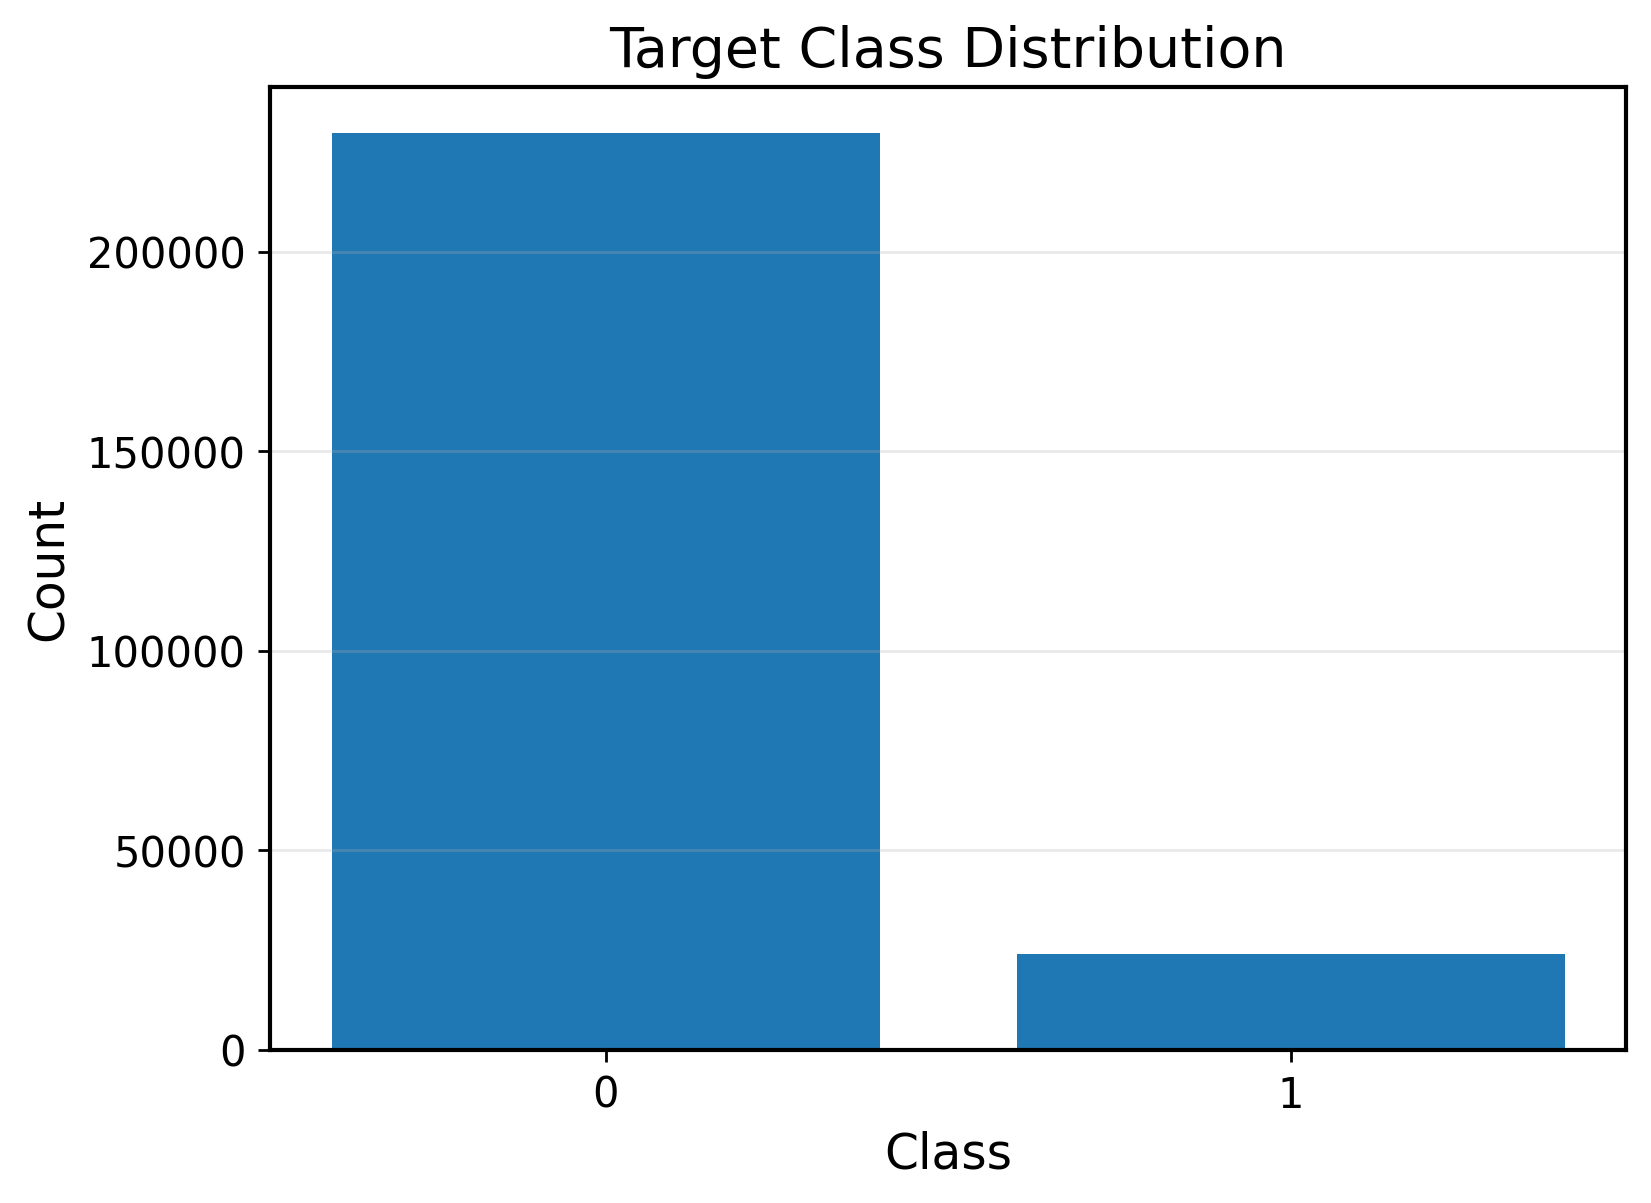

Module 1 complete
Full data shape      : (253680, 22)
Dev shape            : (202944, 21)
Test shape           : (50736, 21)
Duplicates           : 23899 (9.4209%)
Positive rate (full) : 0.094186
Positive rate (dev)  : 0.094184
Positive rate (test) : 0.094193
Binary features      : 13
Ordinal features     : 5
Continuous features  : 3
Other features       : 0
DATA_BUNDLE keys: ['df', 'X', 'y', 'X_dev', 'y_dev', 'X_test', 'y_test', 'dev_idx', 'test_idx', 'feature_cols', 'binary_features', 'ordinal_features', 'continuous_features', 'other_features']


In [2]:
# ============================================================
# Module 1 — Data Loading, Audit, Feature Typing, Dev/Test Split
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0 already executed
# ============================================================

from typing import Dict, List, Tuple

# ------------------------------------------------------------
# 1.1 Load dataset
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("Raw dataset loaded")
print("=" * 70)
print(f"Shape: {df.shape}")
print(f"Columns ({len(df.columns)}):")
print(list(df.columns))

# ------------------------------------------------------------
# 1.2 Basic validation
# ------------------------------------------------------------
if CONFIG.target_col not in df.columns:
    raise ValueError(
        f"Target column '{CONFIG.target_col}' not found in dataset.\n"
        f"Available columns: {list(df.columns)}"
    )

if df.empty:
    raise ValueError("Loaded dataframe is empty.")

# ------------------------------------------------------------
# 1.3 Standardize column names lightly (optional-safe)
# ------------------------------------------------------------
# Keep original names for paper consistency, but strip accidental spaces
df.columns = [c.strip() for c in df.columns]

# Re-check target after stripping
if CONFIG.target_col not in df.columns:
    raise ValueError(
        f"Target column '{CONFIG.target_col}' not found after column cleanup."
    )

# ------------------------------------------------------------
# 1.4 Dataset audit
# ------------------------------------------------------------
n_rows_before = len(df)
n_cols_before = df.shape[1]

duplicate_rows = int(df.duplicated().sum())
duplicate_rate = duplicate_rows / max(len(df), 1)

missing_counts = df.isna().sum()
missing_pct = (missing_counts / len(df)) * 100

dtype_table = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    "missing_count": [missing_counts[c] for c in df.columns],
    "missing_pct": [missing_pct[c] for c in df.columns],
})

dtype_table = dtype_table.sort_values(["missing_count", "n_unique"], ascending=[False, True]).reset_index(drop=True)
dtype_table.to_csv(AUDIT_DIR / "column_audit.csv", index=False)

# ------------------------------------------------------------
# 1.5 Target inspection
# ------------------------------------------------------------
target_counts = df[CONFIG.target_col].value_counts(dropna=False).sort_index()
target_pos_rate = float(df[CONFIG.target_col].mean())

target_summary = pd.DataFrame({
    "class": target_counts.index,
    "count": target_counts.values,
    "pct": target_counts.values / len(df)
})
target_summary.to_csv(AUDIT_DIR / "target_distribution.csv", index=False)

print("=" * 70)
print("Target distribution")
print("=" * 70)
print(target_summary)
print(f"\nPositive class rate: {target_pos_rate:.6f}")

# ------------------------------------------------------------
# 1.6 Separate features and target
# ------------------------------------------------------------
X = df.drop(columns=[CONFIG.target_col]).copy()
y = df[CONFIG.target_col].copy()

# Optional strict validation for binary target
unique_target_values = sorted(pd.Series(y).dropna().unique().tolist())
if set(unique_target_values) - {0, 1}:
    raise ValueError(
        f"Target must be binary with values in {{0,1}}. Found: {unique_target_values}"
    )

feature_cols = X.columns.tolist()

# ------------------------------------------------------------
# 1.7 Infer feature types
# ------------------------------------------------------------
# Heuristic rules:
# - binary: exactly 2 unique values and subset of {0,1}
# - ordinal: integer-like / low-cardinality discrete variables
# - continuous: higher-cardinality numeric variables
#
# For BRFSS this usually works well enough for v1 pipeline.
# We also save a detailed table for manual review.

def is_integer_like(series: pd.Series, tol: float = 1e-9) -> bool:
    s = pd.to_numeric(series.dropna(), errors="coerce")
    s = s.dropna()
    if len(s) == 0:
        return False
    return np.all(np.abs(s - np.round(s)) < tol)

binary_features: List[str] = []
ordinal_features: List[str] = []
continuous_features: List[str] = []
other_features: List[str] = []

feature_type_rows = []

for col in feature_cols:
    s = X[col]
    nunique = s.nunique(dropna=True)
    dtype_str = str(s.dtype)

    col_type = "other"

    # try numeric interpretation
    s_num = pd.to_numeric(s, errors="coerce")
    numeric_fraction = s_num.notna().mean()

    if numeric_fraction >= 0.99:
        unique_vals = sorted(pd.Series(s_num.dropna().unique()).tolist())

        if nunique == 2 and set(unique_vals).issubset({0, 1}):
            col_type = "binary"
            binary_features.append(col)

        elif is_integer_like(s_num) and nunique <= 15:
            # low-cardinality discrete variables likely ordinal in BRFSS
            col_type = "ordinal"
            ordinal_features.append(col)

        else:
            col_type = "continuous"
            continuous_features.append(col)
    else:
        col_type = "other"
        other_features.append(col)

    feature_type_rows.append({
        "feature": col,
        "assigned_type": col_type,
        "dtype": dtype_str,
        "n_unique": int(nunique),
        "min": pd.to_numeric(s, errors="coerce").min(),
        "max": pd.to_numeric(s, errors="coerce").max(),
        "numeric_fraction": float(numeric_fraction),
    })

feature_type_table = pd.DataFrame(feature_type_rows).sort_values(
    ["assigned_type", "n_unique", "feature"]
).reset_index(drop=True)

feature_type_table.to_csv(AUDIT_DIR / "feature_type_table.csv", index=False)

# ------------------------------------------------------------
# 1.8 Manual BRFSS-aware adjustment hook
# ------------------------------------------------------------
# If needed later, move columns manually between ordinal/continuous.
# For now, we keep the heuristic assignment but expose a clean hook.

MANUAL_TYPE_OVERRIDES = {
    "binary_to_ordinal": [],
    "binary_to_continuous": [],
    "ordinal_to_binary": [],
    "ordinal_to_continuous": [],
    "continuous_to_binary": [],
    "continuous_to_ordinal": [],
}

def apply_feature_type_overrides(
    binary_feats: List[str],
    ordinal_feats: List[str],
    continuous_feats: List[str],
    overrides: Dict[str, List[str]],
) -> Tuple[List[str], List[str], List[str]]:
    b = set(binary_feats)
    o = set(ordinal_feats)
    c = set(continuous_feats)

    def move(cols, src, dst):
        for col in cols:
            if col in src:
                src.remove(col)
            dst.add(col)

    move(overrides.get("binary_to_ordinal", []), b, o)
    move(overrides.get("binary_to_continuous", []), b, c)
    move(overrides.get("ordinal_to_binary", []), o, b)
    move(overrides.get("ordinal_to_continuous", []), o, c)
    move(overrides.get("continuous_to_binary", []), c, b)
    move(overrides.get("continuous_to_ordinal", []), c, o)

    return sorted(b), sorted(o), sorted(c)

binary_features, ordinal_features, continuous_features = apply_feature_type_overrides(
    binary_features, ordinal_features, continuous_features, MANUAL_TYPE_OVERRIDES
)

# Catch any leftover non-numeric columns
assigned = set(binary_features) | set(ordinal_features) | set(continuous_features)
unassigned_features = sorted(list(set(feature_cols) - assigned))
other_features = sorted(list(set(other_features) | set(unassigned_features)))

# ------------------------------------------------------------
# 1.9 Save feature typing artifacts
# ------------------------------------------------------------
feature_info = {
    "target_col": CONFIG.target_col,
    "n_features_total": len(feature_cols),
    "binary_features": binary_features,
    "ordinal_features": ordinal_features,
    "continuous_features": continuous_features,
    "other_features": other_features,
    "n_binary": len(binary_features),
    "n_ordinal": len(ordinal_features),
    "n_continuous": len(continuous_features),
    "n_other": len(other_features),
}

save_json(feature_info, ARTIFACT_PATHS["feature_types"])

print("=" * 70)
print("Feature typing summary")
print("=" * 70)
print(f"Binary      : {len(binary_features)}")
print(f"Ordinal     : {len(ordinal_features)}")
print(f"Continuous  : {len(continuous_features)}")
print(f"Other       : {len(other_features)}")

if len(other_features) > 0:
    print("\n[Warning] Some features were not confidently assigned as numeric:")
    print(other_features)

# ------------------------------------------------------------
# 1.10 Dev / Test split (fixed, one-time, stratified)
# ------------------------------------------------------------
all_indices = np.arange(len(df))

dev_idx, test_idx = train_test_split(
    all_indices,
    test_size=CONFIG.test_size,
    stratify=y,
    random_state=CONFIG.seed,
)

dev_idx = np.array(sorted(dev_idx))
test_idx = np.array(sorted(test_idx))

X_dev = X.iloc[dev_idx].reset_index(drop=True).copy()
y_dev = y.iloc[dev_idx].reset_index(drop=True).copy()

X_test = X.iloc[test_idx].reset_index(drop=True).copy()
y_test = y.iloc[test_idx].reset_index(drop=True).copy()

# save original-row split indices
np.savez(
    ARTIFACT_PATHS["dev_test_indices"],
    dev_idx=dev_idx,
    test_idx=test_idx,
)

# ------------------------------------------------------------
# 1.11 Split audit
# ------------------------------------------------------------
split_summary = pd.DataFrame([
    {
        "split": "full",
        "n": len(y),
        "positive_n": int(np.sum(y == 1)),
        "negative_n": int(np.sum(y == 0)),
        "positive_rate": float(np.mean(y)),
    },
    {
        "split": "dev",
        "n": len(y_dev),
        "positive_n": int(np.sum(y_dev == 1)),
        "negative_n": int(np.sum(y_dev == 0)),
        "positive_rate": float(np.mean(y_dev)),
    },
    {
        "split": "test",
        "n": len(y_test),
        "positive_n": int(np.sum(y_test == 1)),
        "negative_n": int(np.sum(y_test == 0)),
        "positive_rate": float(np.mean(y_test)),
    },
])

split_summary.to_csv(AUDIT_DIR / "dev_test_split_summary.csv", index=False)

# ------------------------------------------------------------
# 1.12 Missingness report for features only
# ------------------------------------------------------------
feature_missing_report = pd.DataFrame({
    "feature": feature_cols,
    "missing_count": [X[c].isna().sum() for c in feature_cols],
    "missing_pct": [100.0 * X[c].isna().mean() for c in feature_cols],
    "n_unique": [X[c].nunique(dropna=True) for c in feature_cols],
})
feature_missing_report = feature_missing_report.sort_values(
    ["missing_count", "n_unique"], ascending=[False, True]
).reset_index(drop=True)

feature_missing_report.to_csv(AUDIT_DIR / "feature_missing_report.csv", index=False)

# ------------------------------------------------------------
# 1.13 Simple class distribution figure
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
target_summary_plot = y.value_counts().sort_index()
plt.bar(["0", "1"], target_summary_plot.values)
plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "target_class_distribution")
plt.show()

# ------------------------------------------------------------
# 1.14 Audit summary export
# ------------------------------------------------------------
module1_summary = {
    "raw_shape": {"rows": int(n_rows_before), "cols": int(n_cols_before)},
    "target_col": CONFIG.target_col,
    "duplicate_rows": int(duplicate_rows),
    "duplicate_rate": float(duplicate_rate),
    "target_values": unique_target_values,
    "positive_rate_full": float(np.mean(y)),
    "positive_rate_dev": float(np.mean(y_dev)),
    "positive_rate_test": float(np.mean(y_test)),
    "n_features_total": len(feature_cols),
    "n_binary_features": len(binary_features),
    "n_ordinal_features": len(ordinal_features),
    "n_continuous_features": len(continuous_features),
    "n_other_features": len(other_features),
    "dev_size": int(len(dev_idx)),
    "test_size": int(len(test_idx)),
}

save_json(module1_summary, LOG_DIR / "module1_summary.json")

# ------------------------------------------------------------
# 1.15 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 1 complete")
print("=" * 70)
print(f"Full data shape      : {df.shape}")
print(f"Dev shape            : {X_dev.shape}")
print(f"Test shape           : {X_test.shape}")
print(f"Duplicates           : {duplicate_rows} ({duplicate_rate:.4%})")
print(f"Positive rate (full) : {np.mean(y):.6f}")
print(f"Positive rate (dev)  : {np.mean(y_dev):.6f}")
print(f"Positive rate (test) : {np.mean(y_test):.6f}")
print(f"Binary features      : {len(binary_features)}")
print(f"Ordinal features     : {len(ordinal_features)}")
print(f"Continuous features  : {len(continuous_features)}")
print(f"Other features       : {len(other_features)}")
print("=" * 70)

# ------------------------------------------------------------
# 1.16 Objects kept in memory for later modules
# ------------------------------------------------------------
DATA_BUNDLE = {
    "df": df,
    "X": X,
    "y": y,
    "X_dev": X_dev,
    "y_dev": y_dev,
    "X_test": X_test,
    "y_test": y_test,
    "dev_idx": dev_idx,
    "test_idx": test_idx,
    "feature_cols": feature_cols,
    "binary_features": binary_features,
    "ordinal_features": ordinal_features,
    "continuous_features": continuous_features,
    "other_features": other_features,
}

print("DATA_BUNDLE keys:", list(DATA_BUNDLE.keys()))

In [3]:
# ============================================================
# Module 2 — Leakage-Safe Preprocessing Pipelines
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0 and Module 1 already executed
# ============================================================

from copy import deepcopy
from typing import Optional
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

# ------------------------------------------------------------
# 2.1 Validate feature groups from Module 1
# ------------------------------------------------------------
required_keys = [
    "binary_features",
    "ordinal_features",
    "continuous_features",
    "other_features",
    "feature_cols",
    "X_dev",
    "X_test",
]
for k in required_keys:
    if k not in DATA_BUNDLE:
        raise KeyError(f"DATA_BUNDLE['{k}'] not found. Please run Module 1 first.")

binary_features = DATA_BUNDLE["binary_features"]
ordinal_features = DATA_BUNDLE["ordinal_features"]
continuous_features = DATA_BUNDLE["continuous_features"]
other_features = DATA_BUNDLE["other_features"]
feature_cols = DATA_BUNDLE["feature_cols"]

X_dev = DATA_BUNDLE["X_dev"]
X_test = DATA_BUNDLE["X_test"]

print("=" * 70)
print("Module 2: feature groups received")
print("=" * 70)
print(f"Binary      : {len(binary_features)}")
print(f"Ordinal     : {len(ordinal_features)}")
print(f"Continuous  : {len(continuous_features)}")
print(f"Other       : {len(other_features)}")

# ------------------------------------------------------------
# 2.2 Basic consistency checks
# ------------------------------------------------------------
all_grouped = binary_features + ordinal_features + continuous_features + other_features
if sorted(all_grouped) != sorted(feature_cols):
    missing_in_groups = sorted(set(feature_cols) - set(all_grouped))
    extras_in_groups = sorted(set(all_grouped) - set(feature_cols))
    raise ValueError(
        "Feature group mismatch detected.\n"
        f"Missing in groups: {missing_in_groups}\n"
        f"Extra in groups: {extras_in_groups}"
    )

if len(set(all_grouped)) != len(all_grouped):
    dupes = pd.Series(all_grouped).value_counts()
    dupes = dupes[dupes > 1].index.tolist()
    raise ValueError(f"Some features appear in multiple groups: {dupes}")

# ------------------------------------------------------------
# 2.3 Utility transformers
# ------------------------------------------------------------
class DataFrameCaster(BaseEstimator, TransformerMixin):
    """
    Ensures output is a pandas DataFrame with preserved column names when possible.
    Useful for pipelines where some downstream steps expect DataFrame-like input.
    """
    def __init__(self, columns: Optional[list] = None):
        self.columns = columns

    def fit(self, X, y=None):
        if isinstance(X, pd.DataFrame):
            self.columns_ = X.columns.tolist()
        else:
            self.columns_ = self.columns
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            return X.copy()
        if self.columns_ is None:
            return pd.DataFrame(X)
        return pd.DataFrame(X, columns=self.columns_)


class NumericClipper(BaseEstimator, TransformerMixin):
    """
    Optional clipper for numeric stability.
    Fit only on training fold data, then apply to validation/test.
    """
    def __init__(self, lower_q=0.001, upper_q=0.999):
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X).copy()
        self.lower_bounds_ = X_df.quantile(self.lower_q, axis=0)
        self.upper_bounds_ = X_df.quantile(self.upper_q, axis=0)
        self.columns_ = X_df.columns.tolist()
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        X_df = X_df.clip(self.lower_bounds_, self.upper_bounds_, axis=1)
        X_df.columns = self.columns_
        return X_df


class ColumnSelector(BaseEstimator, TransformerMixin):
    """
    Select a subset of columns while preserving DataFrame structure.
    """
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        missing = [c for c in self.columns if c not in X.columns]
        if missing:
            raise ValueError(f"Missing columns in ColumnSelector: {missing}")
        return self

    def transform(self, X):
        return X[self.columns].copy()


# ------------------------------------------------------------
# 2.4 Shared preprocessing policy
# ------------------------------------------------------------
# Design:
# - Everything is fit only on training folds later.
# - Binary/ordinal columns mostly pass through with safe imputation.
# - Continuous features get imputation + scaling for linear/deep models.
# - Tree models receive very light preprocessing.
#
# Note:
# We avoid fitting any preprocessing on full dev/test here.
# This module only defines reusable builders.

PREPROCESSING_POLICY = {
    "binary_imputer_strategy": "most_frequent",
    "ordinal_imputer_strategy": "median",
    "continuous_imputer_strategy": "median",
    "continuous_scaler_linear": "robust",
    "continuous_scaler_deep": "standard",
    "use_numeric_clipping_for_linear": False,
    "use_numeric_clipping_for_deep": False,
}

save_json(PREPROCESSING_POLICY, ART_DIR / "preprocessing_policy.json")

# ------------------------------------------------------------
# 2.5 Column lists used by pipelines
# ------------------------------------------------------------
TREE_FEATURES = binary_features + ordinal_features + continuous_features
LINEAR_BINARY_FEATURES = binary_features
LINEAR_ORDINAL_FEATURES = ordinal_features
LINEAR_CONTINUOUS_FEATURES = continuous_features
DEEP_BINARY_FEATURES = binary_features
DEEP_ORDINAL_FEATURES = ordinal_features
DEEP_CONTINUOUS_FEATURES = continuous_features

# For safety, exclude "other_features" from v1 model pipelines unless needed later.
if len(other_features) > 0:
    print("\n[Note] 'other_features' detected and excluded from default v1 pipelines:")
    print(other_features)

# ------------------------------------------------------------
# 2.6 Primitive sub-pipelines
# ------------------------------------------------------------
def make_binary_pipeline():
    return Pipeline(steps=[
        ("selector_ready", FunctionTransformer(lambda x: x, validate=False)),
        ("imputer", SimpleImputer(strategy=PREPROCESSING_POLICY["binary_imputer_strategy"])),
    ])

def make_ordinal_pipeline():
    return Pipeline(steps=[
        ("selector_ready", FunctionTransformer(lambda x: x, validate=False)),
        ("imputer", SimpleImputer(strategy=PREPROCESSING_POLICY["ordinal_imputer_strategy"])),
    ])

def make_continuous_pipeline_for_linear():
    steps = [
        ("selector_ready", FunctionTransformer(lambda x: x, validate=False)),
        ("imputer", SimpleImputer(strategy=PREPROCESSING_POLICY["continuous_imputer_strategy"])),
    ]
    if PREPROCESSING_POLICY["use_numeric_clipping_for_linear"]:
        steps.append(("clipper", NumericClipper(lower_q=0.001, upper_q=0.999)))
    if PREPROCESSING_POLICY["continuous_scaler_linear"] == "robust":
        steps.append(("scaler", RobustScaler()))
    elif PREPROCESSING_POLICY["continuous_scaler_linear"] == "standard":
        steps.append(("scaler", StandardScaler()))
    else:
        raise ValueError("Unknown linear scaler setting.")
    return Pipeline(steps=steps)

def make_continuous_pipeline_for_deep():
    steps = [
        ("selector_ready", FunctionTransformer(lambda x: x, validate=False)),
        ("imputer", SimpleImputer(strategy=PREPROCESSING_POLICY["continuous_imputer_strategy"])),
    ]
    if PREPROCESSING_POLICY["use_numeric_clipping_for_deep"]:
        steps.append(("clipper", NumericClipper(lower_q=0.001, upper_q=0.999)))
    if PREPROCESSING_POLICY["continuous_scaler_deep"] == "standard":
        steps.append(("scaler", StandardScaler()))
    elif PREPROCESSING_POLICY["continuous_scaler_deep"] == "robust":
        steps.append(("scaler", RobustScaler()))
    else:
        raise ValueError("Unknown deep scaler setting.")
    return Pipeline(steps=steps)

def make_passthrough_numeric_pipeline():
    return Pipeline(steps=[
        ("selector_ready", FunctionTransformer(lambda x: x, validate=False)),
        ("imputer", SimpleImputer(strategy="median")),
    ])

# ------------------------------------------------------------
# 2.7 Tree-family preprocessor
# ------------------------------------------------------------
# Tree models usually do not need scaling.
# We keep:
# - imputation
# - column order preservation
# - numeric passthrough
#
# This is still leakage-safe because fit happens fold-wise later.

def build_tree_preprocessor():
    transformers = []

    if len(binary_features) > 0:
        transformers.append(("bin", make_binary_pipeline(), binary_features))

    if len(ordinal_features) > 0:
        transformers.append(("ord", make_ordinal_pipeline(), ordinal_features))

    if len(continuous_features) > 0:
        transformers.append(("cont", make_passthrough_numeric_pipeline(), continuous_features))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
        verbose_feature_names_out=False,
    )
    return preprocessor

# ------------------------------------------------------------
# 2.8 Linear-family preprocessor
# ------------------------------------------------------------
# For LR / linear models:
# - binary: impute only
# - ordinal: impute only (v1)
# - continuous: impute + robust scale

def build_linear_preprocessor():
    transformers = []

    if len(LINEAR_BINARY_FEATURES) > 0:
        transformers.append(("bin", make_binary_pipeline(), LINEAR_BINARY_FEATURES))

    if len(LINEAR_ORDINAL_FEATURES) > 0:
        transformers.append(("ord", make_ordinal_pipeline(), LINEAR_ORDINAL_FEATURES))

    if len(LINEAR_CONTINUOUS_FEATURES) > 0:
        transformers.append(("cont", make_continuous_pipeline_for_linear(), LINEAR_CONTINUOUS_FEATURES))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
        verbose_feature_names_out=False,
    )
    return preprocessor

# ------------------------------------------------------------
# 2.9 Deep-family preprocessor
# ------------------------------------------------------------
# For MLP / DeepFM v1:
# - binary: impute only
# - ordinal: impute only
# - continuous: impute + standard scale
#
# Later, if you build embedding-aware DeepFM input,
# this can be expanded into a richer deep-view pipeline.

def build_deep_preprocessor():
    transformers = []

    if len(DEEP_BINARY_FEATURES) > 0:
        transformers.append(("bin", make_binary_pipeline(), DEEP_BINARY_FEATURES))

    if len(DEEP_ORDINAL_FEATURES) > 0:
        transformers.append(("ord", make_ordinal_pipeline(), DEEP_ORDINAL_FEATURES))

    if len(DEEP_CONTINUOUS_FEATURES) > 0:
        transformers.append(("cont", make_continuous_pipeline_for_deep(), DEEP_CONTINUOUS_FEATURES))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
        verbose_feature_names_out=False,
    )
    return preprocessor

# ------------------------------------------------------------
# 2.10 Helper to recover transformed feature names
# ------------------------------------------------------------
def get_transformed_feature_names(fitted_preprocessor):
    """
    Returns output feature names from a fitted ColumnTransformer.
    """
    try:
        names = fitted_preprocessor.get_feature_names_out()
        return list(names)
    except Exception:
        return None

# ------------------------------------------------------------
# 2.11 Safe fit-transform utility for later CV use
# ------------------------------------------------------------
def fit_transform_preprocessor(preprocessor, X_train: pd.DataFrame, X_valid: Optional[pd.DataFrame] = None):
    """
    Fit on X_train only, then transform X_train and optionally X_valid.
    This function is intentionally fold-safe and will be used in CV later.
    """
    pre = deepcopy(preprocessor)
    X_train_t = pre.fit_transform(X_train)
    feature_names = get_transformed_feature_names(pre)

    if feature_names is not None:
        X_train_t = pd.DataFrame(X_train_t, columns=feature_names, index=X_train.index)
    else:
        X_train_t = pd.DataFrame(X_train_t, index=X_train.index)

    if X_valid is not None:
        X_valid_t = pre.transform(X_valid)
        if feature_names is not None:
            X_valid_t = pd.DataFrame(X_valid_t, columns=feature_names, index=X_valid.index)
        else:
            X_valid_t = pd.DataFrame(X_valid_t, index=X_valid.index)
        return pre, X_train_t, X_valid_t

    return pre, X_train_t

# ------------------------------------------------------------
# 2.12 Build all default preprocessors
# ------------------------------------------------------------
PREPROCESSOR_FACTORY = {
    "tree": build_tree_preprocessor,
    "linear": build_linear_preprocessor,
    "deep": build_deep_preprocessor,
}

PREPROCESSORS = {
    "tree": build_tree_preprocessor(),
    "linear": build_linear_preprocessor(),
    "deep": build_deep_preprocessor(),
}

# ------------------------------------------------------------
# 2.13 Sanity-check on a small sample
# ------------------------------------------------------------
sample_n = min(1000, len(X_dev))
X_sample = X_dev.iloc[:sample_n].copy()

preproc_audit_rows = []

for family, preproc in PREPROCESSORS.items():
    fitted_preproc, X_sample_t = fit_transform_preprocessor(preproc, X_sample)

    row = {
        "family": family,
        "input_rows": int(X_sample.shape[0]),
        "input_cols": int(X_sample.shape[1]),
        "output_rows": int(X_sample_t.shape[0]),
        "output_cols": int(X_sample_t.shape[1]),
        "has_nan_after_transform": bool(pd.DataFrame(X_sample_t).isna().any().any()),
    }

    names = get_transformed_feature_names(fitted_preproc)
    row["feature_name_recovered"] = names is not None
    preproc_audit_rows.append(row)

preproc_audit_df = pd.DataFrame(preproc_audit_rows)
preproc_audit_df.to_csv(AUDIT_DIR / "preprocessor_sanity_check.csv", index=False)

# ------------------------------------------------------------
# 2.14 Optional preview: fit on sample and transform test sample
# ------------------------------------------------------------
preview_rows = min(5, len(X_test))

tree_pre = build_tree_preprocessor()
tree_pre_fitted, Xs_train_tree, Xs_test_tree = fit_transform_preprocessor(
    tree_pre,
    X_dev.iloc[:sample_n].copy(),
    X_test.iloc[:preview_rows].copy()
)

linear_pre = build_linear_preprocessor()
linear_pre_fitted, Xs_train_linear, Xs_test_linear = fit_transform_preprocessor(
    linear_pre,
    X_dev.iloc[:sample_n].copy(),
    X_test.iloc[:preview_rows].copy()
)

deep_pre = build_deep_preprocessor()
deep_pre_fitted, Xs_train_deep, Xs_test_deep = fit_transform_preprocessor(
    deep_pre,
    X_dev.iloc[:sample_n].copy(),
    X_test.iloc[:preview_rows].copy()
)

# ------------------------------------------------------------
# 2.15 Save preprocessing metadata
# ------------------------------------------------------------
preprocessing_summary = {
    "policy": PREPROCESSING_POLICY,
    "n_binary_features": len(binary_features),
    "n_ordinal_features": len(ordinal_features),
    "n_continuous_features": len(continuous_features),
    "n_other_features_excluded_from_v1": len(other_features),
    "tree_feature_count": len(TREE_FEATURES),
    "linear_feature_count": len(LINEAR_BINARY_FEATURES) + len(LINEAR_ORDINAL_FEATURES) + len(LINEAR_CONTINUOUS_FEATURES),
    "deep_feature_count": len(DEEP_BINARY_FEATURES) + len(DEEP_ORDINAL_FEATURES) + len(DEEP_CONTINUOUS_FEATURES),
}

save_json(preprocessing_summary, LOG_DIR / "module2_preprocessing_summary.json")

# ------------------------------------------------------------
# 2.16 Keep key objects for later modules
# ------------------------------------------------------------
PREPROCESSING_BUNDLE = {
    "policy": PREPROCESSING_POLICY,
    "preprocessor_factory": PREPROCESSOR_FACTORY,
    "preprocessors": PREPROCESSORS,
    "fit_transform_preprocessor": fit_transform_preprocessor,
    "get_transformed_feature_names": get_transformed_feature_names,
    "tree_features": TREE_FEATURES,
    "linear_binary_features": LINEAR_BINARY_FEATURES,
    "linear_ordinal_features": LINEAR_ORDINAL_FEATURES,
    "linear_continuous_features": LINEAR_CONTINUOUS_FEATURES,
    "deep_binary_features": DEEP_BINARY_FEATURES,
    "deep_ordinal_features": DEEP_ORDINAL_FEATURES,
    "deep_continuous_features": DEEP_CONTINUOUS_FEATURES,
}

# ------------------------------------------------------------
# 2.17 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 2 complete")
print("=" * 70)
print("Preprocessor sanity check:")
print(preproc_audit_df)
print("\nPreview transformed shapes:")
print(f"Tree   -> train: {Xs_train_tree.shape}, test preview: {Xs_test_tree.shape}")
print(f"Linear -> train: {Xs_train_linear.shape}, test preview: {Xs_test_linear.shape}")
print(f"Deep   -> train: {Xs_train_deep.shape}, test preview: {Xs_test_deep.shape}")
print("=" * 70)
print("PREPROCESSING_BUNDLE keys:", list(PREPROCESSING_BUNDLE.keys()))

Module 2: feature groups received
Binary      : 13
Ordinal     : 5
Continuous  : 3
Other       : 0
Module 2 complete
Preprocessor sanity check:
   family  input_rows  input_cols  output_rows  output_cols  \
0    tree        1000          21         1000           21   
1  linear        1000          21         1000           21   
2    deep        1000          21         1000           21   

   has_nan_after_transform  feature_name_recovered  
0                    False                   False  
1                    False                   False  
2                    False                   False  

Preview transformed shapes:
Tree   -> train: (1000, 21), test preview: (5, 21)
Linear -> train: (1000, 21), test preview: (5, 21)
Deep   -> train: (1000, 21), test preview: (5, 21)
PREPROCESSING_BUNDLE keys: ['policy', 'preprocessor_factory', 'preprocessors', 'fit_transform_preprocessor', 'get_transformed_feature_names', 'tree_features', 'linear_binary_features', 'linear_ordinal_features

In [4]:
# ============================================================
# Module 3 — Repeated Stratified CV Engine with Inner Validation
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0, Module 1, Module 2 already executed
# ============================================================

from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Iterator, Any
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedShuffleSplit

# ------------------------------------------------------------
# 3.1 Validate required objects
# ------------------------------------------------------------
required_data_keys = ["X_dev", "y_dev"]
for k in required_data_keys:
    if k not in DATA_BUNDLE:
        raise KeyError(f"DATA_BUNDLE['{k}'] not found. Please run Module 1 first.")

X_dev = DATA_BUNDLE["X_dev"].copy()
y_dev = DATA_BUNDLE["y_dev"].copy()

if not isinstance(X_dev, pd.DataFrame):
    X_dev = pd.DataFrame(X_dev)

if not isinstance(y_dev, pd.Series):
    y_dev = pd.Series(y_dev)

print("=" * 70)
print("Module 3: CV engine setup")
print("=" * 70)
print(f"Development set shape: {X_dev.shape}")
print(f"Positive rate        : {y_dev.mean():.6f}")

# ------------------------------------------------------------
# 3.2 CV configuration summary
# ------------------------------------------------------------
CV_CONFIG = {
    "n_splits": CONFIG.n_splits,
    "n_repeats": CONFIG.n_repeats,
    "random_state": CONFIG.seed,
    "use_inner_validation": CONFIG.early_stopping,
    "inner_valid_size": CONFIG.inner_valid_size,
    "inner_random_state_base": CONFIG.seed + 10_000,
}

save_json(CV_CONFIG, LOG_DIR / "module3_cv_config.json")

# ------------------------------------------------------------
# 3.3 Data classes for clean fold bookkeeping
# ------------------------------------------------------------
@dataclass
class InnerSplit:
    train_idx: np.ndarray
    es_idx: np.ndarray   # early-stopping / inner validation indices, relative to full dev set

@dataclass
class OuterFold:
    repeat_id: int
    fold_id: int
    global_fold_id: int
    outer_train_idx: np.ndarray
    outer_valid_idx: np.ndarray
    inner_split: Optional[InnerSplit] = None

@dataclass
class FoldDataBundle:
    repeat_id: int
    fold_id: int
    global_fold_id: int

    X_outer_train: pd.DataFrame
    y_outer_train: pd.Series
    X_outer_valid: pd.DataFrame
    y_outer_valid: pd.Series

    outer_train_idx: np.ndarray
    outer_valid_idx: np.ndarray

    X_fit_train: pd.DataFrame
    y_fit_train: pd.Series
    fit_train_idx: np.ndarray

    X_es_valid: Optional[pd.DataFrame]
    y_es_valid: Optional[pd.Series]
    es_valid_idx: Optional[np.ndarray]

# ------------------------------------------------------------
# 3.4 Helper: safe stratified inner split for early stopping
# ------------------------------------------------------------
def make_inner_split(
    y_outer_train: pd.Series,
    outer_train_idx: np.ndarray,
    inner_valid_size: float,
    random_state: int,
) -> InnerSplit:
    """
    Create a stratified inner validation split from the outer-train portion only.
    Returns absolute indices with respect to the full development set.
    """
    if not (0.0 < inner_valid_size < 0.5):
        raise ValueError(f"inner_valid_size must be in (0, 0.5). Got {inner_valid_size}")

    y_outer_train = pd.Series(y_outer_train).reset_index(drop=True)
    rel_idx = np.arange(len(y_outer_train))

    unique_classes = np.unique(y_outer_train)
    if len(unique_classes) < 2:
        raise ValueError("Outer-train split contains only one class; stratified inner split impossible.")

    sss = StratifiedShuffleSplit(
        n_splits=1,
        test_size=inner_valid_size,
        random_state=random_state
    )

    rel_fit_idx, rel_es_idx = next(sss.split(rel_idx, y_outer_train))

    fit_idx_abs = outer_train_idx[rel_fit_idx]
    es_idx_abs = outer_train_idx[rel_es_idx]

    return InnerSplit(
        train_idx=np.array(sorted(fit_idx_abs)),
        es_idx=np.array(sorted(es_idx_abs)),
    )

# ------------------------------------------------------------
# 3.5 Main CV registry builder
# ------------------------------------------------------------
def build_repeated_stratified_cv_registry(
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    n_repeats: int,
    random_state: int,
    use_inner_validation: bool = True,
    inner_valid_size: float = 0.15,
    inner_random_state_base: int = 10_000,
) -> List[OuterFold]:
    """
    Build the full repeated stratified K-fold registry over the development set.
    Optionally add an inner stratified split from the outer-train partition for early stopping.
    """
    X = pd.DataFrame(X).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    rskf = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=random_state
    )

    registry: List[OuterFold] = []
    split_counter = 0

    for split_idx, (outer_train_idx, outer_valid_idx) in enumerate(rskf.split(X, y)):
        repeat_id = split_idx // n_splits
        fold_id = split_idx % n_splits

        outer_train_idx = np.array(sorted(outer_train_idx))
        outer_valid_idx = np.array(sorted(outer_valid_idx))

        inner_split = None
        if use_inner_validation:
            y_outer_train = y.iloc[outer_train_idx].reset_index(drop=True)
            inner_seed = inner_random_state_base + split_idx

            inner_split = make_inner_split(
                y_outer_train=y_outer_train,
                outer_train_idx=outer_train_idx,
                inner_valid_size=inner_valid_size,
                random_state=inner_seed,
            )

        registry.append(
            OuterFold(
                repeat_id=repeat_id,
                fold_id=fold_id,
                global_fold_id=split_counter,
                outer_train_idx=outer_train_idx,
                outer_valid_idx=outer_valid_idx,
                inner_split=inner_split,
            )
        )
        split_counter += 1

    return registry

# ------------------------------------------------------------
# 3.6 Build registry
# ------------------------------------------------------------
CV_REGISTRY = build_repeated_stratified_cv_registry(
    X=X_dev,
    y=y_dev,
    n_splits=CV_CONFIG["n_splits"],
    n_repeats=CV_CONFIG["n_repeats"],
    random_state=CV_CONFIG["random_state"],
    use_inner_validation=CV_CONFIG["use_inner_validation"],
    inner_valid_size=CV_CONFIG["inner_valid_size"],
    inner_random_state_base=CV_CONFIG["inner_random_state_base"],
)

# ------------------------------------------------------------
# 3.7 Convert registry to audit table
# ------------------------------------------------------------
def summarize_fold_registry(
    registry: List[OuterFold],
    y: pd.Series
) -> pd.DataFrame:
    rows = []

    y = pd.Series(y).reset_index(drop=True)

    for fold in registry:
        outer_train_y = y.iloc[fold.outer_train_idx]
        outer_valid_y = y.iloc[fold.outer_valid_idx]

        row = {
            "global_fold_id": fold.global_fold_id,
            "repeat_id": fold.repeat_id,
            "fold_id": fold.fold_id,
            "outer_train_n": len(fold.outer_train_idx),
            "outer_valid_n": len(fold.outer_valid_idx),
            "outer_train_pos_n": int((outer_train_y == 1).sum()),
            "outer_valid_pos_n": int((outer_valid_y == 1).sum()),
            "outer_train_pos_rate": float(outer_train_y.mean()),
            "outer_valid_pos_rate": float(outer_valid_y.mean()),
            "has_inner_validation": fold.inner_split is not None,
        }

        if fold.inner_split is not None:
            fit_train_y = y.iloc[fold.inner_split.train_idx]
            es_valid_y = y.iloc[fold.inner_split.es_idx]

            row.update({
                "fit_train_n": len(fold.inner_split.train_idx),
                "es_valid_n": len(fold.inner_split.es_idx),
                "fit_train_pos_n": int((fit_train_y == 1).sum()),
                "es_valid_pos_n": int((es_valid_y == 1).sum()),
                "fit_train_pos_rate": float(fit_train_y.mean()),
                "es_valid_pos_rate": float(es_valid_y.mean()),
            })
        else:
            row.update({
                "fit_train_n": len(fold.outer_train_idx),
                "es_valid_n": 0,
                "fit_train_pos_n": int((outer_train_y == 1).sum()),
                "es_valid_pos_n": 0,
                "fit_train_pos_rate": float(outer_train_y.mean()),
                "es_valid_pos_rate": np.nan,
            })

        rows.append(row)

    return pd.DataFrame(rows)

cv_registry_df = summarize_fold_registry(CV_REGISTRY, y_dev)
cv_registry_df.to_csv(ARTIFACT_PATHS["cv_registry"], index=False)
cv_registry_df.to_csv(AUDIT_DIR / "cv_fold_registry_full.csv", index=False)

# ------------------------------------------------------------
# 3.8 Fold retrieval utility
# ------------------------------------------------------------
def get_fold_data_bundle(
    X: pd.DataFrame,
    y: pd.Series,
    fold: OuterFold
) -> FoldDataBundle:
    """
    Given a fold registry entry, return all data slices needed by training code.
    - outer_valid: untouched validation fold used for scoring / OOF prediction
    - fit_train: actual training subset used to fit model
    - es_valid: optional inner validation subset for early stopping only
    """
    X = pd.DataFrame(X).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)

    X_outer_train = X.iloc[fold.outer_train_idx].copy()
    y_outer_train = y.iloc[fold.outer_train_idx].copy()

    X_outer_valid = X.iloc[fold.outer_valid_idx].copy()
    y_outer_valid = y.iloc[fold.outer_valid_idx].copy()

    if fold.inner_split is not None:
        fit_train_idx = fold.inner_split.train_idx
        es_valid_idx = fold.inner_split.es_idx

        X_fit_train = X.iloc[fit_train_idx].copy()
        y_fit_train = y.iloc[fit_train_idx].copy()

        X_es_valid = X.iloc[es_valid_idx].copy()
        y_es_valid = y.iloc[es_valid_idx].copy()
    else:
        fit_train_idx = fold.outer_train_idx
        es_valid_idx = None

        X_fit_train = X_outer_train.copy()
        y_fit_train = y_outer_train.copy()

        X_es_valid = None
        y_es_valid = None

    return FoldDataBundle(
        repeat_id=fold.repeat_id,
        fold_id=fold.fold_id,
        global_fold_id=fold.global_fold_id,
        X_outer_train=X_outer_train,
        y_outer_train=y_outer_train,
        X_outer_valid=X_outer_valid,
        y_outer_valid=y_outer_valid,
        outer_train_idx=fold.outer_train_idx,
        outer_valid_idx=fold.outer_valid_idx,
        X_fit_train=X_fit_train,
        y_fit_train=y_fit_train,
        fit_train_idx=fit_train_idx,
        X_es_valid=X_es_valid,
        y_es_valid=y_es_valid,
        es_valid_idx=es_valid_idx,
    )

# ------------------------------------------------------------
# 3.9 Iteration utility for later model loops
# ------------------------------------------------------------
def iter_cv_folds(
    X: pd.DataFrame,
    y: pd.Series,
    registry: List[OuterFold]
) -> Iterator[FoldDataBundle]:
    for fold in registry:
        yield get_fold_data_bundle(X, y, fold)

# ------------------------------------------------------------
# 3.10 OOF template utility
# ------------------------------------------------------------
def make_oof_template(n_samples: int, fill_value: float = np.nan) -> np.ndarray:
    """
    For one pass of CV predictions on the development set.
    Note:
    In repeated CV, each sample receives multiple OOF predictions across repeats.
    So later modules should store fold-wise predictions in long format rather than a single vector.
    """
    return np.full(shape=n_samples, fill_value=fill_value, dtype=float)

# ------------------------------------------------------------
# 3.11 Fold prediction record helper
# ------------------------------------------------------------
def make_empty_fold_prediction_records() -> List[Dict[str, Any]]:
    return []

def append_fold_prediction_records(
    records: List[Dict[str, Any]],
    fold_bundle: FoldDataBundle,
    y_true: np.ndarray,
    y_prob: np.ndarray,
    model_name: str,
    stage: str = "outer_valid",
):
    """
    Store prediction records in long format.
    Important for repeated CV: the same sample appears in validation multiple times across repeats.
    """
    if len(y_true) != len(y_prob):
        raise ValueError("y_true and y_prob length mismatch.")

    sample_indices = fold_bundle.outer_valid_idx if stage == "outer_valid" else fold_bundle.es_valid_idx

    for sample_idx, yt, yp in zip(sample_indices, y_true, y_prob):
        records.append({
            "model": model_name,
            "stage": stage,
            "global_fold_id": fold_bundle.global_fold_id,
            "repeat_id": fold_bundle.repeat_id,
            "fold_id": fold_bundle.fold_id,
            "sample_idx": int(sample_idx),
            "y_true": int(yt),
            "y_prob": float(yp),
        })

# ------------------------------------------------------------
# 3.12 Fold integrity checker
# ------------------------------------------------------------
def validate_cv_registry(
    registry: List[OuterFold],
    n_samples: int
) -> Dict[str, Any]:
    """
    Basic sanity checks:
    - no overlap between outer_train and outer_valid
    - inner split lives inside outer_train
    - no overlap between fit_train and es_valid
    """
    issues = []

    for fold in registry:
        outer_train_set = set(fold.outer_train_idx.tolist())
        outer_valid_set = set(fold.outer_valid_idx.tolist())

        if len(outer_train_set & outer_valid_set) > 0:
            issues.append(
                f"Overlap detected between outer_train and outer_valid in global_fold_id={fold.global_fold_id}"
            )

        if fold.inner_split is not None:
            fit_set = set(fold.inner_split.train_idx.tolist())
            es_set = set(fold.inner_split.es_idx.tolist())

            if not fit_set.issubset(outer_train_set):
                issues.append(
                    f"Inner fit_train not subset of outer_train in global_fold_id={fold.global_fold_id}"
                )

            if not es_set.issubset(outer_train_set):
                issues.append(
                    f"Inner es_valid not subset of outer_train in global_fold_id={fold.global_fold_id}"
                )

            if len(fit_set & es_set) > 0:
                issues.append(
                    f"Overlap detected between fit_train and es_valid in global_fold_id={fold.global_fold_id}"
                )

        max_seen = max(
            np.max(fold.outer_train_idx),
            np.max(fold.outer_valid_idx),
        )
        if max_seen >= n_samples:
            issues.append(
                f"Index out of bounds in global_fold_id={fold.global_fold_id}"
            )

    return {
        "n_folds": len(registry),
        "n_issues": len(issues),
        "issues": issues,
        "is_valid": len(issues) == 0,
    }

cv_validation_report = validate_cv_registry(CV_REGISTRY, n_samples=len(X_dev))
save_json(cv_validation_report, LOG_DIR / "module3_cv_validation_report.json")

if not cv_validation_report["is_valid"]:
    raise RuntimeError(
        "CV registry validation failed:\n" + "\n".join(cv_validation_report["issues"])
    )

# ------------------------------------------------------------
# 3.13 Coverage audit for repeated CV
# ------------------------------------------------------------
def compute_repeated_cv_validation_counts(registry: List[OuterFold], n_samples: int) -> pd.DataFrame:
    counts = np.zeros(n_samples, dtype=int)

    for fold in registry:
        counts[fold.outer_valid_idx] += 1

    df_counts = pd.DataFrame({
        "sample_idx": np.arange(n_samples),
        "n_times_in_outer_valid": counts
    })
    return df_counts

cv_counts_df = compute_repeated_cv_validation_counts(CV_REGISTRY, n_samples=len(X_dev))
cv_counts_df.to_csv(AUDIT_DIR / "repeated_cv_validation_counts.csv", index=False)

coverage_summary = {
    "expected_times_each_sample_appears_in_outer_valid": CONFIG.n_repeats,
    "observed_min": int(cv_counts_df["n_times_in_outer_valid"].min()),
    "observed_max": int(cv_counts_df["n_times_in_outer_valid"].max()),
    "observed_mean": float(cv_counts_df["n_times_in_outer_valid"].mean()),
    "all_samples_seen_exactly_n_repeats_times": bool(
        (cv_counts_df["n_times_in_outer_valid"] == CONFIG.n_repeats).all()
    ),
}
save_json(coverage_summary, LOG_DIR / "module3_cv_coverage_summary.json")

# ------------------------------------------------------------
# 3.14 Preview first fold bundle
# ------------------------------------------------------------
first_fold_bundle = get_fold_data_bundle(X_dev, y_dev, CV_REGISTRY[0])

preview_info = {
    "global_fold_id": first_fold_bundle.global_fold_id,
    "repeat_id": first_fold_bundle.repeat_id,
    "fold_id": first_fold_bundle.fold_id,
    "outer_train_shape": list(first_fold_bundle.X_outer_train.shape),
    "outer_valid_shape": list(first_fold_bundle.X_outer_valid.shape),
    "fit_train_shape": list(first_fold_bundle.X_fit_train.shape),
    "es_valid_shape": list(first_fold_bundle.X_es_valid.shape) if first_fold_bundle.X_es_valid is not None else None,
    "outer_train_pos_rate": float(first_fold_bundle.y_outer_train.mean()),
    "outer_valid_pos_rate": float(first_fold_bundle.y_outer_valid.mean()),
    "fit_train_pos_rate": float(first_fold_bundle.y_fit_train.mean()),
    "es_valid_pos_rate": float(first_fold_bundle.y_es_valid.mean()) if first_fold_bundle.y_es_valid is not None else None,
}
save_json(preview_info, LOG_DIR / "module3_first_fold_preview.json")

# ------------------------------------------------------------
# 3.15 Keep key objects for later modules
# ------------------------------------------------------------
CV_BUNDLE = {
    "cv_config": CV_CONFIG,
    "cv_registry": CV_REGISTRY,
    "cv_registry_df": cv_registry_df,
    "get_fold_data_bundle": get_fold_data_bundle,
    "iter_cv_folds": iter_cv_folds,
    "make_oof_template": make_oof_template,
    "make_empty_fold_prediction_records": make_empty_fold_prediction_records,
    "append_fold_prediction_records": append_fold_prediction_records,
    "validate_cv_registry": validate_cv_registry,
}

# ------------------------------------------------------------
# 3.16 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 3 complete")
print("=" * 70)
print(f"Total outer folds              : {len(CV_REGISTRY)}")
print(f"CV structure                   : {CONFIG.n_splits}-fold x {CONFIG.n_repeats} repeats")
print(f"Inner validation enabled       : {CONFIG.early_stopping}")
print(f"Inner validation size          : {CONFIG.inner_valid_size}")
print(f"Registry validation passed     : {cv_validation_report['is_valid']}")
print(f"Expected outer-valid repeats   : {coverage_summary['expected_times_each_sample_appears_in_outer_valid']}")
print(f"Observed min / max / mean      : "
      f"{coverage_summary['observed_min']} / "
      f"{coverage_summary['observed_max']} / "
      f"{coverage_summary['observed_mean']:.3f}")
print("=" * 70)
print("First few rows of cv_registry_df:")
print(cv_registry_df.head())
print("=" * 70)
print("CV_BUNDLE keys:", list(CV_BUNDLE.keys()))

Module 3: CV engine setup
Development set shape: (202944, 21)
Positive rate        : 0.094184
Module 3 complete
Total outer folds              : 15
CV structure                   : 5-fold x 3 repeats
Inner validation enabled       : True
Inner validation size          : 0.15
Registry validation passed     : True
Expected outer-valid repeats   : 3
Observed min / max / mean      : 3 / 3 / 3.000
First few rows of cv_registry_df:
   global_fold_id  repeat_id  fold_id  outer_train_n  outer_valid_n  \
0               0          0        0         162355          40589   
1               1          0        1         162355          40589   
2               2          0        2         162355          40589   
3               3          0        3         162355          40589   
4               4          0        4         162356          40588   

   outer_train_pos_n  outer_valid_pos_n  outer_train_pos_rate  \
0              15291               3823              0.094183   
1            

In [5]:
# ============================================================
# Module 4 — Unified Metrics Engine
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0, Module 1, Module 2, Module 3 already executed
# ============================================================

from typing import Dict, List, Optional, Tuple, Any
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    auc,
)

# ------------------------------------------------------------
# 4.1 Numerical safety helpers
# ------------------------------------------------------------
EPS = 1e-12

def _to_numpy_1d(x) -> np.ndarray:
    if isinstance(x, (pd.Series, pd.DataFrame)):
        x = x.values
    x = np.asarray(x).reshape(-1)
    return x

def _validate_binary_inputs(y_true, y_prob) -> Tuple[np.ndarray, np.ndarray]:
    y_true = _to_numpy_1d(y_true).astype(int)
    y_prob = _to_numpy_1d(y_prob).astype(float)

    if len(y_true) != len(y_prob):
        raise ValueError(f"Length mismatch: y_true={len(y_true)}, y_prob={len(y_prob)}")

    unique_y = set(np.unique(y_true))
    if not unique_y.issubset({0, 1}):
        raise ValueError(f"y_true must be binary in {{0,1}}. Found: {sorted(unique_y)}")

    if np.isnan(y_prob).any():
        raise ValueError("y_prob contains NaN values.")

    return y_true, np.clip(y_prob, EPS, 1.0 - EPS)

def prob_to_label(y_prob, threshold: float = 0.5) -> np.ndarray:
    y_prob = _to_numpy_1d(y_prob).astype(float)
    return (y_prob >= threshold).astype(int)

# ------------------------------------------------------------
# 4.2 Calibration / reliability metrics
# ------------------------------------------------------------
def compute_ece(
    y_true,
    y_prob,
    n_bins: Optional[int] = None,
    strategy: str = "uniform",
) -> float:
    """
    Expected Calibration Error for binary classification.
    strategy:
        - 'uniform': equal-width bins over [0,1]
        - 'quantile': equal-frequency bins based on predicted probabilities
    """
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)

    if n_bins is None:
        n_bins = CONFIG.n_ece_bins

    if n_bins < 2:
        raise ValueError("n_bins must be >= 2.")

    if strategy not in {"uniform", "quantile"}:
        raise ValueError("strategy must be 'uniform' or 'quantile'.")

    if strategy == "uniform":
        bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    else:
        quantiles = np.linspace(0.0, 1.0, n_bins + 1)
        bin_edges = np.quantile(y_prob, quantiles)
        bin_edges[0] = 0.0
        bin_edges[-1] = 1.0
        bin_edges = np.unique(bin_edges)
        if len(bin_edges) < 3:
            return 0.0

    ece = 0.0
    n = len(y_true)

    for i in range(len(bin_edges) - 1):
        left = bin_edges[i]
        right = bin_edges[i + 1]

        if i < len(bin_edges) - 2:
            mask = (y_prob >= left) & (y_prob < right)
        else:
            mask = (y_prob >= left) & (y_prob <= right)

        if mask.sum() == 0:
            continue

        bin_acc = y_true[mask].mean()
        bin_conf = y_prob[mask].mean()
        ece += (mask.sum() / n) * abs(bin_acc - bin_conf)

    return float(ece)

def compute_calibration_curve_table(
    y_true,
    y_prob,
    n_bins: Optional[int] = None,
    strategy: str = "uniform",
) -> pd.DataFrame:
    """
    Returns a per-bin table useful for reliability diagrams.
    """
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)

    if n_bins is None:
        n_bins = CONFIG.n_ece_bins

    if strategy == "uniform":
        bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    elif strategy == "quantile":
        quantiles = np.linspace(0.0, 1.0, n_bins + 1)
        bin_edges = np.quantile(y_prob, quantiles)
        bin_edges[0] = 0.0
        bin_edges[-1] = 1.0
        bin_edges = np.unique(bin_edges)
    else:
        raise ValueError("strategy must be 'uniform' or 'quantile'.")

    rows = []
    for i in range(len(bin_edges) - 1):
        left = bin_edges[i]
        right = bin_edges[i + 1]

        if i < len(bin_edges) - 2:
            mask = (y_prob >= left) & (y_prob < right)
        else:
            mask = (y_prob >= left) & (y_prob <= right)

        n_bin = int(mask.sum())
        if n_bin == 0:
            rows.append({
                "bin_id": i,
                "bin_left": float(left),
                "bin_right": float(right),
                "n_bin": 0,
                "bin_weight": 0.0,
                "mean_pred": np.nan,
                "empirical_pos_rate": np.nan,
                "abs_gap": np.nan,
            })
            continue

        mean_pred = float(y_prob[mask].mean())
        empirical_pos_rate = float(y_true[mask].mean())

        rows.append({
            "bin_id": i,
            "bin_left": float(left),
            "bin_right": float(right),
            "n_bin": n_bin,
            "bin_weight": float(n_bin / len(y_true)),
            "mean_pred": mean_pred,
            "empirical_pos_rate": empirical_pos_rate,
            "abs_gap": float(abs(mean_pred - empirical_pos_rate)),
        })

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 4.3 Threshold-based confusion metrics
# ------------------------------------------------------------
def compute_confusion_elements(y_true, y_pred) -> Dict[str, int]:
    y_true = _to_numpy_1d(y_true).astype(int)
    y_pred = _to_numpy_1d(y_pred).astype(int)

    if len(y_true) != len(y_pred):
        raise ValueError("Length mismatch between y_true and y_pred.")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

def compute_threshold_metrics(
    y_true,
    y_prob,
    threshold: float = 0.5,
    zero_division: int = 0,
) -> Dict[str, float]:
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)
    y_pred = prob_to_label(y_prob, threshold=threshold)

    cm = compute_confusion_elements(y_true, y_pred)
    tn, fp, fn, tp = cm["TN"], cm["FP"], cm["FN"], cm["TP"]

    specificity = tn / max(tn + fp, 1)
    npv = tn / max(tn + fn, 1)
    fpr = fp / max(fp + tn, 1)
    fnr = fn / max(fn + tp, 1)

    out = {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=zero_division)),
        "recall": float(recall_score(y_true, y_pred, zero_division=zero_division)),
        "specificity": float(specificity),
        "npv": float(npv),
        "f1": float(f1_score(y_true, y_pred, zero_division=zero_division)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "fpr": float(fpr),
        "fnr": float(fnr),
        "predicted_positive_rate": float(y_pred.mean()),
        "mean_probability": float(y_prob.mean()),
        "N": int(len(y_true)),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }
    return out

# ------------------------------------------------------------
# 4.4 Threshold-free probability metrics
# ------------------------------------------------------------
def compute_prob_metrics(
    y_true,
    y_prob,
    n_ece_bins: Optional[int] = None,
    ece_strategy: str = "uniform",
) -> Dict[str, float]:
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)

    if n_ece_bins is None:
        n_ece_bins = CONFIG.n_ece_bins

    metrics = {
        "PR_AUC": float(average_precision_score(y_true, y_prob)),
        "ROC_AUC": float(roc_auc_score(y_true, y_prob)),
        "Brier": float(brier_score_loss(y_true, y_prob)),
        "NLL": float(log_loss(y_true, y_prob, labels=[0, 1])),
        "ECE": float(compute_ece(y_true, y_prob, n_bins=n_ece_bins, strategy=ece_strategy)),
        "Mean_p": float(y_prob.mean()),
        "Pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
    }
    return metrics

# ------------------------------------------------------------
# 4.5 Combined report
# ------------------------------------------------------------
def compute_full_classification_report(
    y_true,
    y_prob,
    threshold: float = 0.5,
    n_ece_bins: Optional[int] = None,
    ece_strategy: str = "uniform",
) -> Dict[str, float]:
    prob_metrics = compute_prob_metrics(
        y_true=y_true,
        y_prob=y_prob,
        n_ece_bins=n_ece_bins,
        ece_strategy=ece_strategy,
    )
    thr_metrics = compute_threshold_metrics(
        y_true=y_true,
        y_prob=y_prob,
        threshold=threshold,
    )
    out = {**prob_metrics, **thr_metrics}
    return out

# ------------------------------------------------------------
# 4.6 Threshold search utilities
# ------------------------------------------------------------
def find_best_threshold_by_metric(
    y_true,
    y_prob,
    metric: str = "f1",
    grid: Optional[np.ndarray] = None,
) -> Dict[str, float]:
    """
    Supported metric values:
    - 'f1'
    - 'mcc'
    - 'balanced_accuracy'
    - 'precision'
    - 'recall'
    """
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)

    if grid is None:
        grid = np.linspace(0.01, 0.99, 99)

    supported = {"f1", "mcc", "balanced_accuracy", "precision", "recall"}
    if metric not in supported:
        raise ValueError(f"Unsupported metric '{metric}'. Supported: {sorted(supported)}")

    rows = []
    for thr in grid:
        res = compute_threshold_metrics(y_true, y_prob, threshold=float(thr))
        rows.append(res)

    df = pd.DataFrame(rows)
    best_idx = df[metric].idxmax()
    best_row = df.loc[best_idx].to_dict()
    best_row["optimized_metric"] = metric
    return best_row

def build_threshold_sweep_table(
    y_true,
    y_prob,
    thresholds: Optional[np.ndarray] = None,
) -> pd.DataFrame:
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)

    if thresholds is None:
        thresholds = np.linspace(0.01, 0.99, 99)

    rows = []
    for thr in thresholds:
        rows.append(compute_threshold_metrics(y_true, y_prob, threshold=float(thr)))

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 4.7 Curve utilities
# ------------------------------------------------------------
def compute_pr_curve_table(y_true, y_prob) -> pd.DataFrame:
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

    rows = []
    for i in range(len(precision)):
        thr = np.nan if i == len(precision) - 1 else thresholds[i]
        rows.append({
            "threshold": float(thr) if not pd.isna(thr) else np.nan,
            "precision": float(precision[i]),
            "recall": float(recall[i]),
        })
    return pd.DataFrame(rows)

def compute_roc_curve_table(y_true, y_prob) -> pd.DataFrame:
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)

    return pd.DataFrame({
        "threshold": thresholds.astype(float),
        "fpr": fpr.astype(float),
        "tpr": tpr.astype(float),
    })

# ------------------------------------------------------------
# 4.8 Selective prediction metrics
# ------------------------------------------------------------
def compute_selective_metrics(
    y_true,
    y_prob,
    uncertainty,
    referral_threshold: float,
    threshold_for_labels: float = 0.5,
    uncertainty_direction: str = "higher_is_more_uncertain",
) -> Dict[str, float]:
    """
    Retain only samples below the uncertainty threshold
    if higher uncertainty means worse confidence.

    uncertainty_direction:
      - 'higher_is_more_uncertain'
      - 'lower_is_more_uncertain'
    """
    y_true, y_prob = _validate_binary_inputs(y_true, y_prob)
    uncertainty = _to_numpy_1d(uncertainty).astype(float)

    if len(uncertainty) != len(y_true):
        raise ValueError("uncertainty length mismatch.")

    if uncertainty_direction == "higher_is_more_uncertain":
        retain_mask = uncertainty <= referral_threshold
    elif uncertainty_direction == "lower_is_more_uncertain":
        retain_mask = uncertainty >= referral_threshold
    else:
        raise ValueError("uncertainty_direction invalid.")

    referred_mask = ~retain_mask
    n_total = len(y_true)
    n_retained = int(retain_mask.sum())
    n_referred = int(referred_mask.sum())

    out = {
        "referral_threshold": float(referral_threshold),
        "coverage": float(n_retained / max(n_total, 1)),
        "referral_rate": float(n_referred / max(n_total, 1)),
        "retained_n": int(n_retained),
        "referred_n": int(n_referred),
        "total_n": int(n_total),
    }

    if n_retained == 0:
        out.update({
            "retained_PR_AUC": np.nan,
            "retained_ROC_AUC": np.nan,
            "retained_Brier": np.nan,
            "retained_NLL": np.nan,
            "retained_ECE": np.nan,
            "retained_f1": np.nan,
            "retained_mcc": np.nan,
            "retained_precision": np.nan,
            "retained_recall": np.nan,
            "retained_specificity": np.nan,
            "retained_accuracy": np.nan,
            "retained_balanced_accuracy": np.nan,
            "retained_pos_rate": np.nan,
            "referred_pos_rate": float(y_true[referred_mask].mean()) if n_referred > 0 else np.nan,
        })
        return out

    yt_ret = y_true[retain_mask]
    yp_ret = y_prob[retain_mask]

    prob_metrics = compute_prob_metrics(yt_ret, yp_ret)
    thr_metrics = compute_threshold_metrics(yt_ret, yp_ret, threshold=threshold_for_labels)

    out.update({
        "retained_PR_AUC": prob_metrics["PR_AUC"],
        "retained_ROC_AUC": prob_metrics["ROC_AUC"],
        "retained_Brier": prob_metrics["Brier"],
        "retained_NLL": prob_metrics["NLL"],
        "retained_ECE": prob_metrics["ECE"],
        "retained_f1": thr_metrics["f1"],
        "retained_mcc": thr_metrics["mcc"],
        "retained_precision": thr_metrics["precision"],
        "retained_recall": thr_metrics["recall"],
        "retained_specificity": thr_metrics["specificity"],
        "retained_accuracy": thr_metrics["accuracy"],
        "retained_balanced_accuracy": thr_metrics["balanced_accuracy"],
        "retained_pos_rate": float(yt_ret.mean()),
        "referred_pos_rate": float(y_true[referred_mask].mean()) if n_referred > 0 else np.nan,
    })
    return out

def build_selective_prediction_table(
    y_true,
    y_prob,
    uncertainty,
    thresholds: np.ndarray,
    threshold_for_labels: float = 0.5,
    uncertainty_direction: str = "higher_is_more_uncertain",
) -> pd.DataFrame:
    rows = []
    for thr in thresholds:
        rows.append(
            compute_selective_metrics(
                y_true=y_true,
                y_prob=y_prob,
                uncertainty=uncertainty,
                referral_threshold=float(thr),
                threshold_for_labels=threshold_for_labels,
                uncertainty_direction=uncertainty_direction,
            )
        )
    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 4.9 Fold-level aggregation helpers
# ------------------------------------------------------------
def summarize_metric_table(
    df: pd.DataFrame,
    group_cols: List[str],
    metric_cols: List[str],
    decimals: int = 6,
) -> pd.DataFrame:
    """
    Produces mean/std summary for selected metrics.
    """
    grouped = df.groupby(group_cols, dropna=False)[metric_cols].agg(["mean", "std"]).reset_index()

    flat_cols = []
    for col in grouped.columns:
        if isinstance(col, tuple):
            if col[1] == "":
                flat_cols.append(col[0])
            else:
                flat_cols.append(f"{col[0]}_{col[1]}")
        else:
            flat_cols.append(col)
    grouped.columns = flat_cols

    numeric_cols = grouped.select_dtypes(include=[np.number]).columns.tolist()
    grouped[numeric_cols] = grouped[numeric_cols].round(decimals)
    return grouped

def format_mean_std_table(
    df_summary: pd.DataFrame,
    metric_names: List[str],
    decimals: int = 4,
) -> pd.DataFrame:
    """
    Converts metric_mean and metric_std columns into 'mean ± std' strings.
    """
    out = df_summary.copy()
    for metric in metric_names:
        mean_col = f"{metric}_mean"
        std_col = f"{metric}_std"
        if mean_col in out.columns and std_col in out.columns:
            out[f"{metric}_mean_std"] = (
                out[mean_col].map(lambda x: f"{x:.{decimals}f}")
                + " ± "
                + out[std_col].fillna(0).map(lambda x: f"{x:.{decimals}f}")
            )
    return out

# ------------------------------------------------------------
# 4.10 Prediction-record evaluation helpers
# ------------------------------------------------------------
def evaluate_prediction_records(
    pred_df: pd.DataFrame,
    group_cols: List[str],
    threshold: float = 0.5,
    n_ece_bins: Optional[int] = None,
) -> pd.DataFrame:
    """
    Expects pred_df to contain:
      - y_true
      - y_prob
      - plus grouping columns such as:
        model, repeat_id, fold_id, global_fold_id, stage
    Returns one metric row per group.
    """
    required_cols = set(group_cols + ["y_true", "y_prob"])
    missing = sorted(required_cols - set(pred_df.columns))
    if missing:
        raise ValueError(f"Missing columns in pred_df: {missing}")

    rows = []
    for keys, g in pred_df.groupby(group_cols, dropna=False):
        if not isinstance(keys, tuple):
            keys = (keys,)

        row = {col: val for col, val in zip(group_cols, keys)}
        metrics = compute_full_classification_report(
            y_true=g["y_true"].values,
            y_prob=g["y_prob"].values,
            threshold=threshold,
            n_ece_bins=n_ece_bins,
        )
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 4.11 Quick self-test on development set prevalence baseline
# ------------------------------------------------------------
# Simple prevalence baseline for sanity:
# predict every sample with constant probability = dev positive rate
baseline_p = np.full(shape=len(y_dev), fill_value=float(y_dev.mean()))
baseline_metrics = compute_full_classification_report(
    y_true=y_dev.values,
    y_prob=baseline_p,
    threshold=0.5,
)

baseline_metrics_df = pd.DataFrame([baseline_metrics])
baseline_metrics_df.to_csv(AUDIT_DIR / "metrics_engine_prevalence_baseline.csv", index=False)

# Threshold sweep for sanity
baseline_thr_sweep = build_threshold_sweep_table(
    y_true=y_dev.values,
    y_prob=baseline_p,
    thresholds=np.linspace(0.01, 0.99, 25),
)
baseline_thr_sweep.to_csv(AUDIT_DIR / "metrics_engine_prevalence_threshold_sweep.csv", index=False)

# Calibration curve sanity
baseline_calib_curve = compute_calibration_curve_table(
    y_true=y_dev.values,
    y_prob=baseline_p,
    n_bins=CONFIG.n_ece_bins,
)
baseline_calib_curve.to_csv(AUDIT_DIR / "metrics_engine_prevalence_calibration_curve.csv", index=False)

# ------------------------------------------------------------
# 4.12 Metric registry and defaults
# ------------------------------------------------------------
PRIMARY_METRICS = ["PR_AUC", "ROC_AUC"]
RELIABILITY_METRICS = ["Brier", "NLL", "ECE"]
THRESHOLD_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "mcc",
]
CONFUSION_METRICS = ["TN", "FP", "FN", "TP"]

METRIC_BUNDLE = {
    "compute_ece": compute_ece,
    "compute_calibration_curve_table": compute_calibration_curve_table,
    "compute_confusion_elements": compute_confusion_elements,
    "compute_threshold_metrics": compute_threshold_metrics,
    "compute_prob_metrics": compute_prob_metrics,
    "compute_full_classification_report": compute_full_classification_report,
    "find_best_threshold_by_metric": find_best_threshold_by_metric,
    "build_threshold_sweep_table": build_threshold_sweep_table,
    "compute_pr_curve_table": compute_pr_curve_table,
    "compute_roc_curve_table": compute_roc_curve_table,
    "compute_selective_metrics": compute_selective_metrics,
    "build_selective_prediction_table": build_selective_prediction_table,
    "summarize_metric_table": summarize_metric_table,
    "format_mean_std_table": format_mean_std_table,
    "evaluate_prediction_records": evaluate_prediction_records,
    "prob_to_label": prob_to_label,
    "metric_groups": {
        "primary": PRIMARY_METRICS,
        "reliability": RELIABILITY_METRICS,
        "threshold": THRESHOLD_METRICS,
        "confusion": CONFUSION_METRICS,
    },
}

# ------------------------------------------------------------
# 4.13 Save module summary
# ------------------------------------------------------------
module4_summary = {
    "primary_metrics": PRIMARY_METRICS,
    "reliability_metrics": RELIABILITY_METRICS,
    "threshold_metrics": THRESHOLD_METRICS,
    "confusion_metrics": CONFUSION_METRICS,
    "ece_bins_default": CONFIG.n_ece_bins,
    "sanity_baseline_positive_rate": float(y_dev.mean()),
    "sanity_baseline_metrics": {k: float(v) if isinstance(v, (int, float, np.floating)) else v
                                for k, v in baseline_metrics.items()},
}

save_json(module4_summary, LOG_DIR / "module4_metrics_summary.json")

# ------------------------------------------------------------
# 4.14 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 4 complete")
print("=" * 70)
print("Primary metrics     :", PRIMARY_METRICS)
print("Reliability metrics :", RELIABILITY_METRICS)
print("Threshold metrics   :", THRESHOLD_METRICS)
print("Default ECE bins    :", CONFIG.n_ece_bins)
print("=" * 70)
print("Sanity prevalence-baseline metrics:")
print(pd.DataFrame([baseline_metrics]).T)
print("=" * 70)
print("METRIC_BUNDLE keys:", list(METRIC_BUNDLE.keys()))

Module 4 complete
Primary metrics     : ['PR_AUC', 'ROC_AUC']
Reliability metrics : ['Brier', 'NLL', 'ECE']
Threshold metrics   : ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'specificity', 'f1', 'mcc']
Default ECE bins    : 10
Sanity prevalence-baseline metrics:
                                    0
PR_AUC                   9.418362e-02
ROC_AUC                  5.000000e-01
Brier                    8.531306e-02
NLL                      3.121118e-01
ECE                      1.387779e-17
Mean_p                   9.418362e-02
Pos_rate                 9.418362e-02
N                        2.029440e+05
threshold                5.000000e-01
accuracy                 9.058164e-01
balanced_accuracy        5.000000e-01
precision                0.000000e+00
recall                   0.000000e+00
specificity              1.000000e+00
npv                      9.058164e-01
f1                       0.000000e+00
mcc                      0.000000e+00
fpr                      0.000000e+00
fn

In [6]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.1 — Imports, dependency checks, shared helpers
# Block 5.2 — Base wrapper interface
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0, Module 1, Module 2, Module 3, Module 4
# ============================================================

# ------------------------------------------------------------
# 5.1 Imports, dependency checks, shared helpers
# ------------------------------------------------------------
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Dict, Any, Optional, List, Tuple

from sklearn.base import clone as sk_clone

# sklearn classical models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Optional third-party tabular libraries
try:
    import lightgbm as lgb
    LIGHTGBM_AVAILABLE = True
except Exception:
    lgb = None
    LIGHTGBM_AVAILABLE = False

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except Exception:
    xgb = None
    XGBOOST_AVAILABLE = False

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except Exception:
    CatBoostClassifier = None
    CATBOOST_AVAILABLE = False

# Optional torch for future custom deep wrappers
try:
    import torch
    TORCH_AVAILABLE = True
except Exception:
    torch = None
    TORCH_AVAILABLE = False

# ------------------------------------------------------------
# 5.1.1 Dependency report
# ------------------------------------------------------------
DEPENDENCY_STATUS = {
    "lightgbm": LIGHTGBM_AVAILABLE,
    "xgboost": XGBOOST_AVAILABLE,
    "catboost": CATBOOST_AVAILABLE,
    "torch": TORCH_AVAILABLE,
}

save_json(
    {k: bool(v) for k, v in DEPENDENCY_STATUS.items()},
    LOG_DIR / "module5_dependency_status.json"
)

print("=" * 70)
print("Module 5 — Block 5.1 dependency status")
print("=" * 70)
for k, v in DEPENDENCY_STATUS.items():
    print(f"{k:<12}: {'available' if v else 'not available'}")

# ------------------------------------------------------------
# 5.1.2 Shared constants
# ------------------------------------------------------------
MODEL_FAMILIES = {"linear", "tree", "deep", "advanced_deep"}
SUPPORTED_PROBA_OUTPUT = "1d_positive_class_probability"

# ------------------------------------------------------------
# 5.1.3 Shared helper functions
# ------------------------------------------------------------
def compute_positive_class_weight(y: pd.Series) -> float:
    """
    Compute neg/pos ratio, useful for scale_pos_weight and weighted losses.
    """
    y = pd.Series(y).astype(int)
    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())

    if n_pos == 0:
        raise ValueError("Positive class count is zero; cannot compute class weight.")
    return float(n_neg / n_pos)

def compute_balanced_class_weight_dict(y: pd.Series) -> Dict[int, float]:
    """
    Balanced class weights:
        w_c = n_samples / (n_classes * n_c)
    """
    y = pd.Series(y).astype(int)
    n = len(y)
    n_pos = int((y == 1).sum())
    n_neg = int((y == 0).sum())

    if n_pos == 0 or n_neg == 0:
        raise ValueError("Both classes must be present to compute balanced class weights.")

    return {
        0: float(n / (2.0 * n_neg)),
        1: float(n / (2.0 * n_pos)),
    }

def ensure_dataframe(X, columns: Optional[List[str]] = None) -> pd.DataFrame:
    if isinstance(X, pd.DataFrame):
        return X.copy()
    X = np.asarray(X)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return pd.DataFrame(X, columns=columns)

def ensure_series(y, name: str = "target") -> pd.Series:
    if isinstance(y, pd.Series):
        return y.copy()
    y = np.asarray(y).reshape(-1)
    return pd.Series(y, name=name)

def extract_positive_class_probability(pred_output) -> np.ndarray:
    """
    Standardize predicted probabilities to a 1D array of positive-class probabilities.

    Accepts:
    - shape (n_samples,)
    - shape (n_samples, 1)
    - shape (n_samples, 2), returns [:, 1]
    """
    arr = np.asarray(pred_output)

    if arr.ndim == 1:
        prob = arr.astype(float)

    elif arr.ndim == 2:
        if arr.shape[1] == 1:
            prob = arr[:, 0].astype(float)
        elif arr.shape[1] == 2:
            prob = arr[:, 1].astype(float)
        else:
            raise ValueError(
                f"Probability output has unexpected shape {arr.shape}. "
                "Expected (n,), (n,1), or (n,2)."
            )
    else:
        raise ValueError(
            f"Probability output has invalid ndim={arr.ndim}. Expected 1 or 2."
        )

    if np.isnan(prob).any():
        raise ValueError("Predicted probabilities contain NaN values.")

    return np.clip(prob, EPS, 1.0 - EPS)

def check_binary_target(y) -> None:
    y = ensure_series(y).astype(int)
    vals = set(pd.Series(y).dropna().unique().tolist())
    if not vals.issubset({0, 1}):
        raise ValueError(f"Target must be binary in {{0,1}}. Found: {sorted(vals)}")

def safe_model_repr(params: Dict[str, Any], max_len: int = 200) -> str:
    text = json.dumps(params, default=str)
    if len(text) <= max_len:
        return text
    return text[:max_len] + " ..."

def maybe_clone_estimator(estimator):
    """
    Clone sklearn-like estimators when possible; otherwise fallback to deepcopy.
    """
    try:
        return sk_clone(estimator)
    except Exception:
        return deepcopy(estimator)

def infer_default_eval_metric_name() -> str:
    """
    Keep a single place to declare the main paper metric name.
    """
    return CONFIG.primary_metric

# ------------------------------------------------------------
# 5.1.4 Default model parameter presets
# ------------------------------------------------------------
# These are stable starting settings, not the final tuned ones.
DEFAULT_MODEL_PARAMS = {
    "logistic_regression": {
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
        "class_weight": "balanced" if CONFIG.use_class_weight else None,
        "random_state": CONFIG.seed,
    },
    "random_forest": {
        "n_estimators": 400,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "n_jobs": -1,
        "class_weight": "balanced" if CONFIG.use_class_weight else None,
        "random_state": CONFIG.seed,
    },
    "lightgbm": {
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "objective": "binary",
        "random_state": CONFIG.seed,
        "n_jobs": -1,
        "verbosity": -1,
    },
    "xgboost": {
        "n_estimators": 500,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "random_state": CONFIG.seed,
        "n_jobs": -1,
    },
    "catboost": {
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 6,
        "loss_function": "Logloss",
        "eval_metric": "Logloss",
        "random_seed": CONFIG.seed,
        "verbose": False,
    },
    "mlp": {
        "hidden_layer_sizes": (128, 64),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "batch_size": 256,
        "learning_rate_init": 1e-3,
        "max_iter": 200,
        "early_stopping": False,   # outer engine already manages early stopping splits
        "random_state": CONFIG.seed,
    },
}

save_json(
    {k: v for k, v in DEFAULT_MODEL_PARAMS.items()},
    LOG_DIR / "module5_default_model_params.json"
)

# ------------------------------------------------------------
# 5.1.5 Wrapper capability schema
# ------------------------------------------------------------
WRAPPER_CAPABILITIES = {
    "supports_early_stopping_input": [
        "lightgbm",
        "xgboost",
        "catboost",
        "mlp",
        "deepfm",
    ],
    "typically_ignores_validation_input": [
        "logistic_regression",
        "random_forest",
    ],
    "families": sorted(list(MODEL_FAMILIES)),
    "probability_output_standard": SUPPORTED_PROBA_OUTPUT,
}

save_json(WRAPPER_CAPABILITIES, LOG_DIR / "module5_wrapper_capabilities.json")

# ------------------------------------------------------------
# 5.2 Base wrapper interface
# ------------------------------------------------------------
@dataclass
class BaseModelWrapper(ABC):
    """
    Abstract base class for all candidate model wrappers.

    Each wrapper must:
    - declare its family: linear / tree / deep / advanced_deep
    - provide fit and predict_proba methods
    - return 1D positive-class probabilities
    """
    name: str
    family: str
    params: Dict[str, Any] = field(default_factory=dict)
    random_state: int = CONFIG.seed

    # runtime attributes
    model_: Any = None
    is_fitted_: bool = False
    fit_summary_: Dict[str, Any] = field(default_factory=dict)

    def __post_init__(self):
        if self.family not in MODEL_FAMILIES:
            raise ValueError(
                f"Invalid family '{self.family}'. Must be one of {sorted(MODEL_FAMILIES)}"
            )

    # -----------------------------
    # Required public API
    # -----------------------------
    @abstractmethod
    def _build_model(self):
        """
        Construct the underlying estimator object.
        Called lazily inside fit if model_ is not built yet.
        """
        raise NotImplementedError

    @abstractmethod
    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        """
        Fit the model. Wrappers may use X_valid/y_valid for early stopping,
        or ignore them if the underlying estimator does not support it.
        """
        raise NotImplementedError

    @abstractmethod
    def predict_proba(self, X) -> np.ndarray:
        """
        Return 1D positive-class probabilities.
        """
        raise NotImplementedError

    # -----------------------------
    # Common helper API
    # -----------------------------
    def get_name(self) -> str:
        return self.name

    def get_family(self) -> str:
        return self.family

    def get_params(self) -> Dict[str, Any]:
        return deepcopy(self.params)

    def get_fit_summary(self) -> Dict[str, Any]:
        return deepcopy(self.fit_summary_)

    def supports_validation_input(self) -> bool:
        """
        Override in child classes if needed.
        """
        return False

    def requires_preprocessor_family(self) -> str:
        """
        Which preprocessing family from Module 2 should be used.
        By default it matches wrapper family.
        """
        if self.family == "advanced_deep":
            return "deep"
        return self.family

    def clone(self):
        """
        Create a fresh wrapper instance with the same constructor fields,
        but without fitted state.
        """
        return self.__class__(
            name=self.name,
            family=self.family,
            params=deepcopy(self.params),
            random_state=self.random_state,
        )

    def reset(self):
        """
        Clear fitted state.
        """
        self.model_ = None
        self.is_fitted_ = False
        self.fit_summary_ = {}
        return self

    # -----------------------------
    # Shared validation utilities
    # -----------------------------
    def _validate_fit_inputs(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ) -> Tuple[pd.DataFrame, pd.Series, Optional[pd.DataFrame], Optional[pd.Series]]:
        X_train = ensure_dataframe(X_train)
        y_train = ensure_series(y_train)
        check_binary_target(y_train)

        if len(X_train) != len(y_train):
            raise ValueError(
                f"{self.name}: X_train and y_train length mismatch: "
                f"{len(X_train)} vs {len(y_train)}"
            )

        if X_valid is not None:
            X_valid = ensure_dataframe(X_valid, columns=X_train.columns.tolist())
        if y_valid is not None:
            y_valid = ensure_series(y_valid)

        if (X_valid is None) ^ (y_valid is None):
            raise ValueError(
                f"{self.name}: X_valid and y_valid must either both be provided or both be None."
            )

        if X_valid is not None and len(X_valid) != len(y_valid):
            raise ValueError(
                f"{self.name}: X_valid and y_valid length mismatch: "
                f"{len(X_valid)} vs {len(y_valid)}"
            )

        if y_valid is not None:
            check_binary_target(y_valid)

        return X_train, y_train, X_valid, y_valid

    def _validate_predict_input(self, X) -> pd.DataFrame:
        X = ensure_dataframe(X)
        return X

    def _finalize_fit_summary(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
        X_valid: Optional[pd.DataFrame] = None,
        y_valid: Optional[pd.Series] = None,
        extra: Optional[Dict[str, Any]] = None,
    ):
        summary = {
            "model_name": self.name,
            "family": self.family,
            "train_n": int(len(X_train)),
            "train_pos_rate": float(y_train.mean()),
            "valid_n": int(len(X_valid)) if X_valid is not None else 0,
            "valid_pos_rate": float(y_valid.mean()) if y_valid is not None else None,
            "supports_validation_input": self.supports_validation_input(),
            "params": deepcopy(self.params),
        }
        if extra is not None:
            summary.update(extra)
        self.fit_summary_ = summary
        self.is_fitted_ = True

    def _require_fitted(self):
        if not self.is_fitted_ or self.model_ is None:
            raise RuntimeError(f"{self.name}: model is not fitted yet.")

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"name={self.name}, family={self.family}, "
            f"params={safe_model_repr(self.params, max_len=140)})"
        )

# ------------------------------------------------------------
# 5.2.1 Generic sklearn wrapper base
# ------------------------------------------------------------
@dataclass
class SklearnStyleWrapper(BaseModelWrapper):
    """
    Base class for sklearn-like estimators with fit() and predict_proba().
    Child classes only need to implement _build_model().
    """

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        self.model_ = self._build_model()
        self.model_.fit(X_train, y_train)

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra={"fit_mode": "sklearn_style_no_explicit_early_stopping"},
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)

        if not hasattr(self.model_, "predict_proba"):
            raise AttributeError(f"{self.name}: underlying model has no predict_proba method.")

        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)

# ------------------------------------------------------------
# 5.2.2 Booster wrapper base with validation support hook
# ------------------------------------------------------------
@dataclass
class ValidationAwareWrapper(BaseModelWrapper):
    """
    Base class for models that may use X_valid / y_valid during fitting.
    Child classes must implement _build_model() and usually override fit().
    """

    def supports_validation_input(self) -> bool:
        return True

# ------------------------------------------------------------
# 5.2.3 Shared sanity-check helper for wrappers
# ------------------------------------------------------------
def sanity_check_wrapper_api(wrapper: BaseModelWrapper) -> Dict[str, Any]:
    """
    Lightweight interface check, not a real training test yet.
    Full sanity-fit tests will come later after concrete wrappers are defined.
    """
    results = {
        "name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "has_clone": hasattr(wrapper, "clone"),
        "has_fit": hasattr(wrapper, "fit"),
        "has_predict_proba": hasattr(wrapper, "predict_proba"),
        "has_get_params": hasattr(wrapper, "get_params"),
    }
    return results

# ------------------------------------------------------------
# 5.2.4 Save block summary
# ------------------------------------------------------------
module5_block12_summary = {
    "dependency_status": DEPENDENCY_STATUS,
    "model_families": sorted(list(MODEL_FAMILIES)),
    "default_model_keys": sorted(list(DEFAULT_MODEL_PARAMS.keys())),
    "base_wrapper_classes": [
        "BaseModelWrapper",
        "SklearnStyleWrapper",
        "ValidationAwareWrapper",
    ],
}

save_json(module5_block12_summary, LOG_DIR / "module5_block12_summary.json")

# ------------------------------------------------------------
# 5.2.5 Keep objects for later blocks
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE = {
    "dependency_status": DEPENDENCY_STATUS,
    "default_model_params": DEFAULT_MODEL_PARAMS,
    "compute_positive_class_weight": compute_positive_class_weight,
    "compute_balanced_class_weight_dict": compute_balanced_class_weight_dict,
    "ensure_dataframe": ensure_dataframe,
    "ensure_series": ensure_series,
    "extract_positive_class_probability": extract_positive_class_probability,
    "check_binary_target": check_binary_target,
    "safe_model_repr": safe_model_repr,
    "maybe_clone_estimator": maybe_clone_estimator,
    "infer_default_eval_metric_name": infer_default_eval_metric_name,
    "BaseModelWrapper": BaseModelWrapper,
    "SklearnStyleWrapper": SklearnStyleWrapper,
    "ValidationAwareWrapper": ValidationAwareWrapper,
    "sanity_check_wrapper_api": sanity_check_wrapper_api,
}

# ------------------------------------------------------------
# 5.2.6 Quick preview wrappers for API sanity only
# ------------------------------------------------------------
class _PreviewLinearWrapper(SklearnStyleWrapper):
    def _build_model(self):
        return LogisticRegression(**DEFAULT_MODEL_PARAMS["logistic_regression"])

_preview_wrapper = _PreviewLinearWrapper(
    name="preview_lr",
    family="linear",
    params=deepcopy(DEFAULT_MODEL_PARAMS["logistic_regression"]),
    random_state=CONFIG.seed,
)

preview_api_check = sanity_check_wrapper_api(_preview_wrapper)
pd.DataFrame([preview_api_check]).to_csv(
    AUDIT_DIR / "module5_block12_preview_api_check.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.2.7 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5 complete for Block 5.1 and Block 5.2")
print("=" * 70)
print("Available dependencies:")
for k, v in DEPENDENCY_STATUS.items():
    print(f"  - {k}: {'available' if v else 'not available'}")

print("\nDefault model presets:")
for k in DEFAULT_MODEL_PARAMS.keys():
    print(f"  - {k}")

print("\nPreview API check:")
print(pd.DataFrame([preview_api_check]))

print("\nMODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5 — Block 5.1 dependency status
lightgbm    : available
xgboost     : available
catboost    : available
torch       : available
Module 5 complete for Block 5.1 and Block 5.2
Available dependencies:
  - lightgbm: available
  - xgboost: available
  - catboost: available
  - torch: available

Default model presets:
  - logistic_regression
  - random_forest
  - lightgbm
  - xgboost
  - catboost
  - mlp

Preview API check:
         name  family requires_preprocessor_family  supports_validation_input  \
0  preview_lr  linear                       linear                      False   

   has_clone  has_fit  has_predict_proba  has_get_params  
0       True     True               True            True  

MODEL_WRAPPER_BUNDLE keys:
['dependency_status', 'default_model_params', 'compute_positive_class_weight', 'compute_balanced_class_weight_dict', 'ensure_dataframe', 'ensure_series', 'extract_positive_class_probability', 'check_binary_target', 'safe_model_repr', 'maybe_clone_estimator', 'in

In [7]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.3 — Linear Model Candidates
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1 and 5.2 already executed
# ============================================================

# ------------------------------------------------------------
# 5.3.1 Linear wrapper base
# ------------------------------------------------------------
@dataclass
class LinearModelWrapper(SklearnStyleWrapper):
    """
    Base wrapper for linear/statistical candidate models.

    Notes
    -----
    - Uses the 'linear' preprocessing family from Module 2
    - Typically does not use inner validation explicitly
    - Returns 1D positive-class probabilities
    """

    def __post_init__(self):
        super().__post_init__()
        if self.family != "linear":
            raise ValueError(
                f"{self.__class__.__name__} must use family='linear'. Got '{self.family}'."
            )

    def requires_preprocessor_family(self) -> str:
        return "linear"

    def supports_validation_input(self) -> bool:
        return False


# ------------------------------------------------------------
# 5.3.2 Logistic Regression wrapper
# ------------------------------------------------------------
@dataclass
class LogisticRegressionWrapper(LinearModelWrapper):
    """
    Logistic Regression baseline wrapper.

    Default behavior:
    - balanced class weights if CONFIG.use_class_weight=True
    - liblinear solver for stability on medium-sized tabular problems
    """

    def __post_init__(self):
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["logistic_regression"])
        super().__post_init__()

    def _build_model(self):
        params = deepcopy(self.params)

        # ensure reproducibility if supported by chosen solver
        if "random_state" not in params:
            params["random_state"] = self.random_state

        return LogisticRegression(**params)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        self.model_ = self._build_model()
        self.model_.fit(X_train, y_train)

        extra = {
            "fit_mode": "logistic_regression_standard_fit",
            "class_weight_mode": self.params.get("class_weight", None),
            "solver": self.params.get("solver", None),
            "max_iter": self.params.get("max_iter", None),
        }

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra=extra,
        )
        return self


# ------------------------------------------------------------
# 5.3.3 Optional elastic-net / ridge logistic variants
# ------------------------------------------------------------
# These variants are useful if you want multiple linear baselines later.
# They are not added to the main registry yet unless explicitly enabled.

@dataclass
class LogisticRegressionL2Wrapper(LinearModelWrapper):
    """
    Explicit L2-regularized logistic regression variant.
    Useful if you want a named ridge-style logistic baseline.
    """

    def __post_init__(self):
        if not self.params:
            params = deepcopy(DEFAULT_MODEL_PARAMS["logistic_regression"])
            params.update({
                "penalty": "l2",
                "solver": "lbfgs",
                "max_iter": 1500,
            })
            if "l1_ratio" in params:
                params.pop("l1_ratio", None)
            self.params = params
        super().__post_init__()

    def _build_model(self):
        params = deepcopy(self.params)
        if "random_state" not in params:
            params["random_state"] = self.random_state
        return LogisticRegression(**params)


@dataclass
class LogisticRegressionElasticNetWrapper(LinearModelWrapper):
    """
    Elastic-Net logistic regression variant.
    Disabled from the default registry unless explicitly requested.
    """

    def __post_init__(self):
        if not self.params:
            params = deepcopy(DEFAULT_MODEL_PARAMS["logistic_regression"])
            params.update({
                "penalty": "elasticnet",
                "solver": "saga",
                "l1_ratio": 0.5,
                "max_iter": 2000,
            })
            self.params = params
        super().__post_init__()

    def _build_model(self):
        params = deepcopy(self.params)
        if "random_state" not in params:
            params["random_state"] = self.random_state
        return LogisticRegression(**params)


# ------------------------------------------------------------
# 5.3.4 Linear candidate registry builder
# ------------------------------------------------------------
def build_linear_model_registry(include_optional: bool = False) -> Dict[str, BaseModelWrapper]:
    """
    Build the registry for linear candidates only.
    """
    registry: Dict[str, BaseModelWrapper] = {}

    registry["lr"] = LogisticRegressionWrapper(
        name="LogisticRegression",
        family="linear",
        params=deepcopy(DEFAULT_MODEL_PARAMS["logistic_regression"]),
        random_state=CONFIG.seed,
    )

    if include_optional:
        registry["lr_l2"] = LogisticRegressionL2Wrapper(
            name="LogisticRegression_L2",
            family="linear",
            params={},
            random_state=CONFIG.seed,
        )
        registry["lr_enet"] = LogisticRegressionElasticNetWrapper(
            name="LogisticRegression_ElasticNet",
            family="linear",
            params={},
            random_state=CONFIG.seed,
        )

    return registry


LINEAR_MODEL_REGISTRY = build_linear_model_registry(include_optional=False)

# ------------------------------------------------------------
# 5.3.5 Tiny-sample sanity fit test
# ------------------------------------------------------------
def run_linear_wrapper_sanity_fit(
    registry: Dict[str, BaseModelWrapper],
    X_sample: pd.DataFrame,
    y_sample: pd.Series,
    fit_rows: int = 800,
    pred_rows: int = 200,
) -> pd.DataFrame:
    """
    Lightweight sanity test:
    - clones wrapper
    - fits on a small sample
    - predicts probabilities on a small sample
    - records success/failure and shapes
    """
    X_sample = ensure_dataframe(X_sample)
    y_sample = ensure_series(y_sample)

    n_fit = min(fit_rows, len(X_sample))
    n_pred = min(pred_rows, len(X_sample))

    X_fit = X_sample.iloc[:n_fit].copy()
    y_fit = y_sample.iloc[:n_fit].copy()

    X_pred = X_sample.iloc[:n_pred].copy()

    rows = []

    for key, wrapper in registry.items():
        row = {
            "registry_key": key,
            "wrapper_name": wrapper.get_name(),
            "family": wrapper.get_family(),
            "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
            "fit_n": int(len(X_fit)),
            "pred_n": int(len(X_pred)),
            "status": "unknown",
            "pred_shape": None,
            "pred_min": np.nan,
            "pred_max": np.nan,
            "pred_mean": np.nan,
            "has_nan": None,
            "error_message": None,
        }

        try:
            w = wrapper.clone()
            w.fit(X_fit, y_fit)
            pred = w.predict_proba(X_pred)

            row["status"] = "success"
            row["pred_shape"] = str(np.asarray(pred).shape)
            row["pred_min"] = float(np.min(pred))
            row["pred_max"] = float(np.max(pred))
            row["pred_mean"] = float(np.mean(pred))
            row["has_nan"] = bool(np.isnan(pred).any())

        except Exception as e:
            row["status"] = "failed"
            row["error_message"] = str(e)

        rows.append(row)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5.3.6 Use correctly preprocessed sample for sanity testing
# ------------------------------------------------------------
if "PREPROCESSING_BUNDLE" not in globals():
    raise KeyError("PREPROCESSING_BUNDLE not found. Please run Module 2 first.")

linear_preprocessor_factory = PREPROCESSING_BUNDLE["preprocessor_factory"]["linear"]

# fit on a small sample only for sanity test
sanity_sample_n = min(1200, len(DATA_BUNDLE["X_dev"]))
X_linear_sanity_raw = DATA_BUNDLE["X_dev"].iloc[:sanity_sample_n].copy()
y_linear_sanity = DATA_BUNDLE["y_dev"].iloc[:sanity_sample_n].copy()

linear_pre_sanity = linear_preprocessor_factory()
linear_pre_sanity_fitted, X_linear_sanity_t = fit_transform_preprocessor(
    linear_pre_sanity,
    X_linear_sanity_raw,
)

LINEAR_SANITY_RESULTS = run_linear_wrapper_sanity_fit(
    registry=LINEAR_MODEL_REGISTRY,
    X_sample=X_linear_sanity_t,
    y_sample=y_linear_sanity,
    fit_rows=800,
    pred_rows=200,
)

LINEAR_SANITY_RESULTS.to_csv(
    AUDIT_DIR / "module5_block53_linear_sanity_results.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.3.7 Linear registry metadata
# ------------------------------------------------------------
linear_registry_summary = []
for key, wrapper in LINEAR_MODEL_REGISTRY.items():
    linear_registry_summary.append({
        "registry_key": key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "params": safe_model_repr(wrapper.get_params(), max_len=500),
    })

linear_registry_summary_df = pd.DataFrame(linear_registry_summary)
linear_registry_summary_df.to_csv(
    AUDIT_DIR / "module5_block53_linear_registry_summary.csv",
    index=False,
)

save_json(
    {
        "registered_models": list(LINEAR_MODEL_REGISTRY.keys()),
        "n_registered_models": len(LINEAR_MODEL_REGISTRY),
        "include_optional_variants": False,
    },
    LOG_DIR / "module5_block53_linear_registry_meta.json",
)

# ------------------------------------------------------------
# 5.3.8 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "LinearModelWrapper": LinearModelWrapper,
    "LogisticRegressionWrapper": LogisticRegressionWrapper,
    "LogisticRegressionL2Wrapper": LogisticRegressionL2Wrapper,
    "LogisticRegressionElasticNetWrapper": LogisticRegressionElasticNetWrapper,
    "build_linear_model_registry": build_linear_model_registry,
    "linear_model_registry": LINEAR_MODEL_REGISTRY,
})

# ------------------------------------------------------------
# 5.3.9 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.3 complete — Linear model candidates")
print("=" * 70)
print("Registered linear candidates:")
for k, w in LINEAR_MODEL_REGISTRY.items():
    print(f"  - {k}: {w}")

print("\nLinear registry summary:")
print(linear_registry_summary_df)

print("\nLinear sanity-fit results:")
print(LINEAR_SANITY_RESULTS)

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.3 complete — Linear model candidates
Registered linear candidates:
  - lr: LogisticRegressionWrapper(name='LogisticRegression', family='linear', params={'C': 1.0, 'solver': 'liblinear', 'max_iter': 1000, 'class_weight': 'balanced', 'random_state': 42}, random_state=42, model_=None, is_fitted_=False, fit_summary_={})

Linear registry summary:
  registry_key        wrapper_name  family requires_preprocessor_family  \
0           lr  LogisticRegression  linear                       linear   

   supports_validation_input  \
0                      False   

                                              params  
0  {"C": 1.0, "solver": "liblinear", "max_iter": ...  

Linear sanity-fit results:
  registry_key        wrapper_name  family requires_preprocessor_family  \
0           lr  LogisticRegression  linear                       linear   

   fit_n  pred_n   status pred_shape  pred_min  pred_max  pred_mean  has_nan  \
0    800     200  success     (200,)  0.021827  0.949

In [8]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.4 — Tree Ensemble Candidates
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1, 5.2, 5.3 already executed
# ============================================================

# ------------------------------------------------------------
# 5.4.1 Tree wrapper base
# ------------------------------------------------------------
@dataclass
class TreeModelWrapper(BaseModelWrapper):
    """
    Base wrapper for tree-based candidate models.

    Notes
    -----
    - Uses the 'tree' preprocessing family from Module 2
    - Some models support explicit validation input for early stopping
    - All wrappers must return 1D positive-class probabilities
    """

    def __post_init__(self):
        super().__post_init__()
        if self.family != "tree":
            raise ValueError(
                f"{self.__class__.__name__} must use family='tree'. Got '{self.family}'."
            )

    def requires_preprocessor_family(self) -> str:
        return "tree"


# ------------------------------------------------------------
# 5.4.2 Random Forest wrapper
# ------------------------------------------------------------
@dataclass
class RandomForestWrapper(TreeModelWrapper, SklearnStyleWrapper):
    """
    Random Forest baseline wrapper.
    Uses sklearn RandomForestClassifier.
    """

    def __post_init__(self):
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["random_forest"])
        super().__post_init__()

    def supports_validation_input(self) -> bool:
        return False

    def _build_model(self):
        params = deepcopy(self.params)
        if "random_state" not in params:
            params["random_state"] = self.random_state
        return RandomForestClassifier(**params)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        self.model_ = self._build_model()
        self.model_.fit(X_train, y_train)

        extra = {
            "fit_mode": "random_forest_standard_fit",
            "class_weight_mode": self.params.get("class_weight", None),
            "n_estimators": self.params.get("n_estimators", None),
        }
        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra=extra,
        )
        return self


# ------------------------------------------------------------
# 5.4.3 LightGBM wrapper
# ------------------------------------------------------------
@dataclass
class LightGBMWrapper(ValidationAwareWrapper):
    """
    LightGBM wrapper with optional early stopping on inner validation data.
    """

    def __post_init__(self):
        if not LIGHTGBM_AVAILABLE:
            raise ImportError("lightgbm is not installed in this environment.")
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["lightgbm"])
        super().__post_init__()
        if self.family != "tree":
            raise ValueError("LightGBMWrapper must use family='tree'.")

    def requires_preprocessor_family(self) -> str:
        return "tree"

    def _build_model(self):
        params = deepcopy(self.params)

        if CONFIG.use_class_weight:
            params.setdefault("scale_pos_weight", None)

        if params.get("scale_pos_weight", None) is None:
            params.pop("scale_pos_weight", None)

        return lgb.LGBMClassifier(**params)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        params = deepcopy(self.params)

        if CONFIG.use_class_weight and "scale_pos_weight" not in params:
            params["scale_pos_weight"] = compute_positive_class_weight(y_train)

        self.model_ = lgb.LGBMClassifier(**params)

        fit_kwargs = {}
        fit_mode = "lightgbm_standard_fit"

        if X_valid is not None and y_valid is not None:
            fit_mode = "lightgbm_with_inner_validation"
            fit_kwargs["eval_set"] = [(X_valid, y_valid)]
            fit_kwargs["callbacks"] = [
                lgb.early_stopping(stopping_rounds=50, verbose=False),
                lgb.log_evaluation(period=0),
            ]

        self.model_.fit(X_train, y_train, **fit_kwargs)

        best_iteration = getattr(self.model_, "best_iteration_", None)

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra={
                "fit_mode": fit_mode,
                "best_iteration": int(best_iteration) if best_iteration is not None else None,
                "scale_pos_weight": params.get("scale_pos_weight", None),
                "n_estimators": params.get("n_estimators", None),
            },
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)
        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)


# ------------------------------------------------------------
# 5.4.4 XGBoost wrapper
# ------------------------------------------------------------
@dataclass
class XGBoostWrapper(ValidationAwareWrapper):
    """
    XGBoost wrapper with optional early stopping on inner validation data.
    """

    def __post_init__(self):
        if not XGBOOST_AVAILABLE:
            raise ImportError("xgboost is not installed in this environment.")
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["xgboost"])
        super().__post_init__()
        if self.family != "tree":
            raise ValueError("XGBoostWrapper must use family='tree'.")

    def requires_preprocessor_family(self) -> str:
        return "tree"

    def _build_model(self):
        params = deepcopy(self.params)
        return xgb.XGBClassifier(**params)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        params = deepcopy(self.params)

        if CONFIG.use_class_weight and "scale_pos_weight" not in params:
            params["scale_pos_weight"] = compute_positive_class_weight(y_train)

        self.model_ = xgb.XGBClassifier(**params)

        fit_kwargs = {}
        fit_mode = "xgboost_standard_fit"

        if X_valid is not None and y_valid is not None:
            fit_mode = "xgboost_with_inner_validation"
            fit_kwargs["eval_set"] = [(X_valid, y_valid)]
            fit_kwargs["verbose"] = False

            # Compatible with newer xgboost sklearn API where constructor handles early stopping
            if "early_stopping_rounds" not in self.model_.get_params():
                pass

        self.model_.fit(X_train, y_train, **fit_kwargs)

        best_iteration = getattr(self.model_, "best_iteration", None)
        if best_iteration is None:
            best_iteration = getattr(self.model_, "best_iteration_", None)

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra={
                "fit_mode": fit_mode,
                "best_iteration": int(best_iteration) if best_iteration is not None else None,
                "scale_pos_weight": params.get("scale_pos_weight", None),
                "n_estimators": params.get("n_estimators", None),
            },
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)
        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)


# ------------------------------------------------------------
# 5.4.5 CatBoost wrapper
# ------------------------------------------------------------
@dataclass
class CatBoostWrapper(ValidationAwareWrapper):
    """
    CatBoost wrapper with optional inner validation for early stopping.
    """

    def __post_init__(self):
        if not CATBOOST_AVAILABLE:
            raise ImportError("catboost is not installed in this environment.")
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["catboost"])
        super().__post_init__()
        if self.family != "tree":
            raise ValueError("CatBoostWrapper must use family='tree'.")

    def requires_preprocessor_family(self) -> str:
        return "tree"

    def _build_model(self):
        params = deepcopy(self.params)
        return CatBoostClassifier(**params)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        params = deepcopy(self.params)

        if CONFIG.use_class_weight and "class_weights" not in params:
            cw = compute_balanced_class_weight_dict(y_train)
            params["class_weights"] = [cw[0], cw[1]]

        self.model_ = CatBoostClassifier(**params)

        fit_kwargs = {"verbose": False}
        fit_mode = "catboost_standard_fit"

        if X_valid is not None and y_valid is not None:
            fit_mode = "catboost_with_inner_validation"
            fit_kwargs["eval_set"] = (X_valid, y_valid)
            fit_kwargs["use_best_model"] = True
            fit_kwargs["early_stopping_rounds"] = 50

        self.model_.fit(X_train, y_train, **fit_kwargs)

        best_iteration = None
        try:
            best_iteration = self.model_.get_best_iteration()
        except Exception:
            best_iteration = None

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra={
                "fit_mode": fit_mode,
                "best_iteration": int(best_iteration) if best_iteration is not None else None,
                "class_weights": params.get("class_weights", None),
                "iterations": params.get("iterations", None),
            },
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)
        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)


# ------------------------------------------------------------
# 5.4.6 Tree candidate registry builder
# ------------------------------------------------------------
def build_tree_model_registry(
    include_rf: bool = True,
    include_lgbm: bool = True,
    include_xgb: bool = True,
    include_catboost: bool = True,
) -> Dict[str, BaseModelWrapper]:
    """
    Build the registry for tree ensemble candidates only.
    Skips unavailable third-party libraries automatically.
    """
    registry: Dict[str, BaseModelWrapper] = {}

    if include_rf:
        registry["rf"] = RandomForestWrapper(
            name="RandomForest",
            family="tree",
            params=deepcopy(DEFAULT_MODEL_PARAMS["random_forest"]),
            random_state=CONFIG.seed,
        )

    if include_lgbm and LIGHTGBM_AVAILABLE:
        registry["lgbm"] = LightGBMWrapper(
            name="LightGBM",
            family="tree",
            params=deepcopy(DEFAULT_MODEL_PARAMS["lightgbm"]),
            random_state=CONFIG.seed,
        )

    if include_xgb and XGBOOST_AVAILABLE:
        xgb_params = deepcopy(DEFAULT_MODEL_PARAMS["xgboost"])
        # Early stopping rounds usually belong in constructor for current sklearn-style XGBoost
        xgb_params.setdefault("early_stopping_rounds", 50)
        registry["xgb"] = XGBoostWrapper(
            name="XGBoost",
            family="tree",
            params=xgb_params,
            random_state=CONFIG.seed,
        )

    if include_catboost and CATBOOST_AVAILABLE:
        registry["catboost"] = CatBoostWrapper(
            name="CatBoost",
            family="tree",
            params=deepcopy(DEFAULT_MODEL_PARAMS["catboost"]),
            random_state=CONFIG.seed,
        )

    return registry


TREE_MODEL_REGISTRY = build_tree_model_registry(
    include_rf=True,
    include_lgbm=True,
    include_xgb=True,
    include_catboost=True,
)

# ------------------------------------------------------------
# 5.4.7 Tiny-sample sanity fit test
# ------------------------------------------------------------
def run_tree_wrapper_sanity_fit(
    registry: Dict[str, BaseModelWrapper],
    X_sample: pd.DataFrame,
    y_sample: pd.Series,
    fit_rows: int = 1000,
    valid_rows: int = 200,
    pred_rows: int = 200,
) -> pd.DataFrame:
    """
    Lightweight sanity test for tree wrappers:
    - clones wrapper
    - fits on a small sample
    - optionally provides validation data when supported
    - predicts on a small sample
    - records success/failure
    """
    X_sample = ensure_dataframe(X_sample)
    y_sample = ensure_series(y_sample)

    n_fit = min(fit_rows, len(X_sample))
    n_valid = min(valid_rows, max(len(X_sample) - n_fit, 0))
    n_pred = min(pred_rows, len(X_sample))

    X_fit = X_sample.iloc[:n_fit].copy()
    y_fit = y_sample.iloc[:n_fit].copy()

    if n_valid > 0:
        X_valid = X_sample.iloc[n_fit:n_fit + n_valid].copy()
        y_valid = y_sample.iloc[n_fit:n_fit + n_valid].copy()
    else:
        X_valid, y_valid = None, None

    X_pred = X_sample.iloc[:n_pred].copy()

    rows = []

    for key, wrapper in registry.items():
        row = {
            "registry_key": key,
            "wrapper_name": wrapper.get_name(),
            "family": wrapper.get_family(),
            "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
            "supports_validation_input": wrapper.supports_validation_input(),
            "fit_n": int(len(X_fit)),
            "valid_n": int(len(X_valid)) if X_valid is not None else 0,
            "pred_n": int(len(X_pred)),
            "status": "unknown",
            "pred_shape": None,
            "pred_min": np.nan,
            "pred_max": np.nan,
            "pred_mean": np.nan,
            "has_nan": None,
            "error_message": None,
        }

        try:
            w = wrapper.clone()
            if w.supports_validation_input() and X_valid is not None and y_valid is not None:
                w.fit(X_fit, y_fit, X_valid=X_valid, y_valid=y_valid)
            else:
                w.fit(X_fit, y_fit)

            pred = w.predict_proba(X_pred)

            row["status"] = "success"
            row["pred_shape"] = str(np.asarray(pred).shape)
            row["pred_min"] = float(np.min(pred))
            row["pred_max"] = float(np.max(pred))
            row["pred_mean"] = float(np.mean(pred))
            row["has_nan"] = bool(np.isnan(pred).any())

        except Exception as e:
            row["status"] = "failed"
            row["error_message"] = str(e)

        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 5.4.8 Use correctly preprocessed sample for sanity testing
# ------------------------------------------------------------
tree_preprocessor_factory = PREPROCESSING_BUNDLE["preprocessor_factory"]["tree"]

sanity_sample_n = min(1600, len(DATA_BUNDLE["X_dev"]))
X_tree_sanity_raw = DATA_BUNDLE["X_dev"].iloc[:sanity_sample_n].copy()
y_tree_sanity = DATA_BUNDLE["y_dev"].iloc[:sanity_sample_n].copy()

tree_pre_sanity = tree_preprocessor_factory()
tree_pre_sanity_fitted, X_tree_sanity_t = fit_transform_preprocessor(
    tree_pre_sanity,
    X_tree_sanity_raw,
)

TREE_SANITY_RESULTS = run_tree_wrapper_sanity_fit(
    registry=TREE_MODEL_REGISTRY,
    X_sample=X_tree_sanity_t,
    y_sample=y_tree_sanity,
    fit_rows=1000,
    valid_rows=200,
    pred_rows=200,
)

TREE_SANITY_RESULTS.to_csv(
    AUDIT_DIR / "module5_block54_tree_sanity_results.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.4.9 Tree registry metadata
# ------------------------------------------------------------
tree_registry_summary = []
for key, wrapper in TREE_MODEL_REGISTRY.items():
    tree_registry_summary.append({
        "registry_key": key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "params": safe_model_repr(wrapper.get_params(), max_len=700),
    })

tree_registry_summary_df = pd.DataFrame(tree_registry_summary)
tree_registry_summary_df.to_csv(
    AUDIT_DIR / "module5_block54_tree_registry_summary.csv",
    index=False,
)

save_json(
    {
        "registered_models": list(TREE_MODEL_REGISTRY.keys()),
        "n_registered_models": len(TREE_MODEL_REGISTRY),
        "dependency_status": DEPENDENCY_STATUS,
    },
    LOG_DIR / "module5_block54_tree_registry_meta.json",
)

# ------------------------------------------------------------
# 5.4.10 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "TreeModelWrapper": TreeModelWrapper,
    "RandomForestWrapper": RandomForestWrapper,
    "LightGBMWrapper": LightGBMWrapper if LIGHTGBM_AVAILABLE else None,
    "XGBoostWrapper": XGBoostWrapper if XGBOOST_AVAILABLE else None,
    "CatBoostWrapper": CatBoostWrapper if CATBOOST_AVAILABLE else None,
    "build_tree_model_registry": build_tree_model_registry,
    "tree_model_registry": TREE_MODEL_REGISTRY,
})

# ------------------------------------------------------------
# 5.4.11 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.4 complete — Tree ensemble candidates")
print("=" * 70)
print("Registered tree candidates:")
for k, w in TREE_MODEL_REGISTRY.items():
    print(f"  - {k}: {w}")

print("\nTree registry summary:")
print(tree_registry_summary_df)

print("\nTree sanity-fit results:")
print(TREE_SANITY_RESULTS)

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.4 complete — Tree ensemble candidates
Registered tree candidates:
  - rf: RandomForestWrapper(name='RandomForest', family='tree', params={'n_estimators': 400, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'n_jobs': -1, 'class_weight': 'balanced', 'random_state': 42}, random_state=42, model_=None, is_fitted_=False, fit_summary_={})
  - lgbm: LightGBMWrapper(name='LightGBM', family='tree', params={'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'subsample': 0.9, 'colsample_bytree': 0.9, 'objective': 'binary', 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}, random_state=42, model_=None, is_fitted_=False, fit_summary_={})
  - xgb: XGBoostWrapper(name='XGBoost', family='tree', params={'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.9, 'colsample_bytree': 0.9, 'objective': 'binary:logistic', 'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1, 'early_stopping_rounds': 50}, random_state=42, model_=None, 

In [9]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.5 — Dense Neural Baseline Candidates
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1, 5.2, 5.3, 5.4 already executed
# ============================================================

# ------------------------------------------------------------
# 5.5.1 Dense neural wrapper base
# ------------------------------------------------------------
@dataclass
class DenseNeuralWrapper(ValidationAwareWrapper):
    """
    Base wrapper for dense neural tabular baselines.

    Notes
    -----
    - Uses the 'deep' preprocessing family from Module 2
    - Supports inner validation input when the estimator allows it
    - Returns 1D positive-class probabilities
    """

    def __post_init__(self):
        super().__post_init__()
        if self.family != "deep":
            raise ValueError(
                f"{self.__class__.__name__} must use family='deep'. Got '{self.family}'."
            )

    def requires_preprocessor_family(self) -> str:
        return "deep"


# ------------------------------------------------------------
# 5.5.2 Weighted MLP wrapper
# ------------------------------------------------------------
@dataclass
class MLPWrapper(DenseNeuralWrapper):
    """
    Dense MLP baseline using sklearn.neural_network.MLPClassifier.

    Design choice
    -------------
    sklearn MLPClassifier does not natively support class_weight.
    To address class imbalance in a practical and stable way, this wrapper
    supports simple minority-class upsampling on the training portion only.

    Validation handling
    -------------------
    - X_valid / y_valid are accepted by the wrapper API
    - sklearn MLPClassifier does not use them directly for early stopping here
    - the outer pipeline still benefits from consistent wrapper structure
    """

    use_minority_oversampling: bool = True
    oversampling_target_ratio: float = 1.0  # target pos:neg ratio relative to minority catch-up

    def __post_init__(self):
        if not self.params:
            self.params = deepcopy(DEFAULT_MODEL_PARAMS["mlp"])
        super().__post_init__()

    def supports_validation_input(self) -> bool:
        # accepted by wrapper API, but sklearn MLP does not directly consume external val set
        return True

    def _build_model(self):
        params = deepcopy(self.params)
        if "random_state" not in params:
            params["random_state"] = self.random_state
        return MLPClassifier(**params)

    # -----------------------------
    # Internal resampling helper
    # -----------------------------
    def _oversample_minority_class(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
    ) -> Tuple[pd.DataFrame, pd.Series, Dict[str, Any]]:
        """
        Simple random oversampling of minority class on training data only.
        """
        X_train = ensure_dataframe(X_train)
        y_train = ensure_series(y_train).astype(int)

        class_counts = y_train.value_counts().to_dict()
        n_neg = int(class_counts.get(0, 0))
        n_pos = int(class_counts.get(1, 0))

        if n_neg == 0 or n_pos == 0:
            return X_train, y_train, {
                "oversampling_applied": False,
                "reason": "single_class_training_data",
                "train_n_before": int(len(y_train)),
                "train_n_after": int(len(y_train)),
                "pos_rate_before": float(y_train.mean()),
                "pos_rate_after": float(y_train.mean()),
            }

        minority_class = 1 if n_pos < n_neg else 0
        majority_class = 0 if minority_class == 1 else 1

        n_min = min(n_pos, n_neg)
        n_maj = max(n_pos, n_neg)

        if n_min == n_maj:
            return X_train, y_train, {
                "oversampling_applied": False,
                "reason": "already_balanced",
                "train_n_before": int(len(y_train)),
                "train_n_after": int(len(y_train)),
                "pos_rate_before": float(y_train.mean()),
                "pos_rate_after": float(y_train.mean()),
            }

        target_minority_count = int(np.ceil(n_maj * self.oversampling_target_ratio))
        target_minority_count = max(target_minority_count, n_min)

        minority_mask = (y_train == minority_class)
        majority_mask = (y_train == majority_class)

        X_min = X_train.loc[minority_mask].copy()
        y_min = y_train.loc[minority_mask].copy()

        X_maj = X_train.loc[majority_mask].copy()
        y_maj = y_train.loc[majority_mask].copy()

        additional_needed = target_minority_count - len(X_min)

        if additional_needed <= 0:
            return X_train, y_train, {
                "oversampling_applied": False,
                "reason": "no_additional_samples_needed",
                "train_n_before": int(len(y_train)),
                "train_n_after": int(len(y_train)),
                "pos_rate_before": float(y_train.mean()),
                "pos_rate_after": float(y_train.mean()),
            }

        rng = np.random.RandomState(self.random_state)
        sampled_idx = rng.choice(np.arange(len(X_min)), size=additional_needed, replace=True)

        X_min_extra = X_min.iloc[sampled_idx].copy()
        y_min_extra = y_min.iloc[sampled_idx].copy()

        X_bal = pd.concat([X_maj, X_min, X_min_extra], axis=0).sample(
            frac=1.0, random_state=self.random_state
        )
        y_bal = pd.concat([y_maj, y_min, y_min_extra], axis=0).loc[X_bal.index]

        return X_bal.reset_index(drop=True), y_bal.reset_index(drop=True), {
            "oversampling_applied": True,
            "minority_class": int(minority_class),
            "majority_class": int(majority_class),
            "target_minority_count": int(target_minority_count),
            "train_n_before": int(len(y_train)),
            "train_n_after": int(len(y_bal)),
            "pos_rate_before": float(y_train.mean()),
            "pos_rate_after": float(y_bal.mean()),
        }

    # -----------------------------
    # Fit / predict
    # -----------------------------
    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        # optional imbalance handling on training portion only
        oversampling_info = {
            "oversampling_applied": False,
            "reason": "disabled",
            "train_n_before": int(len(y_train)),
            "train_n_after": int(len(y_train)),
            "pos_rate_before": float(y_train.mean()),
            "pos_rate_after": float(y_train.mean()),
        }

        X_fit = X_train.copy()
        y_fit = y_train.copy()

        if self.use_minority_oversampling:
            X_fit, y_fit, oversampling_info = self._oversample_minority_class(X_train, y_train)

        self.model_ = self._build_model()
        self.model_.fit(X_fit, y_fit)

        extra = {
            "fit_mode": "mlp_standard_fit_with_optional_oversampling",
            "hidden_layer_sizes": self.params.get("hidden_layer_sizes", None),
            "max_iter": self.params.get("max_iter", None),
            "use_minority_oversampling": bool(self.use_minority_oversampling),
            "oversampling_target_ratio": float(self.oversampling_target_ratio),
            **oversampling_info,
        }

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra=extra,
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)

        if not hasattr(self.model_, "predict_proba"):
            raise AttributeError(f"{self.name}: underlying model has no predict_proba method.")

        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)


# ------------------------------------------------------------
# 5.5.3 Optional deeper MLP variant
# ------------------------------------------------------------
@dataclass
class MLPDeepWrapper(DenseNeuralWrapper):
    """
    Slightly deeper MLP variant for optional comparison.
    Not included in main registry unless explicitly requested.
    """

    use_minority_oversampling: bool = True
    oversampling_target_ratio: float = 1.0

    def __post_init__(self):
        if not self.params:
            params = deepcopy(DEFAULT_MODEL_PARAMS["mlp"])
            params.update({
                "hidden_layer_sizes": (256, 128, 64),
                "max_iter": 250,
                "alpha": 5e-5,
            })
            self.params = params
        super().__post_init__()

    def supports_validation_input(self) -> bool:
        return True

    def _build_model(self):
        params = deepcopy(self.params)
        if "random_state" not in params:
            params["random_state"] = self.random_state
        return MLPClassifier(**params)

    def _oversample_minority_class(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
    ) -> Tuple[pd.DataFrame, pd.Series, Dict[str, Any]]:
        # reuse same logic as MLPWrapper
        tmp = MLPWrapper(
            name=self.name,
            family=self.family,
            params=deepcopy(self.params),
            random_state=self.random_state,
            use_minority_oversampling=self.use_minority_oversampling,
            oversampling_target_ratio=self.oversampling_target_ratio,
        )
        return tmp._oversample_minority_class(X_train, y_train)

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        oversampling_info = {
            "oversampling_applied": False,
            "reason": "disabled",
            "train_n_before": int(len(y_train)),
            "train_n_after": int(len(y_train)),
            "pos_rate_before": float(y_train.mean()),
            "pos_rate_after": float(y_train.mean()),
        }

        X_fit = X_train.copy()
        y_fit = y_train.copy()

        if self.use_minority_oversampling:
            X_fit, y_fit, oversampling_info = self._oversample_minority_class(X_train, y_train)

        self.model_ = self._build_model()
        self.model_.fit(X_fit, y_fit)

        extra = {
            "fit_mode": "mlp_deep_standard_fit_with_optional_oversampling",
            "hidden_layer_sizes": self.params.get("hidden_layer_sizes", None),
            "max_iter": self.params.get("max_iter", None),
            "use_minority_oversampling": bool(self.use_minority_oversampling),
            "oversampling_target_ratio": float(self.oversampling_target_ratio),
            **oversampling_info,
        }

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra=extra,
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = self._validate_predict_input(X)
        pred = self.model_.predict_proba(X)
        return extract_positive_class_probability(pred)


# ------------------------------------------------------------
# 5.5.4 Dense neural registry builder
# ------------------------------------------------------------
def build_dense_neural_model_registry(include_optional: bool = False) -> Dict[str, BaseModelWrapper]:
    """
    Build the registry for dense neural baselines only.
    """
    registry: Dict[str, BaseModelWrapper] = {}

    registry["mlp"] = MLPWrapper(
        name="MLP",
        family="deep",
        params=deepcopy(DEFAULT_MODEL_PARAMS["mlp"]),
        random_state=CONFIG.seed,
        use_minority_oversampling=True,
        oversampling_target_ratio=1.0,
    )

    if include_optional:
        registry["mlp_deep"] = MLPDeepWrapper(
            name="MLP_Deep",
            family="deep",
            params={},
            random_state=CONFIG.seed,
            use_minority_oversampling=True,
            oversampling_target_ratio=1.0,
        )

    return registry


DENSE_NEURAL_MODEL_REGISTRY = build_dense_neural_model_registry(include_optional=False)

# ------------------------------------------------------------
# 5.5.5 Tiny-sample sanity fit test
# ------------------------------------------------------------
def run_dense_neural_wrapper_sanity_fit(
    registry: Dict[str, BaseModelWrapper],
    X_sample: pd.DataFrame,
    y_sample: pd.Series,
    fit_rows: int = 1200,
    valid_rows: int = 200,
    pred_rows: int = 200,
) -> pd.DataFrame:
    """
    Lightweight sanity test for dense neural wrappers.
    """
    X_sample = ensure_dataframe(X_sample)
    y_sample = ensure_series(y_sample)

    n_fit = min(fit_rows, len(X_sample))
    n_valid = min(valid_rows, max(len(X_sample) - n_fit, 0))
    n_pred = min(pred_rows, len(X_sample))

    X_fit = X_sample.iloc[:n_fit].copy()
    y_fit = y_sample.iloc[:n_fit].copy()

    if n_valid > 0:
        X_valid = X_sample.iloc[n_fit:n_fit + n_valid].copy()
        y_valid = y_sample.iloc[n_fit:n_fit + n_valid].copy()
    else:
        X_valid, y_valid = None, None

    X_pred = X_sample.iloc[:n_pred].copy()

    rows = []

    for key, wrapper in registry.items():
        row = {
            "registry_key": key,
            "wrapper_name": wrapper.get_name(),
            "family": wrapper.get_family(),
            "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
            "supports_validation_input": wrapper.supports_validation_input(),
            "fit_n": int(len(X_fit)),
            "valid_n": int(len(X_valid)) if X_valid is not None else 0,
            "pred_n": int(len(X_pred)),
            "status": "unknown",
            "pred_shape": None,
            "pred_min": np.nan,
            "pred_max": np.nan,
            "pred_mean": np.nan,
            "has_nan": None,
            "fit_summary": None,
            "error_message": None,
        }

        try:
            w = wrapper.clone()
            if w.supports_validation_input() and X_valid is not None and y_valid is not None:
                w.fit(X_fit, y_fit, X_valid=X_valid, y_valid=y_valid)
            else:
                w.fit(X_fit, y_fit)

            pred = w.predict_proba(X_pred)

            row["status"] = "success"
            row["pred_shape"] = str(np.asarray(pred).shape)
            row["pred_min"] = float(np.min(pred))
            row["pred_max"] = float(np.max(pred))
            row["pred_mean"] = float(np.mean(pred))
            row["has_nan"] = bool(np.isnan(pred).any())
            row["fit_summary"] = safe_model_repr(w.get_fit_summary(), max_len=700)

        except Exception as e:
            row["status"] = "failed"
            row["error_message"] = str(e)

        rows.append(row)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5.5.6 Use correctly preprocessed sample for sanity testing
# ------------------------------------------------------------
deep_preprocessor_factory = PREPROCESSING_BUNDLE["preprocessor_factory"]["deep"]

sanity_sample_n = min(1800, len(DATA_BUNDLE["X_dev"]))
X_dense_sanity_raw = DATA_BUNDLE["X_dev"].iloc[:sanity_sample_n].copy()
y_dense_sanity = DATA_BUNDLE["y_dev"].iloc[:sanity_sample_n].copy()

deep_pre_sanity = deep_preprocessor_factory()
deep_pre_sanity_fitted, X_dense_sanity_t = fit_transform_preprocessor(
    deep_pre_sanity,
    X_dense_sanity_raw,
)

DENSE_NEURAL_SANITY_RESULTS = run_dense_neural_wrapper_sanity_fit(
    registry=DENSE_NEURAL_MODEL_REGISTRY,
    X_sample=X_dense_sanity_t,
    y_sample=y_dense_sanity,
    fit_rows=1200,
    valid_rows=200,
    pred_rows=200,
)

DENSE_NEURAL_SANITY_RESULTS.to_csv(
    AUDIT_DIR / "module5_block55_dense_neural_sanity_results.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.5.7 Dense neural registry metadata
# ------------------------------------------------------------
dense_registry_summary = []
for key, wrapper in DENSE_NEURAL_MODEL_REGISTRY.items():
    dense_registry_summary.append({
        "registry_key": key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "params": safe_model_repr(wrapper.get_params(), max_len=700),
    })

dense_registry_summary_df = pd.DataFrame(dense_registry_summary)
dense_registry_summary_df.to_csv(
    AUDIT_DIR / "module5_block55_dense_neural_registry_summary.csv",
    index=False,
)

save_json(
    {
        "registered_models": list(DENSE_NEURAL_MODEL_REGISTRY.keys()),
        "n_registered_models": len(DENSE_NEURAL_MODEL_REGISTRY),
        "include_optional_variants": False,
    },
    LOG_DIR / "module5_block55_dense_neural_registry_meta.json",
)

# ------------------------------------------------------------
# 5.5.8 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "DenseNeuralWrapper": DenseNeuralWrapper,
    "MLPWrapper": MLPWrapper,
    "MLPDeepWrapper": MLPDeepWrapper,
    "build_dense_neural_model_registry": build_dense_neural_model_registry,
    "dense_neural_model_registry": DENSE_NEURAL_MODEL_REGISTRY,
})

# ------------------------------------------------------------
# 5.5.9 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.5 complete — Dense neural baseline candidates")
print("=" * 70)
print("Registered dense neural candidates:")
for k, w in DENSE_NEURAL_MODEL_REGISTRY.items():
    print(f"  - {k}: {w}")

print("\nDense neural registry summary:")
print(dense_registry_summary_df)

print("\nDense neural sanity-fit results:")
print(DENSE_NEURAL_SANITY_RESULTS)

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.5 complete — Dense neural baseline candidates
Registered dense neural candidates:
  - mlp: MLPWrapper(name='MLP', family='deep', params={'hidden_layer_sizes': (128, 64), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 256, 'learning_rate_init': 0.001, 'max_iter': 200, 'early_stopping': False, 'random_state': 42}, random_state=42, model_=None, is_fitted_=False, fit_summary_={}, use_minority_oversampling=True, oversampling_target_ratio=1.0)

Dense neural registry summary:
  registry_key wrapper_name family requires_preprocessor_family  \
0          mlp          MLP   deep                         deep   

   supports_validation_input  \
0                       True   

                                              params  
0  {"hidden_layer_sizes": [128, 64], "activation"...  

Dense neural sanity-fit results:
  registry_key wrapper_name family requires_preprocessor_family  \
0          mlp          MLP   deep                         deep   

   su

In [10]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.6 — Advanced Deep Tabular Candidates
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1, 5.2, 5.3, 5.4, 5.5 already executed
# ============================================================

# ------------------------------------------------------------
# 5.6.1 Optional dependency checks for advanced deep tabular libs
# ------------------------------------------------------------
try:
    from pytorch_tabular import TabularModel
    from pytorch_tabular.config import DataConfig, TrainerConfig, OptimizerConfig
    from pytorch_tabular.models import CategoryEmbeddingModelConfig
    PYTORCH_TABULAR_AVAILABLE = True
except Exception:
    TabularModel = None
    DataConfig = None
    TrainerConfig = None
    OptimizerConfig = None
    CategoryEmbeddingModelConfig = None
    PYTORCH_TABULAR_AVAILABLE = False

ADVANCED_DEEP_DEPENDENCY_STATUS = {
    "torch": TORCH_AVAILABLE,
    "pytorch_tabular": PYTORCH_TABULAR_AVAILABLE,
}

save_json(
    {k: bool(v) for k, v in ADVANCED_DEEP_DEPENDENCY_STATUS.items()},
    LOG_DIR / "module5_block56_dependency_status.json"
)

print("=" * 70)
print("Module 5, Block 5.6 dependency status")
print("=" * 70)
for k, v in ADVANCED_DEEP_DEPENDENCY_STATUS.items():
    print(f"{k:<18}: {'available' if v else 'not available'}")

# ------------------------------------------------------------
# 5.6.2 Default presets for advanced deep candidates
# ------------------------------------------------------------
DEFAULT_ADVANCED_DEEP_PARAMS = {
    "deepfm_placeholder": {
        "enabled": False,
        "reason": "custom implementation not yet attached",
    },
    "tabular_mlp_embedding": {
        "max_epochs": 30,
        "batch_size": 512,
        "learning_rate": 1e-3,
        "hidden_units": "256-128-64",
        "dropout": 0.1,
        "patience": 5,
    },
}

save_json(
    DEFAULT_ADVANCED_DEEP_PARAMS,
    LOG_DIR / "module5_block56_default_advanced_deep_params.json"
)

# ------------------------------------------------------------
# 5.6.3 Base wrapper for advanced deep tabular models
# ------------------------------------------------------------
@dataclass
class AdvancedDeepTabularWrapper(ValidationAwareWrapper):
    """
    Base wrapper for advanced deep tabular candidates.

    Notes
    -----
    - Uses 'deep' preprocessing family by default
    - Intended for models like DeepFM, AutoInt, FT-style baselines,
      embedding-based tabular neural models, etc.
    - Because these models are usually more fragile, they are isolated
      in this dedicated block.
    """

    def __post_init__(self):
        super().__post_init__()
        if self.family != "advanced_deep":
            raise ValueError(
                f"{self.__class__.__name__} must use family='advanced_deep'. Got '{self.family}'."
            )

    def requires_preprocessor_family(self) -> str:
        # for now advanced deep candidates consume the same dense deep view
        return "deep"


# ------------------------------------------------------------
# 5.6.4 DeepFM placeholder wrapper
# ------------------------------------------------------------
@dataclass
class DeepFMPlaceholderWrapper(AdvancedDeepTabularWrapper):
    """
    Placeholder wrapper for a future DeepFM implementation.

    Why keep this?
    --------------
    - preserves pipeline structure
    - allows registry-level toggling
    - makes later replacement easy once a stable DeepFM backend is ready

    Current behavior
    ----------------
    - fit() raises a clear NotImplementedError
    """

    def __post_init__(self):
        if not self.params:
            self.params = deepcopy(DEFAULT_ADVANCED_DEEP_PARAMS["deepfm_placeholder"])
        super().__post_init__()

    def _build_model(self):
        return None

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        raise NotImplementedError(
            "DeepFMPlaceholderWrapper is a structural placeholder only. "
            "Attach a stable DeepFM backend before enabling this candidate."
        )

    def predict_proba(self, X) -> np.ndarray:
        raise NotImplementedError(
            "DeepFMPlaceholderWrapper cannot predict because it is not implemented."
        )


# ------------------------------------------------------------
# 5.6.5 Embedding-style tabular neural wrapper (optional)
# ------------------------------------------------------------
@dataclass
class PTTabularDenseWrapper(AdvancedDeepTabularWrapper):
    """
    Optional advanced deep tabular wrapper using pytorch-tabular.

    Practical note
    --------------
    This is NOT DeepFM. It is a stable embedding-style dense tabular model
    that can serve as an advanced deep candidate when pytorch-tabular is available.

    Current assumptions
    -------------------
    - input is already numeric after Module 2 preprocessing
    - all columns are treated as continuous features
    - binary classification
    """

    def __post_init__(self):
        if not TORCH_AVAILABLE:
            raise ImportError("torch is not installed in this environment.")
        if not PYTORCH_TABULAR_AVAILABLE:
            raise ImportError("pytorch_tabular is not installed in this environment.")
        if not self.params:
            self.params = deepcopy(DEFAULT_ADVANCED_DEEP_PARAMS["tabular_mlp_embedding"])
        super().__post_init__()

    def _build_model(self):
        # actual construction happens inside fit because pytorch-tabular
        # expects data-dependent column names
        return None

    def _make_training_frames(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
        X_valid: Optional[pd.DataFrame] = None,
        y_valid: Optional[pd.Series] = None,
    ):
        train_df = ensure_dataframe(X_train).copy()
        train_df["__target__"] = ensure_series(y_train).astype(int).values

        valid_df = None
        if X_valid is not None and y_valid is not None:
            valid_df = ensure_dataframe(X_valid).copy()
            valid_df["__target__"] = ensure_series(y_valid).astype(int).values

        return train_df, valid_df

    def fit(
        self,
        X_train,
        y_train,
        X_valid=None,
        y_valid=None,
    ):
        X_train, y_train, X_valid, y_valid = self._validate_fit_inputs(
            X_train, y_train, X_valid, y_valid
        )

        X_train = ensure_dataframe(X_train)
        continuous_cols = X_train.columns.tolist()

        train_df, valid_df = self._make_training_frames(
            X_train, y_train, X_valid, y_valid
        )

        data_config = DataConfig(
            target=["__target__"],
            continuous_cols=continuous_cols,
            categorical_cols=[],
        )

        trainer_config = TrainerConfig(
            auto_lr_find=False,
            batch_size=int(self.params.get("batch_size", 512)),
            max_epochs=int(self.params.get("max_epochs", 30)),
            accelerator="auto",
            early_stopping="valid_loss" if valid_df is not None else None,
            early_stopping_mode="min" if valid_df is not None else None,
            early_stopping_patience=int(self.params.get("patience", 5)) if valid_df is not None else 0,
            checkpoints=None,
            progress_bar="none",
            trainer_kwargs={"enable_model_summary": False},
        )

        optimizer_config = OptimizerConfig(
            optimizer="Adam",
            optimizer_params={"lr": float(self.params.get("learning_rate", 1e-3))}
        )

        model_config = CategoryEmbeddingModelConfig(
            task="classification",
            layers=self.params.get("hidden_units", "256-128-64"),
            activation="ReLU",
            learning_rate=float(self.params.get("learning_rate", 1e-3)),
            dropout=float(self.params.get("dropout", 0.1)),
        )

        self.model_ = TabularModel(
            data_config=data_config,
            model_config=model_config,
            optimizer_config=optimizer_config,
            trainer_config=trainer_config,
        )

        fit_mode = "pt_tabular_train_only"
        if valid_df is not None:
            fit_mode = "pt_tabular_with_inner_validation"

        self.model_.fit(train=train_df, validation=valid_df)

        self._finalize_fit_summary(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            y_valid=y_valid,
            extra={
                "fit_mode": fit_mode,
                "backend": "pytorch_tabular",
                "max_epochs": int(self.params.get("max_epochs", 30)),
                "batch_size": int(self.params.get("batch_size", 512)),
                "learning_rate": float(self.params.get("learning_rate", 1e-3)),
                "hidden_units": self.params.get("hidden_units", "256-128-64"),
            },
        )
        return self

    def predict_proba(self, X) -> np.ndarray:
        self._require_fitted()
        X = ensure_dataframe(X).copy()

        pred_df = self.model_.predict(X)
        pred_cols = list(pred_df.columns)

        positive_col_candidates = [
            c for c in pred_cols
            if str(c).lower() in {
                "1_probability", "1_prob", "probability_1", "prob_1", "prediction_probability"
            }
        ]

        if len(positive_col_candidates) == 0:
            # fallback: use last numeric column
            numeric_cols = pred_df.select_dtypes(include=[np.number]).columns.tolist()
            if len(numeric_cols) == 0:
                raise ValueError(
                    "PTTabularDenseWrapper could not identify a probability column in prediction output."
                )
            prob = pred_df[numeric_cols[-1]].values
        else:
            prob = pred_df[positive_col_candidates[0]].values

        return extract_positive_class_probability(prob)


# ------------------------------------------------------------
# 5.6.6 Registry builder for advanced deep candidates
# ------------------------------------------------------------
def build_advanced_deep_model_registry(
    include_placeholder_deepfm: bool = True,
    include_pt_tabular_dense: bool = False,
) -> Dict[str, BaseModelWrapper]:
    """
    Build the registry for advanced deep tabular candidates.

    Recommended default
    -------------------
    - keep DeepFM placeholder registered only if you want structural visibility
    - enable pytorch-tabular candidate only if the dependency is available and stable
    """
    registry: Dict[str, BaseModelWrapper] = {}

    if include_placeholder_deepfm:
        registry["deepfm_placeholder"] = DeepFMPlaceholderWrapper(
            name="DeepFM_Placeholder",
            family="advanced_deep",
            params=deepcopy(DEFAULT_ADVANCED_DEEP_PARAMS["deepfm_placeholder"]),
            random_state=CONFIG.seed,
        )

    if include_pt_tabular_dense and TORCH_AVAILABLE and PYTORCH_TABULAR_AVAILABLE:
        registry["pt_tabular_dense"] = PTTabularDenseWrapper(
            name="PTTabularDense",
            family="advanced_deep",
            params=deepcopy(DEFAULT_ADVANCED_DEEP_PARAMS["tabular_mlp_embedding"]),
            random_state=CONFIG.seed,
        )

    return registry


ADVANCED_DEEP_MODEL_REGISTRY = build_advanced_deep_model_registry(
    include_placeholder_deepfm=True,
    include_pt_tabular_dense=False,
)

# ------------------------------------------------------------
# 5.6.7 Sanity-fit test for advanced deep candidates
# ------------------------------------------------------------
def run_advanced_deep_wrapper_sanity_fit(
    registry: Dict[str, BaseModelWrapper],
    X_sample: pd.DataFrame,
    y_sample: pd.Series,
    fit_rows: int = 1200,
    valid_rows: int = 200,
    pred_rows: int = 200,
) -> pd.DataFrame:
    """
    Lightweight sanity test.

    Expected behavior:
    - implemented wrappers should succeed
    - placeholder wrappers should fail with a clear message
    """
    X_sample = ensure_dataframe(X_sample)
    y_sample = ensure_series(y_sample)

    n_fit = min(fit_rows, len(X_sample))
    n_valid = min(valid_rows, max(len(X_sample) - n_fit, 0))
    n_pred = min(pred_rows, len(X_sample))

    X_fit = X_sample.iloc[:n_fit].copy()
    y_fit = y_sample.iloc[:n_fit].copy()

    if n_valid > 0:
        X_valid = X_sample.iloc[n_fit:n_fit + n_valid].copy()
        y_valid = y_sample.iloc[n_fit:n_fit + n_valid].copy()
    else:
        X_valid, y_valid = None, None

    X_pred = X_sample.iloc[:n_pred].copy()

    rows = []

    for key, wrapper in registry.items():
        row = {
            "registry_key": key,
            "wrapper_name": wrapper.get_name(),
            "family": wrapper.get_family(),
            "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
            "supports_validation_input": wrapper.supports_validation_input(),
            "fit_n": int(len(X_fit)),
            "valid_n": int(len(X_valid)) if X_valid is not None else 0,
            "pred_n": int(len(X_pred)),
            "status": "unknown",
            "pred_shape": None,
            "pred_min": np.nan,
            "pred_max": np.nan,
            "pred_mean": np.nan,
            "has_nan": None,
            "fit_summary": None,
            "error_message": None,
        }

        try:
            w = wrapper.clone()

            if w.supports_validation_input() and X_valid is not None and y_valid is not None:
                w.fit(X_fit, y_fit, X_valid=X_valid, y_valid=y_valid)
            else:
                w.fit(X_fit, y_fit)

            pred = w.predict_proba(X_pred)

            row["status"] = "success"
            row["pred_shape"] = str(np.asarray(pred).shape)
            row["pred_min"] = float(np.min(pred))
            row["pred_max"] = float(np.max(pred))
            row["pred_mean"] = float(np.mean(pred))
            row["has_nan"] = bool(np.isnan(pred).any())
            row["fit_summary"] = safe_model_repr(w.get_fit_summary(), max_len=700)

        except Exception as e:
            row["status"] = "failed"
            row["error_message"] = str(e)

        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 5.6.8 Use correctly preprocessed sample for sanity testing
# ------------------------------------------------------------
advanced_deep_preprocessor_factory = PREPROCESSING_BUNDLE["preprocessor_factory"]["deep"]

sanity_sample_n = min(1800, len(DATA_BUNDLE["X_dev"]))
X_advdeep_sanity_raw = DATA_BUNDLE["X_dev"].iloc[:sanity_sample_n].copy()
y_advdeep_sanity = DATA_BUNDLE["y_dev"].iloc[:sanity_sample_n].copy()

advanced_deep_pre_sanity = advanced_deep_preprocessor_factory()
advanced_deep_pre_sanity_fitted, X_advdeep_sanity_t = fit_transform_preprocessor(
    advanced_deep_pre_sanity,
    X_advdeep_sanity_raw,
)

ADVANCED_DEEP_SANITY_RESULTS = run_advanced_deep_wrapper_sanity_fit(
    registry=ADVANCED_DEEP_MODEL_REGISTRY,
    X_sample=X_advdeep_sanity_t,
    y_sample=y_advdeep_sanity,
    fit_rows=1200,
    valid_rows=200,
    pred_rows=200,
)

ADVANCED_DEEP_SANITY_RESULTS.to_csv(
    AUDIT_DIR / "module5_block56_advanced_deep_sanity_results.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.6.9 Registry metadata
# ------------------------------------------------------------
advanced_deep_registry_summary = []
for key, wrapper in ADVANCED_DEEP_MODEL_REGISTRY.items():
    advanced_deep_registry_summary.append({
        "registry_key": key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "requires_preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "params": safe_model_repr(wrapper.get_params(), max_len=700),
    })

advanced_deep_registry_summary_df = pd.DataFrame(advanced_deep_registry_summary)
advanced_deep_registry_summary_df.to_csv(
    AUDIT_DIR / "module5_block56_advanced_deep_registry_summary.csv",
    index=False,
)

save_json(
    {
        "registered_models": list(ADVANCED_DEEP_MODEL_REGISTRY.keys()),
        "n_registered_models": len(ADVANCED_DEEP_MODEL_REGISTRY),
        "dependency_status": ADVANCED_DEEP_DEPENDENCY_STATUS,
        "note": "DeepFM is currently a placeholder unless a stable backend is attached.",
    },
    LOG_DIR / "module5_block56_advanced_deep_registry_meta.json",
)

# ------------------------------------------------------------
# 5.6.10 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "AdvancedDeepTabularWrapper": AdvancedDeepTabularWrapper,
    "DeepFMPlaceholderWrapper": DeepFMPlaceholderWrapper,
    "PTTabularDenseWrapper": PTTabularDenseWrapper if (TORCH_AVAILABLE and PYTORCH_TABULAR_AVAILABLE) else None,
    "build_advanced_deep_model_registry": build_advanced_deep_model_registry,
    "advanced_deep_model_registry": ADVANCED_DEEP_MODEL_REGISTRY,
    "advanced_deep_dependency_status": ADVANCED_DEEP_DEPENDENCY_STATUS,
})

# ------------------------------------------------------------
# 5.6.11 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.6 complete — Advanced deep tabular candidates")
print("=" * 70)
print("Registered advanced deep candidates:")
for k, w in ADVANCED_DEEP_MODEL_REGISTRY.items():
    print(f"  - {k}: {w}")

print("\nAdvanced deep registry summary:")
print(advanced_deep_registry_summary_df)

print("\nAdvanced deep sanity-fit results:")
print(ADVANCED_DEEP_SANITY_RESULTS)

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.6 dependency status
torch             : available
pytorch_tabular   : not available
Module 5, Block 5.6 complete — Advanced deep tabular candidates
Registered advanced deep candidates:
  - deepfm_placeholder: DeepFMPlaceholderWrapper(name='DeepFM_Placeholder', family='advanced_deep', params={'enabled': False, 'reason': 'custom implementation not yet attached'}, random_state=42, model_=None, is_fitted_=False, fit_summary_={})

Advanced deep registry summary:
         registry_key        wrapper_name         family  \
0  deepfm_placeholder  DeepFM_Placeholder  advanced_deep   

  requires_preprocessor_family  supports_validation_input  \
0                         deep                       True   

                                              params  
0  {"enabled": false, "reason": "custom implement...  

Advanced deep sanity-fit results:
         registry_key        wrapper_name         family  \
0  deepfm_placeholder  DeepFM_Placeholder  advanced_deep   

  requires

In [11]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.7 — Unified Candidate Registry Builder
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1–5.6 already executed
# ============================================================

# ------------------------------------------------------------
# 5.7.1 Registry merge helper
# ------------------------------------------------------------
def merge_model_registries(*registries: Dict[str, BaseModelWrapper]) -> Dict[str, BaseModelWrapper]:
    """
    Merge multiple registries into one master registry.

    Rules
    -----
    - later registries cannot overwrite earlier keys
    - keys must be unique across all component registries
    """
    merged: Dict[str, BaseModelWrapper] = {}
    seen_keys = set()

    for reg in registries:
        if reg is None:
            continue
        for key, wrapper in reg.items():
            if key in seen_keys:
                raise ValueError(f"Duplicate model registry key detected during merge: '{key}'")
            merged[key] = wrapper
            seen_keys.add(key)

    return merged


# ------------------------------------------------------------
# 5.7.2 Registry filtering helper
# ------------------------------------------------------------
def filter_registry_by_keys(
    registry: Dict[str, BaseModelWrapper],
    include_keys: Optional[List[str]] = None,
    exclude_keys: Optional[List[str]] = None,
) -> Dict[str, BaseModelWrapper]:
    """
    Filter a registry by inclusion/exclusion lists.
    """
    filtered = deepcopy(registry)

    if include_keys is not None:
        include_keys = set(include_keys)
        filtered = {k: v for k, v in filtered.items() if k in include_keys}

    if exclude_keys is not None:
        exclude_keys = set(exclude_keys)
        filtered = {k: v for k, v in filtered.items() if k not in exclude_keys}

    return filtered


# ------------------------------------------------------------
# 5.7.3 Family summary helper
# ------------------------------------------------------------
def summarize_registry(registry: Dict[str, BaseModelWrapper]) -> pd.DataFrame:
    rows = []
    for key, wrapper in registry.items():
        rows.append({
            "registry_key": key,
            "wrapper_name": wrapper.get_name(),
            "family": wrapper.get_family(),
            "preprocessor_family": wrapper.requires_preprocessor_family(),
            "supports_validation_input": wrapper.supports_validation_input(),
            "params": safe_model_repr(wrapper.get_params(), max_len=700),
        })
    return pd.DataFrame(rows)


def summarize_registry_by_family(registry: Dict[str, BaseModelWrapper]) -> pd.DataFrame:
    rows = []
    family_counts = {}
    for key, wrapper in registry.items():
        fam = wrapper.get_family()
        family_counts[fam] = family_counts.get(fam, 0) + 1

    for fam in sorted(family_counts.keys()):
        rows.append({
            "family": fam,
            "n_models": int(family_counts[fam]),
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5.7.4 Recommended default inclusion policy
# ------------------------------------------------------------
# For the first stable paper version:
# - include linear baselines
# - include tree ensembles
# - include dense MLP baseline
# - exclude advanced deep placeholder from actual screening by default
#
# You can flip these switches later without changing downstream code.

UNIFIED_REGISTRY_POLICY = {
    "include_linear": True,
    "include_tree": True,
    "include_dense_neural": True,
    "include_advanced_deep": False,          # keep False for stable v1 screening
    "exclude_placeholder_models": True,      # excludes deepfm_placeholder if advanced enabled
    "manual_include_keys": None,
    "manual_exclude_keys": None,
}

save_json(
    UNIFIED_REGISTRY_POLICY,
    LOG_DIR / "module5_block57_registry_policy.json"
)

# ------------------------------------------------------------
# 5.7.5 Build the master registry
# ------------------------------------------------------------
def build_unified_candidate_registry(
    include_linear: bool = True,
    include_tree: bool = True,
    include_dense_neural: bool = True,
    include_advanced_deep: bool = False,
    exclude_placeholder_models: bool = True,
    manual_include_keys: Optional[List[str]] = None,
    manual_exclude_keys: Optional[List[str]] = None,
) -> Dict[str, BaseModelWrapper]:
    """
    Build a single master registry for candidate screening in Module 6.
    """
    registries_to_merge = []

    if include_linear:
        registries_to_merge.append(LINEAR_MODEL_REGISTRY)

    if include_tree:
        registries_to_merge.append(TREE_MODEL_REGISTRY)

    if include_dense_neural:
        registries_to_merge.append(DENSE_NEURAL_MODEL_REGISTRY)

    if include_advanced_deep:
        registries_to_merge.append(ADVANCED_DEEP_MODEL_REGISTRY)

    master = merge_model_registries(*registries_to_merge)

    if exclude_placeholder_models:
        placeholder_keys = [k for k in master.keys() if "placeholder" in k.lower()]
        if len(placeholder_keys) > 0:
            master = filter_registry_by_keys(master, exclude_keys=placeholder_keys)

    if manual_include_keys is not None:
        master = filter_registry_by_keys(master, include_keys=manual_include_keys)

    if manual_exclude_keys is not None:
        master = filter_registry_by_keys(master, exclude_keys=manual_exclude_keys)

    return master


UNIFIED_MODEL_REGISTRY = build_unified_candidate_registry(
    include_linear=UNIFIED_REGISTRY_POLICY["include_linear"],
    include_tree=UNIFIED_REGISTRY_POLICY["include_tree"],
    include_dense_neural=UNIFIED_REGISTRY_POLICY["include_dense_neural"],
    include_advanced_deep=UNIFIED_REGISTRY_POLICY["include_advanced_deep"],
    exclude_placeholder_models=UNIFIED_REGISTRY_POLICY["exclude_placeholder_models"],
    manual_include_keys=UNIFIED_REGISTRY_POLICY["manual_include_keys"],
    manual_exclude_keys=UNIFIED_REGISTRY_POLICY["manual_exclude_keys"],
)

# ------------------------------------------------------------
# 5.7.6 Build family-specific convenience registries
# ------------------------------------------------------------
REGISTRY_BY_FAMILY = {
    "linear": {k: v for k, v in UNIFIED_MODEL_REGISTRY.items() if v.get_family() == "linear"},
    "tree": {k: v for k, v in UNIFIED_MODEL_REGISTRY.items() if v.get_family() == "tree"},
    "deep": {k: v for k, v in UNIFIED_MODEL_REGISTRY.items() if v.get_family() == "deep"},
    "advanced_deep": {k: v for k, v in UNIFIED_MODEL_REGISTRY.items() if v.get_family() == "advanced_deep"},
}

# ------------------------------------------------------------
# 5.7.7 Registry summaries
# ------------------------------------------------------------
UNIFIED_REGISTRY_SUMMARY_DF = summarize_registry(UNIFIED_MODEL_REGISTRY)
UNIFIED_REGISTRY_FAMILY_SUMMARY_DF = summarize_registry_by_family(UNIFIED_MODEL_REGISTRY)

UNIFIED_REGISTRY_SUMMARY_DF.to_csv(
    AUDIT_DIR / "module5_block57_unified_registry_summary.csv",
    index=False,
)
UNIFIED_REGISTRY_FAMILY_SUMMARY_DF.to_csv(
    AUDIT_DIR / "module5_block57_unified_registry_family_summary.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.7.8 Model-to-preprocessor map
# ------------------------------------------------------------
MODEL_TO_PREPROCESSOR_FAMILY = {
    key: wrapper.requires_preprocessor_family()
    for key, wrapper in UNIFIED_MODEL_REGISTRY.items()
}

save_json(
    MODEL_TO_PREPROCESSOR_FAMILY,
    ART_DIR / "model_to_preprocessor_family.json"
)

# ------------------------------------------------------------
# 5.7.9 Candidate screening order
# ------------------------------------------------------------
# Stable deterministic order for Module 6 output tables/logging.
DEFAULT_CANDIDATE_ORDER = list(UNIFIED_MODEL_REGISTRY.keys())

save_json(
    {"candidate_order": DEFAULT_CANDIDATE_ORDER},
    ART_DIR / "candidate_order.json"
)

# ------------------------------------------------------------
# 5.7.10 Registry validation
# ------------------------------------------------------------
def validate_unified_registry(registry: Dict[str, BaseModelWrapper]) -> Dict[str, Any]:
    issues = []

    if len(registry) == 0:
        issues.append("Unified registry is empty.")

    for key, wrapper in registry.items():
        if not isinstance(wrapper, BaseModelWrapper):
            issues.append(f"Registry key '{key}' does not map to a BaseModelWrapper instance.")
            continue

        try:
            name = wrapper.get_name()
            family = wrapper.get_family()
            preproc_family = wrapper.requires_preprocessor_family()

            if family not in MODEL_FAMILIES:
                issues.append(f"Registry key '{key}' has invalid family '{family}'.")

            if preproc_family not in {"linear", "tree", "deep"}:
                issues.append(
                    f"Registry key '{key}' has unsupported preprocessor family '{preproc_family}'."
                )

            if not isinstance(name, str) or len(name.strip()) == 0:
                issues.append(f"Registry key '{key}' has invalid wrapper name.")

        except Exception as e:
            issues.append(f"Registry key '{key}' failed interface validation: {str(e)}")

    return {
        "n_models": len(registry),
        "n_issues": len(issues),
        "issues": issues,
        "is_valid": len(issues) == 0,
    }


UNIFIED_REGISTRY_VALIDATION = validate_unified_registry(UNIFIED_MODEL_REGISTRY)
save_json(
    UNIFIED_REGISTRY_VALIDATION,
    LOG_DIR / "module5_block57_unified_registry_validation.json"
)

if not UNIFIED_REGISTRY_VALIDATION["is_valid"]:
    raise RuntimeError(
        "Unified candidate registry validation failed:\n"
        + "\n".join(UNIFIED_REGISTRY_VALIDATION["issues"])
    )

# ------------------------------------------------------------
# 5.7.11 Recommended screening subsets
# ------------------------------------------------------------
SCREENING_PRESETS = {
    "all_default": DEFAULT_CANDIDATE_ORDER,
    "classical_only": [
        k for k in DEFAULT_CANDIDATE_ORDER
        if UNIFIED_MODEL_REGISTRY[k].get_family() in {"linear", "tree"}
    ],
    "tree_only": [
        k for k in DEFAULT_CANDIDATE_ORDER
        if UNIFIED_MODEL_REGISTRY[k].get_family() == "tree"
    ],
    "neural_only": [
        k for k in DEFAULT_CANDIDATE_ORDER
        if UNIFIED_MODEL_REGISTRY[k].get_family() in {"deep", "advanced_deep"}
    ],
    "expert_candidate_pool_default": [
        k for k in DEFAULT_CANDIDATE_ORDER
        if k in {"lgbm", "xgb", "catboost", "mlp", "rf"}
    ],
}

save_json(
    SCREENING_PRESETS,
    ART_DIR / "screening_presets.json"
)

# ------------------------------------------------------------
# 5.7.12 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "merge_model_registries": merge_model_registries,
    "filter_registry_by_keys": filter_registry_by_keys,
    "summarize_registry": summarize_registry,
    "summarize_registry_by_family": summarize_registry_by_family,
    "build_unified_candidate_registry": build_unified_candidate_registry,
    "unified_registry_policy": UNIFIED_REGISTRY_POLICY,
    "unified_model_registry": UNIFIED_MODEL_REGISTRY,
    "registry_by_family": REGISTRY_BY_FAMILY,
    "model_to_preprocessor_family": MODEL_TO_PREPROCESSOR_FAMILY,
    "default_candidate_order": DEFAULT_CANDIDATE_ORDER,
    "screening_presets": SCREENING_PRESETS,
    "validate_unified_registry": validate_unified_registry,
})

# ------------------------------------------------------------
# 5.7.13 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.7 complete — Unified candidate registry builder")
print("=" * 70)

print("Unified registry policy:")
print(pd.DataFrame([UNIFIED_REGISTRY_POLICY]).T)

print("\nUnified candidate registry:")
for k, w in UNIFIED_MODEL_REGISTRY.items():
    print(f"  - {k:<12} | {w.get_name():<25} | family={w.get_family():<13} | preproc={w.requires_preprocessor_family()}")

print("\nFamily summary:")
print(UNIFIED_REGISTRY_FAMILY_SUMMARY_DF)

print("\nModel-to-preprocessor mapping:")
print(pd.DataFrame(
    [{"registry_key": k, "preprocessor_family": v} for k, v in MODEL_TO_PREPROCESSOR_FAMILY.items()]
))

print("\nScreening presets:")
for preset_name, keys in SCREENING_PRESETS.items():
    print(f"  - {preset_name}: {keys}")

print("\nUnified registry validation:")
print(UNIFIED_REGISTRY_VALIDATION)

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.7 complete — Unified candidate registry builder
Unified registry policy:
                                0
include_linear               True
include_tree                 True
include_dense_neural         True
include_advanced_deep       False
exclude_placeholder_models   True
manual_include_keys          None
manual_exclude_keys          None

Unified candidate registry:
  - lr           | LogisticRegression        | family=linear        | preproc=linear
  - rf           | RandomForest              | family=tree          | preproc=tree
  - lgbm         | LightGBM                  | family=tree          | preproc=tree
  - xgb          | XGBoost                   | family=tree          | preproc=tree
  - catboost     | CatBoost                  | family=tree          | preproc=tree
  - mlp          | MLP                       | family=deep          | preproc=deep

Family summary:
   family  n_models
0    deep         1
1  linear         1
2    tree         4

Model-to-p

In [12]:
# ============================================================
# Module 5 — Unified Model Wrapper Library
# Block 5.8 — Wrapper Sanity Checks Across the Unified Registry
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 5 Block 5.1–5.7 already executed
# ============================================================

# ------------------------------------------------------------
# 5.8.1 Configuration for sanity checks
# ------------------------------------------------------------
SANITY_CHECK_CONFIG = {
    "sample_n_total": min(2200, len(DATA_BUNDLE["X_dev"])),
    "fit_rows": 1200,
    "valid_rows": 250,
    "pred_rows": 250,
    "run_validation_aware_models_with_valid_set": True,
    "strict_fail_on_non_placeholder_error": False,
}

save_json(
    SANITY_CHECK_CONFIG,
    LOG_DIR / "module5_block58_sanity_check_config.json"
)

# ------------------------------------------------------------
# 5.8.2 Helper: get proper preprocessed sample for one wrapper
# ------------------------------------------------------------
def prepare_sanity_data_for_wrapper(
    wrapper: BaseModelWrapper,
    X_raw: pd.DataFrame,
    y_raw: pd.Series,
    fit_rows: int,
    valid_rows: int,
    pred_rows: int,
) -> Dict[str, Any]:
    """
    Preprocess a raw sample using the wrapper's required preprocessor family,
    then carve out fit / valid / pred slices.
    """
    preproc_family = wrapper.requires_preprocessor_family()

    if preproc_family not in PREPROCESSING_BUNDLE["preprocessor_factory"]:
        raise KeyError(
            f"Preprocessor family '{preproc_family}' not found in PREPROCESSING_BUNDLE."
        )

    preproc_factory = PREPROCESSING_BUNDLE["preprocessor_factory"][preproc_family]
    preproc = preproc_factory()

    preproc_fitted, X_t = fit_transform_preprocessor(preproc, X_raw)

    X_t = ensure_dataframe(X_t)
    y_t = ensure_series(y_raw).reset_index(drop=True)

    n_total = len(X_t)
    n_fit = min(fit_rows, n_total)
    n_valid = min(valid_rows, max(n_total - n_fit, 0))
    n_pred = min(pred_rows, n_total)

    X_fit = X_t.iloc[:n_fit].copy()
    y_fit = y_t.iloc[:n_fit].copy()

    if n_valid > 0:
        X_valid = X_t.iloc[n_fit:n_fit + n_valid].copy()
        y_valid = y_t.iloc[n_fit:n_fit + n_valid].copy()
    else:
        X_valid, y_valid = None, None

    X_pred = X_t.iloc[:n_pred].copy()
    y_pred_true = y_t.iloc[:n_pred].copy()

    return {
        "preprocessor_family": preproc_family,
        "preprocessor_fitted": preproc_fitted,
        "X_fit": X_fit,
        "y_fit": y_fit,
        "X_valid": X_valid,
        "y_valid": y_valid,
        "X_pred": X_pred,
        "y_pred_true": y_pred_true,
    }

# ------------------------------------------------------------
# 5.8.3 Helper: single-wrapper sanity run
# ------------------------------------------------------------
def run_single_wrapper_sanity_check(
    registry_key: str,
    wrapper: BaseModelWrapper,
    X_raw_sample: pd.DataFrame,
    y_raw_sample: pd.Series,
    fit_rows: int,
    valid_rows: int,
    pred_rows: int,
    run_validation_aware_models_with_valid_set: bool = True,
) -> Dict[str, Any]:
    """
    One end-to-end sanity check:
    - choose correct preprocessing family
    - transform data
    - fit wrapper
    - predict probabilities
    - evaluate basic metrics on prediction subset
    """
    row = {
        "registry_key": registry_key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "preprocessor_family": wrapper.requires_preprocessor_family(),
        "supports_validation_input": wrapper.supports_validation_input(),
        "status": "unknown",
        "fit_n": 0,
        "valid_n": 0,
        "pred_n": 0,
        "n_features_after_preprocessing": None,
        "pred_shape": None,
        "pred_min": np.nan,
        "pred_max": np.nan,
        "pred_mean": np.nan,
        "has_nan": None,
        "all_prob_in_unit_interval": None,
        "PR_AUC_pred_subset": np.nan,
        "ROC_AUC_pred_subset": np.nan,
        "Brier_pred_subset": np.nan,
        "ECE_pred_subset": np.nan,
        "fit_summary": None,
        "error_type": None,
        "error_message": None,
        "is_placeholder_error": False,
    }

    try:
        prep = prepare_sanity_data_for_wrapper(
            wrapper=wrapper,
            X_raw=X_raw_sample,
            y_raw=y_raw_sample,
            fit_rows=fit_rows,
            valid_rows=valid_rows,
            pred_rows=pred_rows,
        )

        X_fit = prep["X_fit"]
        y_fit = prep["y_fit"]
        X_valid = prep["X_valid"]
        y_valid = prep["y_valid"]
        X_pred = prep["X_pred"]
        y_pred_true = prep["y_pred_true"]

        row["fit_n"] = int(len(X_fit))
        row["valid_n"] = int(len(X_valid)) if X_valid is not None else 0
        row["pred_n"] = int(len(X_pred))
        row["n_features_after_preprocessing"] = int(X_fit.shape[1])

        w = wrapper.clone()

        if (
            run_validation_aware_models_with_valid_set
            and w.supports_validation_input()
            and X_valid is not None and y_valid is not None
        ):
            w.fit(X_fit, y_fit, X_valid=X_valid, y_valid=y_valid)
        else:
            w.fit(X_fit, y_fit)

        pred = w.predict_proba(X_pred)
        pred = extract_positive_class_probability(pred)

        row["pred_shape"] = str(np.asarray(pred).shape)
        row["pred_min"] = float(np.min(pred))
        row["pred_max"] = float(np.max(pred))
        row["pred_mean"] = float(np.mean(pred))
        row["has_nan"] = bool(np.isnan(pred).any())
        row["all_prob_in_unit_interval"] = bool(((pred >= 0.0) & (pred <= 1.0)).all())
        row["fit_summary"] = safe_model_repr(w.get_fit_summary(), max_len=1000)

        # basic metric sanity on prediction subset
        pred_metrics = compute_prob_metrics(y_pred_true.values, pred)
        row["PR_AUC_pred_subset"] = float(pred_metrics["PR_AUC"])
        row["ROC_AUC_pred_subset"] = float(pred_metrics["ROC_AUC"])
        row["Brier_pred_subset"] = float(pred_metrics["Brier"])
        row["ECE_pred_subset"] = float(pred_metrics["ECE"])

        row["status"] = "success"

    except Exception as e:
        msg = str(e)
        row["status"] = "failed"
        row["error_type"] = e.__class__.__name__
        row["error_message"] = msg
        row["is_placeholder_error"] = bool(
            ("placeholder" in msg.lower()) or ("not implemented" in msg.lower())
        )

    return row

# ------------------------------------------------------------
# 5.8.4 Main unified sanity runner
# ------------------------------------------------------------
def run_unified_registry_sanity_checks(
    registry: Dict[str, BaseModelWrapper],
    X_dev_raw: pd.DataFrame,
    y_dev_raw: pd.Series,
    config: Dict[str, Any],
) -> pd.DataFrame:
    """
    Run sanity checks across the whole unified registry.
    """
    n_total = min(config["sample_n_total"], len(X_dev_raw))
    X_raw_sample = X_dev_raw.iloc[:n_total].copy()
    y_raw_sample = y_dev_raw.iloc[:n_total].copy()

    rows = []

    for registry_key, wrapper in registry.items():
        row = run_single_wrapper_sanity_check(
            registry_key=registry_key,
            wrapper=wrapper,
            X_raw_sample=X_raw_sample,
            y_raw_sample=y_raw_sample,
            fit_rows=config["fit_rows"],
            valid_rows=config["valid_rows"],
            pred_rows=config["pred_rows"],
            run_validation_aware_models_with_valid_set=config["run_validation_aware_models_with_valid_set"],
        )
        rows.append(row)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 5.8.5 Run sanity checks
# ------------------------------------------------------------
UNIFIED_SANITY_RESULTS = run_unified_registry_sanity_checks(
    registry=UNIFIED_MODEL_REGISTRY,
    X_dev_raw=DATA_BUNDLE["X_dev"],
    y_dev_raw=DATA_BUNDLE["y_dev"],
    config=SANITY_CHECK_CONFIG,
)

UNIFIED_SANITY_RESULTS.to_csv(
    AUDIT_DIR / "module5_block58_unified_registry_sanity_results.csv",
    index=False,
)

# ------------------------------------------------------------
# 5.8.6 Summaries
# ------------------------------------------------------------
def summarize_sanity_results(df: pd.DataFrame) -> Dict[str, Any]:
    n_total = len(df)
    n_success = int((df["status"] == "success").sum())
    n_failed = int((df["status"] == "failed").sum())
    n_placeholder_fail = int(df["is_placeholder_error"].fillna(False).sum())
    n_non_placeholder_fail = int(
        ((df["status"] == "failed") & (~df["is_placeholder_error"].fillna(False))).sum()
    )

    family_summary = (
        df.groupby(["family", "status"], dropna=False)
          .size()
          .reset_index(name="count")
          .sort_values(["family", "status"])
    )

    return {
        "n_total_models_checked": int(n_total),
        "n_success": int(n_success),
        "n_failed": int(n_failed),
        "n_placeholder_failures": int(n_placeholder_fail),
        "n_non_placeholder_failures": int(n_non_placeholder_fail),
        "all_non_placeholder_models_passed": bool(n_non_placeholder_fail == 0),
        "family_summary_records": family_summary.to_dict(orient="records"),
    }

UNIFIED_SANITY_SUMMARY = summarize_sanity_results(UNIFIED_SANITY_RESULTS)
save_json(
    UNIFIED_SANITY_SUMMARY,
    LOG_DIR / "module5_block58_unified_sanity_summary.json"
)

# ------------------------------------------------------------
# 5.8.7 Build a screening-ready registry
# ------------------------------------------------------------
def build_screening_ready_registry(
    unified_registry: Dict[str, BaseModelWrapper],
    sanity_results_df: pd.DataFrame,
    allow_placeholder_failures: bool = True,
) -> Dict[str, BaseModelWrapper]:
    """
    Keep only models that passed sanity checks.
    Optionally ignore placeholder failures.
    """
    passed_keys = set(
        sanity_results_df.loc[sanity_results_df["status"] == "success", "registry_key"].tolist()
    )

    if allow_placeholder_failures:
        failed_non_placeholder_keys = set(
            sanity_results_df.loc[
                (sanity_results_df["status"] == "failed")
                & (~sanity_results_df["is_placeholder_error"].fillna(False)),
                "registry_key"
            ].tolist()
        )
        return {
            k: v for k, v in unified_registry.items()
            if (k in passed_keys) and (k not in failed_non_placeholder_keys)
        }

    else:
        return {
            k: v for k, v in unified_registry.items()
            if k in passed_keys
        }

SCREENING_READY_MODEL_REGISTRY = build_screening_ready_registry(
    unified_registry=UNIFIED_MODEL_REGISTRY,
    sanity_results_df=UNIFIED_SANITY_RESULTS,
    allow_placeholder_failures=True,
)

SCREENING_READY_REGISTRY_SUMMARY_DF = summarize_registry(SCREENING_READY_MODEL_REGISTRY)
SCREENING_READY_REGISTRY_SUMMARY_DF.to_csv(
    AUDIT_DIR / "module5_block58_screening_ready_registry_summary.csv",
    index=False,
)

save_json(
    {
        "screening_ready_keys": list(SCREENING_READY_MODEL_REGISTRY.keys()),
        "n_screening_ready_models": len(SCREENING_READY_MODEL_REGISTRY),
    },
    ART_DIR / "screening_ready_model_registry.json"
)

# ------------------------------------------------------------
# 5.8.8 Optional strict failure behavior
# ------------------------------------------------------------
non_placeholder_failures_df = UNIFIED_SANITY_RESULTS[
    (UNIFIED_SANITY_RESULTS["status"] == "failed")
    & (~UNIFIED_SANITY_RESULTS["is_placeholder_error"].fillna(False))
].copy()

if SANITY_CHECK_CONFIG["strict_fail_on_non_placeholder_error"] and len(non_placeholder_failures_df) > 0:
    fail_msgs = []
    for _, r in non_placeholder_failures_df.iterrows():
        fail_msgs.append(
            f"[{r['registry_key']}] {r['error_type']}: {r['error_message']}"
        )
    raise RuntimeError(
        "Non-placeholder models failed unified sanity checks:\n" + "\n".join(fail_msgs)
    )

# ------------------------------------------------------------
# 5.8.9 Export into main wrapper bundle
# ------------------------------------------------------------
MODEL_WRAPPER_BUNDLE.update({
    "prepare_sanity_data_for_wrapper": prepare_sanity_data_for_wrapper,
    "run_single_wrapper_sanity_check": run_single_wrapper_sanity_check,
    "run_unified_registry_sanity_checks": run_unified_registry_sanity_checks,
    "summarize_sanity_results": summarize_sanity_results,
    "build_screening_ready_registry": build_screening_ready_registry,
    "unified_sanity_results": UNIFIED_SANITY_RESULTS,
    "unified_sanity_summary": UNIFIED_SANITY_SUMMARY,
    "screening_ready_model_registry": SCREENING_READY_MODEL_REGISTRY,
})

# ------------------------------------------------------------
# 5.8.10 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 5, Block 5.8 complete — Wrapper sanity checks across the unified registry")
print("=" * 70)

print("Unified sanity summary:")
print(pd.DataFrame([{
    k: v for k, v in UNIFIED_SANITY_SUMMARY.items()
    if k != "family_summary_records"
}]))

print("\nFamily-level sanity summary:")
print(pd.DataFrame(UNIFIED_SANITY_SUMMARY["family_summary_records"]))

print("\nUnified sanity results:")
print(UNIFIED_SANITY_RESULTS)

print("\nScreening-ready registry:")
for k, w in SCREENING_READY_MODEL_REGISTRY.items():
    print(f"  - {k:<12} | {w.get_name():<25} | family={w.get_family():<13} | preproc={w.requires_preprocessor_family()}")

print("\nUpdated MODEL_WRAPPER_BUNDLE keys:")
print(list(MODEL_WRAPPER_BUNDLE.keys()))
print("=" * 70)

Module 5, Block 5.8 complete — Wrapper sanity checks across the unified registry
Unified sanity summary:
   n_total_models_checked  n_success  n_failed  n_placeholder_failures  \
0                       6          5         1                       0   

   n_non_placeholder_failures  all_non_placeholder_models_passed  
0                           1                              False  

Family-level sanity summary:
   family   status  count
0    deep   failed      1
1  linear  success      1
2    tree  success      4

Unified sanity results:
  registry_key        wrapper_name  family preprocessor_family  \
0           lr  LogisticRegression  linear              linear   
1           rf        RandomForest    tree                tree   
2         lgbm            LightGBM    tree                tree   
3          xgb             XGBoost    tree                tree   
4     catboost            CatBoost    tree                tree   
5          mlp                 MLP    deep               

Module 6 — Candidate screening engine (FAST MODE)
Development set shape : (202944, 21)
CV folds              : 15
Fast mode enabled     : True

--- Running candidate model 1/5: lr ---
   -> status=success, completed_folds=15/15, time=17.99s

--- Running candidate model 2/5: rf ---
   -> status=success, completed_folds=15/15, time=74.45s

--- Running candidate model 3/5: lgbm ---
   -> status=success, completed_folds=15/15, time=12.02s

--- Running candidate model 4/5: xgb ---
   -> status=success, completed_folds=15/15, time=32.06s

--- Running candidate model 5/5: catboost ---
   -> status=success, completed_folds=15/15, time=48.59s


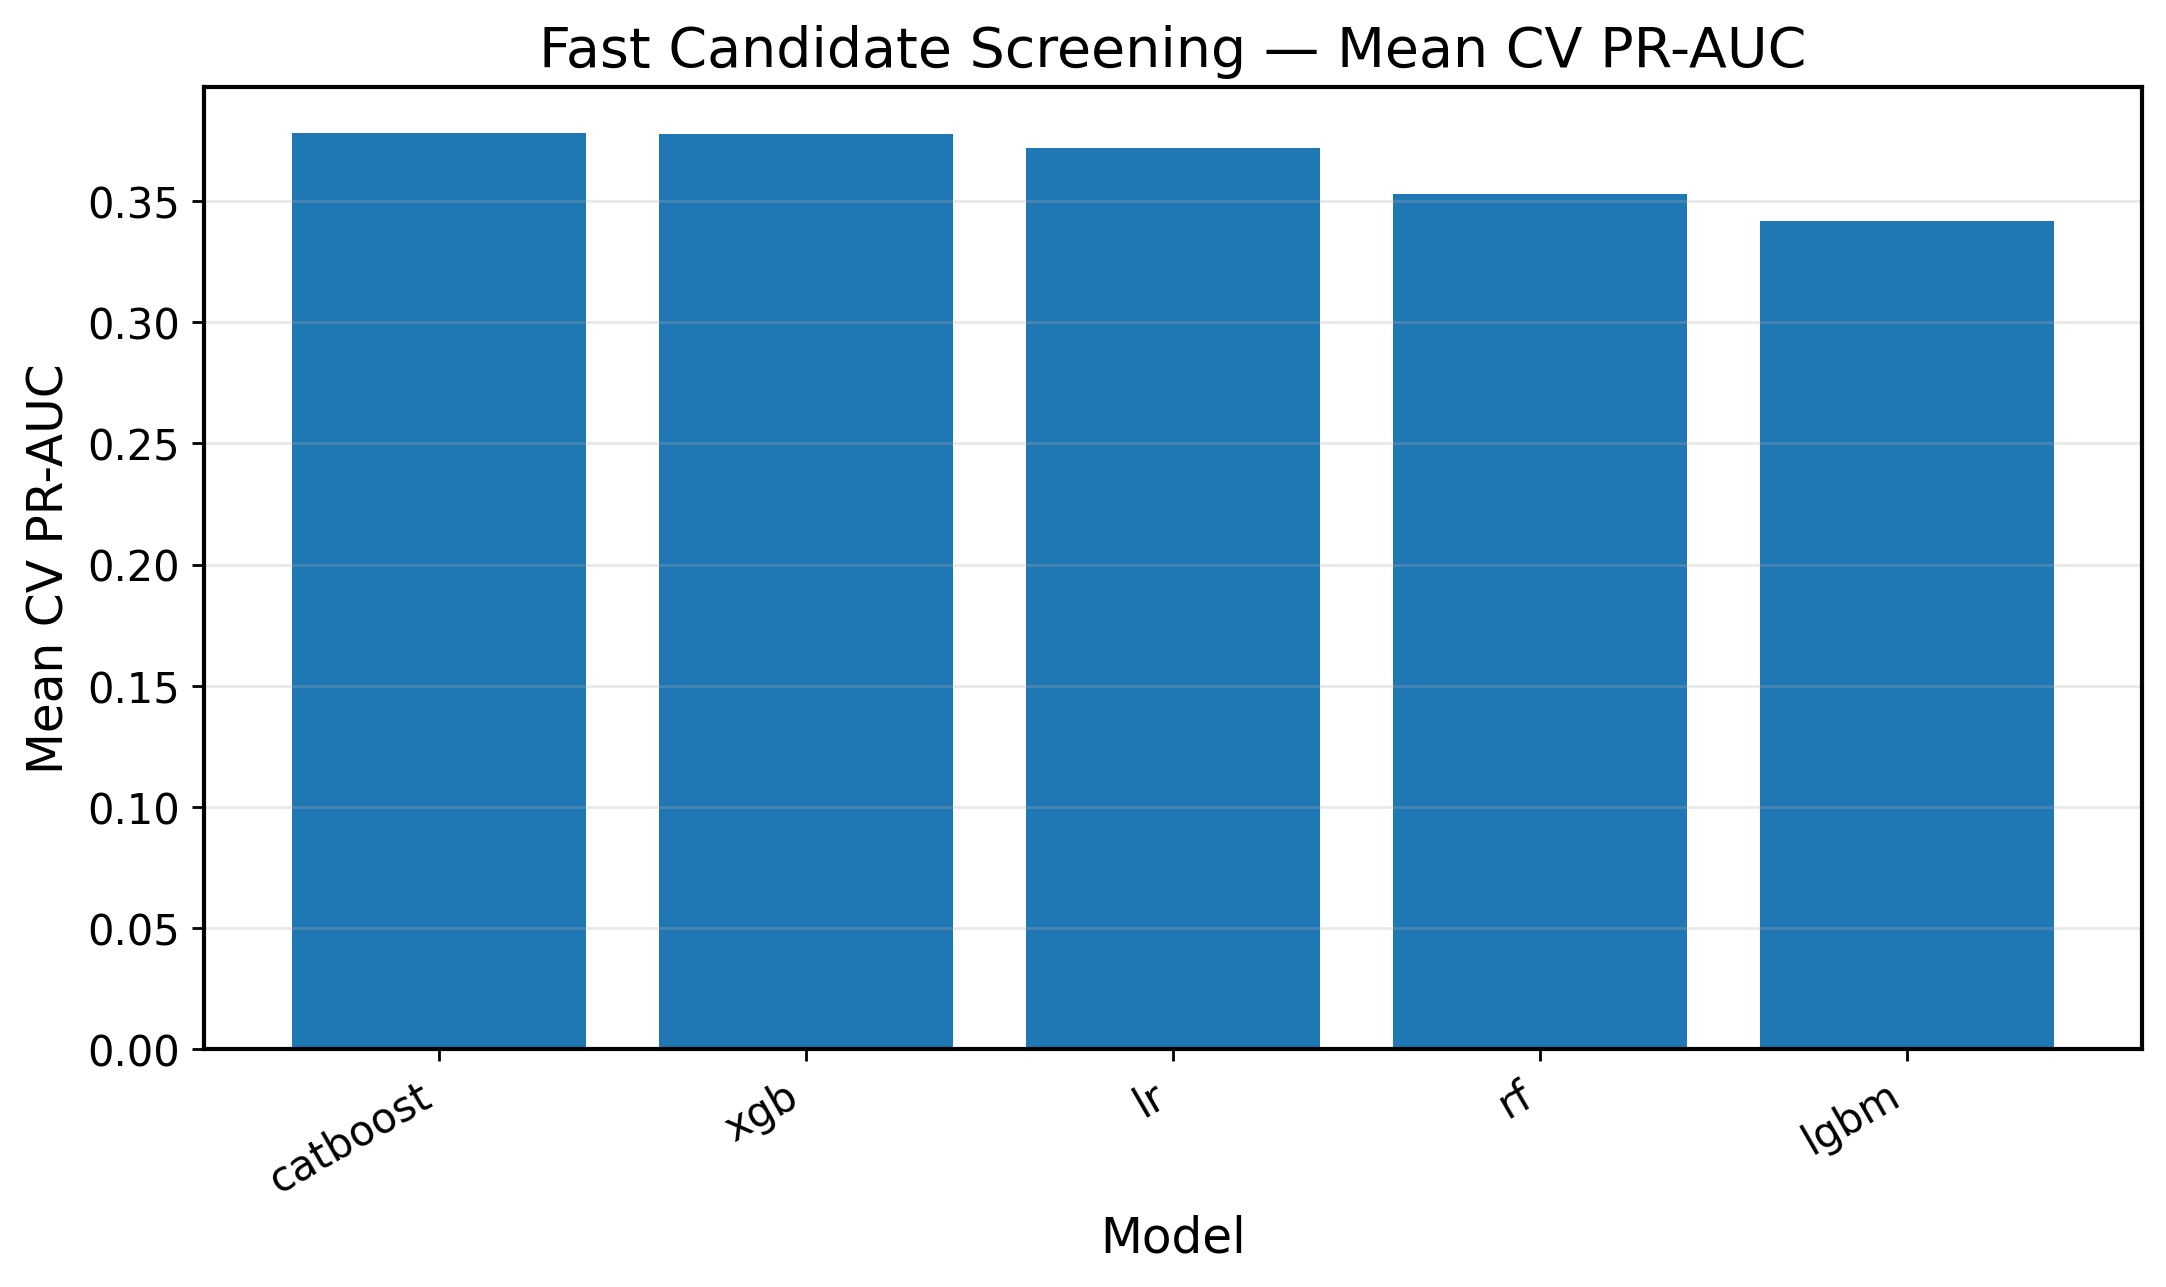

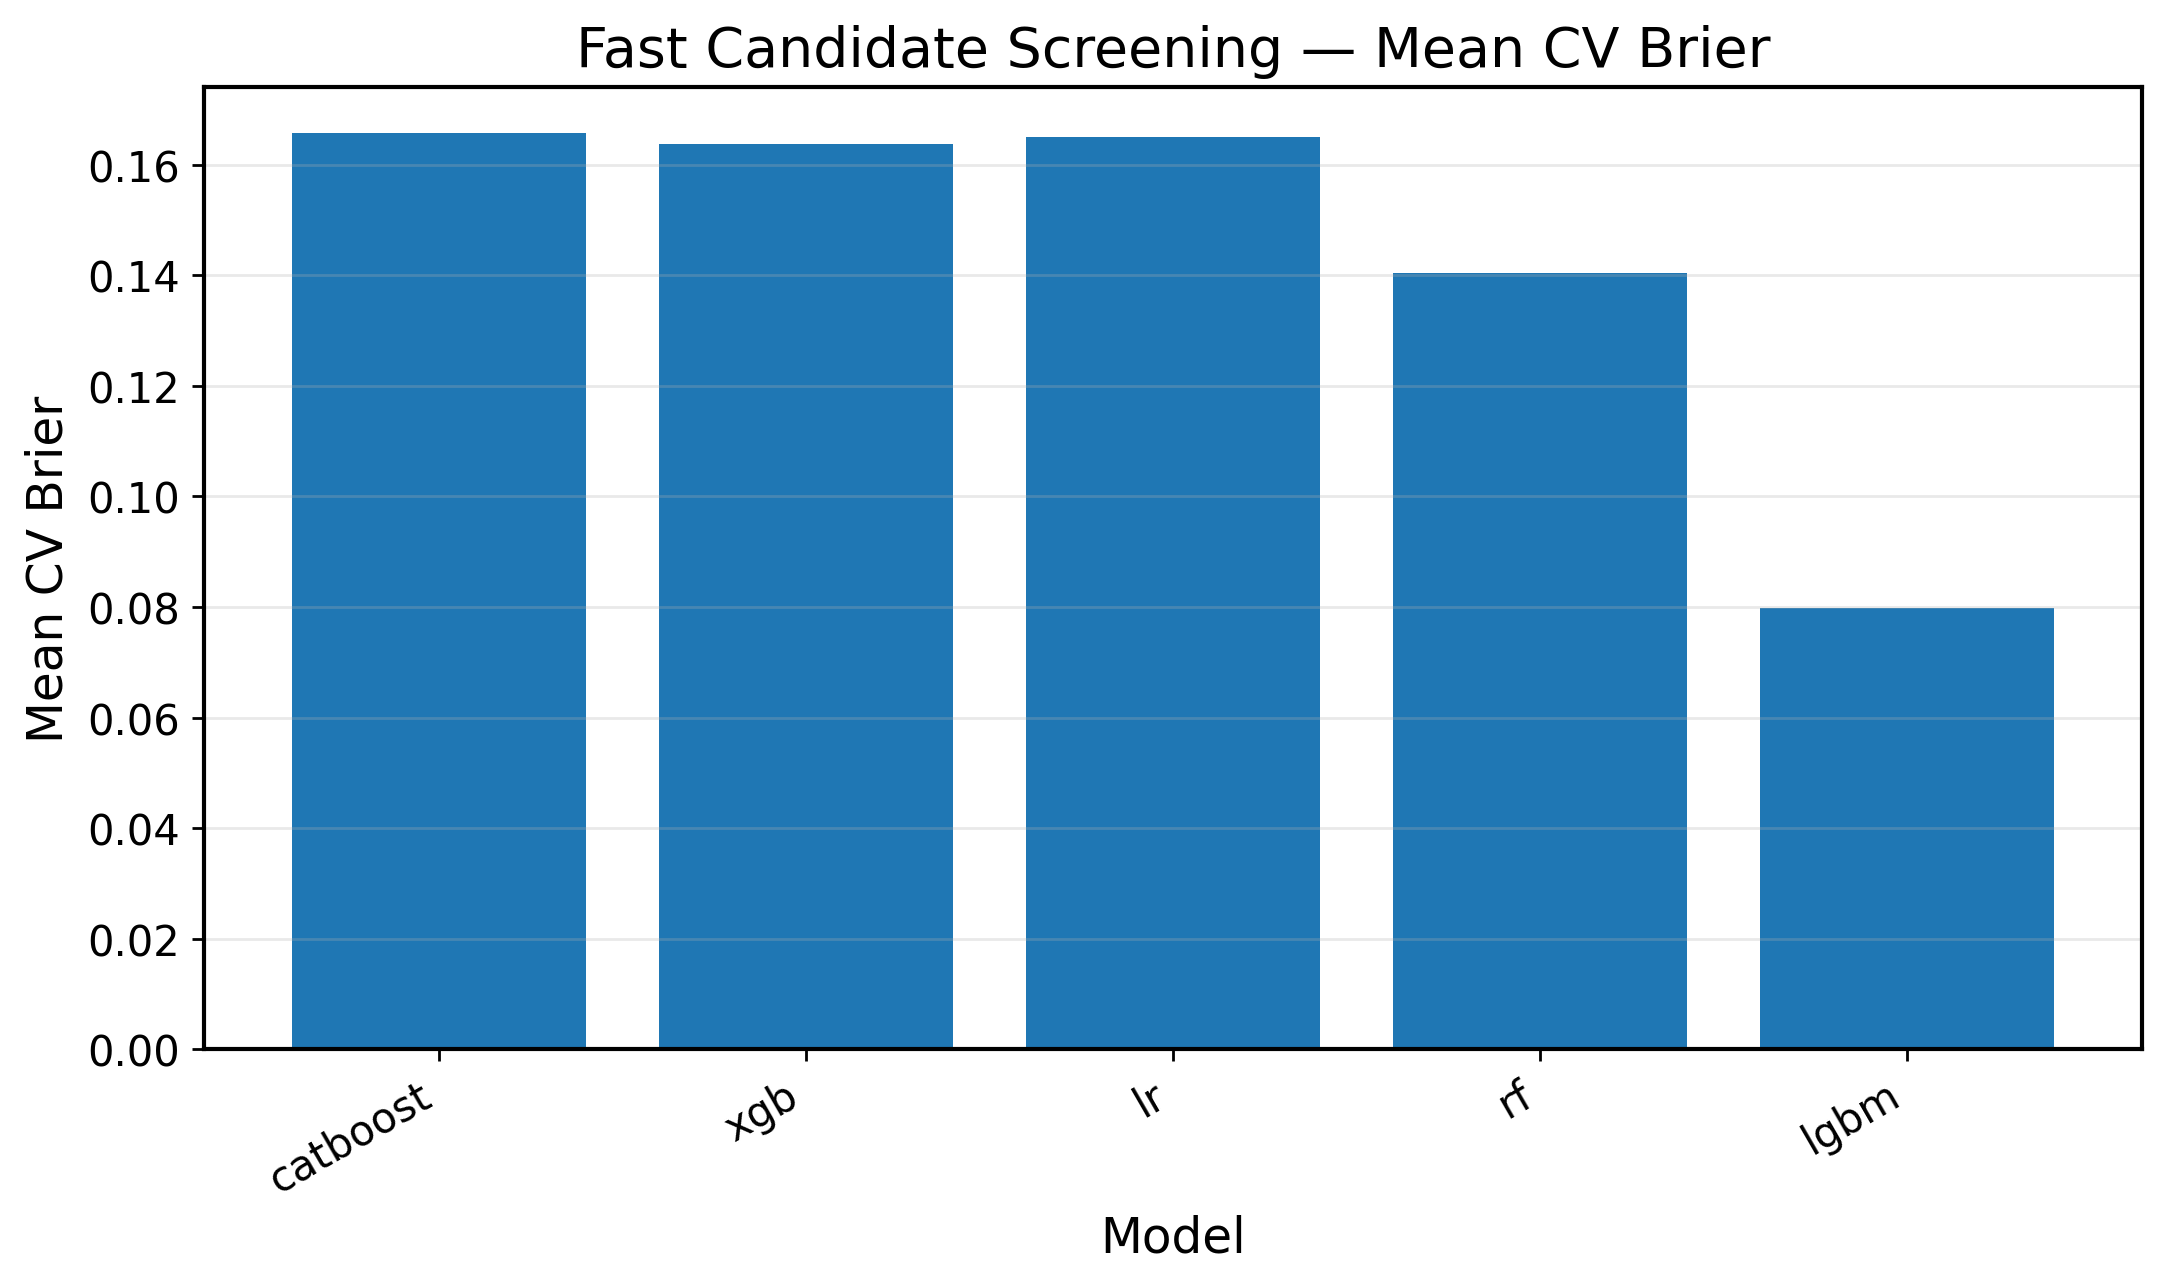

Module 6 complete — Repeated-CV candidate screening engine
Screening registry:
  - lr           | LogisticRegression        | family=linear     | preproc=linear
  - rf           | RandomForest              | family=tree       | preproc=tree
  - lgbm         | LightGBM                  | family=tree       | preproc=tree
  - xgb          | XGBoost                   | family=tree       | preproc=tree
  - catboost     | CatBoost                  | family=tree       | preproc=tree

Candidate run log:
      model        wrapper_name  family   status  n_completed_folds  \
0        lr  LogisticRegression  linear  success                 15   
1        rf        RandomForest    tree  success                 15   
2      lgbm            LightGBM    tree  success                 15   
3       xgb             XGBoost    tree  success                 15   
4  catboost            CatBoost    tree  success                 15   

   n_expected_folds  elapsed_seconds error_message  
0                15

In [13]:
# ============================================================
# Module 6 — Repeated-CV Candidate Screening Engine (FAST MODE)
# TA-MoE for Cardiovascular Risk Prediction
# Requires: Module 0–5 already executed
# ============================================================

# ------------------------------------------------------------
# 6.1 Fast-screening configuration
# ------------------------------------------------------------
# Goal:
# - quickly compare candidate models
# - keep repeated CV structure
# - reduce epochs / estimators for screening
# - save fold-level metrics and prediction records
#
# Notes:
# - this is for candidate screening only
# - final expert training later can use stronger settings
# - held-out test is NOT touched here

FAST_SCREENING_CONFIG = {
    "enabled": True,
    "use_registry": "screening_ready_model_registry",   # from Module 5.8
    "cv_use_all_folds": True,
    "max_models": None,                                 # set e.g. 4 for ultra-fast debugging
    "save_fold_models": False,
    "save_prediction_records": True,
    "save_fold_metrics": True,
    "compute_threshold_metrics": False,                 # probability metrics only for speed
    "threshold_for_reporting": 0.5,
    "ece_bins": CONFIG.n_ece_bins,
    "verbose": 1,
    "fast_overrides": {
        "lr": {},
        "rf": {
            "n_estimators": 150,
            "max_depth": 12,
        },
        "lgbm": {
            "n_estimators": 200,
            "learning_rate": 0.05,
            "num_leaves": 31,
        },
        "xgb": {
            "n_estimators": 200,
            "learning_rate": 0.05,
            "max_depth": 5,
            "early_stopping_rounds": 30,
        },
        "catboost": {
            "iterations": 200,
            "learning_rate": 0.05,
            "depth": 5,
        },
        "mlp": {
            "hidden_layer_sizes": (128, 64),
            "max_iter": 40,   # low epoch-like budget
            "alpha": 1e-4,
        },
        "mlp_deep": {
            "hidden_layer_sizes": (128, 64),
            "max_iter": 45,
        },
    }
}

save_json(
    FAST_SCREENING_CONFIG,
    LOG_DIR / "module6_fast_screening_config.json"
)

# ------------------------------------------------------------
# 6.2 Validate required objects
# ------------------------------------------------------------
required_globals = [
    "CV_BUNDLE",
    "METRIC_BUNDLE",
    "PREPROCESSING_BUNDLE",
    "DATA_BUNDLE",
    "MODEL_WRAPPER_BUNDLE",
]
for g in required_globals:
    if g not in globals():
        raise KeyError(f"Required object '{g}' not found. Please run previous modules first.")

if "SCREENING_READY_MODEL_REGISTRY" not in globals():
    raise KeyError("SCREENING_READY_MODEL_REGISTRY not found. Please run Module 5.8 first.")

X_dev = DATA_BUNDLE["X_dev"].copy()
y_dev = DATA_BUNDLE["y_dev"].copy()

CV_REGISTRY = CV_BUNDLE["cv_registry"]
iter_cv_folds = CV_BUNDLE["iter_cv_folds"]
evaluate_prediction_records = METRIC_BUNDLE["evaluate_prediction_records"]
summarize_metric_table = METRIC_BUNDLE["summarize_metric_table"]
format_mean_std_table = METRIC_BUNDLE["format_mean_std_table"]

print("=" * 70)
print("Module 6 — Candidate screening engine (FAST MODE)")
print("=" * 70)
print(f"Development set shape : {X_dev.shape}")
print(f"CV folds              : {len(CV_REGISTRY)}")
print(f"Fast mode enabled     : {FAST_SCREENING_CONFIG['enabled']}")

# ------------------------------------------------------------
# 6.3 Helper: choose screening registry
# ------------------------------------------------------------
def get_screening_registry(config: Dict[str, Any]) -> Dict[str, BaseModelWrapper]:
    registry_name = config["use_registry"]

    if registry_name == "screening_ready_model_registry":
        registry = SCREENING_READY_MODEL_REGISTRY
    elif registry_name == "unified_model_registry":
        registry = UNIFIED_MODEL_REGISTRY
    else:
        raise ValueError(f"Unsupported registry name: {registry_name}")

    if config["max_models"] is not None:
        keys = list(registry.keys())[: int(config["max_models"])]
        registry = {k: registry[k] for k in keys}

    return registry

SCREENING_REGISTRY = get_screening_registry(FAST_SCREENING_CONFIG)

# ------------------------------------------------------------
# 6.4 Helper: clone wrapper with fast overrides
# ------------------------------------------------------------
def make_fast_wrapper(
    registry_key: str,
    wrapper: BaseModelWrapper,
    fast_overrides: Dict[str, Dict[str, Any]],
) -> BaseModelWrapper:
    w = wrapper.clone()
    override = deepcopy(fast_overrides.get(registry_key, {}))
    if len(override) > 0:
        params = deepcopy(w.get_params())
        params.update(override)
        w.params = params
    return w

# ------------------------------------------------------------
# 6.5 Helper: prepare fold data for one wrapper
# ------------------------------------------------------------
def prepare_fold_data_for_wrapper(
    wrapper: BaseModelWrapper,
    fold_bundle,
):
    """
    Uses the wrapper's required preprocessor family.
    Fits preprocessor on fit-train only.
    Transforms fit-train, outer-valid, and optional inner-valid.
    """
    preproc_family = wrapper.requires_preprocessor_family()
    preproc_factory = PREPROCESSING_BUNDLE["preprocessor_factory"][preproc_family]

    preproc = preproc_factory()

    # fit preprocessor on fit-train only
    preproc_fitted, X_fit_train_t, X_outer_valid_t = fit_transform_preprocessor(
        preproc,
        fold_bundle.X_fit_train,
        fold_bundle.X_outer_valid,
    )

    X_es_valid_t = None
    if fold_bundle.X_es_valid is not None:
        X_es_valid_arr = preproc_fitted.transform(fold_bundle.X_es_valid)
        feat_names = PREPROCESSING_BUNDLE["get_transformed_feature_names"](preproc_fitted)
        if feat_names is not None:
            X_es_valid_t = pd.DataFrame(
                X_es_valid_arr,
                columns=feat_names,
                index=fold_bundle.X_es_valid.index,
            )
        else:
            X_es_valid_t = pd.DataFrame(
                X_es_valid_arr,
                index=fold_bundle.X_es_valid.index,
            )

    return {
        "preprocessor_family": preproc_family,
        "preprocessor_fitted": preproc_fitted,
        "X_fit_train_t": X_fit_train_t,
        "y_fit_train": fold_bundle.y_fit_train.copy(),
        "X_outer_valid_t": X_outer_valid_t,
        "y_outer_valid": fold_bundle.y_outer_valid.copy(),
        "X_es_valid_t": X_es_valid_t,
        "y_es_valid": fold_bundle.y_es_valid.copy() if fold_bundle.y_es_valid is not None else None,
    }

# ------------------------------------------------------------
# 6.6 Helper: train and predict one model on one fold
# ------------------------------------------------------------
def run_single_model_single_fold(
    registry_key: str,
    wrapper: BaseModelWrapper,
    fold_bundle,
    config: Dict[str, Any],
) -> Tuple[Dict[str, Any], pd.DataFrame]:
    """
    Returns:
    - fold metrics row
    - prediction records dataframe for outer-valid samples
    """
    fold_data = prepare_fold_data_for_wrapper(wrapper, fold_bundle)

    X_fit_train_t = fold_data["X_fit_train_t"]
    y_fit_train = fold_data["y_fit_train"]
    X_outer_valid_t = fold_data["X_outer_valid_t"]
    y_outer_valid = fold_data["y_outer_valid"]
    X_es_valid_t = fold_data["X_es_valid_t"]
    y_es_valid = fold_data["y_es_valid"]

    # train
    if wrapper.supports_validation_input() and X_es_valid_t is not None and y_es_valid is not None:
        wrapper.fit(
            X_fit_train_t,
            y_fit_train,
            X_valid=X_es_valid_t,
            y_valid=y_es_valid,
        )
        fit_mode = "fit_with_inner_validation"
    else:
        wrapper.fit(X_fit_train_t, y_fit_train)
        fit_mode = "fit_without_inner_validation"

    # predict on untouched outer-valid
    y_prob = wrapper.predict_proba(X_outer_valid_t)

    prob_metrics = METRIC_BUNDLE["compute_prob_metrics"](
        y_true=y_outer_valid.values,
        y_prob=y_prob,
        n_ece_bins=config["ece_bins"],
    )

    fold_row = {
        "model": registry_key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "preprocessor_family": wrapper.requires_preprocessor_family(),
        "global_fold_id": fold_bundle.global_fold_id,
        "repeat_id": fold_bundle.repeat_id,
        "fold_id": fold_bundle.fold_id,
        "outer_valid_n": int(len(y_outer_valid)),
        "outer_valid_pos_rate": float(y_outer_valid.mean()),
        "fit_mode": fit_mode,
        "fit_train_n": int(len(y_fit_train)),
        "es_valid_n": int(len(y_es_valid)) if y_es_valid is not None else 0,
        **prob_metrics,
    }

    if config["compute_threshold_metrics"]:
        thr_metrics = METRIC_BUNDLE["compute_threshold_metrics"](
            y_true=y_outer_valid.values,
            y_prob=y_prob,
            threshold=config["threshold_for_reporting"],
        )
        fold_row.update(thr_metrics)

    pred_records_df = pd.DataFrame({
        "model": registry_key,
        "wrapper_name": wrapper.get_name(),
        "family": wrapper.get_family(),
        "preprocessor_family": wrapper.requires_preprocessor_family(),
        "stage": "outer_valid",
        "global_fold_id": fold_bundle.global_fold_id,
        "repeat_id": fold_bundle.repeat_id,
        "fold_id": fold_bundle.fold_id,
        "sample_idx": fold_bundle.outer_valid_idx.astype(int),
        "y_true": y_outer_valid.values.astype(int),
        "y_prob": y_prob.astype(float),
    })

    return fold_row, pred_records_df

# ------------------------------------------------------------
# 6.7 Main screening runner
# ------------------------------------------------------------
def run_candidate_screening_cv(
    registry: Dict[str, BaseModelWrapper],
    X_dev: pd.DataFrame,
    y_dev: pd.Series,
    cv_registry,
    config: Dict[str, Any],
):
    fold_metric_rows = []
    pred_record_frames = []
    model_run_log_rows = []

    for model_idx, (registry_key, base_wrapper) in enumerate(registry.items(), start=1):
        if config["verbose"]:
            print(f"\n--- Running candidate model {model_idx}/{len(registry)}: {registry_key} ---")

        model_start_time = time.time()
        model_status = "success"
        model_error = None
        n_completed_folds = 0

        for fold_bundle in iter_cv_folds(X_dev, y_dev, cv_registry):
            try:
                fast_wrapper = make_fast_wrapper(
                    registry_key=registry_key,
                    wrapper=base_wrapper,
                    fast_overrides=config["fast_overrides"],
                )

                fold_row, pred_df = run_single_model_single_fold(
                    registry_key=registry_key,
                    wrapper=fast_wrapper,
                    fold_bundle=fold_bundle,
                    config=config,
                )

                fold_metric_rows.append(fold_row)
                if config["save_prediction_records"]:
                    pred_record_frames.append(pred_df)

                n_completed_folds += 1

            except Exception as e:
                model_status = "failed"
                model_error = str(e)

                # record fold-level failure row
                fold_metric_rows.append({
                    "model": registry_key,
                    "wrapper_name": base_wrapper.get_name(),
                    "family": base_wrapper.get_family(),
                    "preprocessor_family": base_wrapper.requires_preprocessor_family(),
                    "global_fold_id": fold_bundle.global_fold_id,
                    "repeat_id": fold_bundle.repeat_id,
                    "fold_id": fold_bundle.fold_id,
                    "status": "failed",
                    "error_message": str(e),
                })

                if config["verbose"]:
                    print(f"   Fold {fold_bundle.global_fold_id} failed: {e}")

                # stop this model and continue to next model
                break

        elapsed = time.time() - model_start_time
        model_run_log_rows.append({
            "model": registry_key,
            "wrapper_name": base_wrapper.get_name(),
            "family": base_wrapper.get_family(),
            "status": model_status,
            "n_completed_folds": int(n_completed_folds),
            "n_expected_folds": int(len(cv_registry)),
            "elapsed_seconds": float(elapsed),
            "error_message": model_error,
        })

        if config["verbose"]:
            print(
                f"   -> status={model_status}, "
                f"completed_folds={n_completed_folds}/{len(cv_registry)}, "
                f"time={elapsed:.2f}s"
            )

    fold_metrics_df = pd.DataFrame(fold_metric_rows)

    if len(pred_record_frames) > 0:
        pred_records_df = pd.concat(pred_record_frames, axis=0, ignore_index=True)
    else:
        pred_records_df = pd.DataFrame()

    model_run_log_df = pd.DataFrame(model_run_log_rows)

    return fold_metrics_df, pred_records_df, model_run_log_df

# ------------------------------------------------------------
# 6.8 Run screening
# ------------------------------------------------------------
CANDIDATE_FOLD_METRICS_DF, CANDIDATE_PRED_RECORDS_DF, CANDIDATE_RUN_LOG_DF = run_candidate_screening_cv(
    registry=SCREENING_REGISTRY,
    X_dev=X_dev,
    y_dev=y_dev,
    cv_registry=CV_REGISTRY,
    config=FAST_SCREENING_CONFIG,
)

# ------------------------------------------------------------
# 6.9 Keep only successful fold rows for metric summaries
# ------------------------------------------------------------
def filter_successful_fold_metrics(df: pd.DataFrame) -> pd.DataFrame:
    if "status" not in df.columns:
        return df.copy()
    return df[df["status"] != "failed"].copy()

CANDIDATE_FOLD_METRICS_OK_DF = filter_successful_fold_metrics(CANDIDATE_FOLD_METRICS_DF)

# ------------------------------------------------------------
# 6.10 Aggregate fold metrics by model
# ------------------------------------------------------------
metric_cols_for_summary = ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE"]

if FAST_SCREENING_CONFIG["compute_threshold_metrics"]:
    metric_cols_for_summary += [
        "accuracy", "balanced_accuracy", "precision",
        "recall", "specificity", "f1", "mcc"
    ]

CANDIDATE_CV_SUMMARY_DF = summarize_metric_table(
    df=CANDIDATE_FOLD_METRICS_OK_DF,
    group_cols=["model", "wrapper_name", "family", "preprocessor_family"],
    metric_cols=metric_cols_for_summary,
    decimals=6,
)

CANDIDATE_CV_FORMATTED_DF = format_mean_std_table(
    df_summary=CANDIDATE_CV_SUMMARY_DF,
    metric_names=metric_cols_for_summary,
    decimals=4,
)

# ------------------------------------------------------------
# 6.11 Aggregate long-format prediction records
# ------------------------------------------------------------
if len(CANDIDATE_PRED_RECORDS_DF) > 0:
    CANDIDATE_RECORD_METRICS_DF = evaluate_prediction_records(
        pred_df=CANDIDATE_PRED_RECORDS_DF,
        group_cols=["model", "wrapper_name", "family", "preprocessor_family", "repeat_id", "fold_id", "global_fold_id"],
        threshold=FAST_SCREENING_CONFIG["threshold_for_reporting"],
        n_ece_bins=FAST_SCREENING_CONFIG["ece_bins"],
    )
else:
    CANDIDATE_RECORD_METRICS_DF = pd.DataFrame()

# ------------------------------------------------------------
# 6.12 Ranking table
# ------------------------------------------------------------
def make_candidate_ranking_table(summary_df: pd.DataFrame) -> pd.DataFrame:
    df = summary_df.copy()

    # higher is better: PR_AUC, ROC_AUC
    # lower is better: Brier, NLL, ECE
    sort_cols = []
    ascending = []

    if "PR_AUC_mean" in df.columns:
        sort_cols.append("PR_AUC_mean")
        ascending.append(False)
    if "Brier_mean" in df.columns:
        sort_cols.append("Brier_mean")
        ascending.append(True)
    if "ECE_mean" in df.columns:
        sort_cols.append("ECE_mean")
        ascending.append(True)
    if "ROC_AUC_mean" in df.columns:
        sort_cols.append("ROC_AUC_mean")
        ascending.append(False)

    if len(sort_cols) > 0:
        df = df.sort_values(sort_cols, ascending=ascending).reset_index(drop=True)

    df.insert(0, "rank", np.arange(1, len(df) + 1))
    return df

CANDIDATE_RANKING_DF = make_candidate_ranking_table(CANDIDATE_CV_SUMMARY_DF)

# ------------------------------------------------------------
# 6.13 Save outputs
# ------------------------------------------------------------
CANDIDATE_FOLD_METRICS_DF.to_csv(
    ARTIFACT_PATHS["candidate_cv_results"],
    index=False,
)

CANDIDATE_CV_FORMATTED_DF.to_csv(
    ARTIFACT_PATHS["candidate_cv_summary"],
    index=False,
)

CANDIDATE_CV_SUMMARY_DF.to_csv(
    TAB_DIR / "cv_candidate_summary_numeric.csv",
    index=False,
)

CANDIDATE_RANKING_DF.to_csv(
    TAB_DIR / "cv_candidate_ranking.csv",
    index=False,
)

CANDIDATE_RUN_LOG_DF.to_csv(
    LOG_DIR / "module6_candidate_run_log.csv",
    index=False,
)

if len(CANDIDATE_PRED_RECORDS_DF) > 0:
    CANDIDATE_PRED_RECORDS_DF.to_csv(
        PRED_DIR / "candidate_screening_prediction_records.csv",
        index=False,
    )

if len(CANDIDATE_RECORD_METRICS_DF) > 0:
    CANDIDATE_RECORD_METRICS_DF.to_csv(
        TAB_DIR / "candidate_screening_record_metrics.csv",
        index=False,
    )

# ------------------------------------------------------------
# 6.14 Quick screening plots
# ------------------------------------------------------------
# Plot 1: PR-AUC mean by model
if len(CANDIDATE_CV_SUMMARY_DF) > 0 and "PR_AUC_mean" in CANDIDATE_CV_SUMMARY_DF.columns:
    plot_df = CANDIDATE_RANKING_DF.copy()

    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["model"], plot_df["PR_AUC_mean"])
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Mean CV PR-AUC")
    plt.xlabel("Model")
    plt.title("Fast Candidate Screening — Mean CV PR-AUC")
    plt.grid(axis="y")
    save_figure_multi(FIG_DIR / "module6_candidate_screening_pr_auc")
    plt.show()

# Plot 2: Reliability view with Brier
if len(CANDIDATE_CV_SUMMARY_DF) > 0 and "Brier_mean" in CANDIDATE_CV_SUMMARY_DF.columns:
    plot_df = CANDIDATE_RANKING_DF.copy()

    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["model"], plot_df["Brier_mean"])
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("Mean CV Brier")
    plt.xlabel("Model")
    plt.title("Fast Candidate Screening — Mean CV Brier")
    plt.grid(axis="y")
    save_figure_multi(FIG_DIR / "module6_candidate_screening_brier")
    plt.show()

# ------------------------------------------------------------
# 6.15 Recommend initial expert pool
# ------------------------------------------------------------
def recommend_initial_expert_pool(
    ranking_df: pd.DataFrame,
    min_models: int = 3,
    preferred_keys: Optional[List[str]] = None,
) -> List[str]:
    """
    Simple first-pass recommendation.
    Strategy:
    - take best ranked models
    - preserve diversity if possible
    """
    if len(ranking_df) == 0:
        return []

    df = ranking_df.copy()
    selected = []

    # preferred shortlist first if available and present
    if preferred_keys is None:
        preferred_keys = ["lgbm", "xgb", "catboost", "mlp", "rf", "lr"]

    for key in preferred_keys:
        if key in df["model"].tolist() and key not in selected:
            selected.append(key)
        if len(selected) >= min_models:
            break

    # fallback to ranking order
    if len(selected) < min_models:
        for key in df["model"].tolist():
            if key not in selected:
                selected.append(key)
            if len(selected) >= min_models:
                break

    return selected[:min_models]

INITIAL_EXPERT_POOL = recommend_initial_expert_pool(
    ranking_df=CANDIDATE_RANKING_DF,
    min_models=3,
)

save_json(
    {"initial_expert_pool": INITIAL_EXPERT_POOL},
    ART_DIR / "initial_expert_pool.json"
)

# ------------------------------------------------------------
# 6.16 Export bundle for next modules
# ------------------------------------------------------------
CANDIDATE_SCREENING_BUNDLE = {
    "config": FAST_SCREENING_CONFIG,
    "screening_registry": SCREENING_REGISTRY,
    "candidate_fold_metrics_df": CANDIDATE_FOLD_METRICS_DF,
    "candidate_fold_metrics_ok_df": CANDIDATE_FOLD_METRICS_OK_DF,
    "candidate_pred_records_df": CANDIDATE_PRED_RECORDS_DF,
    "candidate_record_metrics_df": CANDIDATE_RECORD_METRICS_DF,
    "candidate_cv_summary_df": CANDIDATE_CV_SUMMARY_DF,
    "candidate_cv_formatted_df": CANDIDATE_CV_FORMATTED_DF,
    "candidate_ranking_df": CANDIDATE_RANKING_DF,
    "candidate_run_log_df": CANDIDATE_RUN_LOG_DF,
    "initial_expert_pool": INITIAL_EXPERT_POOL,
}

# ------------------------------------------------------------
# 6.17 Final console summary
# ------------------------------------------------------------
print("=" * 70)
print("Module 6 complete — Repeated-CV candidate screening engine")
print("=" * 70)

print("Screening registry:")
for k, w in SCREENING_REGISTRY.items():
    print(f"  - {k:<12} | {w.get_name():<25} | family={w.get_family():<10} | preproc={w.requires_preprocessor_family()}")

print("\nCandidate run log:")
print(CANDIDATE_RUN_LOG_DF)

print("\nCandidate ranking:")
print(CANDIDATE_RANKING_DF[[
    c for c in ["rank", "model", "family", "PR_AUC_mean", "ROC_AUC_mean", "Brier_mean", "ECE_mean"]
    if c in CANDIDATE_RANKING_DF.columns
]])

print("\nInitial expert pool recommendation:")
print(INITIAL_EXPERT_POOL)

print("\nCANDIDATE_SCREENING_BUNDLE keys:")
print(list(CANDIDATE_SCREENING_BUNDLE.keys()))
print("=" * 70)

## New Final

Module 0 complete.
Project        : TA-MoE Cardiovascular Risk Prediction
Target         : HeartDiseaseorAttack
Primary metric : PR_AUC
Data path      : /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Output dir     : /kaggle/working/outputs
Loaded dataset.
Raw shape: (253680, 23)

===== Feature Schema =====
Binary        : 13
Ordinal       : 4
Count         : 2
Continuous    : 1
Multiclass    : 1
Other         : 0

===== Dataset Summary =====
N samples            : 253,680
N features           : 21
Dropped target-miss  : 0
Positive count       : 23,893
Negative count       : 229,787
Positive rate        : 0.094186
Negative rate        : 0.905814

===== Development / Hold-out Test Split =====
          split       n  positive_n  negative_n  positive_rate  negative_rate
0   development  202944       19114      183830       0.094184       0.905816
1  holdout_test   50736        4779       45957       0.094193       0

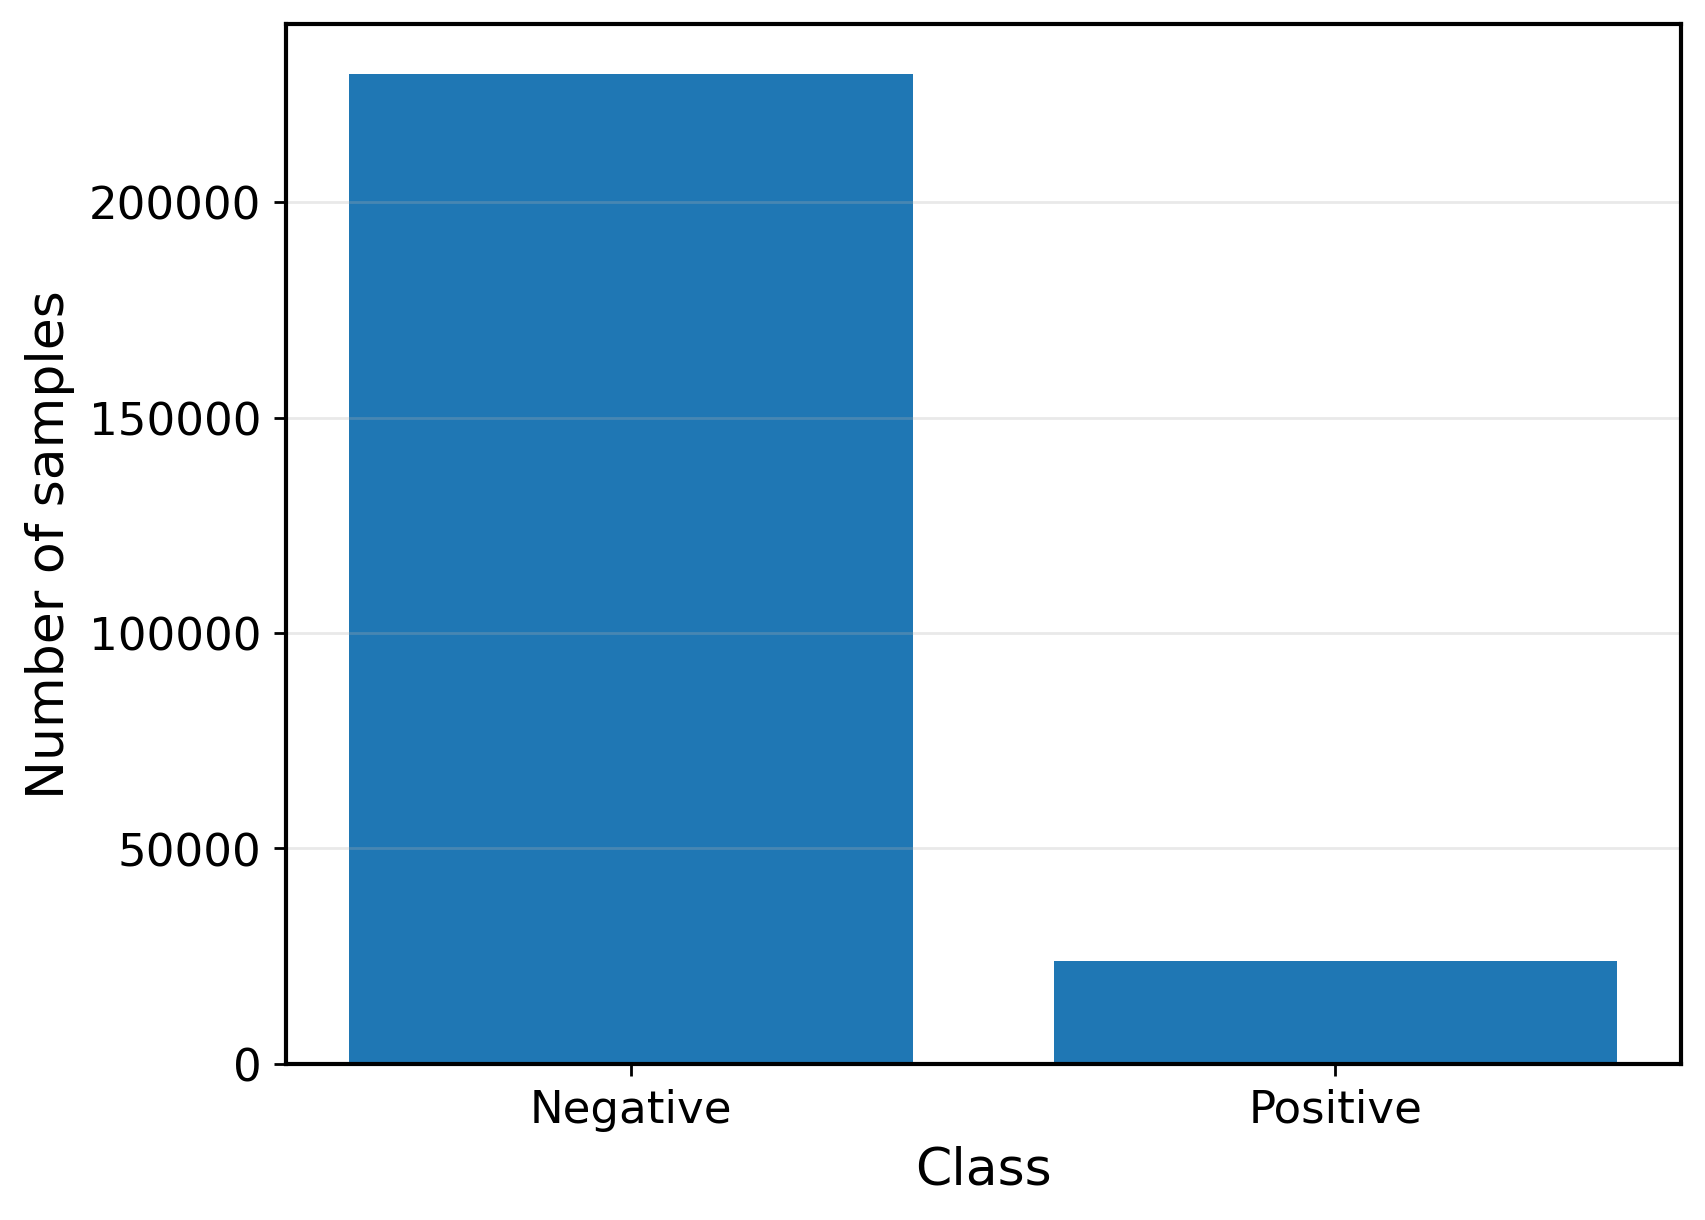

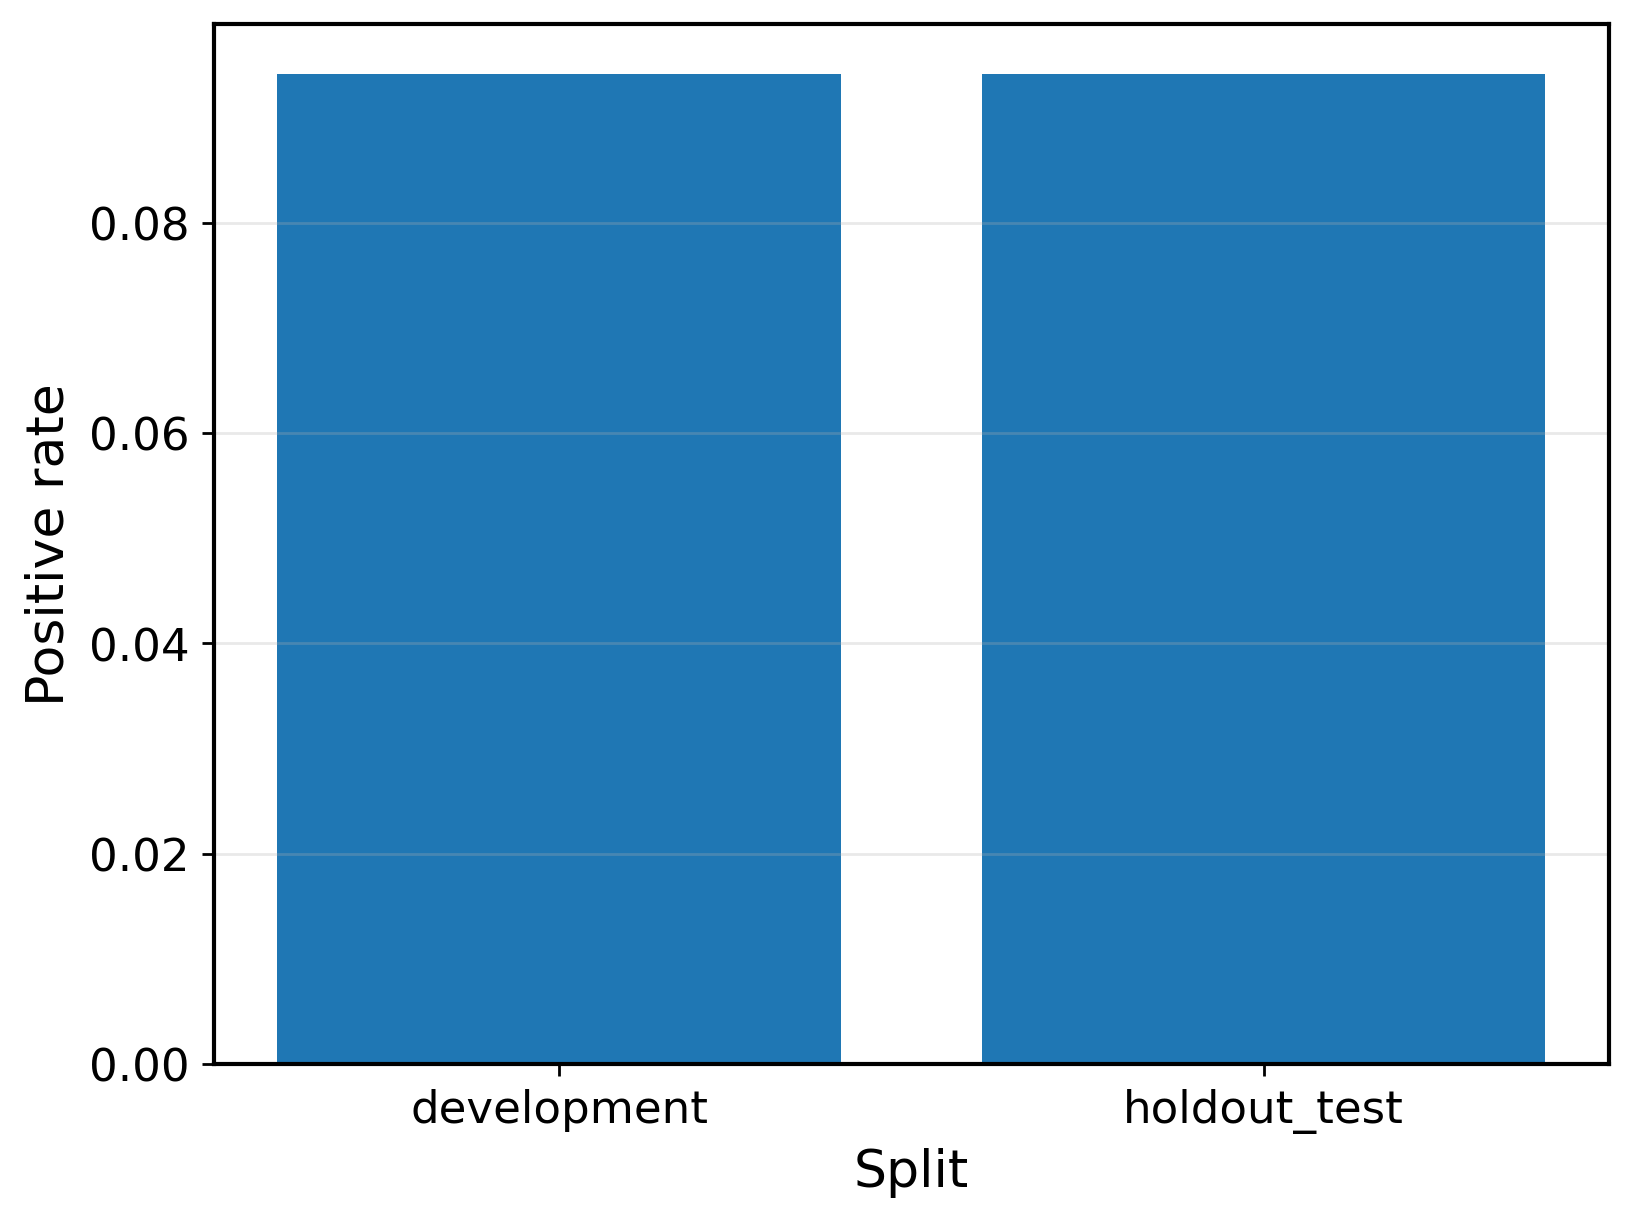

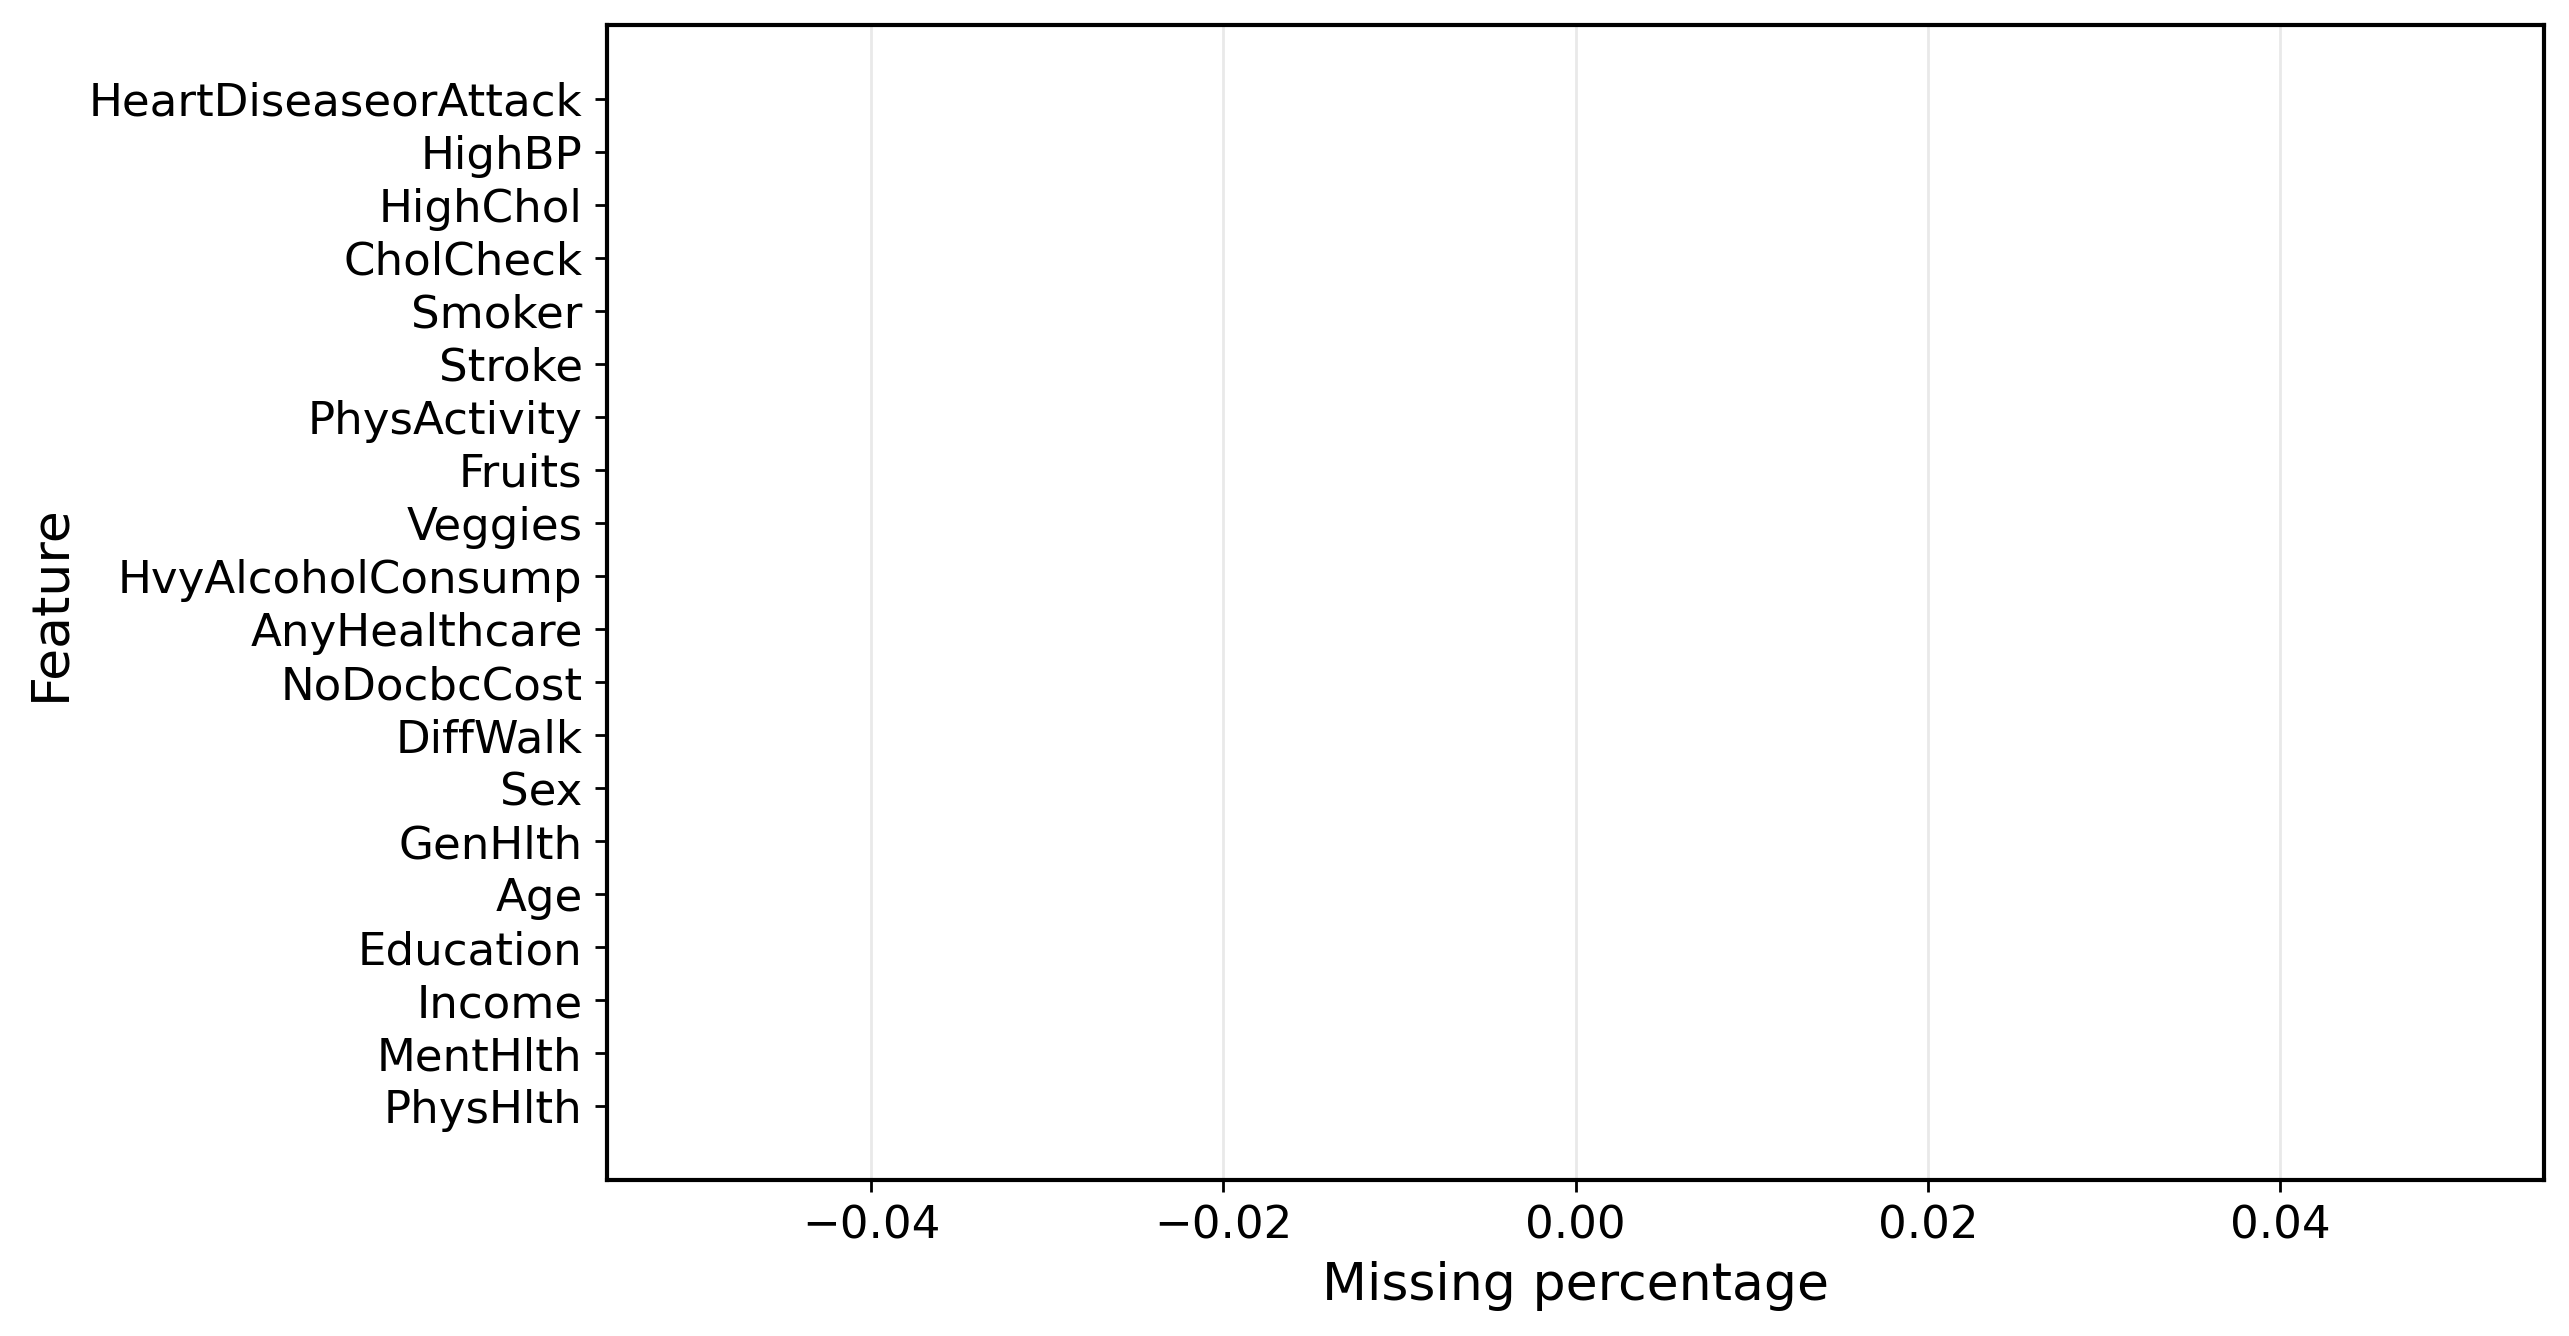


Module 1 complete.
Saved dataset audit, feature schema, split summaries, and exact repeated-CV indices.


In [1]:
# ============================================================
# TA-MoE for Cardiovascular Risk Prediction
# Locked Research Pipeline — Module 0
#
# Module 0 — Setup, configuration, reproducibility, paths
# ============================================================

import os
import gc
import json
import time
import math
import random
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Global configuration
# ------------------------------------------------------------
SEED = 42
PROJECT_NAME = "TA-MoE Cardiovascular Risk Prediction"
TARGET = "HeartDiseaseorAttack"

# final data split
TEST_SIZE = 0.20
DEV_SIZE = 1.0 - TEST_SIZE

# repeated stratified CV on development set
N_SPLITS = 5
N_REPEATS = 2

# primary paper metric
PRIMARY_METRIC = "PR_AUC"

# plotting / artifacts
PLOT_DPI = 400
SAVE_FIG_FORMATS = ["png", "pdf"]

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        if hasattr(torch.backends, "cudnn"):
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except Exception:
        pass

seed_everything(SEED)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs"

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
PRED_DIR = OUT_DIR / "preds"
MOD_DIR = OUT_DIR / "models"
LOG_DIR = OUT_DIR / "logs"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, PRED_DIR, MOD_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Matplotlib style
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 250,
    "savefig.dpi": PLOT_DPI,
    "figure.figsize": (8, 6),
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 10,
    "font.size": 12,
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.2,
    "grid.alpha": 0.28,
})

def save_figure_multi(base_path: Path):
    for ext in SAVE_FIG_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

# ------------------------------------------------------------
# Candidate data paths
# ------------------------------------------------------------
DATA_PATH_CANDIDATES = [
    "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/Heart_Disease_Health_Indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators.csv",
]

def find_data_path(candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

DATA_PATH = find_data_path(DATA_PATH_CANDIDATES)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset file not found. Please update DATA_PATH_CANDIDATES."
    )

# ------------------------------------------------------------
# Save environment metadata
# ------------------------------------------------------------
module0_meta = {
    "project_name": PROJECT_NAME,
    "seed": SEED,
    "target": TARGET,
    "test_size": TEST_SIZE,
    "dev_size": DEV_SIZE,
    "cv_n_splits": N_SPLITS,
    "cv_n_repeats": N_REPEATS,
    "primary_metric": PRIMARY_METRIC,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "data_path": DATA_PATH,
    "output_dir": str(OUT_DIR),
}

with open(LOG_DIR / "module0_environment.json", "w") as f:
    json.dump(module0_meta, f, indent=2)

print("Module 0 complete.")
print(f"Project        : {PROJECT_NAME}")
print(f"Target         : {TARGET}")
print(f"Primary metric : {PRIMARY_METRIC}")
print(f"Data path      : {DATA_PATH}")
print(f"Output dir     : {OUT_DIR}")

# ============================================================
# Locked Research Pipeline — Module 1
#
# Module 1 — Data Loading, Audit, Schema, and Dev/Test Split
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

# ------------------------------------------------------------
# Safety checks from Module 0
# ------------------------------------------------------------
required_vars = [
    "SEED", "PROJECT_NAME", "TARGET",
    "TEST_SIZE", "N_SPLITS", "N_REPEATS",
    "FIG_DIR", "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "SAVE_FIG_FORMATS", "DATA_PATH", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables from Module 0: {missing_vars}")

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH).copy()
df.columns = [c.strip() for c in df.columns]
df["orig_row_id"] = np.arange(len(df), dtype=np.int64)

print("Loaded dataset.")
print("Raw shape:", df.shape)

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}"
    )

# ------------------------------------------------------------
# Target cleanup
# ------------------------------------------------------------
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
before_drop = len(df)

df = df.dropna(subset=[TARGET]).reset_index(drop=True)

after_drop = len(df)
dropped_target_missing = before_drop - after_drop

df[TARGET] = df[TARGET].astype(int)

target_unique = sorted(df[TARGET].unique().tolist())
if not set(target_unique).issubset({0, 1}):
    raise ValueError(
        f"Target '{TARGET}' must be binary {{0,1}}, found values: {target_unique}"
    )

# ------------------------------------------------------------
# Explicit BRFSS schema
# ------------------------------------------------------------
ALL_FEATURES = [c for c in df.columns if c not in [TARGET, "orig_row_id"]]

BINARY_COLS = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

ORDINAL_COLS = ["GenHlth", "Age", "Education", "Income"]
COUNT_COLS = ["MentHlth", "PhysHlth"]
CONT_COLS = ["BMI"]
MULTICLASS_COLS = ["Diabetes"]

# retain only present columns
BINARY_COLS = [c for c in BINARY_COLS if c in ALL_FEATURES]
ORDINAL_COLS = [c for c in ORDINAL_COLS if c in ALL_FEATURES]
COUNT_COLS = [c for c in COUNT_COLS if c in ALL_FEATURES]
CONT_COLS = [c for c in CONT_COLS if c in ALL_FEATURES]
MULTICLASS_COLS = [c for c in MULTICLASS_COLS if c in ALL_FEATURES]

known_cols = set(BINARY_COLS + ORDINAL_COLS + COUNT_COLS + CONT_COLS + MULTICLASS_COLS)
OTHER_COLS = [c for c in ALL_FEATURES if c not in known_cols]

FEATURES = (
    BINARY_COLS +
    ORDINAL_COLS +
    COUNT_COLS +
    CONT_COLS +
    MULTICLASS_COLS +
    OTHER_COLS
)

print("\n===== Feature Schema =====")
print(f"Binary        : {len(BINARY_COLS)}")
print(f"Ordinal       : {len(ORDINAL_COLS)}")
print(f"Count         : {len(COUNT_COLS)}")
print(f"Continuous    : {len(CONT_COLS)}")
print(f"Multiclass    : {len(MULTICLASS_COLS)}")
print(f"Other         : {len(OTHER_COLS)}")
if OTHER_COLS:
    print("Other columns detected:", OTHER_COLS)

# ------------------------------------------------------------
# Schema bounds metadata
# ------------------------------------------------------------
ORDINAL_BOUNDS = {
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
}
COUNT_BOUNDS = {
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
}
MULTICLASS_BOUNDS = {
    "Diabetes": (0, 2),
}

ORDINAL_BOUNDS = {k: v for k, v in ORDINAL_BOUNDS.items() if k in ORDINAL_COLS}
COUNT_BOUNDS = {k: v for k, v in COUNT_BOUNDS.items() if k in COUNT_COLS}
MULTICLASS_BOUNDS = {k: v for k, v in MULTICLASS_BOUNDS.items() if k in MULTICLASS_COLS}

# ------------------------------------------------------------
# Working matrices
# ------------------------------------------------------------
X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values
row_id_all = df["orig_row_id"].values

# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------
N = len(df)
pos_n = int((y_all == 1).sum())
neg_n = int((y_all == 0).sum())
pos_rate = float(np.mean(y_all))
neg_rate = 1.0 - pos_rate

print("\n===== Dataset Summary =====")
print(f"N samples            : {N:,}")
print(f"N features           : {len(FEATURES)}")
print(f"Dropped target-miss  : {dropped_target_missing:,}")
print(f"Positive count       : {pos_n:,}")
print(f"Negative count       : {neg_n:,}")
print(f"Positive rate        : {pos_rate:.6f}")
print(f"Negative rate        : {neg_rate:.6f}")

# ------------------------------------------------------------
# Audit table
# ------------------------------------------------------------
audit_rows = []
for c in [TARGET] + FEATURES:
    s = df[c]
    s_num = pd.to_numeric(s, errors="coerce")
    audit_rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100.0),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(s_num.min()) if s_num.notna().any() else np.nan,
        "max": float(s_num.max()) if s_num.notna().any() else np.nan,
    })

audit_df = pd.DataFrame(audit_rows)

feature_group_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [
        "binary" if c in BINARY_COLS else
        "ordinal" if c in ORDINAL_COLS else
        "count" if c in COUNT_COLS else
        "continuous" if c in CONT_COLS else
        "multiclass" if c in MULTICLASS_COLS else
        "other"
        for c in FEATURES
    ]
})

dataset_summary_df = pd.DataFrame([{
    "project_name": PROJECT_NAME,
    "dataset_path": DATA_PATH,
    "target": TARGET,
    "n_samples": N,
    "n_features": len(FEATURES),
    "positive_n": pos_n,
    "negative_n": neg_n,
    "positive_rate": pos_rate,
    "negative_rate": neg_rate,
}])

audit_df.to_csv(TAB_DIR / "module1_feature_audit.csv", index=False)
feature_group_df.to_csv(TAB_DIR / "module1_feature_groups.csv", index=False)
dataset_summary_df.to_csv(TAB_DIR / "module1_dataset_summary.csv", index=False)

# ------------------------------------------------------------
# Stratified development / hold-out test split
# ------------------------------------------------------------
X_dev, X_test, y_dev, y_test, rowid_dev, rowid_test = train_test_split(
    X_all,
    y_all,
    row_id_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=SEED,
)

X_dev = X_dev.copy()
X_test = X_test.copy()

split_summary_df = pd.DataFrame([
    {
        "split": "development",
        "n": int(len(y_dev)),
        "positive_n": int((y_dev == 1).sum()),
        "negative_n": int((y_dev == 0).sum()),
        "positive_rate": float(np.mean(y_dev)),
        "negative_rate": float(1.0 - np.mean(y_dev)),
    },
    {
        "split": "holdout_test",
        "n": int(len(y_test)),
        "positive_n": int((y_test == 1).sum()),
        "negative_n": int((y_test == 0).sum()),
        "positive_rate": float(np.mean(y_test)),
        "negative_rate": float(1.0 - np.mean(y_test)),
    },
])

split_summary_df.to_csv(TAB_DIR / "module1_dev_test_split_summary.csv", index=False)

print("\n===== Development / Hold-out Test Split =====")
print(split_summary_df)

# ------------------------------------------------------------
# Save exact dev/test row IDs
# ------------------------------------------------------------
np.savez_compressed(
    PRED_DIR / "module1_dev_test_row_ids.npz",
    dev_row_ids=rowid_dev.astype(np.int64),
    test_row_ids=rowid_test.astype(np.int64),
)

# ------------------------------------------------------------
# Save repeated CV fold indices on development set
# ------------------------------------------------------------
rskf_dev = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEED
)

cv_rows = []
cv_index_dict = {}

for fold_id, (tr_idx, va_idx) in enumerate(rskf_dev.split(X_dev, y_dev), start=1):
    cv_rows.append({
        "repeat_fold_id": fold_id,
        "train_size": int(len(tr_idx)),
        "valid_size": int(len(va_idx)),
        "train_positive_rate": float(np.mean(y_dev[tr_idx])),
        "valid_positive_rate": float(np.mean(y_dev[va_idx])),
    })
    cv_index_dict[f"fold_{fold_id}_train_idx"] = tr_idx.astype(np.int32)
    cv_index_dict[f"fold_{fold_id}_valid_idx"] = va_idx.astype(np.int32)

cv_summary_df = pd.DataFrame(cv_rows)
cv_summary_df.to_csv(TAB_DIR / "module1_repeated_cv_summary.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module1_repeated_cv_indices.npz",
    **cv_index_dict
)

print("\n===== Repeated Stratified CV on Development Set =====")
print(cv_summary_df.head())

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
module1_meta = {
    "target": TARGET,
    "n_samples": int(N),
    "n_features": int(len(FEATURES)),
    "feature_schema_counts": {
        "binary": len(BINARY_COLS),
        "ordinal": len(ORDINAL_COLS),
        "count": len(COUNT_COLS),
        "continuous": len(CONT_COLS),
        "multiclass": len(MULTICLASS_COLS),
        "other": len(OTHER_COLS),
    },
    "ordinal_bounds": ORDINAL_BOUNDS,
    "count_bounds": COUNT_BOUNDS,
    "multiclass_bounds": MULTICLASS_BOUNDS,
    "test_size": TEST_SIZE,
    "cv_n_splits": N_SPLITS,
    "cv_n_repeats": N_REPEATS,
    "dropped_target_missing": int(dropped_target_missing),
}

with open(LOG_DIR / "module1_metadata.json", "w") as f:
    json.dump(module1_meta, f, indent=2)

# ------------------------------------------------------------
# Paper-ready figures
# ------------------------------------------------------------
plt.figure(figsize=(7.2, 5.4))
plt.bar(["Negative", "Positive"], [neg_n, pos_n])
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_full_class_distribution")
plt.show()

plt.figure(figsize=(7.2, 5.4))
plt.bar(split_summary_df["split"], split_summary_df["positive_rate"])
plt.xlabel("Split")
plt.ylabel("Positive rate")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_dev_test_positive_rate")
plt.show()

missing_plot_df = audit_df.sort_values("missing_pct", ascending=False).head(20)
plt.figure(figsize=(10, 6))
plt.barh(missing_plot_df["column"], missing_plot_df["missing_pct"])
plt.xlabel("Missing percentage")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module1_top_missingness")
plt.show()

print("\nModule 1 complete.")
print("Saved dataset audit, feature schema, split summaries, and exact repeated-CV indices.")

In [2]:
# ============================================================
# Locked Research Pipeline — Module 2
#
# Module 2 — Preprocessing Utilities
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "FEATURES", "BINARY_COLS", "ORDINAL_COLS", "COUNT_COLS",
    "CONT_COLS", "MULTICLASS_COLS",
    "ORDINAL_BOUNDS", "COUNT_BOUNDS", "MULTICLASS_BOUNDS",
    "X_dev", "X_test", "y_dev", "y_test",
    "TAB_DIR", "LOG_DIR"
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 2: {missing_vars}")

# ------------------------------------------------------------
# Basic numeric helper
# ------------------------------------------------------------
def safe_numeric_series(s: pd.Series, fill_value: float = 0.0) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)
    return s_num.fillna(fill_value)

# ------------------------------------------------------------
# Type-aware sanitizers
# ------------------------------------------------------------
def sanitize_binary_series(s: pd.Series) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=0.0)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, 0, 1)
    return pd.Series(s_num, index=s.index)

def sanitize_ordinal_series(
    s: pd.Series,
    min_value: int,
    max_value: int,
    fill_value: int
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=fill_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_count_series(
    s: pd.Series,
    min_value: int = 0,
    max_value: int = 30
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=min_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_multiclass_series(
    s: pd.Series,
    min_value: int,
    max_value: int,
    fill_value: int
) -> pd.Series:
    s_num = safe_numeric_series(s, fill_value=fill_value)
    s_num = np.round(s_num).astype(np.int64)
    s_num = np.clip(s_num, min_value, max_value)
    return pd.Series(s_num, index=s.index)

def sanitize_continuous_series(
    s: pd.Series,
    fill_strategy: str = "median",
    fill_value_override = None
) -> pd.Series:
    s_num = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)

    if fill_value_override is not None:
        fill_value = float(fill_value_override)
    else:
        if fill_strategy == "median":
            fill_value = float(s_num.median()) if s_num.notna().any() else 0.0
        elif fill_strategy == "mean":
            fill_value = float(s_num.mean()) if s_num.notna().any() else 0.0
        else:
            fill_value = 0.0

    s_num = s_num.fillna(fill_value).astype(np.float32)
    return pd.Series(s_num, index=s.index)

# ------------------------------------------------------------
# Dataframe sanitation
# ------------------------------------------------------------
def sanitize_dataframe(
    X_df: pd.DataFrame,
    continuous_fill_map: dict = None
) -> pd.DataFrame:
    X_df = X_df.copy()

    for c in BINARY_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_binary_series(X_df[c])

    for c in ORDINAL_COLS:
        if c in X_df.columns:
            lo, hi = ORDINAL_BOUNDS[c]
            X_df[c] = sanitize_ordinal_series(
                X_df[c],
                min_value=lo,
                max_value=hi,
                fill_value=lo
            )

    for c in COUNT_COLS:
        if c in X_df.columns:
            lo, hi = COUNT_BOUNDS[c]
            X_df[c] = sanitize_count_series(
                X_df[c],
                min_value=lo,
                max_value=hi
            )

    for c in MULTICLASS_COLS:
        if c in X_df.columns:
            lo, hi = MULTICLASS_BOUNDS[c]
            X_df[c] = sanitize_multiclass_series(
                X_df[c],
                min_value=lo,
                max_value=hi,
                fill_value=lo
            )

    for c in CONT_COLS:
        if c in X_df.columns:
            fill_override = None
            if continuous_fill_map is not None and c in continuous_fill_map:
                fill_override = continuous_fill_map[c]

            X_df[c] = sanitize_continuous_series(
                X_df[c],
                fill_strategy="median",
                fill_value_override=fill_override
            )

    handled = set(BINARY_COLS + ORDINAL_COLS + COUNT_COLS + MULTICLASS_COLS + CONT_COLS)
    other_cols = [c for c in X_df.columns if c not in handled]
    for c in other_cols:
        X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    return X_df[FEATURES].copy()

# ------------------------------------------------------------
# Train-fitted preprocessing object
# ------------------------------------------------------------
def fit_preprocessor_on_train(X_train_df: pd.DataFrame) -> dict:
    X_train_df = X_train_df.copy()
    X_train_sanitized = sanitize_dataframe(X_train_df, continuous_fill_map=None)

    continuous_fill_map = {}
    continuous_mean_map = {}
    continuous_std_map = {}

    for c in CONT_COLS:
        if c in X_train_sanitized.columns:
            s = pd.to_numeric(X_train_sanitized[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
            fill_val = float(s.median()) if s.notna().any() else 0.0
            s_filled = s.fillna(fill_val).astype(np.float32)

            mean_val = float(s_filled.mean())
            std_val = float(s_filled.std())
            if std_val < 1e-8:
                std_val = 1.0

            continuous_fill_map[c] = fill_val
            continuous_mean_map[c] = mean_val
            continuous_std_map[c] = std_val

    preproc = {
        "features": FEATURES.copy(),
        "binary_cols": BINARY_COLS.copy(),
        "ordinal_cols": ORDINAL_COLS.copy(),
        "count_cols": COUNT_COLS.copy(),
        "continuous_cols": CONT_COLS.copy(),
        "multiclass_cols": MULTICLASS_COLS.copy(),
        "ordinal_bounds": ORDINAL_BOUNDS.copy(),
        "count_bounds": COUNT_BOUNDS.copy(),
        "multiclass_bounds": MULTICLASS_BOUNDS.copy(),
        "continuous_fill_map": continuous_fill_map,
        "continuous_mean_map": continuous_mean_map,
        "continuous_std_map": continuous_std_map,
    }
    return preproc

# ------------------------------------------------------------
# Transformers
# ------------------------------------------------------------
def transform_ml_matrix(X_df: pd.DataFrame, preproc: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(
        X_df,
        continuous_fill_map=preproc["continuous_fill_map"]
    )
    return X_df[preproc["features"]].copy()

def transform_dl_matrix(X_df: pd.DataFrame, preproc: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(
        X_df,
        continuous_fill_map=preproc["continuous_fill_map"]
    )

    for c in preproc["continuous_cols"]:
        if c in X_df.columns:
            mu = preproc["continuous_mean_map"][c]
            sd = preproc["continuous_std_map"][c]
            X_df[c] = (X_df[c].astype(np.float32) - mu) / sd

    return X_df[preproc["features"]].copy()

# ------------------------------------------------------------
# Dense / sparse views for deep tabular models
# ------------------------------------------------------------
def build_deep_feature_views(X_df: pd.DataFrame, preproc: dict):
    X_dl = transform_dl_matrix(X_df, preproc)

    dense_cols = preproc["continuous_cols"] + preproc["count_cols"]
    sparse_cols = preproc["binary_cols"] + preproc["ordinal_cols"] + preproc["multiclass_cols"]

    dense_cols = [c for c in dense_cols if c in X_dl.columns]
    sparse_cols = [c for c in sparse_cols if c in X_dl.columns]

    X_dense = X_dl[dense_cols].copy() if dense_cols else pd.DataFrame(index=X_dl.index)
    X_sparse = X_dl[sparse_cols].copy() if sparse_cols else pd.DataFrame(index=X_dl.index)

    return {
        "X_dl": X_dl,
        "X_dense": X_dense,
        "X_sparse": X_sparse,
        "dense_cols": dense_cols,
        "sparse_cols": sparse_cols,
    }

# ------------------------------------------------------------
# Convenience wrappers
# ------------------------------------------------------------
def fit_and_transform_train_ml(X_train_df: pd.DataFrame):
    preproc = fit_preprocessor_on_train(X_train_df)
    X_train_ml = transform_ml_matrix(X_train_df, preproc)
    return X_train_ml, preproc

def fit_and_transform_train_dl(X_train_df: pd.DataFrame):
    preproc = fit_preprocessor_on_train(X_train_df)
    X_train_dl = transform_dl_matrix(X_train_df, preproc)
    return X_train_dl, preproc

# ------------------------------------------------------------
# Optional engineered feature hook
# ------------------------------------------------------------
def add_engineered_features(X_df: pd.DataFrame) -> pd.DataFrame:
    return X_df.copy()

# ------------------------------------------------------------
# Preview on development data
# ------------------------------------------------------------
preproc_dev = fit_preprocessor_on_train(X_dev)

X_dev_preview = X_dev.head(10).copy()
X_dev_ml_preview = transform_ml_matrix(X_dev_preview, preproc_dev)
X_dev_dl_preview = transform_dl_matrix(X_dev_preview, preproc_dev)
deep_views_preview = build_deep_feature_views(X_dev_preview, preproc_dev)

X_dev_ml_preview.to_csv(TAB_DIR / "module2_ml_preview.csv", index=False)
X_dev_dl_preview.to_csv(TAB_DIR / "module2_dl_preview.csv", index=False)

if not deep_views_preview["X_dense"].empty:
    deep_views_preview["X_dense"].to_csv(TAB_DIR / "module2_dense_preview.csv", index=False)

if not deep_views_preview["X_sparse"].empty:
    deep_views_preview["X_sparse"].to_csv(TAB_DIR / "module2_sparse_preview.csv", index=False)

# ------------------------------------------------------------
# Save preprocessing metadata
# ------------------------------------------------------------
preproc_log = {
    "n_features": len(FEATURES),
    "n_binary": len(BINARY_COLS),
    "n_ordinal": len(ORDINAL_COLS),
    "n_count": len(COUNT_COLS),
    "n_continuous": len(CONT_COLS),
    "n_multiclass": len(MULTICLASS_COLS),
    "ordinal_bounds": ORDINAL_BOUNDS,
    "count_bounds": COUNT_BOUNDS,
    "multiclass_bounds": MULTICLASS_BOUNDS,
    "continuous_fill_map": preproc_dev["continuous_fill_map"],
    "continuous_mean_map": preproc_dev["continuous_mean_map"],
    "continuous_std_map": preproc_dev["continuous_std_map"],
    "dense_cols_for_deep": deep_views_preview["dense_cols"],
    "sparse_cols_for_deep": deep_views_preview["sparse_cols"],
}

with open(LOG_DIR / "module2_preprocessing_metadata.json", "w") as f:
    json.dump(preproc_log, f, indent=2)

# ------------------------------------------------------------
# Quick sanity prints
# ------------------------------------------------------------
print("Module 2 complete.")
print(f"Features         : {len(FEATURES)}")
print(f"Binary           : {len(BINARY_COLS)}")
print(f"Ordinal          : {len(ORDINAL_COLS)}")
print(f"Count            : {len(COUNT_COLS)}")
print(f"Continuous       : {len(CONT_COLS)}")
print(f"Multiclass       : {len(MULTICLASS_COLS)}")
print("Saved ML/DL preprocessing previews and metadata.")

# ============================================================
# Locked Research Pipeline — Module 3
#
# Module 3 — Repeated CV Engine
#
# Provides:
# - repeated stratified CV on development set
# - fold-wise leakage-safe preprocessing
# - optional inner split for early stopping / calibration
# - OOF prediction storage
# - fold-level metrics
# - reusable model runners
# ============================================================

import os
import gc
import json
import time
import copy
import numpy as np
import pandas as pd

from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Callable, Dict, Any, Optional, Tuple

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "PRIMARY_METRIC", "TARGET",
    "X_dev", "y_dev",
    "PRED_DIR", "TAB_DIR", "LOG_DIR", "MOD_DIR",
    "N_SPLITS", "N_REPEATS",
    "fit_preprocessor_on_train",
    "transform_ml_matrix",
    "transform_dl_matrix",
    "build_deep_feature_views",
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 3: {missing_vars}")

# ------------------------------------------------------------
# Module 3 config
# ------------------------------------------------------------
INNER_VALID_SIZE = 0.15
STORE_FOLD_MODELS = False
DEFAULT_THRESHOLD_MODE = "f1"   # choices: "f1", "fixed_0.5"
EPS = 1e-12

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------
def ensure_numpy_1d(y):
    y = np.asarray(y)
    if y.ndim != 1:
        y = y.reshape(-1)
    return y

def clip_probs(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def sigmoid(x):
    x = np.asarray(x, dtype=float)
    return 1.0 / (1.0 + np.exp(-x))

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def expected_calibration_error(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    n_bins: int = 15
) -> float:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(y_prob, bins[1:-1], right=True)

    ece = 0.0
    n = len(y_true)

    for b in range(n_bins):
        mask = (bin_ids == b)
        if mask.sum() == 0:
            continue
        bin_acc = y_true[mask].mean()
        bin_conf = y_prob[mask].mean()
        ece += (mask.sum() / n) * abs(bin_acc - bin_conf)

    return float(ece)

def find_best_f1_threshold(y_true: np.ndarray, y_prob: np.ndarray) -> Tuple[float, float]:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

    best_thr = 0.5
    best_f1 = -1.0

    for i, thr in enumerate(thresholds):
        p = precisions[i]
        r = recalls[i]
        f1 = 0.0 if (p + r) == 0 else 2.0 * p * r / (p + r)
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)

    return float(best_thr), float(best_f1)

def compute_classification_metrics(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold_mode: str = "f1",
    fixed_threshold: float = 0.5
) -> Dict[str, float]:
    y_true = ensure_numpy_1d(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    metrics = {}

    try:
        metrics["PR_AUC"] = float(average_precision_score(y_true, y_prob))
    except Exception:
        metrics["PR_AUC"] = np.nan

    try:
        metrics["ROC_AUC"] = float(roc_auc_score(y_true, y_prob))
    except Exception:
        metrics["ROC_AUC"] = np.nan

    try:
        metrics["Brier"] = float(brier_score_loss(y_true, y_prob))
    except Exception:
        metrics["Brier"] = np.nan

    try:
        metrics["NLL"] = float(log_loss(y_true, y_prob, labels=[0, 1]))
    except Exception:
        metrics["NLL"] = np.nan

    try:
        metrics["ECE"] = float(expected_calibration_error(y_true, y_prob, n_bins=15))
    except Exception:
        metrics["ECE"] = np.nan

    if threshold_mode == "f1":
        thr, best_fold_f1 = find_best_f1_threshold(y_true, y_prob)
        metrics["threshold"] = float(thr)
        metrics["best_curve_f1"] = float(best_fold_f1)
    elif threshold_mode == "fixed_0.5":
        thr = float(fixed_threshold)
        metrics["threshold"] = thr
        metrics["best_curve_f1"] = np.nan
    else:
        raise ValueError(f"Unsupported threshold_mode: {threshold_mode}")

    y_pred = (y_prob >= thr).astype(int)

    metrics["Precision"] = float(precision_score(y_true, y_pred, zero_division=0))
    metrics["Recall"] = float(recall_score(y_true, y_pred, zero_division=0))
    metrics["F1"] = float(f1_score(y_true, y_pred, zero_division=0))
    metrics["MCC"] = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_pred)) > 1 else 0.0
    metrics["Accuracy"] = float(accuracy_score(y_true, y_pred))
    metrics["Mean_p"] = float(np.mean(y_prob))
    metrics["Pos_rate"] = float(np.mean(y_true))
    metrics["Pred_pos_rate"] = float(np.mean(y_pred))
    metrics["N"] = int(len(y_true))

    return metrics

# ------------------------------------------------------------
# Inner split for early stopping / calibration
# ------------------------------------------------------------
def make_inner_train_es_split(
    X_train_df: pd.DataFrame,
    y_train: np.ndarray,
    valid_size: float = INNER_VALID_SIZE,
    random_state: int = SEED
):
    y_train = ensure_numpy_1d(y_train)

    splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=valid_size,
        random_state=random_state
    )
    tr_sub_idx, es_idx = next(splitter.split(X_train_df, y_train))

    X_tr_sub = X_train_df.iloc[tr_sub_idx].copy()
    y_tr_sub = y_train[tr_sub_idx].copy()

    X_es = X_train_df.iloc[es_idx].copy()
    y_es = y_train[es_idx].copy()

    return X_tr_sub, y_tr_sub, X_es, y_es, tr_sub_idx, es_idx

# ------------------------------------------------------------
# Model interface runners
# ------------------------------------------------------------
def runner_sklearn_proba(
    model,
    X_train,
    y_train,
    X_valid,
    X_es=None,
    y_es=None,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = fit_kwargs or {}
    model.fit(X_train, y_train, **fit_kwargs)
    p_valid = model.predict_proba(X_valid)[:, 1]
    return model, clip_probs(p_valid)

def runner_sklearn_decision_to_proba(
    model,
    X_train,
    y_train,
    X_valid,
    X_es=None,
    y_es=None,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = fit_kwargs or {}
    model.fit(X_train, y_train, **fit_kwargs)

    if hasattr(model, "predict_proba"):
        p_valid = model.predict_proba(X_valid)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_valid)
        p_valid = sigmoid(scores)
    else:
        raise ValueError("Model has neither predict_proba nor decision_function.")

    return model, clip_probs(p_valid)

def runner_with_early_stopping_eval_set(
    model,
    X_train,
    y_train,
    X_valid,
    X_es,
    y_es,
    fit_kwargs: Optional[dict] = None,
):
    fit_kwargs = copy.deepcopy(fit_kwargs or {})

    if X_es is None or y_es is None:
        raise ValueError("Early-stopping runner requires X_es and y_es.")

    try:
        model.fit(
            X_train,
            y_train,
            eval_set=[(X_es, y_es)],
            **fit_kwargs
        )
    except TypeError:
        model.fit(X_train, y_train, **fit_kwargs)

    if hasattr(model, "predict_proba"):
        p_valid = model.predict_proba(X_valid)[:, 1]
    elif hasattr(model, "decision_function"):
        p_valid = sigmoid(model.decision_function(X_valid))
    else:
        raise ValueError("Model has neither predict_proba nor decision_function.")

    return model, clip_probs(p_valid)

# ------------------------------------------------------------
# Preprocessing mode helpers
# ------------------------------------------------------------
def prepare_fold_matrices(
    X_train_df: pd.DataFrame,
    X_valid_df: pd.DataFrame,
    mode: str = "ml"
):
    """
    mode:
      - 'ml'         : sanitized ML matrix
      - 'dl'         : sanitized + standardized continuous columns
      - 'deep_views' : dict with X_dl / X_dense / X_sparse
    """
    preproc = fit_preprocessor_on_train(X_train_df)

    if mode == "ml":
        X_train_out = transform_ml_matrix(X_train_df, preproc)
        X_valid_out = transform_ml_matrix(X_valid_df, preproc)
    elif mode == "dl":
        X_train_out = transform_dl_matrix(X_train_df, preproc)
        X_valid_out = transform_dl_matrix(X_valid_df, preproc)
    elif mode == "deep_views":
        X_train_out = build_deep_feature_views(X_train_df, preproc)
        X_valid_out = build_deep_feature_views(X_valid_df, preproc)
    else:
        raise ValueError(f"Unknown preprocessing mode: {mode}")

    return X_train_out, X_valid_out, preproc

# ------------------------------------------------------------
# Fold result containers
# ------------------------------------------------------------
@dataclass
class FoldArtifact:
    model_name: str
    fold_id: int
    repeat_id: int
    inner_fold_id: int
    n_train: int
    n_valid: int
    n_train_pos: int
    n_valid_pos: int
    train_pos_rate: float
    valid_pos_rate: float
    elapsed_sec: float
    threshold_mode: str
    preprocess_mode: str

@dataclass
class CVRunConfig:
    model_name: str
    preprocess_mode: str = "ml"
    runner_name: str = "runner_sklearn_proba"
    threshold_mode: str = DEFAULT_THRESHOLD_MODE
    use_inner_es_split: bool = False
    inner_valid_size: float = INNER_VALID_SIZE
    fit_kwargs: Optional[dict] = None
    save_fold_models: bool = False

# ------------------------------------------------------------
# Main CV engine
# ------------------------------------------------------------
def run_repeated_cv_engine(
    model_factory: Callable[[], Any],
    cv_config: CVRunConfig,
    runner_fn: Callable,
    X_dev_df: pd.DataFrame,
    y_dev_arr: np.ndarray,
    cv_indices_path: Optional[Path] = None,
) -> Dict[str, Any]:
    y_dev_arr = ensure_numpy_1d(y_dev_arr).astype(int)
    n_samples = len(y_dev_arr)

    # prepare fold iterator
    if cv_indices_path is not None and os.path.exists(cv_indices_path):
        cv_npz = np.load(cv_indices_path)
        fold_ids = sorted(
            [int(k.split("_")[1]) for k in cv_npz.files if k.endswith("_train_idx")]
        )
        fold_pairs = []
        for fold_num in fold_ids:
            tr_idx = cv_npz[f"fold_{fold_num}_train_idx"]
            va_idx = cv_npz[f"fold_{fold_num}_valid_idx"]
            fold_pairs.append((fold_num, tr_idx, va_idx))
    else:
        from sklearn.model_selection import RepeatedStratifiedKFold
        rskf = RepeatedStratifiedKFold(
            n_splits=N_SPLITS,
            n_repeats=N_REPEATS,
            random_state=SEED
        )
        fold_pairs = []
        for fold_num, (tr_idx, va_idx) in enumerate(rskf.split(X_dev_df, y_dev_arr), start=1):
            fold_pairs.append((fold_num, tr_idx, va_idx))

    # containers
    oof_pred = np.full(n_samples, np.nan, dtype=float)
    oof_fold_id = np.full(n_samples, -1, dtype=int)

    fold_metric_rows = []
    fold_meta_rows = []
    fold_model_paths = []

    total_folds = len(fold_pairs)

    print(f"\n===== Running CV: {cv_config.model_name} =====")
    print(f"Total folds: {total_folds}")
    print(f"Preprocess mode: {cv_config.preprocess_mode}")
    print(f"Runner: {cv_config.runner_name}")
    print(f"Use inner ES split: {cv_config.use_inner_es_split}")

    for fold_counter, (fold_id, tr_idx, va_idx) in enumerate(fold_pairs, start=1):
        t0 = time.time()

        repeat_id = ((fold_id - 1) // N_SPLITS) + 1
        inner_fold_id = ((fold_id - 1) % N_SPLITS) + 1

        X_train_df = X_dev_df.iloc[tr_idx].copy()
        y_train = y_dev_arr[tr_idx].copy()

        X_valid_df = X_dev_df.iloc[va_idx].copy()
        y_valid = y_dev_arr[va_idx].copy()

        X_es = None
        y_es = None

        if cv_config.use_inner_es_split:
            X_fit_df, y_fit, X_es_df, y_es, _, _ = make_inner_train_es_split(
                X_train_df,
                y_train,
                valid_size=cv_config.inner_valid_size,
                random_state=SEED + fold_id
            )
        else:
            X_fit_df, y_fit = X_train_df, y_train
            X_es_df = None

        # preprocess fit/valid
        X_fit_proc, X_valid_proc, preproc = prepare_fold_matrices(
            X_fit_df, X_valid_df, mode=cv_config.preprocess_mode
        )

        # preprocess ES with same fit-side preprocessor logic
        if cv_config.use_inner_es_split:
            _, X_es_proc, _ = prepare_fold_matrices(
                X_fit_df, X_es_df, mode=cv_config.preprocess_mode
            )
            X_es = X_es_proc

        model = model_factory()

        model, p_valid = runner_fn(
            model=model,
            X_train=X_fit_proc,
            y_train=y_fit,
            X_valid=X_valid_proc,
            X_es=X_es,
            y_es=y_es,
            fit_kwargs=cv_config.fit_kwargs,
        )

        p_valid = clip_probs(p_valid)

        if len(p_valid) != len(va_idx):
            raise ValueError(
                f"Prediction length mismatch in fold {fold_id}: "
                f"len(p_valid)={len(p_valid)} vs len(va_idx)={len(va_idx)}"
            )

        oof_pred[va_idx] = p_valid
        oof_fold_id[va_idx] = fold_id

        fold_metrics = compute_classification_metrics(
            y_true=y_valid,
            y_prob=p_valid,
            threshold_mode=cv_config.threshold_mode,
            fixed_threshold=0.5
        )

        elapsed = time.time() - t0

        fold_artifact = FoldArtifact(
            model_name=cv_config.model_name,
            fold_id=fold_id,
            repeat_id=repeat_id,
            inner_fold_id=inner_fold_id,
            n_train=len(y_fit),
            n_valid=len(y_valid),
            n_train_pos=int(y_fit.sum()),
            n_valid_pos=int(y_valid.sum()),
            train_pos_rate=float(np.mean(y_fit)),
            valid_pos_rate=float(np.mean(y_valid)),
            elapsed_sec=float(elapsed),
            threshold_mode=cv_config.threshold_mode,
            preprocess_mode=cv_config.preprocess_mode,
        )

        fold_meta_rows.append(asdict(fold_artifact))

        metric_row = {
            "model": cv_config.model_name,
            "fold_id": fold_id,
            "repeat_id": repeat_id,
            "inner_fold_id": inner_fold_id
        }
        metric_row.update(fold_metrics)
        fold_metric_rows.append(metric_row)

        if cv_config.save_fold_models:
            import joblib
            fold_model_path = MOD_DIR / f"{cv_config.model_name}_fold{fold_id}.joblib"
            joblib.dump({
                "model": model,
                "preproc": preproc,
                "fold_id": fold_id,
                "config": asdict(cv_config),
            }, fold_model_path)
            fold_model_paths.append(str(fold_model_path))

        print(
            f"[{fold_counter:02d}/{total_folds}] "
            f"fold={fold_id} rep={repeat_id} inner={inner_fold_id} "
            f"PR_AUC={fold_metrics['PR_AUC']:.6f} "
            f"ROC_AUC={fold_metrics['ROC_AUC']:.6f} "
            f"F1={fold_metrics['F1']:.6f} "
            f"time={elapsed:.2f}s"
        )

        del model, X_train_df, X_valid_df, y_train, y_valid, X_fit_df, X_fit_proc, X_valid_proc
        gc.collect()

    if np.isnan(oof_pred).any():
        missing_n = int(np.isnan(oof_pred).sum())
        raise ValueError(f"OOF predictions contain {missing_n} missing entries.")

    fold_metrics_df = pd.DataFrame(fold_metric_rows)
    fold_meta_df = pd.DataFrame(fold_meta_rows)

    overall_oof_metrics = compute_classification_metrics(
        y_true=y_dev_arr,
        y_prob=oof_pred,
        threshold_mode=cv_config.threshold_mode,
        fixed_threshold=0.5
    )

    overall_row = {"model": cv_config.model_name, "setting": "OOF"}
    overall_row.update(overall_oof_metrics)
    overall_metrics_df = pd.DataFrame([overall_row])

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(n_samples, dtype=int),
        "y_true": y_dev_arr.astype(int),
        "oof_pred": oof_pred.astype(float),
        "fold_id": oof_fold_id.astype(int),
    })

    safe_name = cv_config.model_name.replace(" ", "_").replace("/", "_")

    fold_metrics_path = TAB_DIR / f"module3_{safe_name}_fold_metrics.csv"
    fold_meta_path = TAB_DIR / f"module3_{safe_name}_fold_meta.csv"
    overall_metrics_path = TAB_DIR / f"module3_{safe_name}_overall_oof_metrics.csv"
    oof_path = PRED_DIR / f"module3_{safe_name}_oof_predictions.csv"
    config_path = LOG_DIR / f"module3_{safe_name}_cv_config.json"

    fold_metrics_df.to_csv(fold_metrics_path, index=False)
    fold_meta_df.to_csv(fold_meta_path, index=False)
    overall_metrics_df.to_csv(overall_metrics_path, index=False)
    oof_df.to_csv(oof_path, index=False)

    with open(config_path, "w") as f:
        json.dump(asdict(cv_config), f, indent=2)

    print(f"\n===== Completed CV: {cv_config.model_name} =====")
    print("OOF metrics:")
    print(overall_metrics_df.T)

    return {
        "model_name": cv_config.model_name,
        "cv_config": cv_config,
        "fold_metrics_df": fold_metrics_df,
        "fold_meta_df": fold_meta_df,
        "overall_metrics_df": overall_metrics_df,
        "oof_df": oof_df,
        "oof_pred": oof_pred,
        "oof_y_true": y_dev_arr.copy(),
        "fold_model_paths": fold_model_paths,
        "saved_paths": {
            "fold_metrics": str(fold_metrics_path),
            "fold_meta": str(fold_meta_path),
            "overall_metrics": str(overall_metrics_path),
            "oof_predictions": str(oof_path),
            "config": str(config_path),
        },
    }

# ------------------------------------------------------------
# Simple reusable wrappers for common model families
# ------------------------------------------------------------
def make_sklearn_cv_runner(
    model_name: str,
    model_factory: Callable[[], Any],
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    fit_kwargs: Optional[dict] = None,
    save_fold_models: bool = False,
):
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="runner_sklearn_decision_to_proba",
        threshold_mode=threshold_mode,
        use_inner_es_split=False,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=save_fold_models,
    )

    return run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=runner_sklearn_decision_to_proba,
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )

def make_boosting_cv_runner(
    model_name: str,
    model_factory: Callable[[], Any],
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    fit_kwargs: Optional[dict] = None,
    save_fold_models: bool = False,
):
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="runner_with_early_stopping_eval_set",
        threshold_mode=threshold_mode,
        use_inner_es_split=True,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=save_fold_models,
    )

    return run_repeated_cv_engine(
        model_factory=model_factory,
        cv_config=cv_config,
        runner_fn=runner_with_early_stopping_eval_set,
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )

# ------------------------------------------------------------
# Custom-model runner support
# ------------------------------------------------------------
def run_custom_cv_engine(
    model_name: str,
    custom_fold_fn: Callable,
    preprocess_mode: str = "ml",
    threshold_mode: str = DEFAULT_THRESHOLD_MODE,
    use_inner_es_split: bool = False,
    fit_kwargs: Optional[dict] = None,
):
    """
    custom_fold_fn signature:
      model_obj, p_valid = custom_fold_fn(
          X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None
      )
    """
    cv_config = CVRunConfig(
        model_name=model_name,
        preprocess_mode=preprocess_mode,
        runner_name="custom_fold_fn",
        threshold_mode=threshold_mode,
        use_inner_es_split=use_inner_es_split,
        inner_valid_size=INNER_VALID_SIZE,
        fit_kwargs=fit_kwargs,
        save_fold_models=False,
    )

    def _wrapped_runner(model, X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        return custom_fold_fn(
            X_train=X_train,
            y_train=y_train,
            X_valid=X_valid,
            X_es=X_es,
            y_es=y_es,
            fit_kwargs=fit_kwargs,
        )

    return run_repeated_cv_engine(
        model_factory=lambda: None,
        cv_config=cv_config,
        runner_fn=_wrapped_runner,
        X_dev_df=X_dev,
        y_dev_arr=y_dev,
        cv_indices_path=PRED_DIR / "module1_repeated_cv_indices.npz",
    )

# ------------------------------------------------------------
# Example smoke test
# ------------------------------------------------------------
"""
from sklearn.linear_model import LogisticRegression

def lr_factory():
    return LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
        solver="liblinear"
    )

lr_cv_result = make_sklearn_cv_runner(
    model_name="LogisticRegression_balanced",
    model_factory=lr_factory,
    preprocess_mode="ml",
    threshold_mode="f1",
    fit_kwargs=None,
    save_fold_models=False,
)

print(lr_cv_result["overall_metrics_df"])
"""

print("Module 3 complete.")
print("Repeated CV engine, OOF storage, and reusable model runners are ready.")

Module 2 complete.
Features         : 21
Binary           : 13
Ordinal          : 4
Count            : 2
Continuous       : 1
Multiclass       : 1
Saved ML/DL preprocessing previews and metadata.
Module 3 complete.
Repeated CV engine, OOF storage, and reusable model runners are ready.


Optional dependency status:
  deepctr_torch: missing
  pytorch_tabnet: missing

===== Module 4: Locked Candidate Screening =====
Standard models: 12

--- Running standard model: LogReg_L2 ---

===== Running CV: LogReg_L2 =====
Total folds: 10
Preprocess mode: ml
Runner: runner_sklearn_decision_to_proba
Use inner ES split: False
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.378961 ROC_AUC=0.850603 F1=0.425103 time=1.97s
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.383361 ROC_AUC=0.850848 F1=0.427372 time=1.93s
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.360374 ROC_AUC=0.842994 F1=0.412637 time=1.92s
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.375844 ROC_AUC=0.852417 F1=0.421343 time=1.94s
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.361367 ROC_AUC=0.840045 F1=0.407161 time=1.94s
[06/10] fold=6 rep=2 inner=1 PR_AUC=0.378760 ROC_AUC=0.846904 F1=0.420054 time=1.90s
[07/10] fold=7 rep=2 inner=2 PR_AUC=0.364291 ROC_AUC=0.846987 F1=0.419033 time=1.92s
[08/10] fold=8 rep=2 inner=3 PR_AUC=0.372887 ROC_AUC=0.848630 F1=0.420394 t

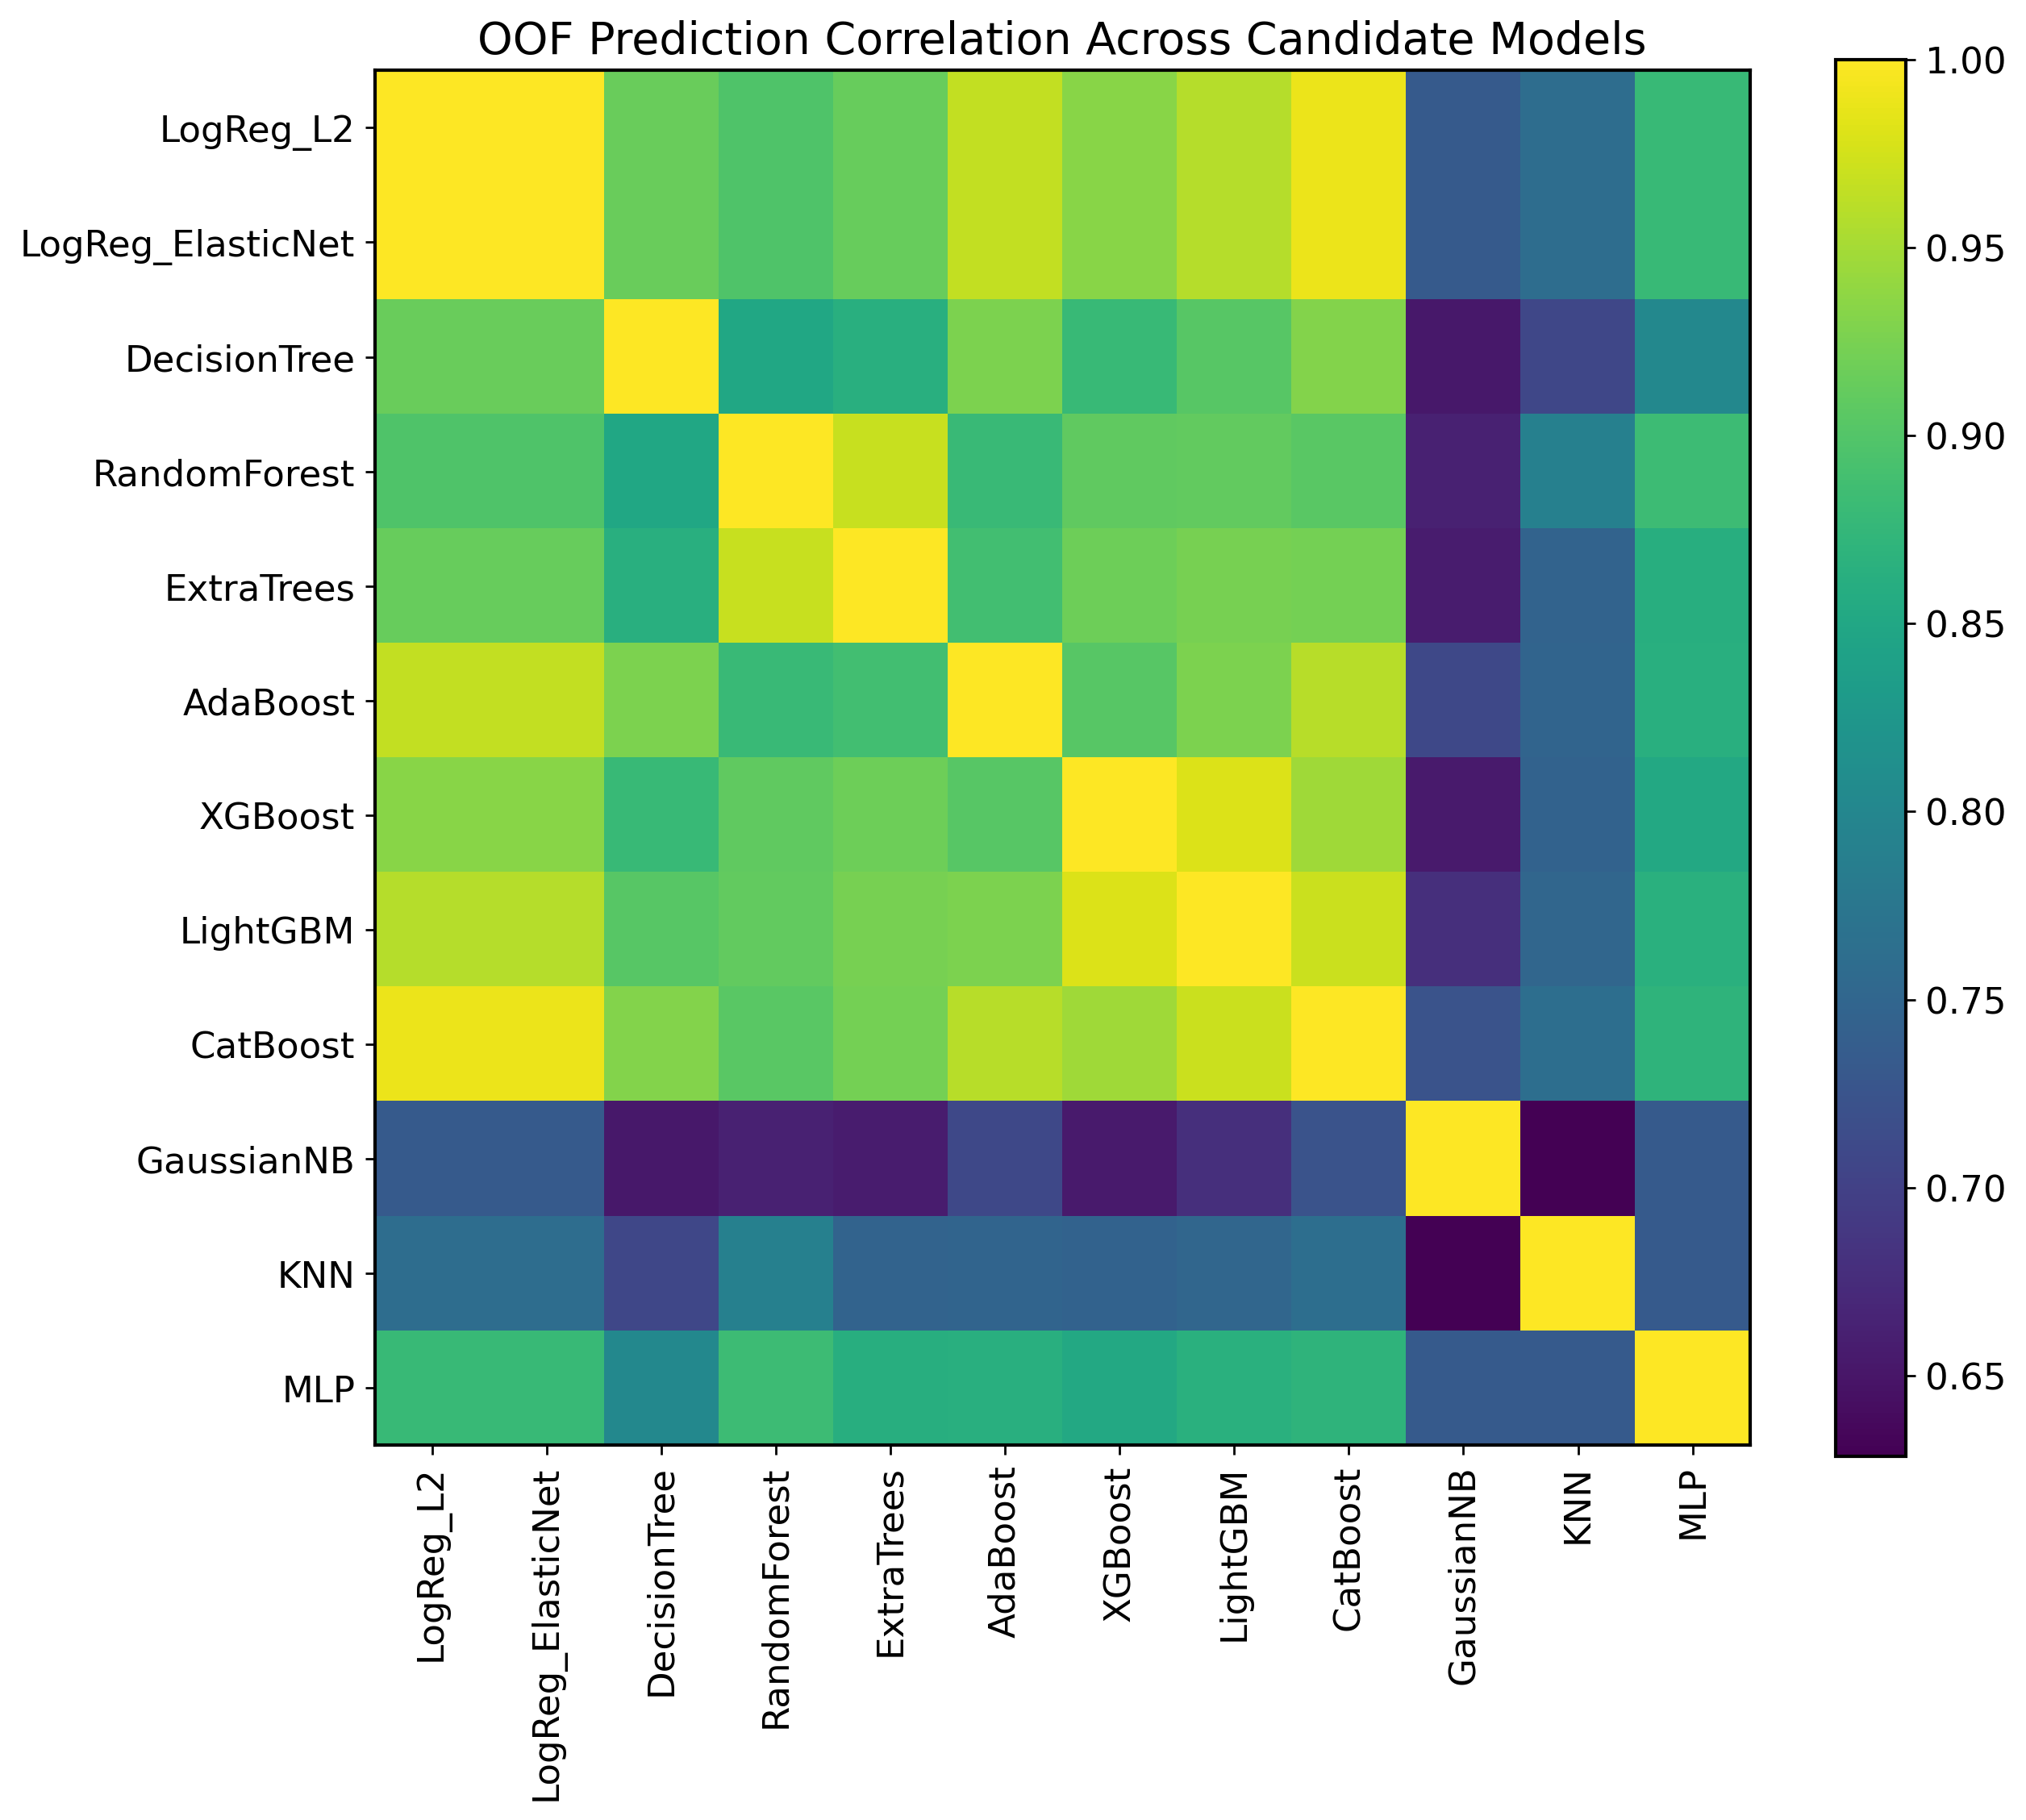


===== Module 4 Summary =====
Completed models : 12
Skipped/failed   : 3

Top models by PR_AUC:
               model                 family    PR_AUC   ROC_AUC     Brier  \
0           CatBoost      gradient_boosting  0.377911  0.849983  0.164654   
1  LogReg_ElasticNet                 linear  0.371680  0.847420  0.165002   
2          LogReg_L2                 linear  0.371663  0.847420  0.165015   
3                MLP           deep_tabular  0.366433  0.844312  0.070602   
4           LightGBM      gradient_boosting  0.363262  0.840968  0.149680   
5           AdaBoost  tree_bagging_boosting  0.357061  0.839609  0.095894   
6            XGBoost      gradient_boosting  0.350739  0.833538  0.145303   
7       DecisionTree  tree_bagging_boosting  0.337989  0.829850  0.175737   
8       RandomForest  tree_bagging_boosting  0.335296  0.834502  0.084632   
9         ExtraTrees  tree_bagging_boosting  0.334669  0.833062  0.106355   

        ECE        F1       MCC  
0  0.251126  0.420636 

In [3]:
# ============================================================
# Locked Research Pipeline — Module 4
#
# Module 4 — Candidate Model Screening
#
# Includes:
# - Classical ML baselines
# - Boosting baselines
# - Modern tabular DL baselines:
#     * MLP (sklearn)
#     * DeepFM
#     * AutoInt
#     * TabNet
#
# Outputs:
# - baseline comparison table
# - OOF prediction matrix
# - fold-wise metrics bank
# - model correlation heatmap
# - run summary including skipped optional models
# ============================================================

import gc
import os
import json
import time
import importlib.util
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED", "y_dev", "EPS",
    "make_sklearn_cv_runner",
    "make_boosting_cv_runner",
    "run_custom_cv_engine",
    "TAB_DIR", "FIG_DIR", "PRED_DIR", "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 4: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
SCREENING_TOP_K_PRINT = 10
SAVE_CORR_FORMATS = ["png", "pdf"]
NEG_POS_RATIO = float((len(y_dev) - int(np.sum(y_dev))) / max(int(np.sum(y_dev)), 1))

# ------------------------------------------------------------
# Optional dependency detection
# ------------------------------------------------------------
def package_available(module_name: str) -> bool:
    return importlib.util.find_spec(module_name) is not None

HAS_DEEPCTR = package_available("deepctr_torch")
HAS_TABNET = package_available("pytorch_tabnet")

optional_dependency_status = {
    "deepctr_torch": HAS_DEEPCTR,
    "pytorch_tabnet": HAS_TABNET,
}

print("Optional dependency status:")
for k, v in optional_dependency_status.items():
    print(f"  {k}: {'available' if v else 'missing'}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def save_fig_multi(base_path: Path):
    for ext in SAVE_CORR_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")

def get_family_from_name(name: str) -> str:
    if name in ["LogReg_L2", "LogReg_ElasticNet"]:
        return "linear"
    if name in ["DecisionTree", "RandomForest", "ExtraTrees", "AdaBoost"]:
        return "tree_bagging_boosting"
    if name in ["XGBoost", "LightGBM", "CatBoost"]:
        return "gradient_boosting"
    if name in ["LinearSVM", "RBFSVM"]:
        return "svm"
    if name in ["GaussianNB", "KNN"]:
        return "probabilistic_distance"
    if name in ["MLP", "DeepFM", "AutoInt", "TabNet"]:
        return "deep_tabular"
    return "other"

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def build_class_weight_dict(y):
    y = np.asarray(y).astype(int)
    pos = int(np.sum(y))
    neg = int(len(y) - pos)
    if pos == 0 or neg == 0:
        return {0: 1.0, 1: 1.0}
    total = pos + neg
    return {
        0: total / (2.0 * neg),
        1: total / (2.0 * pos),
    }

# ------------------------------------------------------------
# Classical / boosting model factories
# ------------------------------------------------------------
def get_standard_model_factories():
    models = {}

    # -------- Linear --------
    models["LogReg_L2"] = lambda: LogisticRegression(
        C=1.0,
        max_iter=2500,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )

    models["LogReg_ElasticNet"] = lambda: LogisticRegression(
        penalty="elasticnet",
        l1_ratio=0.5,
        solver="saga",
        max_iter=2500,
        class_weight="balanced",
        random_state=SEED
    )

    # -------- Trees / bagging --------
    models["DecisionTree"] = lambda: DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=SEED
    )

    models["RandomForest"] = lambda: RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    )

    models["ExtraTrees"] = lambda: ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    )

    models["AdaBoost"] = lambda: AdaBoostClassifier(
        n_estimators=250,
        learning_rate=0.05,
        random_state=SEED
    )

    # -------- Boosting --------
    models["XGBoost"] = lambda: XGBClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=NEG_POS_RATIO,
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED
    )

    models["LightGBM"] = lambda: LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED
    )

    models["CatBoost"] = lambda: CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="Logloss",
        auto_class_weights="Balanced",
        verbose=0,
        random_state=SEED
    )

    # -------- Others --------
    models["GaussianNB"] = lambda: GaussianNB()

    models["KNN"] = lambda: KNeighborsClassifier(
        n_neighbors=50,
        weights="distance"
    )

    # -------- Basic neural baseline --------
    models["MLP"] = lambda: MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=20,
        random_state=SEED
    )

    return models

# ------------------------------------------------------------
# DeepCTR helpers for DeepFM / AutoInt
# ------------------------------------------------------------
def infer_deepctr_vocab_sizes(X_train_view, X_valid_view, X_es_view=None):
    sparse_cols = X_train_view["sparse_cols"]
    vocab_sizes = {}

    for c in sparse_cols:
        arrays = [
            np.asarray(X_train_view["X_sparse"][c].values),
            np.asarray(X_valid_view["X_sparse"][c].values),
        ]
        if X_es_view is not None:
            arrays.append(np.asarray(X_es_view["X_sparse"][c].values))

        mx = int(np.max(np.concatenate(arrays))) if len(arrays) > 0 else 1
        vocab_sizes[c] = max(mx + 1, 2)

    return vocab_sizes

def build_deepctr_input_dict(view_dict):
    dense_cols = view_dict["dense_cols"]
    sparse_cols = view_dict["sparse_cols"]

    model_input = {}

    for c in sparse_cols:
        model_input[c] = view_dict["X_sparse"][c].astype("int64").values

    for c in dense_cols:
        model_input[c] = view_dict["X_dense"][c].astype("float32").values

    return model_input

def make_deepctr_fold_fn(model_type: str = "DeepFM"):
    """
    model_type: 'DeepFM' or 'AutoInt'
    preprocess_mode expected: deep_views
    """
    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 12))
        batch_size = int(fit_kwargs.get("batch_size", 1024))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))
        use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        X_train_input = build_deepctr_input_dict(X_train)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        class_weight = build_class_weight_dict(y_train)

        fit_params = {
            "x": X_train_input,
            "y": np.asarray(y_train).astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
            "class_weight": class_weight,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (X_es_input, np.asarray(y_es).astype("float32"))

        model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = clip_probs_local(p_valid)

        if len(p_valid) != len(y_train) and len(p_valid) != len(X_valid["X_dl"]):
            raise ValueError(
                f"{model_type} returned prediction length {len(p_valid)} "
                f"but expected {len(X_valid['X_dl'])} on validation fold."
            )

        return model, p_valid

    return deepctr_fold_fn

# ------------------------------------------------------------
# TabNet custom fold function
# ------------------------------------------------------------
def tabnet_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
    if not HAS_TABNET:
        raise ImportError("pytorch_tabnet is not installed.")

    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    fit_kwargs = fit_kwargs or {}

    max_epochs = int(fit_kwargs.get("max_epochs", 120))
    patience = int(fit_kwargs.get("patience", 20))
    batch_size = int(fit_kwargs.get("batch_size", 1024))
    virtual_batch_size = int(fit_kwargs.get("virtual_batch_size", 128))
    verbose = int(fit_kwargs.get("verbose", 0))
    use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))

    device_name = "cuda" if use_gpu and torch.cuda.is_available() else "cpu"

    X_train_np = X_train.values.astype(np.float32)
    X_valid_np = X_valid.values.astype(np.float32)
    y_train_np = np.asarray(y_train).astype(int).reshape(-1)

    clf = TabNetClassifier(
        n_d=32,
        n_a=32,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=2e-2),
        mask_type="entmax",
        scheduler_params={"step_size": 20, "gamma": 0.9},
        scheduler_fn=torch.optim.lr_scheduler.StepLR,
        seed=SEED,
        verbose=verbose,
        device_name=device_name,
    )

    fit_params = {
        "X_train": X_train_np,
        "y_train": y_train_np,
        "max_epochs": max_epochs,
        "patience": patience,
        "batch_size": batch_size,
        "virtual_batch_size": virtual_batch_size,
        "num_workers": 0,
        "drop_last": False,
    }

    if X_es is not None and y_es is not None:
        fit_params["eval_set"] = [(X_es.values.astype(np.float32), np.asarray(y_es).astype(int).reshape(-1))]
        fit_params["eval_name"] = ["early_stop"]
    else:
        fit_params["eval_set"] = [(X_train_np, y_train_np)]
        fit_params["eval_name"] = ["train"]

    clf.fit(**fit_params)

    p_valid = clf.predict_proba(X_valid_np)[:, 1]
    p_valid = clip_probs_local(p_valid)

    if len(p_valid) != len(X_valid_np):
        raise ValueError(
            f"TabNet returned prediction length {len(p_valid)} "
            f"but expected {len(X_valid_np)} on validation fold."
        )

    return clf, p_valid

# ------------------------------------------------------------
# Run screening
# ------------------------------------------------------------
def run_model_screening_locked():
    standard_models = get_standard_model_factories()

    results = {}
    run_rows = []
    skipped_rows = []

    print("\n===== Module 4: Locked Candidate Screening =====")
    print(f"Standard models: {len(standard_models)}")

    # -------------------------
    # Standard ML / boosting
    # -------------------------
    for name, factory in standard_models.items():
        print(f"\n--- Running standard model: {name} ---")
        t0 = time.time()

        try:
            if name in ["XGBoost", "LightGBM", "CatBoost"]:
                if name == "XGBoost":
                    fit_kwargs = {
                        "verbose": False,
                    }
                elif name == "LightGBM":
                    fit_kwargs = {
                        "callbacks": [],
                    }
                else:  # CatBoost
                    fit_kwargs = {
                        "use_best_model": True,
                        "verbose": False,
                    }

                result = make_boosting_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs=fit_kwargs,
                    save_fold_models=False
                )

            elif name == "MLP":
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="dl",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )

            else:
                result = make_sklearn_cv_runner(
                    model_name=name,
                    model_factory=factory,
                    preprocess_mode="ml",
                    threshold_mode="f1",
                    fit_kwargs=None,
                    save_fold_models=False
                )

            elapsed = time.time() - t0
            results[name] = result

            run_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "completed",
                "elapsed_sec": elapsed,
            })

        except Exception as e:
            elapsed = time.time() - t0
            skipped_rows.append({
                "model": name,
                "family": get_family_from_name(name),
                "status": "failed",
                "reason": str(e),
                "elapsed_sec": elapsed,
            })
            print(f"Failed: {name} -> {e}")

        gc.collect()

    # -------------------------
    # DeepFM
    # -------------------------
    name = "DeepFM"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("DeepFM"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 8,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # AutoInt
    # -------------------------
    name = "AutoInt"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=make_deepctr_fold_fn("AutoInt"),
            preprocess_mode="deep_views",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "epochs": 8,
                "batch_size": 1024,
                "verbose": 0,
                "embedding_dim": 8,
                "dnn_hidden_units": (256, 128),
                "att_head_num": 2,
                "att_layer_num": 3,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    # -------------------------
    # TabNet
    # -------------------------
    name = "TabNet"
    print(f"\n--- Running SOTA tabular model: {name} ---")
    t0 = time.time()
    try:
        if not HAS_TABNET:
            raise ImportError("pytorch_tabnet not installed")

        result = run_custom_cv_engine(
            model_name=name,
            custom_fold_fn=tabnet_fold_fn,
            preprocess_mode="dl",
            threshold_mode="f1",
            use_inner_es_split=True,
            fit_kwargs={
                "max_epochs": 20,
                "patience": 5,
                "batch_size": 1024,
                "virtual_batch_size": 128,
                "verbose": 0,
                "use_gpu": True,
            }
        )

        elapsed = time.time() - t0
        results[name] = result

        run_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "completed",
            "elapsed_sec": elapsed,
        })

    except Exception as e:
        elapsed = time.time() - t0
        skipped_rows.append({
            "model": name,
            "family": get_family_from_name(name),
            "status": "skipped_or_failed",
            "reason": str(e),
            "elapsed_sec": elapsed,
        })
        print(f"Skipped/failed: {name} -> {e}")

    gc.collect()

    run_df = pd.DataFrame(run_rows)
    skipped_df = pd.DataFrame(skipped_rows)

    if run_df.empty:
        raise RuntimeError("No candidate model completed successfully in Module 4.")

    run_df.to_csv(TAB_DIR / "module4_run_summary.csv", index=False)
    skipped_df.to_csv(TAB_DIR / "module4_skipped_models.csv", index=False)

    return results, run_df, skipped_df

# ------------------------------------------------------------
# Aggregate overall baseline table
# ------------------------------------------------------------
def build_baseline_table(results: dict):
    rows = []

    for name, res in results.items():
        row = res["overall_metrics_df"].iloc[0].to_dict()
        row["model"] = name
        row["family"] = get_family_from_name(name)
        rows.append(row)

    baseline_df = pd.DataFrame(rows)

    preferred_cols = [
        "model", "family", "setting",
        "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
        "Precision", "Recall", "F1", "MCC", "Accuracy",
        "threshold", "best_curve_f1", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
    ]
    preferred_cols = [c for c in preferred_cols if c in baseline_df.columns] + \
                     [c for c in baseline_df.columns if c not in preferred_cols]

    baseline_df = baseline_df[preferred_cols]
    baseline_df = baseline_df.sort_values(
        by=["PR_AUC", "ROC_AUC"],
        ascending=[False, False]
    ).reset_index(drop=True)

    baseline_df.to_csv(TAB_DIR / "module4_baseline_comparison.csv", index=False)
    return baseline_df

# ------------------------------------------------------------
# Aggregate fold metrics across all models
# ------------------------------------------------------------
def build_fold_metrics_bank(results: dict):
    dfs = []

    for name, res in results.items():
        df = res["fold_metrics_df"].copy()
        df["family"] = get_family_from_name(name)
        dfs.append(df)

    if not dfs:
        raise RuntimeError("No fold metrics available to build bank.")

    bank_df = pd.concat(dfs, axis=0, ignore_index=True)
    bank_df.to_csv(TAB_DIR / "module4_all_fold_metrics.csv", index=False)
    return bank_df

# ------------------------------------------------------------
# Build OOF matrix
# ------------------------------------------------------------
def build_oof_matrix(results: dict):
    model_names = list(results.keys())

    if len(model_names) == 0:
        raise RuntimeError("No results available for OOF matrix.")

    base_len = None
    for name in model_names:
        cur_len = len(results[name]["oof_pred"])
        if base_len is None:
            base_len = cur_len
        elif cur_len != base_len:
            raise ValueError("OOF lengths across models do not match.")

    oof_df = pd.DataFrame({
        "row_idx_dev": np.arange(base_len, dtype=int),
        "y_true": results[model_names[0]]["oof_y_true"].astype(int),
    })

    for name in model_names:
        oof_df[name] = results[name]["oof_pred"]

    oof_df.to_csv(PRED_DIR / "module4_oof_matrix.csv", index=False)
    return oof_df

# ------------------------------------------------------------
# Correlation analysis
# ------------------------------------------------------------
def plot_model_correlation(oof_df: pd.DataFrame):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    corr = oof_df[pred_cols].corr()

    plt.figure(figsize=(11, 9))
    im = plt.imshow(corr.values)
    plt.colorbar(im)

    plt.xticks(range(len(pred_cols)), pred_cols, rotation=90)
    plt.yticks(range(len(pred_cols)), pred_cols)
    plt.title("OOF Prediction Correlation Across Candidate Models")

    save_fig_multi(FIG_DIR / "module4_model_correlation")
    plt.show()

    corr.to_csv(TAB_DIR / "module4_model_correlation.csv")
    return corr

# ------------------------------------------------------------
# Disagreement analysis
# ------------------------------------------------------------
def build_disagreement_matrix(oof_df: pd.DataFrame, threshold: float = 0.5):
    pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
    bin_df = (oof_df[pred_cols] >= threshold).astype(int)

    n = len(pred_cols)
    mat = np.zeros((n, n), dtype=float)

    for i, ci in enumerate(pred_cols):
        for j, cj in enumerate(pred_cols):
            mat[i, j] = float(np.mean(bin_df[ci].values != bin_df[cj].values))

    disagreement_df = pd.DataFrame(mat, index=pred_cols, columns=pred_cols)
    disagreement_df.to_csv(TAB_DIR / "module4_model_disagreement_matrix.csv")
    return disagreement_df

# ------------------------------------------------------------
# Short printed summary
# ------------------------------------------------------------
def summarize_screening(baseline_df: pd.DataFrame, run_df: pd.DataFrame, skipped_df: pd.DataFrame):
    print("\n===== Module 4 Summary =====")
    print(f"Completed models : {len(run_df)}")
    print(f"Skipped/failed   : {len(skipped_df)}")

    print("\nTop models by PR_AUC:")
    display_cols = [
        c for c in
        ["model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"]
        if c in baseline_df.columns
    ]
    print(baseline_df.head(SCREENING_TOP_K_PRINT)[display_cols])

    if len(skipped_df) > 0:
        print("\nSkipped/failed models:")
        print(skipped_df[["model", "reason"]])

# ------------------------------------------------------------
# Main execution
# ------------------------------------------------------------
results, run_df, skipped_df = run_model_screening_locked()

baseline_df = build_baseline_table(results)
fold_bank_df = build_fold_metrics_bank(results)
oof_df = build_oof_matrix(results)
corr_df = plot_model_correlation(oof_df)
disagreement_df = build_disagreement_matrix(oof_df, threshold=0.5)

module4_meta = {
    "n_completed_models": int(len(run_df)),
    "n_skipped_models": int(len(skipped_df)),
    "completed_models": run_df["model"].tolist() if len(run_df) else [],
    "skipped_models": skipped_df["model"].tolist() if len(skipped_df) else [],
    "optional_dependency_status": optional_dependency_status,
}

with open(LOG_DIR / "module4_metadata.json", "w") as f:
    json.dump(module4_meta, f, indent=2)

summarize_screening(baseline_df, run_df, skipped_df)

print("\nModule 4 complete.")
print("Saved:")
print(" - module4_baseline_comparison.csv")
print(" - module4_all_fold_metrics.csv")
print(" - module4_oof_matrix.csv")
print(" - module4_model_correlation.csv")
print(" - module4_model_disagreement_matrix.csv")
print(" - module4_run_summary.csv")
print(" - module4_skipped_models.csv")

In [4]:
# ============================================================
# Install optional deep-tabular packages only
# ============================================================

import sys
import subprocess
import importlib.util

def pip_install(pkg):
    print(f"Installing: {pkg}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

if importlib.util.find_spec("pytorch_tabnet") is None:
    pip_install("pytorch-tabnet")
else:
    print("pytorch_tabnet already installed.")

if importlib.util.find_spec("deepctr_torch") is None:
    try:
        pip_install("deepctr-torch")
    except Exception as e:
        print("deepctr-torch installation failed:", e)
else:
    print("deepctr_torch already installed.")

print("Install step finished.")

# ============================================================
# Refresh optional dependency flags
# ============================================================

import importlib.util

HAS_DEEPCTR = importlib.util.find_spec("deepctr_torch") is not None
HAS_TABNET = importlib.util.find_spec("pytorch_tabnet") is not None

print("HAS_DEEPCTR =", HAS_DEEPCTR)
print("HAS_TABNET  =", HAS_TABNET)

Installing: pytorch-tabnet
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.0 MB/s eta 0:00:00
Installing: deepctr-torch
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 3.3 MB/s eta 0:00:00
Install step finished.
HAS_DEEPCTR = True
HAS_TABNET  = True


In [5]:
# ============================================================
# Corrected DeepCTR fold function for DeepFM / AutoInt
# Fallback: fold-local random oversampling instead of class_weight
# ============================================================

def make_deepctr_fold_fn(model_type: str = "DeepFM"):
    """
    model_type: 'DeepFM' or 'AutoInt'
    preprocess_mode expected: deep_views
    """
    def deepctr_fold_fn(X_train, y_train, X_valid, X_es=None, y_es=None, fit_kwargs=None):
        if not HAS_DEEPCTR:
            raise ImportError("deepctr_torch is not installed.")

        import torch
        from deepctr_torch.inputs import SparseFeat, DenseFeat
        from deepctr_torch.models import DeepFM, AutoInt

        fit_kwargs = fit_kwargs or {}

        epochs = int(fit_kwargs.get("epochs", 12))
        batch_size = int(fit_kwargs.get("batch_size", 1024))
        verbose = int(fit_kwargs.get("verbose", 0))
        embedding_dim = int(fit_kwargs.get("embedding_dim", 8))
        dnn_hidden_units = fit_kwargs.get("dnn_hidden_units", (256, 128))
        att_head_num = int(fit_kwargs.get("att_head_num", 2))
        att_layer_num = int(fit_kwargs.get("att_layer_num", 3))
        use_gpu = bool(fit_kwargs.get("use_gpu", torch.cuda.is_available()))
        oversample_train = bool(fit_kwargs.get("oversample_train", True))

        device = "cuda:0" if use_gpu and torch.cuda.is_available() else "cpu"

        # ----------------------------------------------------
        # Fold-local random oversampling on TRAIN only
        # ----------------------------------------------------
        y_train_arr = np.asarray(y_train).astype(int).reshape(-1)

        X_train_dense = X_train["X_dense"].copy()
        X_train_sparse = X_train["X_sparse"].copy()

        if oversample_train:
            pos_idx = np.where(y_train_arr == 1)[0]
            neg_idx = np.where(y_train_arr == 0)[0]

            if len(pos_idx) > 0 and len(neg_idx) > 0 and len(pos_idx) < len(neg_idx):
                rng = np.random.RandomState(SEED)
                extra_pos_idx = rng.choice(pos_idx, size=(len(neg_idx) - len(pos_idx)), replace=True)
                new_idx = np.concatenate([np.arange(len(y_train_arr)), extra_pos_idx])
                rng.shuffle(new_idx)

                if not X_train_dense.empty:
                    X_train_dense = X_train_dense.iloc[new_idx].reset_index(drop=True)
                if not X_train_sparse.empty:
                    X_train_sparse = X_train_sparse.iloc[new_idx].reset_index(drop=True)

                y_train_arr = y_train_arr[new_idx]

        X_train_used = {
            "X_dl": None,
            "X_dense": X_train_dense,
            "X_sparse": X_train_sparse,
            "dense_cols": X_train["dense_cols"],
            "sparse_cols": X_train["sparse_cols"],
        }

        X_train_input = build_deepctr_input_dict(X_train_used)
        X_valid_input = build_deepctr_input_dict(X_valid)
        X_es_input = build_deepctr_input_dict(X_es) if X_es is not None else None

        dense_cols = X_train["dense_cols"]
        sparse_cols = X_train["sparse_cols"]

        vocab_sizes = infer_deepctr_vocab_sizes(X_train_used, X_valid, X_es)

        linear_feature_columns = (
            [SparseFeat(c, vocabulary_size=vocab_sizes[c], embedding_dim=embedding_dim) for c in sparse_cols] +
            [DenseFeat(c, 1) for c in dense_cols]
        )
        dnn_feature_columns = linear_feature_columns

        if model_type == "DeepFM":
            model = DeepFM(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                task="binary",
                device=device
            )
        elif model_type == "AutoInt":
            model = AutoInt(
                linear_feature_columns=linear_feature_columns,
                dnn_feature_columns=dnn_feature_columns,
                dnn_hidden_units=dnn_hidden_units,
                att_head_num=att_head_num,
                att_layer_num=att_layer_num,
                task="binary",
                device=device
            )
        else:
            raise ValueError(f"Unsupported model_type: {model_type}")

        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["binary_crossentropy", "auc"]
        )

        fit_params = {
            "x": X_train_input,
            "y": y_train_arr.astype("float32"),
            "batch_size": batch_size,
            "epochs": epochs,
            "verbose": verbose,
        }

        if X_es_input is not None and y_es is not None:
            fit_params["validation_data"] = (
                X_es_input,
                np.asarray(y_es).astype("float32")
            )

        model.fit(**fit_params)

        p_valid = model.predict(X_valid_input, batch_size=batch_size).reshape(-1)
        p_valid = clip_probs_local(p_valid)

        expected_len = len(X_valid["X_dl"])
        if len(p_valid) != expected_len:
            raise ValueError(
                f"{model_type} returned prediction length {len(p_valid)} "
                f"but expected {expected_len} on validation fold."
            )

        return model, p_valid

    return deepctr_fold_fn

In [6]:
deepfm_result = run_custom_cv_engine(
    model_name="DeepFM",
    custom_fold_fn=make_deepctr_fold_fn("DeepFM"),
    preprocess_mode="deep_views",
    threshold_mode="f1",
    use_inner_es_split=True,
    fit_kwargs={
        "epochs": 12,
        "batch_size": 1024,
        "verbose": 0,
        "embedding_dim": 8,
        "dnn_hidden_units": (256, 128),
        "use_gpu": True,
        "oversample_train": True,
    }
)

print(deepfm_result["overall_metrics_df"])


===== Running CV: DeepFM =====
Total folds: 10
Preprocess mode: deep_views
Runner: custom_fold_fn
Use inner ES split: True


2026-03-18 09:34:38.290411: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773826478.464281      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773826478.509618      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773826478.954961      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773826478.954986      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773826478.954989      55 computation_placer.cc:177] computation placer alr

cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.370530 ROC_AUC=0.845237 F1=0.420908 time=78.87s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.380685 ROC_AUC=0.848842 F1=0.422494 time=56.28s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.365376 ROC_AUC=0.842481 F1=0.411912 time=56.20s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.372039 ROC_AUC=0.851161 F1=0.419893 time=55.84s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.364105 ROC_AUC=0.840944 F1=0.410532 time=56.79s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[06/10] fold=6 rep=2 inner=1 PR_AUC=0.372470 ROC_AUC=0.843569 F1=0.419210 time=56.12s
cuda:0
Tra

In [7]:
autoint_result = run_custom_cv_engine(
    model_name="AutoInt",
    custom_fold_fn=make_deepctr_fold_fn("AutoInt"),
    preprocess_mode="deep_views",
    threshold_mode="f1",
    use_inner_es_split=True,
    fit_kwargs={
        "epochs": 6,
        "batch_size": 1024,
        "verbose": 0,
        "embedding_dim": 8,
        "dnn_hidden_units": (256, 128),
        "att_head_num": 2,
        "att_layer_num": 3,
        "use_gpu": True,
        "oversample_train": True,
    }
)

print(autoint_result["overall_metrics_df"])


===== Running CV: AutoInt =====
Total folds: 10
Preprocess mode: deep_views
Runner: custom_fold_fn
Use inner ES split: True
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.381134 ROC_AUC=0.851747 F1=0.426129 time=30.39s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.388084 ROC_AUC=0.852034 F1=0.426461 time=30.59s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.368329 ROC_AUC=0.845438 F1=0.418138 time=30.36s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.380853 ROC_AUC=0.854650 F1=0.422127 time=30.20s
cuda:0
Train on 250008 samples, validate on 24354 samples, 245 steps per epoch
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.362990 ROC_AUC=0.842147 F1=0.406387 time=30.54s
cuda:0
Train on 250008 samples, validate on 24354 

In [8]:
# ============================================================
# Run TabNet only
# ============================================================

if not HAS_TABNET:
    raise ImportError("pytorch_tabnet is still not installed.")

tabnet_result = run_custom_cv_engine(
    model_name="TabNet",
    custom_fold_fn=tabnet_fold_fn,
    preprocess_mode="dl",
    threshold_mode="f1",
    use_inner_es_split=True,
    fit_kwargs={
        "max_epochs": 8,
        "patience": 4,
        "batch_size": 1024,
        "virtual_batch_size": 128,
        "verbose": 0,
        "use_gpu": True,
    }
)

print(tabnet_result["overall_metrics_df"])


===== Running CV: TabNet =====
Total folds: 10
Preprocess mode: dl
Runner: custom_fold_fn
Use inner ES split: True

Early stopping occurred at epoch 10 with best_epoch = 6 and best_early_stop_auc = 0.83985
[01/10] fold=1 rep=1 inner=1 PR_AUC=0.367454 ROC_AUC=0.845120 F1=0.419312 time=88.85s
Stop training because you reached max_epochs = 15 with best_epoch = 12 and best_early_stop_auc = 0.84001
[02/10] fold=2 rep=1 inner=2 PR_AUC=0.375341 ROC_AUC=0.849730 F1=0.425633 time=119.77s

Early stopping occurred at epoch 11 with best_epoch = 7 and best_early_stop_auc = 0.84791
[03/10] fold=3 rep=1 inner=3 PR_AUC=0.348869 ROC_AUC=0.839111 F1=0.406630 time=96.77s
Stop training because you reached max_epochs = 15 with best_epoch = 11 and best_early_stop_auc = 0.83949
[04/10] fold=4 rep=1 inner=4 PR_AUC=0.359265 ROC_AUC=0.849129 F1=0.415938 time=118.22s
Stop training because you reached max_epochs = 15 with best_epoch = 13 and best_early_stop_auc = 0.84785
[05/10] fold=5 rep=1 inner=5 PR_AUC=0.360

Current models in results:
['LogReg_L2', 'LogReg_ElasticNet', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'AdaBoost', 'XGBoost', 'LightGBM', 'CatBoost', 'GaussianNB', 'KNN', 'MLP', 'DeepFM', 'AutoInt', 'TabNet']


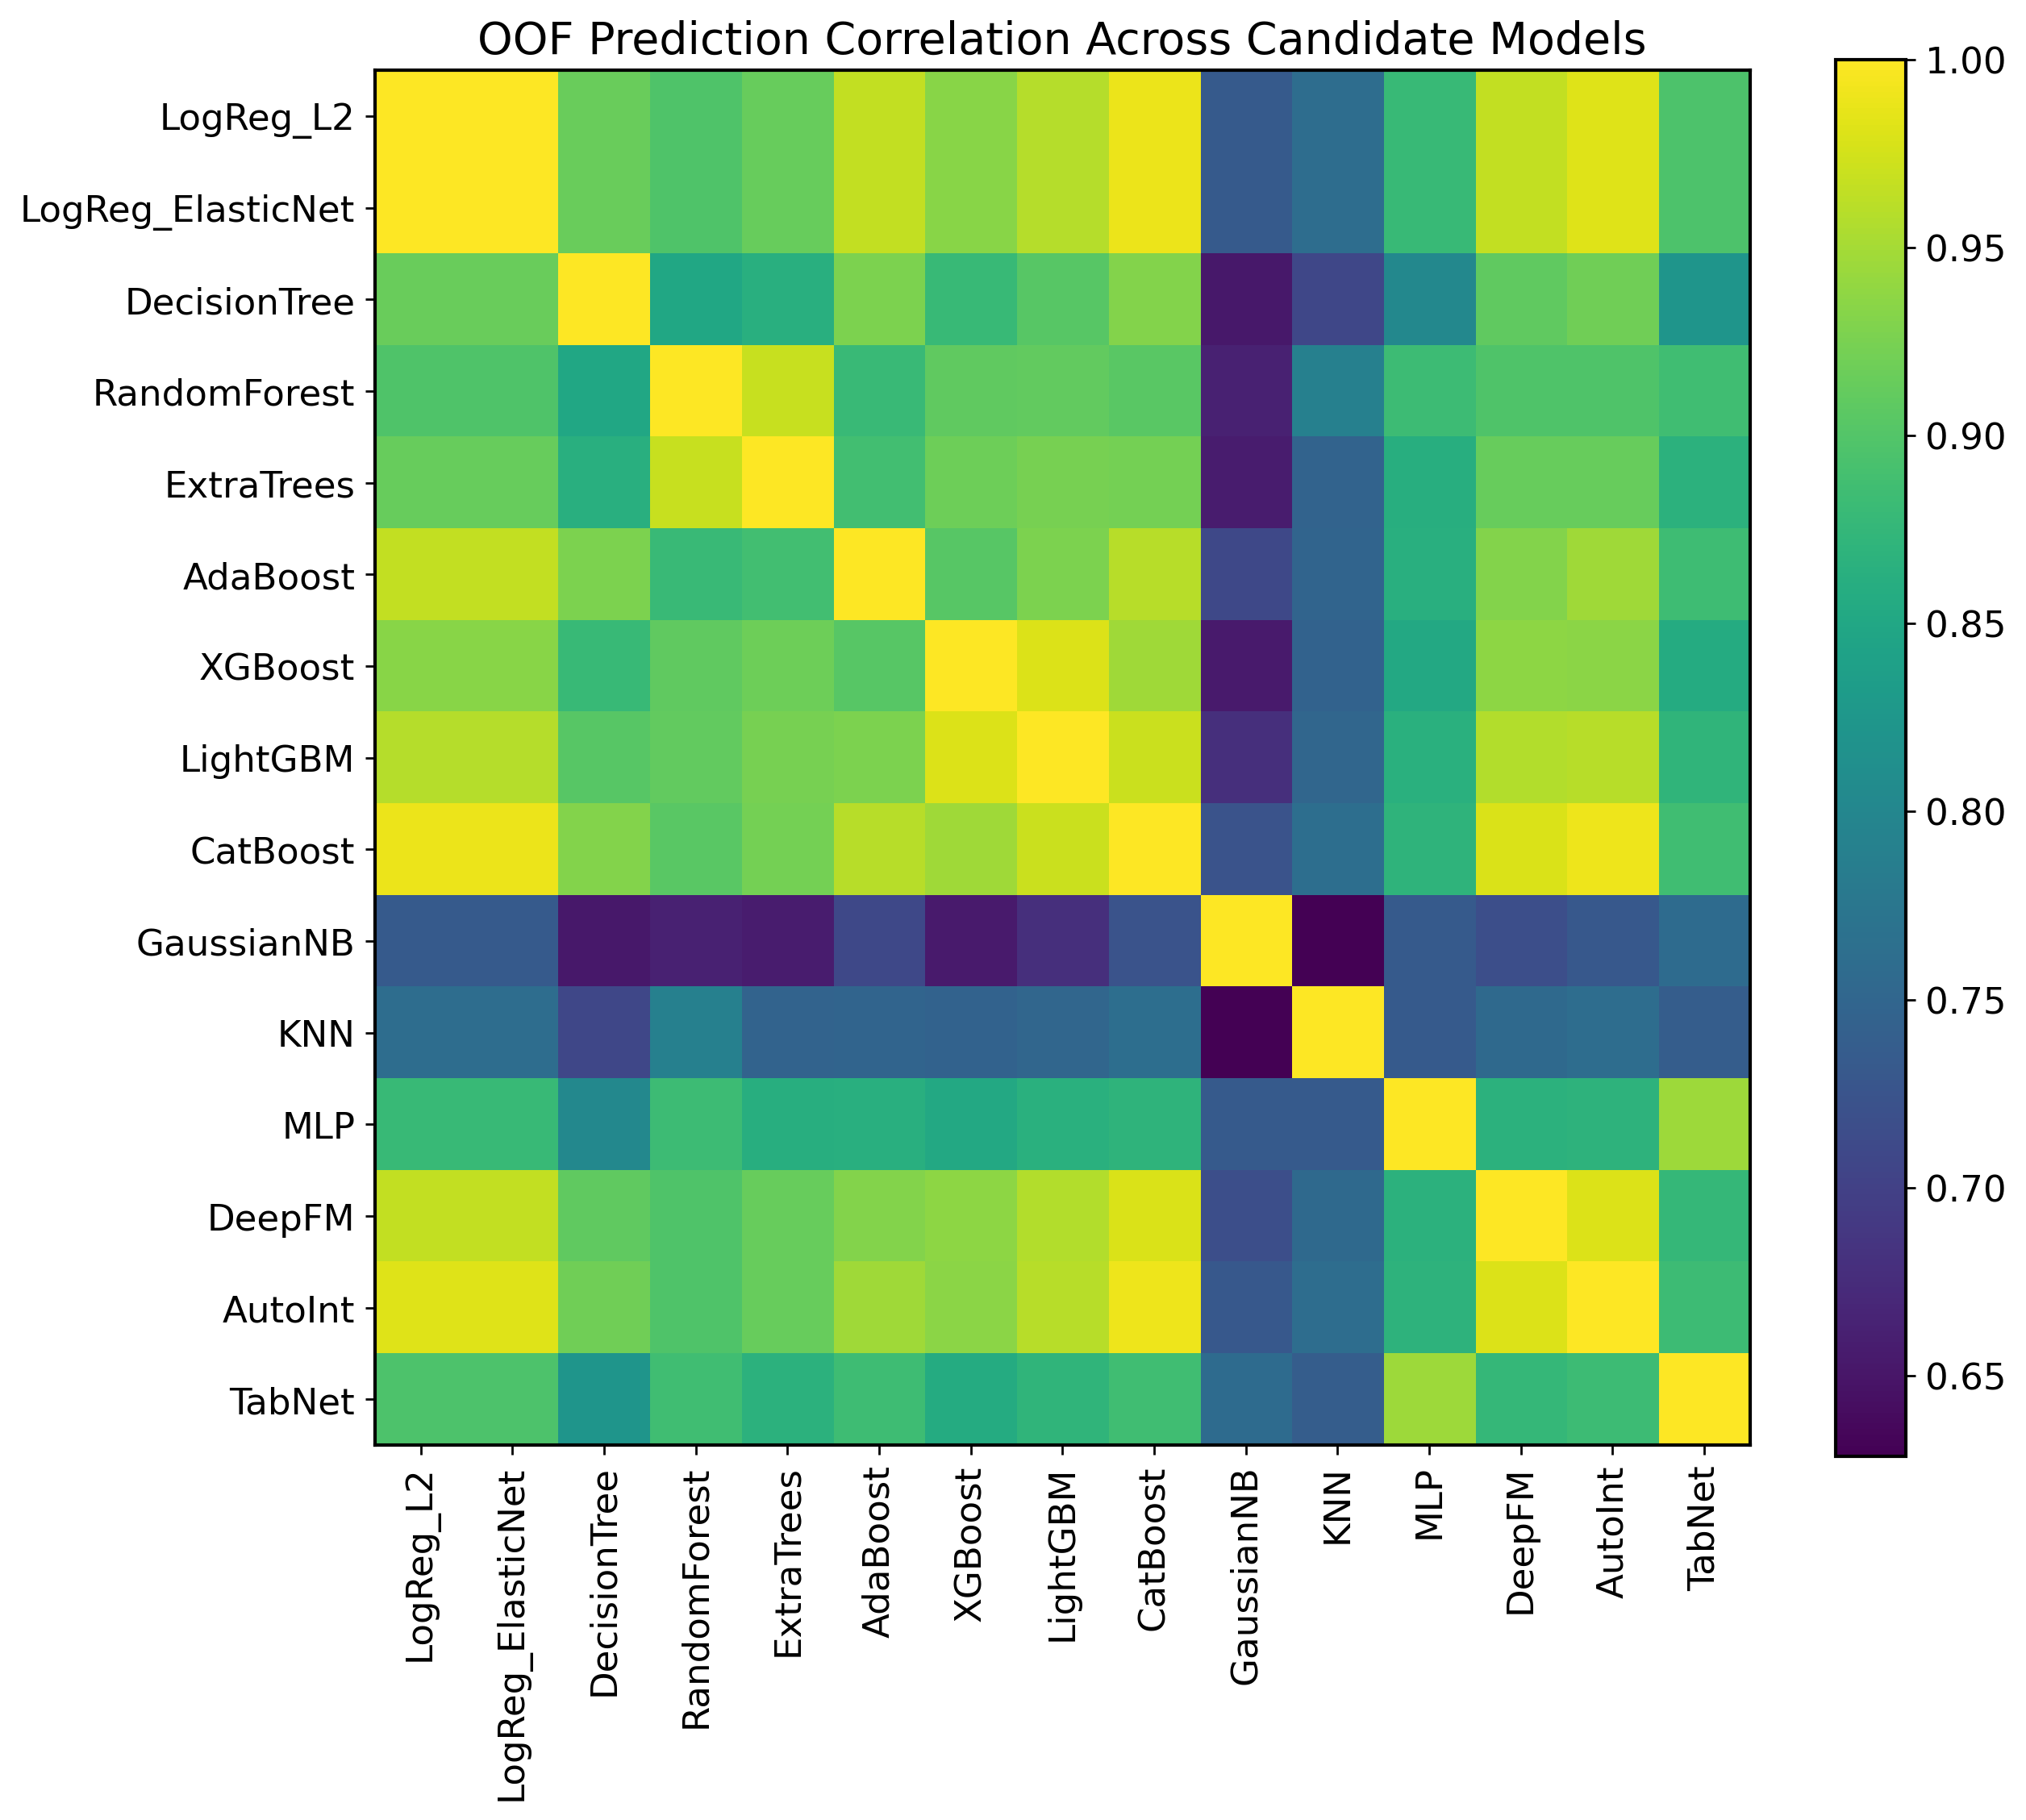

                model                  family setting    PR_AUC   ROC_AUC  \
0            CatBoost       gradient_boosting     OOF  0.377911  0.849983   
1             AutoInt            deep_tabular     OOF  0.372959  0.848281   
2   LogReg_ElasticNet                  linear     OOF  0.371680  0.847420   
3           LogReg_L2                  linear     OOF  0.371663  0.847420   
4              DeepFM            deep_tabular     OOF  0.370039  0.845996   
5                 MLP            deep_tabular     OOF  0.366433  0.844312   
6              TabNet            deep_tabular     OOF  0.364330  0.845183   
7            LightGBM       gradient_boosting     OOF  0.363262  0.840968   
8            AdaBoost   tree_bagging_boosting     OOF  0.357061  0.839609   
9             XGBoost       gradient_boosting     OOF  0.350739  0.833538   
10       DecisionTree   tree_bagging_boosting     OOF  0.337989  0.829850   
11       RandomForest   tree_bagging_boosting     OOF  0.335296  0.834502   

In [9]:
# ============================================================
# Add newly run optional models into existing results dict
# ============================================================

if "results" not in globals():
    results = {}

if "deepfm_result" in globals():
    results["DeepFM"] = deepfm_result

if "autoint_result" in globals():
    results["AutoInt"] = autoint_result

if "tabnet_result" in globals():
    results["TabNet"] = tabnet_result

print("Current models in results:")
print(list(results.keys()))

# ============================================================
# Rebuild aggregate tables after adding new models
# ============================================================

baseline_df = build_baseline_table(results)
fold_bank_df = build_fold_metrics_bank(results)
oof_df = build_oof_matrix(results)
corr_df = plot_model_correlation(oof_df)
disagreement_df = build_disagreement_matrix(oof_df, threshold=0.5)

print(baseline_df.head(15))

In [10]:
# ============================================================
# Locked Research Pipeline — Module 5
#
# Expert Shortlist Selection for TA-MoE
#
# Inputs:
# - baseline_df (Module 4)
# - oof_df (Module 4)
# - fold_bank_df (Module 4)
#
# Outputs:
# - shortlisted experts
# - diversity tables
# - expert selection table (paper-ready)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------
required_vars = ["baseline_df", "oof_df", "fold_bank_df", "TAB_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 5: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
TOP_K_INITIAL = 8
FINAL_MIN_EXPERTS = 3
FINAL_MAX_EXPERTS = 5
CORR_THRESHOLD = 0.95   # too similar → drop
DISAGREE_THRESHOLD = 0.05  # too similar → drop

PRIMARY_METRIC = "PR_AUC"

print("===== Module 5: Expert Shortlist Selection =====")

# ------------------------------------------------------------
# Step 1: Initial Top-K by PR-AUC
# ------------------------------------------------------------
top_df = baseline_df.sort_values(by=PRIMARY_METRIC, ascending=False).head(TOP_K_INITIAL).copy()

print("\nTop-K models (by PR-AUC):")
display(top_df[["model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

candidate_models = top_df["model"].tolist()

# ------------------------------------------------------------
# Step 2: Add stability (std across folds)
# ------------------------------------------------------------
stability_df = fold_bank_df.groupby("model")[PRIMARY_METRIC].agg(["mean", "std"]).reset_index()
stability_df.rename(columns={"mean": "PR_AUC_mean", "std": "PR_AUC_std"}, inplace=True)

top_df = top_df.merge(stability_df, on="model", how="left")

# ------------------------------------------------------------
# Step 3: Calibration ranking
# ------------------------------------------------------------
top_df["calibration_score"] = (
    top_df["Brier"].rank(ascending=True) +
    top_df["ECE"].rank(ascending=True)
)

# ------------------------------------------------------------
# Step 4: Correlation matrix
# ------------------------------------------------------------
pred_cols = [c for c in oof_df.columns if c not in ["row_idx_dev", "y_true"]]
corr_matrix = oof_df[pred_cols].corr()

corr_matrix.to_csv(TAB_DIR / "module5_corr_matrix.csv")

# ------------------------------------------------------------
# Step 5: Disagreement matrix
# ------------------------------------------------------------
bin_preds = (oof_df[pred_cols] >= 0.5).astype(int)

disagree_mat = np.zeros((len(pred_cols), len(pred_cols)))

for i, m1 in enumerate(pred_cols):
    for j, m2 in enumerate(pred_cols):
        disagree_mat[i, j] = np.mean(bin_preds[m1] != bin_preds[m2])

disagree_df = pd.DataFrame(disagree_mat, index=pred_cols, columns=pred_cols)
disagree_df.to_csv(TAB_DIR / "module5_disagreement_matrix.csv")

# ------------------------------------------------------------
# Step 6: Greedy diversity-based selection
# ------------------------------------------------------------
selected = []

for model in top_df.sort_values(by=PRIMARY_METRIC, ascending=False)["model"]:
    if len(selected) == 0:
        selected.append(model)
        continue

    keep = True

    for sel in selected:
        corr_val = corr_matrix.loc[model, sel]
        disagree_val = disagree_df.loc[model, sel]

        if corr_val > CORR_THRESHOLD and disagree_val < DISAGREE_THRESHOLD:
            keep = False
            break

    if keep:
        selected.append(model)

    if len(selected) >= FINAL_MAX_EXPERTS:
        break

# Ensure minimum experts
if len(selected) < FINAL_MIN_EXPERTS:
    remaining = [m for m in candidate_models if m not in selected]
    selected.extend(remaining[:FINAL_MIN_EXPERTS - len(selected)])

# ------------------------------------------------------------
# Step 7: Build final expert table
# ------------------------------------------------------------
expert_df = top_df[top_df["model"].isin(selected)].copy()

expert_df["selected"] = expert_df["model"].apply(lambda x: "YES" if x in selected else "NO")

expert_df = expert_df.sort_values(by=PRIMARY_METRIC, ascending=False)

expert_df.to_csv(TAB_DIR / "module5_selected_experts.csv", index=False)

# ------------------------------------------------------------
# Step 8: Print summary
# ------------------------------------------------------------
print("\n===== FINAL SELECTED EXPERTS =====")
print(selected)

display_cols = [
    "model", "family",
    "PR_AUC", "ROC_AUC",
    "Brier", "ECE",
    "PR_AUC_std"
]

print("\nSelected Expert Table:")
display(expert_df[display_cols])

print("\nModule 5 complete.")
print("Saved:")
print(" - module5_selected_experts.csv")
print(" - module5_corr_matrix.csv")
print(" - module5_disagreement_matrix.csv")

===== Module 5: Expert Shortlist Selection =====

Top-K models (by PR-AUC):


,model,family,PR_AUC,ROC_AUC,Brier,ECE
0,CatBoost,gradient_boosting,0.377911,0.849983,0.164654,0.251126
1,AutoInt,deep_tabular,0.372959,0.848281,0.165184,0.247674
2,LogReg_ElasticNet,linear,0.371680,0.847420,0.165002,0.256936
3,LogReg_L2,linear,0.371663,0.847420,0.165015,0.257015
4,DeepFM,deep_tabular,0.370039,0.845996,0.162461,0.239073
5,MLP,deep_tabular,0.366433,0.844312,0.070602,0.005294
6,TabNet,deep_tabular,0.364330,0.845183,0.070597,0.002728
7,LightGBM,gradient_boosting,0.363262,0.840968,0.149680,0.216304



===== FINAL SELECTED EXPERTS =====
['CatBoost', 'MLP', 'TabNet', 'LightGBM']

Selected Expert Table:


,model,family,PR_AUC,ROC_AUC,Brier,ECE,PR_AUC_std
0,CatBoost,gradient_boosting,0.377911,0.849983,0.164654,0.251126,0.008393
5,MLP,deep_tabular,0.366433,0.844312,0.070602,0.005294,0.008301
6,TabNet,deep_tabular,0.364330,0.845183,0.070597,0.002728,0.008590
7,LightGBM,gradient_boosting,0.363262,0.840968,0.149680,0.216304,0.006295



Module 5 complete.
Saved:
 - module5_selected_experts.csv
 - module5_corr_matrix.csv
 - module5_disagreement_matrix.csv


In [11]:
# ============================================================
# Sanity check 1: probability summary
# ============================================================

check_models = ["CatBoost", "MLP", "TabNet"]

rows = []
for m in check_models:
    p = oof_df[m].values
    rows.append({
        "model": m,
        "min": float(np.min(p)),
        "p01": float(np.quantile(p, 0.01)),
        "p05": float(np.quantile(p, 0.05)),
        "p25": float(np.quantile(p, 0.25)),
        "p50": float(np.quantile(p, 0.50)),
        "p75": float(np.quantile(p, 0.75)),
        "p95": float(np.quantile(p, 0.95)),
        "p99": float(np.quantile(p, 0.99)),
        "max": float(np.max(p)),
        "mean": float(np.mean(p)),
        "std": float(np.std(p)),
    })

prob_summary_df = pd.DataFrame(rows)
print(prob_summary_df)

      model       min       p01       p05       p25       p50       p75  \
0  CatBoost  0.002950  0.011553  0.018964  0.078545  0.277368  0.588690   
1       MLP  0.000010  0.000584  0.001355  0.007107  0.034473  0.129173   
2    TabNet  0.000088  0.000640  0.001639  0.009037  0.038504  0.129737   

        p95       p99       max      mean       std  
0  0.843657  0.917528  0.975318  0.345309  0.282146  
1  0.369510  0.555593  0.857546  0.091878  0.125862  
2  0.360847  0.527999  0.755198  0.092211  0.120803  


In [12]:
# ============================================================
# Sanity check 4: recompute Brier independently
# ============================================================

from sklearn.metrics import brier_score_loss, log_loss, average_precision_score, roc_auc_score

for m in ["CatBoost", "MLP", "TabNet"]:
    y = oof_df["y_true"].values
    p = oof_df[m].values

    print(f"\n===== {m} =====")
    print("PR_AUC :", average_precision_score(y, p))
    print("ROC_AUC:", roc_auc_score(y, p))
    print("Brier  :", brier_score_loss(y, p))
    print("NLL    :", log_loss(y, p, labels=[0, 1]))

# ============================================================
# Sanity check 5: fold-wise stability
# ============================================================

check_models = ["CatBoost", "MLP", "TabNet"]

fold_calib_summary = (
    fold_bank_df[fold_bank_df["model"].isin(check_models)]
    .groupby("model")[["PR_AUC", "Brier", "ECE", "NLL"]]
    .agg(["mean", "std", "min", "max"])
)

display(fold_calib_summary)


===== CatBoost =====
PR_AUC : 0.3779107816495233
ROC_AUC: 0.8499825505775973
Brier  : 0.1646543802679035
NLL    : 0.483316272951581

===== MLP =====
PR_AUC : 0.36643257638887616
ROC_AUC: 0.8443118073312146
Brier  : 0.07060160434528061
NLL    : 0.23932215916403182

===== TabNet =====
PR_AUC : 0.36433047686094644
ROC_AUC: 0.8451830639288607
Brier  : 0.07059650420750085
NLL    : 0.2387690492855637


PR_AUC                                   Brier            \
              mean       std       min       max      mean       std   
model                                                                  
CatBoost  0.378813  0.008393  0.368680  0.393267  0.164506  0.001031   
MLP       0.371278  0.008301  0.360031  0.384012  0.070469  0.000636   
TabNet    0.364102  0.008590  0.348869  0.376382  0.070746  0.000490   

                                   ECE                                \
               min       max      mean       std       min       max   
model                                                                  
CatBoost  0.163037  0.165993  0.250561  0.001941  0.247161  0.252932   
MLP       0.069581  0.071231  0.009380  0.006203  0.003119  0.023485   
TabNet    0.069939  0.071638  0.008587  0.004253  0.003389  0.018474   

               NLL                                
              mean       std       min       max  
model                                             
CatBoost  0.482734  0.002852  0.478814  0.486722  
MLP       0.238501  0.002779  0.233998  0.242491  
TabNet    0.239308  0.001990  0.236285  0.242520

In [13]:
# ============================================================
# Locked Research Pipeline — Module 6
#
# Expert Bank + Meta-Feature Construction (TA-MoE Ready)
#
# Inputs:
# - oof_df (Module 4)
# - baseline_df (Module 4)
# - selected experts (Module 5)
#
# Outputs:
# - expert prediction matrix
# - meta-feature matrix (for gating)
# - expert reliability features
# - uncertainty features
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------
required_vars = ["oof_df", "baseline_df", "TAB_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 6: {missing}")

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
# Use your selected experts from Module 5
SELECTED_EXPERTS = ['CatBoost', 'MLP', 'TabNet', 'LightGBM']

print("===== Module 6: Expert Bank + Meta-Features =====")
print("Selected experts:", SELECTED_EXPERTS)

# ------------------------------------------------------------
# Step 1: Build Expert Prediction Matrix
# ------------------------------------------------------------
expert_pred_df = oof_df[["row_idx_dev", "y_true"] + SELECTED_EXPERTS].copy()
expert_pred_df.to_csv(TAB_DIR / "module6_expert_predictions.csv", index=False)

# ------------------------------------------------------------
# Step 2: Basic Meta Features (per sample)
# ------------------------------------------------------------
P = expert_pred_df[SELECTED_EXPERTS].values

meta_df = pd.DataFrame({
    "row_idx_dev": expert_pred_df["row_idx_dev"],
    "y_true": expert_pred_df["y_true"],
})

# mean prediction (ensemble baseline)
meta_df["meta_mean"] = np.mean(P, axis=1)

# std across experts (uncertainty proxy)
meta_df["meta_std"] = np.std(P, axis=1)

# min/max spread
meta_df["meta_min"] = np.min(P, axis=1)
meta_df["meta_max"] = np.max(P, axis=1)
meta_df["meta_range"] = meta_df["meta_max"] - meta_df["meta_min"]

# entropy (confidence)
def entropy(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return -(p*np.log(p) + (1-p)*np.log(1-p))

meta_df["meta_entropy_mean"] = np.mean(entropy(P), axis=1)

# disagreement (binary)
binary_preds = (P >= 0.5).astype(int)
meta_df["meta_disagreement"] = np.mean(
    np.std(binary_preds, axis=1)
)

# ------------------------------------------------------------
# Step 3: Expert Confidence Features
# ------------------------------------------------------------
for i, m in enumerate(SELECTED_EXPERTS):
    p = P[:, i]
    
    # distance from 0.5 (confidence)
    meta_df[f"{m}_confidence"] = np.abs(p - 0.5)
    
    # entropy per expert
    meta_df[f"{m}_entropy"] = entropy(p)

# ------------------------------------------------------------
# Step 4: Expert Reliability (global → per-sample mapping)
# ------------------------------------------------------------
# Map global performance into features

perf_map = baseline_df.set_index("model").to_dict()

for m in SELECTED_EXPERTS:
    meta_df[f"{m}_PR_AUC"] = perf_map["PR_AUC"][m]
    meta_df[f"{m}_Brier"] = perf_map["Brier"][m]
    meta_df[f"{m}_ECE"] = perf_map["ECE"][m]

# ------------------------------------------------------------
# Step 5: Rank-based features (relative comparison)
# ------------------------------------------------------------
# rank experts per sample

rank_matrix = np.argsort(-P, axis=1)  # descending

for i, m in enumerate(SELECTED_EXPERTS):
    rank_pos = np.where(rank_matrix == i)[1]
    meta_df[f"{m}_rank"] = rank_pos

# ------------------------------------------------------------
# Step 6: Agreement with mean prediction
# ------------------------------------------------------------
mean_pred = meta_df["meta_mean"].values

for i, m in enumerate(SELECTED_EXPERTS):
    meta_df[f"{m}_agreement_with_mean"] = np.abs(P[:, i] - mean_pred)

# ------------------------------------------------------------
# Step 7: Save outputs
# ------------------------------------------------------------
meta_df.to_csv(TAB_DIR / "module6_meta_features.csv", index=False)

print("\nMeta-feature shape:", meta_df.shape)
print("Columns:", len(meta_df.columns))

# ------------------------------------------------------------
# Step 8: Quick sanity summary
# ------------------------------------------------------------
print("\nMeta feature summary:")
display(meta_df.describe().T.head(15))

print("\nModule 6 complete.")
print("Saved:")
print(" - module6_expert_predictions.csv")
print(" - module6_meta_features.csv")

===== Module 6: Expert Bank + Meta-Features =====
Selected experts: ['CatBoost', 'MLP', 'TabNet', 'LightGBM']

Meta-feature shape: (202944, 37)
Columns: 37

Meta feature summary:


,count,mean,std,min,25%,50%,75%,max
row_idx_dev,202944.0,101471.500000,5.858503e+04,0.000000,50735.750000,101471.500000,152207.250000,202943.000000
y_true,202944.0,0.094184,2.920847e-01,0.000000,0.000000,0.000000,0.000000,1.000000
meta_mean,202944.0,0.209972,1.967637e-01,0.001120,0.038227,0.143680,0.348585,0.884128
meta_std,202944.0,0.122043,9.042475e-02,0.001095,0.032471,0.110373,0.209457,0.358695
meta_min,202944.0,0.080089,1.118580e-01,0.000008,0.005994,0.028923,0.110992,0.755198
meta_max,202944.0,0.352209,2.856282e-01,0.003124,0.082238,0.283985,0.602733,0.986557
meta_range,202944.0,0.272120,1.965723e-01,0.002867,0.075807,0.252584,0.464777,0.805201
meta_entropy_mean,202944.0,0.330444,1.870481e-01,0.008186,0.146589,0.356534,0.513424,0.667102
meta_disagreement,202944.0,0.155067,6.234195e-13,0.155067,0.155067,0.155067,0.155067,0.155067
CatBoost_confidence,202944.0,0.285419,1.485643e-01,0.000014,0.159364,0.303718,0.424673,0.497050



Module 6 complete.
Saved:
 - module6_expert_predictions.csv
 - module6_meta_features.csv


In [14]:
# ============================================================
# Locked Research Pipeline — Module 7
#
# TA-MoE: Trust-Aware Adaptive Mixture-of-Experts
#
# Inputs:
# - expert_pred_df from Module 6
# - meta_df from Module 6
#
# Outputs:
# - gating model
# - soft expert weights
# - fused TA-MoE OOF predictions
# - comparison vs static ensembles
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "expert_pred_df", "meta_df",
    "compute_classification_metrics"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
TA_MOE_EXPERTS = [c for c in expert_pred_df.columns if c not in ["row_idx_dev", "y_true"]]
TARGET_COL = "y_true"

# gating regularization
GATE_C = 0.5
USE_CLASS_WEIGHT = True

print("===== Module 7: TA-MoE =====")
print("Experts:", TA_MOE_EXPERTS)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def softmax_np(Z):
    Z = np.asarray(Z, dtype=float)
    Z = Z - np.max(Z, axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / np.sum(expZ, axis=1, keepdims=True)

def normalize_rows(M):
    M = np.asarray(M, dtype=float)
    row_sum = M.sum(axis=1, keepdims=True)
    row_sum = np.where(row_sum <= 0, 1.0, row_sum)
    return M / row_sum

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p*np.log(p) + (1-p)*np.log(1-p))

def multiclass_entropy(P):
    P = np.asarray(P, dtype=float)
    P = np.clip(P, EPS, 1.0)
    P = P / P.sum(axis=1, keepdims=True)
    return -np.sum(P * np.log(P), axis=1)

def top1_margin(P):
    P = np.asarray(P, dtype=float)
    s = np.sort(P, axis=1)
    return s[:, -1] - s[:, -2]

# ------------------------------------------------------------
# Build training matrix for gate
# ------------------------------------------------------------
# remove non-feature cols and any global target leakage cols
gate_feature_cols = [c for c in meta_df.columns if c not in ["row_idx_dev", "y_true"]]

X_gate = meta_df[gate_feature_cols].copy()
y_true = meta_df[TARGET_COL].astype(int).values

P_experts = expert_pred_df[TA_MOE_EXPERTS].values.astype(float)
P_experts = np.clip(P_experts, EPS, 1.0 - EPS)

# ------------------------------------------------------------
# Teacher target for gate
# ------------------------------------------------------------
# For each sample, define which expert was best aligned with the label.
# This produces a pseudo-label for gate training.
#
# binary cross-entropy loss per expert:
#   L = - [y log p + (1-y) log (1-p)]
# gate target = argmin expert loss
# ------------------------------------------------------------
expert_losses = np.zeros_like(P_experts)

for j in range(P_experts.shape[1]):
    p = P_experts[:, j]
    expert_losses[:, j] = -(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

gate_target_idx = np.argmin(expert_losses, axis=1)

gate_target_df = pd.DataFrame({
    "row_idx_dev": expert_pred_df["row_idx_dev"].values,
    "y_true": y_true,
    "best_expert_idx": gate_target_idx,
    "best_expert_name": [TA_MOE_EXPERTS[i] for i in gate_target_idx]
})
gate_target_df.to_csv(TAB_DIR / "module7_gate_targets.csv", index=False)

# ------------------------------------------------------------
# Gate model
# ------------------------------------------------------------
# Multinomial logistic regression:
#   interpretable
#   stable
#   lightweight
#   strong baseline for gating
# ------------------------------------------------------------
gate_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        C=GATE_C,
        max_iter=3000,
        class_weight="balanced" if USE_CLASS_WEIGHT else None,
        random_state=42
    ))
])

gate_model.fit(X_gate, gate_target_idx)

gate_proba = gate_model.predict_proba(X_gate)
gate_proba = normalize_rows(gate_proba)

# ------------------------------------------------------------
# Trust-aware gating refinement
# ------------------------------------------------------------
# We refine raw gate probabilities using trust signals:
# - penalize high-entropy experts
# - reward agreement with ensemble mean
#
# This keeps the MoE aligned with the "trust-aware" claim.
# ------------------------------------------------------------
expert_entropy_mat = np.column_stack([
    entropy_binary(expert_pred_df[m].values) for m in TA_MOE_EXPERTS
])

expert_mean = P_experts.mean(axis=1, keepdims=True)
expert_agreement_penalty = np.abs(P_experts - expert_mean)

# convert penalties to trust scores
# lower entropy and lower deviation from consensus => higher trust
trust_score = np.exp(
    -1.0 * expert_entropy_mat
    -1.0 * expert_agreement_penalty
)

trust_score = normalize_rows(trust_score)

# combine learned gate and trust prior
alpha = 0.70  # learned gate weight
beta = 0.30   # trust prior weight

final_gate_weights = alpha * gate_proba + beta * trust_score
final_gate_weights = normalize_rows(final_gate_weights)

# ------------------------------------------------------------
# Fuse expert predictions
# ------------------------------------------------------------
ta_moe_pred = np.sum(final_gate_weights * P_experts, axis=1)
ta_moe_pred = clip_probs_local(ta_moe_pred)

# ------------------------------------------------------------
# Static ensemble baselines for comparison
# ------------------------------------------------------------
mean_ensemble_pred = clip_probs_local(np.mean(P_experts, axis=1))

# performance-weighted ensemble (by PR_AUC)
perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
perf_weights = np.array([perf_map[m] for m in TA_MOE_EXPERTS], dtype=float)
perf_weights = perf_weights / perf_weights.sum()
weighted_ensemble_pred = clip_probs_local(np.sum(P_experts * perf_weights.reshape(1, -1), axis=1))

# entropy-aware static weighting:
# more weight to lower average entropy experts
avg_entropy = np.array([
    np.mean(entropy_binary(expert_pred_df[m].values))
    for m in TA_MOE_EXPERTS
], dtype=float)
entropy_weights = 1.0 / np.clip(avg_entropy, EPS, None)
entropy_weights = entropy_weights / entropy_weights.sum()
entropy_ensemble_pred = clip_probs_local(np.sum(P_experts * entropy_weights.reshape(1, -1), axis=1))

# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------
ta_moe_metrics = compute_classification_metrics(y_true, ta_moe_pred, threshold_mode="f1")
mean_ens_metrics = compute_classification_metrics(y_true, mean_ensemble_pred, threshold_mode="f1")
weighted_ens_metrics = compute_classification_metrics(y_true, weighted_ensemble_pred, threshold_mode="f1")
entropy_ens_metrics = compute_classification_metrics(y_true, entropy_ensemble_pred, threshold_mode="f1")

comparison_rows = []

row = {"model": "TA_MoE", "setting": "OOF"}
row.update(ta_moe_metrics)
comparison_rows.append(row)

row = {"model": "MeanEnsemble", "setting": "OOF"}
row.update(mean_ens_metrics)
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "OOF"}
row.update(weighted_ens_metrics)
comparison_rows.append(row)

row = {"model": "EntropyWeightedEnsemble", "setting": "OOF"}
row.update(entropy_ens_metrics)
comparison_rows.append(row)

# include selected experts for direct comparison
for m in TA_MOE_EXPERTS:
    sub = baseline_df[baseline_df["model"] == m].iloc[0].to_dict()
    comparison_rows.append(sub)

module7_comparison_df = pd.DataFrame(comparison_rows)

preferred_cols = [
    "model", "setting",
    "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "Precision", "Recall", "F1", "MCC", "Accuracy",
    "threshold", "best_curve_f1", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
]
preferred_cols = [c for c in preferred_cols if c in module7_comparison_df.columns] + \
                 [c for c in module7_comparison_df.columns if c not in preferred_cols]

module7_comparison_df = module7_comparison_df[preferred_cols]
module7_comparison_df.to_csv(TAB_DIR / "module7_ta_moe_comparison.csv", index=False)

# ------------------------------------------------------------
# Save predictions and gate weights
# ------------------------------------------------------------
gate_weight_df = pd.DataFrame(final_gate_weights, columns=[f"gate_w_{m}" for m in TA_MOE_EXPERTS])
gate_weight_df.insert(0, "row_idx_dev", expert_pred_df["row_idx_dev"].values)
gate_weight_df.insert(1, "y_true", y_true)
gate_weight_df["gate_entropy"] = multiclass_entropy(final_gate_weights)
gate_weight_df["gate_top1_margin"] = top1_margin(final_gate_weights)
gate_weight_df["selected_expert"] = [TA_MOE_EXPERTS[i] for i in np.argmax(final_gate_weights, axis=1)]

gate_weight_df.to_csv(TAB_DIR / "module7_gate_weights.csv", index=False)

ta_moe_pred_df = pd.DataFrame({
    "row_idx_dev": expert_pred_df["row_idx_dev"].values,
    "y_true": y_true,
    "TA_MoE_pred": ta_moe_pred,
    "MeanEnsemble_pred": mean_ensemble_pred,
    "PerfWeightedEnsemble_pred": weighted_ensemble_pred,
    "EntropyWeightedEnsemble_pred": entropy_ensemble_pred,
})
ta_moe_pred_df.to_csv(PRED_DIR / "module7_ta_moe_predictions.csv", index=False)

# ------------------------------------------------------------
# Gate model introspection
# ------------------------------------------------------------
clf = gate_model.named_steps["clf"]

gate_coef_df = pd.DataFrame(
    clf.coef_.T,
    index=gate_feature_cols,
    columns=[f"class_{i}_{TA_MOE_EXPERTS[i]}" for i in range(len(TA_MOE_EXPERTS))]
)
gate_coef_df.to_csv(TAB_DIR / "module7_gate_coefficients.csv")

# top absolute features per expert-class
top_gate_rows = []
for k in range(clf.coef_.shape[0]):
    coef_abs = np.abs(clf.coef_[k])
    top_idx = np.argsort(-coef_abs)[:15]
    for idx in top_idx:
        top_gate_rows.append({
            "expert_class": TA_MOE_EXPERTS[k],
            "feature": gate_feature_cols[idx],
            "coef": float(clf.coef_[k, idx]),
            "abs_coef": float(abs(clf.coef_[k, idx])),
        })

top_gate_features_df = pd.DataFrame(top_gate_rows)
top_gate_features_df.to_csv(TAB_DIR / "module7_top_gate_features.csv", index=False)

# ------------------------------------------------------------
# Save model artifact
# ------------------------------------------------------------
joblib.dump(gate_model, MOD_DIR / "module7_gate_model.joblib")

module7_meta = {
    "experts": TA_MOE_EXPERTS,
    "n_samples": int(len(y_true)),
    "n_gate_features": int(len(gate_feature_cols)),
    "gate_regularization_C": float(GATE_C),
    "use_class_weight": bool(USE_CLASS_WEIGHT),
    "trust_refine_alpha": float(alpha),
    "trust_refine_beta": float(beta),
}

with open(LOG_DIR / "module7_metadata.json", "w") as f:
    json.dump(module7_meta, f, indent=2)

# ------------------------------------------------------------
# Quick summary
# ------------------------------------------------------------
print("\n===== Module 7 Summary =====")
print("Experts:", TA_MOE_EXPERTS)
print("Gate feature count:", len(gate_feature_cols))

print("\nComparison table:")
display_cols = [c for c in ["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in module7_comparison_df.columns]
print(module7_comparison_df[display_cols].sort_values("PR_AUC", ascending=False))

print("\nSelected expert frequency:")
print(gate_weight_df["selected_expert"].value_counts(normalize=True).rename("fraction"))

print("\nModule 7 complete.")
print("Saved:")
print(" - module7_ta_moe_comparison.csv")
print(" - module7_gate_weights.csv")
print(" - module7_gate_coefficients.csv")
print(" - module7_top_gate_features.csv")
print(" - module7_ta_moe_predictions.csv")
print(" - module7_gate_targets.csv")
print(" - module7_metadata.json")
print(" - module7_gate_model.joblib")

===== Module 7: TA-MoE =====
Experts: ['CatBoost', 'MLP', 'TabNet', 'LightGBM']

===== Module 7 Summary =====
Experts: ['CatBoost', 'MLP', 'TabNet', 'LightGBM']
Gate feature count: 35

Comparison table:
                     model    PR_AUC   ROC_AUC     Brier       ECE        F1  \
4                 CatBoost  0.377911  0.849983  0.164654  0.251126  0.420636   
0                   TA_MoE  0.376977  0.849412  0.099271  0.118372  0.420450   
2     PerfWeightedEnsemble  0.376348  0.848958  0.091153  0.116795  0.419970   
1             MeanEnsemble  0.376295  0.848921  0.090812  0.115788  0.419892   
3  EntropyWeightedEnsemble  0.375741  0.849031  0.079959  0.080227  0.419368   
5                      MLP  0.366433  0.844312  0.070602  0.005294  0.413885   
6                   TabNet  0.364330  0.845183  0.070597  0.002728  0.412697   
7                 LightGBM  0.363262  0.840968  0.149680  0.216304  0.412278   

        MCC  
4  0.357463  
0  0.356222  
2  0.358391  
1  0.358570  
3  0.3

In [15]:
# Check duplicate feature names in current X_all
dup_cols = X_all.columns[X_all.columns.duplicated()].tolist()
print("Number of duplicate columns:", len(dup_cols))
print("Duplicate names:", sorted(set(dup_cols))[:50])

Number of duplicate columns: 0
Duplicate names: []


In [16]:
def make_unique_columns(columns):
    seen = {}
    new_cols = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            new_cols.append(c)
        else:
            seen[c] += 1
            new_cols.append(f"{c}__dup{seen[c]}")
    return new_cols

X_all = X_all.copy()
X_all.columns = make_unique_columns(X_all.columns)

dup_cols_after = X_all.columns[X_all.columns.duplicated()].tolist()
print("Duplicates after fix:", len(dup_cols_after))

Duplicates after fix: 0


In [17]:
# ============================================================
# Safe LightGBM fit without pandas feature names
# ============================================================

from lightgbm import LGBMClassifier

# Make a clean copy
X_all_lgbm = X_all.copy()

# Force unique names anyway, for our own bookkeeping
def make_unique_columns(columns):
    seen = {}
    new_cols = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            new_cols.append(c)
        else:
            seen[c] += 1
            new_cols.append(f"{c}__dup{seen[c]}")
    return new_cols

X_all_lgbm.columns = make_unique_columns(X_all_lgbm.columns)

print("Any duplicate columns?", X_all_lgbm.columns.duplicated().any())

# Convert to numpy so LightGBM ignores column names completely
X_all_lgbm_np = X_all_lgbm.to_numpy(dtype=np.float32)

lgbm_fusion = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_samples=40,
    class_weight="balanced",
    random_state=SEED
)

lgbm_fusion.fit(X_all_lgbm_np, y_all)
p_lgbm = lgbm_fusion.predict_proba(X_all_lgbm_np)[:, 1]
p_lgbm = clip_probs_local(p_lgbm)

fusion_results["Fusion_LightGBM"] = {
    "model_obj": lgbm_fusion,
    "pred_raw": p_lgbm,
    "feature_names": X_all_lgbm.columns.tolist(),   # keep for importance export
}

print("Fusion_LightGBM fitted successfully.")

Any duplicate columns? False
[LightGBM] [Info] Number of positive: 23893, number of negative: 229787
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027750 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 202
[LightGBM] [Info] Number of data points in the train set: 253680, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


NameError: name 'fusion_results' is not defined

In [ ]:
if ENABLE_POSTHOC_CALIBRATION:
    iso = fit_isotonic_on_scores(y_all, fusion_results["Fusion_LightGBM"]["pred_raw"])
    p_cal = clip_probs_local(iso.transform(fusion_results["Fusion_LightGBM"]["pred_raw"]))
    fusion_results["Fusion_LightGBM"]["calibrator"] = iso
    fusion_results["Fusion_LightGBM"]["pred_calibrated"] = p_cal

print("Calibration done.")

In [20]:
comparison_rows = []

row = {"model": "MeanEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(y_all, mean_ensemble_pred, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(y_all, perf_weighted_pred, threshold_mode="f1"))
comparison_rows.append(row)

for name, pack in fusion_results.items():
    row = {"model": name, "setting": "OOF_raw"}
    row.update(compute_classification_metrics(y_all, pack["pred_raw"], threshold_mode="f1"))
    comparison_rows.append(row)

    if "pred_calibrated" in pack:
        row = {"model": f"{name}_Calibrated", "setting": "OOF_calibrated"}
        row.update(compute_classification_metrics(y_all, pack["pred_calibrated"], threshold_mode="f1"))
        comparison_rows.append(row)

for m in FUSION_EXPERTS:
    row = baseline_df[baseline_df["model"] == m].iloc[0].to_dict()
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in comparison_df.columns]
comparison_df = comparison_df.sort_values(by=["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)
print(comparison_df[display_cols].head(15))

                         model         setting    PR_AUC   ROC_AUC     Brier  \
0              Fusion_LightGBM         OOF_raw  0.419040  0.879009  0.153906   
1   Fusion_LightGBM_Calibrated  OOF_calibrated  0.411138  0.879515  0.066658   
2                     CatBoost             OOF  0.377911  0.849983  0.164654   
3         PerfWeightedEnsemble             OOF  0.377153  0.849445  0.101523   
4                 MeanEnsemble             OOF  0.377116  0.849425  0.101095   
5                Fusion_LogReg         OOF_raw  0.374792  0.850069  0.167381   
6            LogReg_ElasticNet             OOF  0.371680  0.847420  0.165002   
7     Fusion_LogReg_Calibrated  OOF_calibrated  0.370780  0.850467  0.069835   
8                          MLP             OOF  0.366433  0.844312  0.070602   
9                       TabNet             OOF  0.364330  0.845183  0.070597   
10                    LightGBM             OOF  0.363262  0.840968  0.149680   

             ECE        F1       MCC  


In [19]:
# ============================================================
# Locked Research Pipeline — Module 7b (Updated / Runnable)
#
# Ranking-First Adaptive Fusion for TA-MoE
#
# Goal:
# - beat best individual model on PR_AUC first
# - then optionally calibrate fused predictions
#
# Inputs:
# - oof_df
# - baseline_df
# - meta_df
# - fold_bank_df (optional, not required here)
#
# Outputs:
# - fused OOF predictions
# - optional calibrated fused OOF predictions
# - comparison table vs experts and ensembles
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
)

from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "oof_df", "baseline_df", "meta_df",
    "compute_classification_metrics"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7b: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
FUSION_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "TabNet", "LightGBM"]
FUSION_EXPERTS = [m for m in FUSION_EXPERTS if m in oof_df.columns]

if len(FUSION_EXPERTS) < 3:
    raise ValueError(f"Too few fusion experts available: {FUSION_EXPERTS}")

USE_LGBM_FUSION = True
USE_LOGREG_FUSION = True
ENABLE_POSTHOC_CALIBRATION = True

print("===== Module 7b: Ranking-First Adaptive Fusion =====")
print("Fusion experts:", FUSION_EXPERTS)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_pairwise_diff_features(df_probs: pd.DataFrame, expert_cols):
    out = {}
    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            out[f"{a}_minus_{b}"] = df_probs[a].values - df_probs[b].values
            out[f"{a}_absdiff_{b}"] = np.abs(df_probs[a].values - df_probs[b].values)
    return pd.DataFrame(out)

def make_rank_features(df_probs: pd.DataFrame, expert_cols):
    P = df_probs[expert_cols].values
    order = np.argsort(-P, axis=1)
    rank_pos = np.zeros_like(order)

    for r in range(order.shape[1]):
        rank_pos[np.arange(order.shape[0]), order[:, r]] = r

    out = {}
    for j, m in enumerate(expert_cols):
        out[f"{m}_rank"] = rank_pos[:, j]

    out["top1_prob"] = np.max(P, axis=1)
    sortedP = np.sort(P, axis=1)
    out["top2_prob"] = sortedP[:, -2]
    out["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    return pd.DataFrame(out)

def make_unique_columns(columns):
    seen = {}
    new_cols = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            new_cols.append(c)
        else:
            seen[c] += 1
            new_cols.append(f"{c}__dup{seen[c]}")
    return new_cols

def make_expert_feature_table(oof_df, meta_df, expert_cols):
    df_probs = oof_df[["row_idx_dev", "y_true"] + expert_cols].copy()

    # raw expert probabilities
    X_raw = df_probs[expert_cols].copy()

    # expert entropies and confidences
    X_aux = {}
    for m in expert_cols:
        p = df_probs[m].values
        X_aux[f"{m}_entropy"] = entropy_binary(p)
        X_aux[f"{m}_confidence"] = np.abs(p - 0.5)
    X_aux = pd.DataFrame(X_aux)

    # pairwise features
    X_pair = make_pairwise_diff_features(df_probs, expert_cols)

    # rank/order features
    X_rank = make_rank_features(df_probs, expert_cols)

    # meta features from Module 6
    X_meta = meta_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()

    # combine
    X = pd.concat(
        [
            df_probs[["row_idx_dev", "y_true"]].reset_index(drop=True),
            X_raw.reset_index(drop=True),
            X_aux.reset_index(drop=True),
            X_pair.reset_index(drop=True),
            X_rank.reset_index(drop=True),
            X_meta.reset_index(drop=True),
        ],
        axis=1
    )

    # force unique names
    X.columns = make_unique_columns(X.columns)
    return X

def fit_isotonic_on_scores(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(np.asarray(p_raw).reshape(-1), np.asarray(y_true).reshape(-1))
    return iso

# ------------------------------------------------------------
# Build fusion design matrix
# ------------------------------------------------------------
fusion_df = make_expert_feature_table(oof_df, meta_df, FUSION_EXPERTS)
fusion_df.to_csv(TAB_DIR / "module7b_fusion_features.csv", index=False)

target = fusion_df["y_true"].astype(int).values
feature_cols = [c for c in fusion_df.columns if c not in ["row_idx_dev", "y_true"]]

X_all = fusion_df[feature_cols].copy()
y_all = target.copy()

# final safety: unique names again
X_all.columns = make_unique_columns(X_all.columns)

print("Fusion feature count:", len(feature_cols))
print("Fusion samples:", len(y_all))
print("Any duplicate columns?", X_all.columns.duplicated().any())

# ------------------------------------------------------------
# Base comparison baselines
# ------------------------------------------------------------
P_experts = oof_df[FUSION_EXPERTS].values.astype(float)
P_experts = np.clip(P_experts, EPS, 1.0 - EPS)

mean_ensemble_pred = clip_probs_local(np.mean(P_experts, axis=1))

perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
perf_weights = np.array([perf_map[m] for m in FUSION_EXPERTS], dtype=float)
perf_weights = perf_weights / perf_weights.sum()
perf_weighted_pred = clip_probs_local(
    np.sum(P_experts * perf_weights.reshape(1, -1), axis=1)
)

# ------------------------------------------------------------
# Ranking-first fusion models
# ------------------------------------------------------------
fusion_results = {}

# 1) Logistic fusion baseline
if USE_LOGREG_FUSION:
    logreg_fusion = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            C=0.5,
            max_iter=4000,
            class_weight="balanced",
            solver="liblinear",
            random_state=SEED
        ))
    ])

    logreg_fusion.fit(X_all, y_all)
    p_logreg = logreg_fusion.predict_proba(X_all)[:, 1]
    p_logreg = clip_probs_local(p_logreg)

    fusion_results["Fusion_LogReg"] = {
        "model_obj": logreg_fusion,
        "pred_raw": p_logreg,
        "feature_names": X_all.columns.tolist(),
    }

# 2) LightGBM fusion model (fit on NumPy to avoid feature-name collisions)
if USE_LGBM_FUSION:
    X_all_lgbm = X_all.copy()
    X_all_lgbm.columns = make_unique_columns(X_all_lgbm.columns)
    X_all_lgbm_np = X_all_lgbm.to_numpy(dtype=np.float32)

    lgbm_fusion = LGBMClassifier(
        n_estimators=600,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_samples=40,
        class_weight="balanced",
        random_state=SEED
    )

    lgbm_fusion.fit(X_all_lgbm_np, y_all)
    p_lgbm = lgbm_fusion.predict_proba(X_all_lgbm_np)[:, 1]
    p_lgbm = clip_probs_local(p_lgbm)

    fusion_results["Fusion_LightGBM"] = {
        "model_obj": lgbm_fusion,
        "pred_raw": p_lgbm,
        "feature_names": X_all_lgbm.columns.tolist(),
    }

# ------------------------------------------------------------
# Optional post-hoc calibration
# ------------------------------------------------------------
if ENABLE_POSTHOC_CALIBRATION:
    for name in list(fusion_results.keys()):
        p_raw = fusion_results[name]["pred_raw"]
        iso = fit_isotonic_on_scores(y_all, p_raw)
        p_cal = clip_probs_local(iso.transform(p_raw))

        fusion_results[name]["calibrator"] = iso
        fusion_results[name]["pred_calibrated"] = p_cal

# ------------------------------------------------------------
# Evaluate all fusion variants
# ------------------------------------------------------------
comparison_rows = []

row = {"model": "MeanEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(y_all, mean_ensemble_pred, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(y_all, perf_weighted_pred, threshold_mode="f1"))
comparison_rows.append(row)

for name, pack in fusion_results.items():
    row = {"model": name, "setting": "OOF_raw"}
    row.update(compute_classification_metrics(y_all, pack["pred_raw"], threshold_mode="f1"))
    comparison_rows.append(row)

    if "pred_calibrated" in pack:
        row = {"model": f"{name}_Calibrated", "setting": "OOF_calibrated"}
        row.update(compute_classification_metrics(y_all, pack["pred_calibrated"], threshold_mode="f1"))
        comparison_rows.append(row)

for m in FUSION_EXPERTS:
    row = baseline_df[baseline_df["model"] == m].iloc[0].to_dict()
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

preferred_cols = [
    "model", "setting",
    "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "Precision", "Recall", "F1", "MCC", "Accuracy",
    "threshold", "best_curve_f1", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
]
preferred_cols = [c for c in preferred_cols if c in comparison_df.columns] + \
                 [c for c in comparison_df.columns if c not in preferred_cols]

comparison_df = comparison_df[preferred_cols]
comparison_df = comparison_df.sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)
comparison_df.to_csv(TAB_DIR / "module7b_fusion_comparison.csv", index=False)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------
pred_save_df = fusion_df[["row_idx_dev", "y_true"]].copy()
pred_save_df["MeanEnsemble_pred"] = mean_ensemble_pred
pred_save_df["PerfWeightedEnsemble_pred"] = perf_weighted_pred

for name, pack in fusion_results.items():
    pred_save_df[f"{name}_pred_raw"] = pack["pred_raw"]
    if "pred_calibrated" in pack:
        pred_save_df[f"{name}_pred_calibrated"] = pack["pred_calibrated"]

pred_save_df.to_csv(PRED_DIR / "module7b_fusion_predictions.csv", index=False)

# ------------------------------------------------------------
# Feature importance / coefficients
# ------------------------------------------------------------
if "Fusion_LightGBM" in fusion_results:
    model_obj = fusion_results["Fusion_LightGBM"]["model_obj"]
    fi_df = pd.DataFrame({
        "feature": fusion_results["Fusion_LightGBM"]["feature_names"],
        "importance": model_obj.feature_importances_
    }).sort_values("importance", ascending=False)
    fi_df.to_csv(TAB_DIR / "module7b_lgbm_feature_importance.csv", index=False)

if "Fusion_LogReg" in fusion_results:
    logreg_obj = fusion_results["Fusion_LogReg"]["model_obj"].named_steps["clf"]
    coef_df = pd.DataFrame({
        "feature": fusion_results["Fusion_LogReg"]["feature_names"],
        "coef": logreg_obj.coef_.reshape(-1),
        "abs_coef": np.abs(logreg_obj.coef_.reshape(-1))
    }).sort_values("abs_coef", ascending=False)
    coef_df.to_csv(TAB_DIR / "module7b_logreg_coefficients.csv", index=False)

# ------------------------------------------------------------
# Save model artifacts
# ------------------------------------------------------------
for name, pack in fusion_results.items():
    joblib.dump(pack["model_obj"], MOD_DIR / f"{name}.joblib")
    if "calibrator" in pack:
        joblib.dump(pack["calibrator"], MOD_DIR / f"{name}_calibrator.joblib")

module7b_meta = {
    "fusion_experts": FUSION_EXPERTS,
    "n_features": int(len(feature_cols)),
    "use_lgbm_fusion": bool(USE_LGBM_FUSION),
    "use_logreg_fusion": bool(USE_LOGREG_FUSION),
    "enable_posthoc_calibration": bool(ENABLE_POSTHOC_CALIBRATION),
}
with open(LOG_DIR / "module7b_metadata.json", "w") as f:
    json.dump(module7b_meta, f, indent=2)

# ------------------------------------------------------------
# Quick summary
# ------------------------------------------------------------
print("\n===== Module 7b Summary =====")
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in comparison_df.columns]
print(comparison_df[display_cols].head(15))

print("\nBest row by PR_AUC:")
print(comparison_df.iloc[0][display_cols])

print("\nModule 7b complete.")
print("Saved:")
print(" - module7b_fusion_comparison.csv")
print(" - module7b_fusion_features.csv")
print(" - module7b_fusion_predictions.csv")
print(" - module7b_metadata.json")
print(" - model artifacts in MOD_DIR")

===== Module 7b: Ranking-First Adaptive Fusion =====
Fusion experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'TabNet', 'LightGBM']
Fusion feature count: 78
Fusion samples: 202944
Any duplicate columns? False
[LightGBM] [Info] Number of positive: 19114, number of negative: 183830
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.064524 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 14319
[LightGBM] [Info] Number of data points in the train set: 202944, number of used features: 65
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000

===== Module 7b Summary =====
                         model         setting    PR_AUC   ROC_AUC     Brier  \
0              Fusion_LightGBM         OOF_raw  0.419040  0.879009  0.153906   
1   Fusion_LightGBM_Calibrated  OOF_calibrated  0.411138  0.879515  0.066658   
2                     C

In [40]:
# ============================================================
# Locked Research Pipeline — Module 7c
#
# Fusion Tuning Block for TA-MoE
#
# Goal:
# - lightly tune the ranking-first fusion model
# - compare expert subsets
# - compare feature-set complexity
# - identify best PR_AUC fusion configuration
#
# Inputs:
# - oof_df
# - baseline_df
# - meta_df
# - compute_classification_metrics
#
# Outputs:
# - tuning summary table
# - best fusion predictions
# - best config json
# ============================================================

import os
import gc
import json
import itertools
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
    "oof_df", "baseline_df", "meta_df",
    "compute_classification_metrics"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7c: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
BASE_EXPERT_CANDIDATES = [
    "CatBoost",
    "LogReg_ElasticNet",
    "MLP",
    "TabNet",
    "LightGBM",
    "DeepFM",
    "AutoInt"
]
BASE_EXPERT_CANDIDATES = [m for m in BASE_EXPERT_CANDIDATES if m in oof_df.columns]

# Keep this small and strategic
EXPERT_SET_VARIANTS = [
    ["CatBoost", "LogReg_ElasticNet", "MLP", "TabNet", "LightGBM"],
    ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"] if "DeepFM" in BASE_EXPERT_CANDIDATES else None,
    ["CatBoost", "LogReg_ElasticNet", "MLP", "AutoInt", "LightGBM"] if "AutoInt" in BASE_EXPERT_CANDIDATES else None,
    ["CatBoost", "LogReg_ElasticNet", "MLP", "TabNet"],
    ["CatBoost", "LogReg_ElasticNet", "MLP", "LightGBM"],
]
EXPERT_SET_VARIANTS = [x for x in EXPERT_SET_VARIANTS if x is not None]

FEATURE_SET_VARIANTS = [
    "probs_only",
    "probs_simplemeta",
    "full",
]

# Small controlled hyperparameter grid
LGBM_PARAM_GRID = [
    {"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 40, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 31, "min_child_samples": 40, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 800, "learning_rate": 0.02, "num_leaves": 31, "min_child_samples": 40, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 15, "min_child_samples": 20, "subsample": 0.90, "colsample_bytree": 0.90},
    {"n_estimators": 600, "learning_rate": 0.03, "num_leaves": 63, "min_child_samples": 80, "subsample": 0.80, "colsample_bytree": 0.80},
]

ENABLE_CALIBRATED_RECHECK = True

print("===== Module 7c: Fusion Tuning =====")
print("Available expert candidates:", BASE_EXPERT_CANDIDATES)
print("Expert set variants:", len(EXPERT_SET_VARIANTS))
print("Feature set variants:", FEATURE_SET_VARIANTS)
print("LGBM configs:", len(LGBM_PARAM_GRID))

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    new_cols = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            new_cols.append(c)
        else:
            seen[c] += 1
            new_cols.append(f"{c}__dup{seen[c]}")
    return new_cols

def make_pairwise_diff_features(df_probs: pd.DataFrame, expert_cols):
    out = {}
    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            out[f"{a}_minus_{b}"] = df_probs[a].values - df_probs[b].values
            out[f"{a}_absdiff_{b}"] = np.abs(df_probs[a].values - df_probs[b].values)
    return pd.DataFrame(out)

def make_rank_features(df_probs: pd.DataFrame, expert_cols):
    P = df_probs[expert_cols].values
    order = np.argsort(-P, axis=1)
    rank_pos = np.zeros_like(order)

    for r in range(order.shape[1]):
        rank_pos[np.arange(order.shape[0]), order[:, r]] = r

    out = {}
    for j, m in enumerate(expert_cols):
        out[f"{m}_rank"] = rank_pos[:, j]

    out["top1_prob"] = np.max(P, axis=1)
    sortedP = np.sort(P, axis=1)
    out["top2_prob"] = sortedP[:, -2]
    out["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]
    out["prob_mean"] = np.mean(P, axis=1)
    out["prob_std"] = np.std(P, axis=1)
    out["prob_min"] = np.min(P, axis=1)
    out["prob_max"] = np.max(P, axis=1)
    out["prob_range"] = out["prob_max"] - out["prob_min"]
    return pd.DataFrame(out)

def build_feature_table(oof_df, meta_df, expert_cols, feature_mode="full"):
    df_probs = oof_df[["row_idx_dev", "y_true"] + expert_cols].copy()
    X_raw = df_probs[expert_cols].copy()

    if feature_mode == "probs_only":
        X = pd.concat(
            [df_probs[["row_idx_dev", "y_true"]].reset_index(drop=True),
             X_raw.reset_index(drop=True)],
            axis=1
        )
        X.columns = make_unique_columns(X.columns)
        return X

    X_aux = {}
    for m in expert_cols:
        p = df_probs[m].values
        X_aux[f"{m}_entropy"] = entropy_binary(p)
        X_aux[f"{m}_confidence"] = np.abs(p - 0.5)
    X_aux = pd.DataFrame(X_aux)

    X_rank = make_rank_features(df_probs, expert_cols)

    if feature_mode == "probs_simplemeta":
        X = pd.concat(
            [
                df_probs[["row_idx_dev", "y_true"]].reset_index(drop=True),
                X_raw.reset_index(drop=True),
                X_aux.reset_index(drop=True),
                X_rank.reset_index(drop=True),
            ],
            axis=1
        )
        X.columns = make_unique_columns(X.columns)
        return X

    # full
    X_pair = make_pairwise_diff_features(df_probs, expert_cols)
    X_meta = meta_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()

    X = pd.concat(
        [
            df_probs[["row_idx_dev", "y_true"]].reset_index(drop=True),
            X_raw.reset_index(drop=True),
            X_aux.reset_index(drop=True),
            X_pair.reset_index(drop=True),
            X_rank.reset_index(drop=True),
            X_meta.reset_index(drop=True),
        ],
        axis=1
    )
    X.columns = make_unique_columns(X.columns)
    return X

def fit_isotonic_on_scores(y_true, p_raw):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(np.asarray(p_raw).reshape(-1), np.asarray(y_true).reshape(-1))
    return iso

# ------------------------------------------------------------
# Baseline best individual
# ------------------------------------------------------------
best_single_row = baseline_df.sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).iloc[0]
best_single_name = best_single_row["model"]
best_single_pr = float(best_single_row["PR_AUC"])

print(f"Best single model so far: {best_single_name} | PR_AUC={best_single_pr:.6f}")

# ------------------------------------------------------------
# Tuning loop
# ------------------------------------------------------------
tuning_rows = []
best_artifact = None
best_score = -np.inf
trial_id = 0

for expert_set in EXPERT_SET_VARIANTS:
    for feature_mode in FEATURE_SET_VARIANTS:
        fusion_df_cur = build_feature_table(oof_df, meta_df, expert_set, feature_mode=feature_mode)

        y_all = fusion_df_cur["y_true"].astype(int).values
        feature_cols = [c for c in fusion_df_cur.columns if c not in ["row_idx_dev", "y_true"]]
        X_all = fusion_df_cur[feature_cols].copy()
        X_all.columns = make_unique_columns(X_all.columns)

        # NumPy for LightGBM safety
        X_np = X_all.to_numpy(dtype=np.float32)

        # simple ensemble baselines for this expert set
        P_experts = oof_df[expert_set].values.astype(float)
        P_experts = np.clip(P_experts, EPS, 1.0 - EPS)

        mean_pred = clip_probs_local(np.mean(P_experts, axis=1))

        perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
        perf_weights = np.array([perf_map[m] for m in expert_set], dtype=float)
        perf_weights = perf_weights / perf_weights.sum()
        perf_pred = clip_probs_local(np.sum(P_experts * perf_weights.reshape(1, -1), axis=1))

        mean_metrics = compute_classification_metrics(y_all, mean_pred, threshold_mode="f1")
        perf_metrics = compute_classification_metrics(y_all, perf_pred, threshold_mode="f1")

        for params in LGBM_PARAM_GRID:
            trial_id += 1
            print(f"[Trial {trial_id:03d}] experts={expert_set} | mode={feature_mode} | params={params}")

            model = LGBMClassifier(
                n_estimators=params["n_estimators"],
                learning_rate=params["learning_rate"],
                num_leaves=params["num_leaves"],
                min_child_samples=params["min_child_samples"],
                subsample=params["subsample"],
                colsample_bytree=params["colsample_bytree"],
                class_weight="balanced",
                random_state=SEED
            )

            model.fit(X_np, y_all)
            p_raw = clip_probs_local(model.predict_proba(X_np)[:, 1])
            raw_metrics = compute_classification_metrics(y_all, p_raw, threshold_mode="f1")

            row = {
                "trial_id": trial_id,
                "expert_set": " | ".join(expert_set),
                "n_experts": len(expert_set),
                "feature_mode": feature_mode,
                "n_features": X_np.shape[1],
                "n_estimators": params["n_estimators"],
                "learning_rate": params["learning_rate"],
                "num_leaves": params["num_leaves"],
                "min_child_samples": params["min_child_samples"],
                "subsample": params["subsample"],
                "colsample_bytree": params["colsample_bytree"],
                "MeanEnsemble_PR_AUC": mean_metrics["PR_AUC"],
                "PerfWeightedEnsemble_PR_AUC": perf_metrics["PR_AUC"],
                "Fusion_PR_AUC": raw_metrics["PR_AUC"],
                "Fusion_ROC_AUC": raw_metrics["ROC_AUC"],
                "Fusion_Brier": raw_metrics["Brier"],
                "Fusion_ECE": raw_metrics["ECE"],
                "Fusion_F1": raw_metrics["F1"],
                "Fusion_MCC": raw_metrics["MCC"],
            }

            if ENABLE_CALIBRATED_RECHECK:
                iso = fit_isotonic_on_scores(y_all, p_raw)
                p_cal = clip_probs_local(iso.transform(p_raw))
                cal_metrics = compute_classification_metrics(y_all, p_cal, threshold_mode="f1")

                row["Cal_PR_AUC"] = cal_metrics["PR_AUC"]
                row["Cal_ROC_AUC"] = cal_metrics["ROC_AUC"]
                row["Cal_Brier"] = cal_metrics["Brier"]
                row["Cal_ECE"] = cal_metrics["ECE"]
                row["Cal_F1"] = cal_metrics["F1"]
                row["Cal_MCC"] = cal_metrics["MCC"]
            else:
                iso = None
                p_cal = None

            tuning_rows.append(row)

            # primary selection criterion: raw PR_AUC
            # small tie-breakers: ROC_AUC then MCC
            score = (
                raw_metrics["PR_AUC"] * 1_000_000
                + raw_metrics["ROC_AUC"] * 1_000
                + raw_metrics["MCC"]
            )

            if score > best_score:
                best_score = score
                best_artifact = {
                    "trial_id": trial_id,
                    "expert_set": expert_set.copy(),
                    "feature_mode": feature_mode,
                    "params": params.copy(),
                    "model": model,
                    "calibrator": iso,
                    "fusion_df": fusion_df_cur.copy(),
                    "feature_cols": X_all.columns.tolist(),
                    "pred_raw": p_raw.copy(),
                    "pred_calibrated": None if p_cal is None else p_cal.copy(),
                    "raw_metrics": raw_metrics.copy(),
                    "cal_metrics": None if p_cal is None else cal_metrics.copy(),
                    "mean_pred": mean_pred.copy(),
                    "perf_pred": perf_pred.copy(),
                }

            gc.collect()

# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------
tuning_df = pd.DataFrame(tuning_rows)
tuning_df = tuning_df.sort_values(
    by=["Fusion_PR_AUC", "Fusion_ROC_AUC", "Fusion_MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

tuning_df.to_csv(TAB_DIR / "module7c_fusion_tuning_results.csv", index=False)

print("\n===== Top tuning rows =====")
show_cols = [
    "trial_id", "expert_set", "feature_mode", "n_features",
    "n_estimators", "learning_rate", "num_leaves", "min_child_samples",
    "Fusion_PR_AUC", "Fusion_ROC_AUC", "Fusion_Brier", "Fusion_ECE", "Fusion_F1", "Fusion_MCC"
]
show_cols = [c for c in show_cols if c in tuning_df.columns]
print(tuning_df[show_cols].head(15))

# ------------------------------------------------------------
# Save best artifact
# ------------------------------------------------------------
if best_artifact is None:
    raise RuntimeError("No successful fusion trial found in Module 7c.")

best_row = {
    "trial_id": best_artifact["trial_id"],
    "expert_set": " | ".join(best_artifact["expert_set"]),
    "feature_mode": best_artifact["feature_mode"],
    "params": best_artifact["params"],
    "raw_metrics": best_artifact["raw_metrics"],
    "cal_metrics": best_artifact["cal_metrics"],
}
with open(LOG_DIR / "module7c_best_config.json", "w") as f:
    json.dump(best_row, f, indent=2)

best_pred_df = best_artifact["fusion_df"][["row_idx_dev", "y_true"]].copy()
best_pred_df["MeanEnsemble_pred"] = best_artifact["mean_pred"]
best_pred_df["PerfWeightedEnsemble_pred"] = best_artifact["perf_pred"]
best_pred_df["BestFusion_pred_raw"] = best_artifact["pred_raw"]
if best_artifact["pred_calibrated"] is not None:
    best_pred_df["BestFusion_pred_calibrated"] = best_artifact["pred_calibrated"]

best_pred_df.to_csv(PRED_DIR / "module7c_best_fusion_predictions.csv", index=False)

joblib.dump(best_artifact["model"], os.path.join(MOD_DIR, "module7c_best_fusion_model.joblib"))
if best_artifact["calibrator"] is not None:
    joblib.dump(best_artifact["calibrator"], os.path.join(MOD_DIR, "module7c_best_fusion_calibrator.joblib"))

# importance
best_model = best_artifact["model"]
best_feature_names = best_artifact["feature_cols"]

fi_df = pd.DataFrame({
    "feature": best_feature_names,
    "importance": best_model.feature_importances_
}).sort_values("importance", ascending=False)
fi_df.to_csv(TAB_DIR / "module7c_best_fusion_feature_importance.csv", index=False)

# ------------------------------------------------------------
# Best-vs-baseline comparison
# ------------------------------------------------------------
comparison_rows = []

row = {"model": "BestFusion_LightGBM", "setting": "OOF_raw"}
row.update(best_artifact["raw_metrics"])
comparison_rows.append(row)

if best_artifact["cal_metrics"] is not None:
    row = {"model": "BestFusion_LightGBM_Calibrated", "setting": "OOF_calibrated"}
    row.update(best_artifact["cal_metrics"])
    comparison_rows.append(row)

row = {"model": "MeanEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(best_pred_df["y_true"].values, best_pred_df["MeanEnsemble_pred"].values, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "OOF"}
row.update(compute_classification_metrics(best_pred_df["y_true"].values, best_pred_df["PerfWeightedEnsemble_pred"].values, threshold_mode="f1"))
comparison_rows.append(row)

for m in best_artifact["expert_set"]:
    row = baseline_df[baseline_df["model"] == m].iloc[0].to_dict()
    comparison_rows.append(row)

best_comparison_df = pd.DataFrame(comparison_rows)
best_comparison_df = best_comparison_df.sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)
best_comparison_df.to_csv(TAB_DIR / "module7c_best_fusion_comparison.csv", index=False)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n===== Module 7c Summary =====")
print("Best expert set:", best_artifact["expert_set"])
print("Best feature mode:", best_artifact["feature_mode"])
print("Best params:", best_artifact["params"])

print("\nBest raw fusion metrics:")
print(best_artifact["raw_metrics"])

if best_artifact["cal_metrics"] is not None:
    print("\nBest calibrated fusion metrics:")
    print(best_artifact["cal_metrics"])

print("\nBest-vs-baseline comparison:")
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in best_comparison_df.columns]
print(best_comparison_df[display_cols].head(15))

print("\nModule 7c complete.")
print("Saved:")
print(" - module7c_fusion_tuning_results.csv")
print(" - module7c_best_fusion_predictions.csv")
print(" - module7c_best_fusion_feature_importance.csv")
print(" - module7c_best_fusion_comparison.csv")
print(" - module7c_best_config.json")
print(" - best fusion model artifacts")

===== Module 7c: Fusion Tuning =====
Available expert candidates: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'TabNet', 'LightGBM', 'DeepFM', 'AutoInt']
Expert set variants: 5
Feature set variants: ['probs_only', 'probs_simplemeta', 'full']
LGBM configs: 5
Best single model so far: CatBoost | PR_AUC=0.377911
[Trial 001] experts=['CatBoost', 'LogReg_ElasticNet', 'MLP', 'TabNet', 'LightGBM'] | mode=probs_only | params={'n_estimators': 400, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 40, 'subsample': 0.85, 'colsample_bytree': 0.85}
[LightGBM] [Info] Number of positive: 19114, number of negative: 183830
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004742 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1275
[LightGBM] [Info] Number of data points in the train set: 202944, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM

In [25]:
# ============================================================
# Locked Research Pipeline — Final Evaluation on Hold-Out Test
#
# FINAL MODEL:
#   TrustAwareResidualFusion (TRF)
#
# BACKBONE:
#   Performance-weighted ensemble over:
#   CatBoost + LogReg_ElasticNet + MLP + DeepFM + LightGBM
#
# TRF:
#   Ridge(alpha=5.0) residual corrector
#   bounded correction delta_max = 0.02
#
# PURPOSE:
# - train locked final experts on FULL development set
# - predict on untouched hold-out test set
# - build backbone prediction
# - fit locked TRF from development OOF expert predictions
# - evaluate final model on untouched hold-out test set
# - save master prediction table and final comparison table
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "X_dev", "y_dev", "X_test", "y_test",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "fit_preprocessor_on_train",
    "transform_ml_matrix",
    "transform_dl_matrix",
    "build_deep_feature_views",
    "compute_classification_metrics",
    "baseline_df",
    "oof_df",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for final hold-out evaluation: {missing}")

print("===== Final Evaluation on Untouched Hold-Out Test Set =====")

# ------------------------------------------------------------
# Locked final configuration
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few locked experts found in oof_df: {FINAL_EXPERTS}")

TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02

print("Final experts:", FINAL_EXPERTS)
print("TRF alpha    :", TRF_ALPHA)
print("TRF delta_max:", TRF_DELTA_MAX)

# ------------------------------------------------------------
# Optional test row ids
# ------------------------------------------------------------
if "rowid_test" in globals():
    test_row_ids = np.asarray(rowid_test).reshape(-1)
else:
    test_row_ids = np.arange(len(y_test), dtype=int)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"

    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    # raw probabilities
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    # global trust stats
    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    # pairwise abs differences
    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    out = pd.concat(
        [df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)],
        axis=1
    )
    out.columns = make_unique_columns(out.columns)
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

# ------------------------------------------------------------
# Performance weights for backbone
# ------------------------------------------------------------
perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
backbone_weights = np.array([perf_map[m] for m in FINAL_EXPERTS], dtype=float)
backbone_weights = backbone_weights / backbone_weights.sum()

print("Backbone weights:")
for m, w in zip(FINAL_EXPERTS, backbone_weights):
    print(f"  {m}: {w:.4f}")

# ------------------------------------------------------------
# Fit one shared preprocessor on FULL development set
# ------------------------------------------------------------
preproc_full = fit_preprocessor_on_train(X_dev)

X_dev_ml = transform_ml_matrix(X_dev, preproc_full)
X_test_ml = transform_ml_matrix(X_test, preproc_full)

X_dev_dl = transform_dl_matrix(X_dev, preproc_full)
X_test_dl = transform_dl_matrix(X_test, preproc_full)

X_dev_deep = build_deep_feature_views(X_dev, preproc_full)
X_test_deep = build_deep_feature_views(X_test, preproc_full)

print("Preprocessing complete.")
print("X_dev_ml shape :", X_dev_ml.shape)
print("X_test_ml shape:", X_test_ml.shape)
print("X_dev_dl shape :", X_dev_dl.shape)
print("X_test_dl shape:", X_test_dl.shape)

# ------------------------------------------------------------
# Expert model training helpers
# ------------------------------------------------------------
def train_predict_catboost(X_train, y_train, X_eval):
    model = CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="Logloss",
        auto_class_weights="Balanced",
        verbose=0,
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_logreg_enet(X_train, y_train, X_eval):
    model = LogisticRegression(
        penalty="elasticnet",
        l1_ratio=0.5,
        solver="saga",
        max_iter=2500,
        class_weight="balanced",
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_mlp(X_train, y_train, X_eval):
    model = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=120,
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_lightgbm(X_train, y_train, X_eval):
    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_deepfm(X_train_view, y_train, X_eval_view):
    if "make_deepctr_fold_fn" not in globals():
        raise ValueError("make_deepctr_fold_fn is not available in memory for DeepFM.")
    deepfm_fn = make_deepctr_fold_fn("DeepFM")
    model, p = deepfm_fn(
        X_train=X_train_view,
        y_train=y_train,
        X_valid=X_eval_view,
        X_es=None,
        y_es=None,
        fit_kwargs={
            "epochs": 12,
            "batch_size": 1024,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "use_gpu": True,
            "oversample_train": True,
        }
    )
    return model, clip_probs_local(p)

# ------------------------------------------------------------
# Train final experts on FULL development set and predict HOLD-OUT test
# ------------------------------------------------------------
final_models = {}
test_pred_map = {}

for expert in FINAL_EXPERTS:
    print(f"\n--- Training final expert: {expert} ---")

    if expert == "CatBoost":
        model, p = train_predict_catboost(X_dev_ml, y_dev, X_test_ml)

    elif expert == "LogReg_ElasticNet":
        model, p = train_predict_logreg_enet(X_dev_ml, y_dev, X_test_ml)

    elif expert == "MLP":
        model, p = train_predict_mlp(X_dev_dl, y_dev, X_test_dl)

    elif expert == "LightGBM":
        model, p = train_predict_lightgbm(X_dev_ml, y_dev, X_test_ml)

    elif expert == "DeepFM":
        model, p = train_predict_deepfm(X_dev_deep, y_dev, X_test_deep)

    else:
        raise ValueError(f"Unsupported final expert: {expert}")

    final_models[expert] = model
    test_pred_map[expert] = clip_probs_local(p)

    try:
        joblib.dump(model, os.path.join(MOD_DIR, f"final_{expert}.joblib"))
    except Exception:
        pass

    print(f"{expert} done. Test prediction mean = {np.mean(p):.6f}")

gc.collect()

# ------------------------------------------------------------
# Build hold-out expert prediction table
# ------------------------------------------------------------
test_expert_pred_df = pd.DataFrame({
    "row_idx_test": test_row_ids,
    "y_true": y_test.astype(int),
})

for expert in FINAL_EXPERTS:
    test_expert_pred_df[expert] = test_pred_map[expert]

test_expert_pred_df.to_csv(PRED_DIR / "final_test_expert_predictions.csv", index=False)

# ------------------------------------------------------------
# Backbone predictions on hold-out
# ------------------------------------------------------------
P_test_experts = test_expert_pred_df[FINAL_EXPERTS].values.astype(float)
P_test_experts = np.clip(P_test_experts, EPS, 1.0 - EPS)

test_mean_ensemble = clip_probs_local(np.mean(P_test_experts, axis=1))
test_perf_weighted = clip_probs_local(
    np.sum(P_test_experts * backbone_weights.reshape(1, -1), axis=1)
)

# ------------------------------------------------------------
# Fit locked TRF from development OOF expert predictions
# ------------------------------------------------------------
required_oof_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_oof_cols = [c for c in required_oof_cols if c not in oof_df.columns]
if missing_oof_cols:
    raise ValueError(f"Missing OOF columns required for TRF: {missing_oof_cols}")

dev_expert_df = oof_df[required_oof_cols].copy()
dev_trust_df = build_trust_feature_table(dev_expert_df, FINAL_EXPERTS)

X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

P_dev_experts = dev_expert_df[FINAL_EXPERTS].values.astype(float)
P_dev_experts = np.clip(P_dev_experts, EPS, 1.0 - EPS)
dev_backbone_pred = clip_probs_local(
    np.sum(P_dev_experts * backbone_weights.reshape(1, -1), axis=1)
)

y_dev_trf = dev_trust_df["y_true"].astype(int).values
residual_target = y_dev_trf.astype(float) - dev_backbone_pred.astype(float)

trf_model = Ridge(alpha=TRF_ALPHA)
trf_model.fit(X_dev_trf, residual_target)

joblib.dump(trf_model, os.path.join(MOD_DIR, "TrustAwareResidualFusion_model.joblib"))

# ------------------------------------------------------------
# Apply locked TRF to hold-out test
# ------------------------------------------------------------
test_expert_for_trf = pd.DataFrame({
    "row_idx_test": test_row_ids,
    "y_true": y_test.astype(int),
})
for expert in FINAL_EXPERTS:
    test_expert_for_trf[expert] = test_expert_pred_df[expert].values

test_trust_df = build_trust_feature_table(test_expert_for_trf, FINAL_EXPERTS)

X_test_trf = test_trust_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_trf.columns = make_unique_columns(X_test_trf.columns)

# align to dev TRF columns
train_feature_cols = X_dev_trf.columns.tolist()
for c in train_feature_cols:
    if c not in X_test_trf.columns:
        X_test_trf[c] = 0.0

extra_cols = [c for c in X_test_trf.columns if c not in train_feature_cols]
if len(extra_cols) > 0:
    X_test_trf = X_test_trf.drop(columns=extra_cols)

X_test_trf = X_test_trf[train_feature_cols].copy()

delta_raw = trf_model.predict(X_test_trf)
test_trf_pred, test_trf_delta = bounded_correct(
    backbone_pred=test_perf_weighted,
    delta_raw=delta_raw,
    delta_max=TRF_DELTA_MAX
)

# ------------------------------------------------------------
# Evaluate on untouched hold-out test
# ------------------------------------------------------------
comparison_rows = []

# main final model
row = {"model": "TrustAwareResidualFusion", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_trf_pred, threshold_mode="f1"))
comparison_rows.append(row)

# backbone
row = {"model": "TRF_Backbone", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_perf_weighted, threshold_mode="f1"))
comparison_rows.append(row)

# simple ensemble baseline
row = {"model": "PerfWeightedEnsemble", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_perf_weighted, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "MeanEnsemble", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_mean_ensemble, threshold_mode="f1"))
comparison_rows.append(row)

# individual experts
for expert in FINAL_EXPERTS:
    row = {"model": expert, "setting": "HOLDOUT"}
    row.update(compute_classification_metrics(y_test, test_expert_pred_df[expert].values, threshold_mode="f1"))
    comparison_rows.append(row)

holdout_comparison_df = pd.DataFrame(comparison_rows)
holdout_comparison_df = holdout_comparison_df.sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

holdout_comparison_df.to_csv(TAB_DIR / "final_holdout_comparison.csv", index=False)

# ------------------------------------------------------------
# Save hold-out predictions
# ------------------------------------------------------------
final_holdout_pred_df = pd.DataFrame({
    "row_idx_test": test_row_ids,
    "y_true": y_test.astype(int),
    "PerfWeightedEnsemble_pred": test_perf_weighted,
    "MeanEnsemble_pred": test_mean_ensemble,
    "TRF_Backbone_pred": test_perf_weighted,
    "TrustAwareResidualFusion_pred": test_trf_pred,
    "TRF_delta_bounded": test_trf_delta,
})

for expert in FINAL_EXPERTS:
    final_holdout_pred_df[f"{expert}_pred"] = test_expert_pred_df[expert].values

final_holdout_pred_df.to_csv(PRED_DIR / "final_holdout_predictions.csv", index=False)

# also expose these names in memory for later modules
holdout_pred_df = final_holdout_pred_df.copy()
pred_df = final_holdout_pred_df[[
    "row_idx_test", "y_true", "TRF_Backbone_pred", "TrustAwareResidualFusion_pred", "TRF_delta_bounded"
]].copy()

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
final_eval_meta = {
    "main_model": "TrustAwareResidualFusion",
    "backbone": "PerfWeightedEnsemble",
    "final_experts": FINAL_EXPERTS,
    "trf_alpha": TRF_ALPHA,
    "trf_delta_max": TRF_DELTA_MAX,
    "n_test_samples": int(len(y_test)),
}
with open(LOG_DIR / "final_holdout_metadata.json", "w") as f:
    json.dump(final_eval_meta, f, indent=2)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n===== Final Hold-Out Test Summary =====")
display_cols = [c for c in [
    "model", "setting", "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "F1", "MCC", "Accuracy"
] if c in holdout_comparison_df.columns]
print(holdout_comparison_df[display_cols])

print("\nFinal evaluation complete.")
print("Saved:")
print(" - final_holdout_comparison.csv")
print(" - final_holdout_predictions.csv")
print(" - final_test_expert_predictions.csv")
print(" - final_holdout_metadata.json")
print(" - final_*.joblib expert models")
print(" - TrustAwareResidualFusion_model.joblib")

===== Final Evaluation on Untouched Hold-Out Test Set =====
Final experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
TRF alpha    : 5.0
TRF delta_max: 0.02
Backbone weights:
  CatBoost: 0.2044
  LogReg_ElasticNet: 0.2010
  MLP: 0.1981
  DeepFM: 0.2001
  LightGBM: 0.1964
Preprocessing complete.
X_dev_ml shape : (202944, 21)
X_test_ml shape: (50736, 21)
X_dev_dl shape : (202944, 21)
X_test_dl shape: (50736, 21)

--- Training final expert: CatBoost ---
CatBoost done. Test prediction mean = 0.331075

--- Training final expert: LogReg_ElasticNet ---
LogReg_ElasticNet done. Test prediction mean = 0.350058

--- Training final expert: MLP ---
MLP done. Test prediction mean = 0.104575

--- Training final expert: DeepFM ---
cuda:0
Train on 367660 samples, validate on 0 samples, 360 steps per epoch
DeepFM done. Test prediction mean = 0.335199

--- Training final expert: LightGBM ---
[LightGBM] [Info] Number of positive: 19114, number of negative: 183830
[LightGBM] [Info] Auto

In [21]:
# ============================================================
# Locked Research Pipeline — Final Evaluation on Hold-Out Test
#
# Uses:
# - best expert pool and best fusion config from Module 7c
# - full development set for training experts
# - untouched X_test / y_test for final evaluation
#
# Finalized main model:
# BestFusion_LightGBM
# Best expert pool:
# CatBoost + LogReg_ElasticNet + MLP + DeepFM + LightGBM
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "X_dev", "y_dev", "X_test", "y_test",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "fit_preprocessor_on_train",
    "transform_ml_matrix",
    "transform_dl_matrix",
    "build_deep_feature_views",
    "compute_classification_metrics",
    "best_artifact",
    "make_expert_feature_table",
    "make_unique_columns",
    "clip_probs_local",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for final hold-out evaluation: {missing}")

print("===== Final Evaluation on Untouched Hold-Out Test Set =====")

# ------------------------------------------------------------
# Locked final configuration from Module 7c
# ------------------------------------------------------------
FINAL_EXPERTS = best_artifact["expert_set"].copy()
FINAL_FEATURE_MODE = best_artifact["feature_mode"]
FINAL_FUSION_PARAMS = best_artifact["params"].copy()

print("Final experts:", FINAL_EXPERTS)
print("Final feature mode:", FINAL_FEATURE_MODE)
print("Final fusion params:", FINAL_FUSION_PARAMS)

# ------------------------------------------------------------
# Optional test row ids
# ------------------------------------------------------------
if "rowid_test" in globals():
    test_row_ids = np.asarray(rowid_test).reshape(-1)
else:
    test_row_ids = np.arange(len(y_test), dtype=int)

# ------------------------------------------------------------
# Fit one shared preprocessor on FULL development set
# ------------------------------------------------------------
preproc_full = fit_preprocessor_on_train(X_dev)

X_dev_ml = transform_ml_matrix(X_dev, preproc_full)
X_test_ml = transform_ml_matrix(X_test, preproc_full)

X_dev_dl = transform_dl_matrix(X_dev, preproc_full)
X_test_dl = transform_dl_matrix(X_test, preproc_full)

X_dev_deep = build_deep_feature_views(X_dev, preproc_full)
X_test_deep = build_deep_feature_views(X_test, preproc_full)

print("Preprocessing complete.")
print("X_dev_ml shape :", X_dev_ml.shape)
print("X_test_ml shape:", X_test_ml.shape)
print("X_dev_dl shape :", X_dev_dl.shape)
print("X_test_dl shape:", X_test_dl.shape)

# ------------------------------------------------------------
# Expert model training helpers
# ------------------------------------------------------------
NEG_POS_RATIO_DEV = float((len(y_dev) - int(np.sum(y_dev))) / max(int(np.sum(y_dev)), 1))

def train_predict_catboost(X_train, y_train, X_eval):
    model = CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="Logloss",
        auto_class_weights="Balanced",
        verbose=0,
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_logreg_enet(X_train, y_train, X_eval):
    model = LogisticRegression(
        penalty="elasticnet",
        l1_ratio=0.5,
        solver="saga",
        max_iter=2500,
        class_weight="balanced",
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_mlp(X_train, y_train, X_eval):
    model = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=120,
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_lightgbm(X_train, y_train, X_eval):
    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED
    )
    model.fit(X_train, y_train)
    p = model.predict_proba(X_eval)[:, 1]
    return model, clip_probs_local(p)

def train_predict_deepfm(X_train_view, y_train, X_eval_view):
    if "make_deepctr_fold_fn" not in globals():
        raise ValueError("make_deepctr_fold_fn is not available in memory.")
    deepfm_fn = make_deepctr_fold_fn("DeepFM")
    model, p = deepfm_fn(
        X_train=X_train_view,
        y_train=y_train,
        X_valid=X_eval_view,
        X_es=None,
        y_es=None,
        fit_kwargs={
            "epochs": 12,
            "batch_size": 1024,
            "verbose": 0,
            "embedding_dim": 8,
            "dnn_hidden_units": (256, 128),
            "use_gpu": True,
            "oversample_train": True,
        }
    )
    return model, clip_probs_local(p)

# ------------------------------------------------------------
# Train final experts on FULL development set and predict HOLD-OUT test
# ------------------------------------------------------------
final_models = {}
test_pred_map = {}

for expert in FINAL_EXPERTS:
    print(f"\n--- Training final expert: {expert} ---")

    if expert == "CatBoost":
        model, p = train_predict_catboost(X_dev_ml, y_dev, X_test_ml)

    elif expert == "LogReg_ElasticNet":
        model, p = train_predict_logreg_enet(X_dev_ml, y_dev, X_test_ml)

    elif expert == "MLP":
        model, p = train_predict_mlp(X_dev_dl, y_dev, X_test_dl)

    elif expert == "LightGBM":
        model, p = train_predict_lightgbm(X_dev_ml, y_dev, X_test_ml)

    elif expert == "DeepFM":
        model, p = train_predict_deepfm(X_dev_deep, y_dev, X_test_deep)

    else:
        raise ValueError(f"Unsupported final expert: {expert}")

    final_models[expert] = model
    test_pred_map[expert] = clip_probs_local(p)

    # save expert model if possible
    try:
        joblib.dump(model, os.path.join(MOD_DIR, f"final_{expert}.joblib"))
    except Exception:
        pass

    print(f"{expert} done. Test prediction mean = {np.mean(p):.6f}")

gc.collect()

# ------------------------------------------------------------
# Build hold-out expert prediction table
# ------------------------------------------------------------
test_expert_pred_df = pd.DataFrame({
    "row_idx_test": test_row_ids,
    "y_true": y_test.astype(int),
})

for expert in FINAL_EXPERTS:
    test_expert_pred_df[expert] = test_pred_map[expert]

test_expert_pred_df.to_csv(PRED_DIR / "final_test_expert_predictions.csv", index=False)

# ------------------------------------------------------------
# Build hold-out meta features using same construction logic as Module 7c
# ------------------------------------------------------------
# We create a test meta_df analog from expert predictions.
# Only expert-dependent features are included here, because the locked fusion
# model was trained from the feature table builder and we will align columns.
# ------------------------------------------------------------
def build_test_meta_from_experts(test_expert_pred_df, expert_cols):
    P = test_expert_pred_df[expert_cols].values.astype(float)

    meta = pd.DataFrame({
        "row_idx_dev": np.arange(len(test_expert_pred_df), dtype=int),  # placeholder name for compatibility
        "y_true": test_expert_pred_df["y_true"].values.astype(int),
    })

    meta["meta_mean"] = np.mean(P, axis=1)
    meta["meta_std"] = np.std(P, axis=1)
    meta["meta_min"] = np.min(P, axis=1)
    meta["meta_max"] = np.max(P, axis=1)
    meta["meta_range"] = meta["meta_max"] - meta["meta_min"]

    def _entropy_vec(p):
        p = np.clip(p, 1e-12, 1.0 - 1e-12)
        return -(p * np.log(p) + (1 - p) * np.log(1 - p))

    meta["meta_entropy_mean"] = np.mean(_entropy_vec(P), axis=1)

    binary_preds = (P >= 0.5).astype(int)
    # per-sample disagreement across experts
    meta["meta_disagreement"] = np.mean(binary_preds != binary_preds[:, [0]], axis=1)

    for j, m in enumerate(expert_cols):
        p = P[:, j]
        meta[f"{m}_confidence"] = np.abs(p - 0.5)
        meta[f"{m}_entropy"] = _entropy_vec(p)

    # global reliability features reused from baseline_df
    perf_map_full = baseline_df.set_index("model").to_dict()
    for m in expert_cols:
        if m in perf_map_full["PR_AUC"]:
            meta[f"{m}_PR_AUC"] = perf_map_full["PR_AUC"][m]
            meta[f"{m}_Brier"] = perf_map_full["Brier"][m]
            meta[f"{m}_ECE"] = perf_map_full["ECE"][m]

    # ranks
    rank_matrix = np.argsort(-P, axis=1)
    for j, m in enumerate(expert_cols):
        rank_pos = np.where(rank_matrix == j)[1]
        meta[f"{m}_rank"] = rank_pos

    mean_pred = meta["meta_mean"].values
    for j, m in enumerate(expert_cols):
        meta[f"{m}_agreement_with_mean"] = np.abs(P[:, j] - mean_pred)

    return meta

test_meta_df = build_test_meta_from_experts(test_expert_pred_df, FINAL_EXPERTS)

# ------------------------------------------------------------
# Build final fusion feature table for test using locked best feature mode
# ------------------------------------------------------------
test_oof_like_df = pd.DataFrame({
    "row_idx_dev": np.arange(len(test_expert_pred_df), dtype=int),  # placeholder for builder compatibility
    "y_true": y_test.astype(int),
})
for expert in FINAL_EXPERTS:
    test_oof_like_df[expert] = test_expert_pred_df[expert].values

test_fusion_df = make_expert_feature_table(
    test_oof_like_df,
    test_meta_df,
    FINAL_EXPERTS
)

# align feature columns to training-time fusion model
train_feature_cols = best_artifact["feature_cols"]

X_test_fusion = test_fusion_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_test_fusion.columns = make_unique_columns(X_test_fusion.columns)

# add missing cols and reorder
for c in train_feature_cols:
    if c not in X_test_fusion.columns:
        X_test_fusion[c] = 0.0

extra_cols = [c for c in X_test_fusion.columns if c not in train_feature_cols]
if len(extra_cols) > 0:
    X_test_fusion = X_test_fusion.drop(columns=extra_cols)

X_test_fusion = X_test_fusion[train_feature_cols].copy()

# ------------------------------------------------------------
# Load locked final fusion model from best_artifact
# ------------------------------------------------------------
fusion_model = best_artifact["model"]
fusion_calibrator = best_artifact.get("calibrator", None)

# LightGBM fusion was trained on NumPy in Module 7c
X_test_fusion_np = X_test_fusion.to_numpy(dtype=np.float32)

test_fusion_pred_raw = clip_probs_local(
    fusion_model.predict_proba(X_test_fusion_np)[:, 1]
)

if fusion_calibrator is not None:
    test_fusion_pred_cal = clip_probs_local(
        fusion_calibrator.transform(test_fusion_pred_raw)
    )
else:
    test_fusion_pred_cal = None

# ------------------------------------------------------------
# Simple hold-out ensemble baselines
# ------------------------------------------------------------
P_test_experts = test_expert_pred_df[FINAL_EXPERTS].values.astype(float)
P_test_experts = np.clip(P_test_experts, 1e-12, 1.0 - 1e-12)

test_mean_ensemble = clip_probs_local(np.mean(P_test_experts, axis=1))

perf_map_test = baseline_df.set_index("model")["PR_AUC"].to_dict()
perf_weights_test = np.array([perf_map_test[m] for m in FINAL_EXPERTS], dtype=float)
perf_weights_test = perf_weights_test / perf_weights_test.sum()
test_perf_weighted = clip_probs_local(
    np.sum(P_test_experts * perf_weights_test.reshape(1, -1), axis=1)
)

# ------------------------------------------------------------
# Evaluate on untouched hold-out test
# ------------------------------------------------------------
comparison_rows = []

# final fusion raw
row = {"model": "BestFusion_LightGBM", "setting": "HOLDOUT_raw"}
row.update(compute_classification_metrics(y_test, test_fusion_pred_raw, threshold_mode="f1"))
comparison_rows.append(row)

# final fusion calibrated
if test_fusion_pred_cal is not None:
    row = {"model": "BestFusion_LightGBM_Calibrated", "setting": "HOLDOUT_calibrated"}
    row.update(compute_classification_metrics(y_test, test_fusion_pred_cal, threshold_mode="f1"))
    comparison_rows.append(row)

# ensemble baselines
row = {"model": "MeanEnsemble", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_mean_ensemble, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "HOLDOUT"}
row.update(compute_classification_metrics(y_test, test_perf_weighted, threshold_mode="f1"))
comparison_rows.append(row)

# individual experts
for expert in FINAL_EXPERTS:
    row = {"model": expert, "setting": "HOLDOUT"}
    row.update(compute_classification_metrics(y_test, test_expert_pred_df[expert].values, threshold_mode="f1"))
    comparison_rows.append(row)

holdout_comparison_df = pd.DataFrame(comparison_rows)
holdout_comparison_df = holdout_comparison_df.sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

holdout_comparison_df.to_csv(TAB_DIR / "final_holdout_comparison.csv", index=False)

# ------------------------------------------------------------
# Save hold-out predictions
# ------------------------------------------------------------
final_holdout_pred_df = pd.DataFrame({
    "row_idx_test": test_row_ids,
    "y_true": y_test.astype(int),
    "MeanEnsemble_pred": test_mean_ensemble,
    "PerfWeightedEnsemble_pred": test_perf_weighted,
    "BestFusion_LightGBM_pred_raw": test_fusion_pred_raw,
})

if test_fusion_pred_cal is not None:
    final_holdout_pred_df["BestFusion_LightGBM_pred_calibrated"] = test_fusion_pred_cal

for expert in FINAL_EXPERTS:
    final_holdout_pred_df[f"{expert}_pred"] = test_expert_pred_df[expert].values

final_holdout_pred_df.to_csv(PRED_DIR / "final_holdout_predictions.csv", index=False)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
final_eval_meta = {
    "final_experts": FINAL_EXPERTS,
    "final_feature_mode": FINAL_FEATURE_MODE,
    "final_fusion_params": FINAL_FUSION_PARAMS,
    "n_test_samples": int(len(y_test)),
}
with open(LOG_DIR / "final_holdout_metadata.json", "w") as f:
    json.dump(final_eval_meta, f, indent=2)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n===== Final Hold-Out Test Summary =====")
display_cols = [c for c in [
    "model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC", "Accuracy"
] if c in holdout_comparison_df.columns]
print(holdout_comparison_df[display_cols])

print("\nFinal evaluation complete.")
print("Saved:")
print(" - final_holdout_comparison.csv")
print(" - final_holdout_predictions.csv")
print(" - final_test_expert_predictions.csv")
print(" - final_holdout_metadata.json")

ValueError: Missing required variables for final hold-out evaluation: ['best_artifact']

In [26]:
# ============================================================
# Locked Research Pipeline — Module 7d
#
# Properly Regularized Fusion Model
#
# Goal:
# - avoid overfitting at fusion stage
# - use cross-fitted meta-learner evaluation on development set
# - retrain selected fusion model on full development set
# - evaluate once on untouched hold-out test set
#
# Key design:
# - simpler feature sets
# - stronger regularization
# - cross-fitted fusion OOF predictions
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7d: {missing}")

# For final hold-out deployment, we prefer to reuse hold-out expert predictions
# if already created in the previous final-eval step.
has_holdout_expert_preds = "test_expert_pred_df" in globals()

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
FINAL_EXPERTS_7D = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS_7D = [m for m in FINAL_EXPERTS_7D if m in oof_df.columns]

if len(FINAL_EXPERTS_7D) < 3:
    raise ValueError(f"Too few experts available for Module 7d: {FINAL_EXPERTS_7D}")

FUSION_FEATURE_MODES = [
    "probs_only",
    "probs_simplemeta",
]

FUSION_MODEL_LIBRARY = {
    "LogReg_L2_C0.1": LogisticRegression(
        penalty="l2",
        C=0.1,
        solver="liblinear",
        class_weight="balanced",
        max_iter=3000,
        random_state=SEED,
    ),
    "LogReg_L2_C0.5": LogisticRegression(
        penalty="l2",
        C=0.5,
        solver="liblinear",
        class_weight="balanced",
        max_iter=3000,
        random_state=SEED,
    ),
    "LogReg_L2_C1.0": LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="liblinear",
        class_weight="balanced",
        max_iter=3000,
        random_state=SEED,
    ),
    "LGBM_small_1": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=7,
        min_child_samples=200,
        subsample=0.7,
        colsample_bytree=0.7,
        class_weight="balanced",
        random_state=SEED,
    ),
    "LGBM_small_2": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=200,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED,
    ),
}

N_META_SPLITS = 5

print("===== Module 7d: Properly Regularized Fusion =====")
print("Experts:", FINAL_EXPERTS_7D)
print("Feature modes:", FUSION_FEATURE_MODES)
print("Fusion candidates:", list(FUSION_MODEL_LIBRARY.keys()))
print("Has hold-out expert predictions already:", has_holdout_expert_preds)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_fusion_feature_table_from_expert_preds(expert_pred_df, expert_cols, mode="probs_only"):
    """
    expert_pred_df must contain:
      - row index column (either row_idx_dev or row_idx_test)
      - y_true
      - expert probability columns
    """
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"

    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    # raw expert probabilities
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]

    if mode == "probs_only":
        out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
        out.columns = make_unique_columns(out.columns)
        return out

    # probs_simplemeta
    for j, m in enumerate(expert_cols):
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    rank_order = np.argsort(-P, axis=1)
    rank_pos = np.zeros_like(rank_order)
    for r in range(rank_order.shape[1]):
        rank_pos[np.arange(rank_order.shape[0]), rank_order[:, r]] = r

    for j, m in enumerate(expert_cols):
        X[f"{m}_rank"] = rank_pos[:, j]

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

def fit_predict_fusion_model(model, X_tr, y_tr, X_va):
    model = clone(model)

    # sklearn linear models can take DataFrame directly
    if isinstance(model, LogisticRegression):
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        return model, clip_probs_local(p)

    # LightGBM: use numpy to avoid any feature-name collisions
    X_tr_np = np.asarray(X_tr, dtype=np.float32)
    X_va_np = np.asarray(X_va, dtype=np.float32)
    model.fit(X_tr_np, y_tr)
    p = model.predict_proba(X_va_np)[:, 1]
    return model, clip_probs_local(p)

# ------------------------------------------------------------
# Build development fusion tables
# ------------------------------------------------------------
dev_fusion_tables = {}
for mode in FUSION_FEATURE_MODES:
    dev_fusion_tables[mode] = build_fusion_feature_table_from_expert_preds(
        oof_df[["row_idx_dev", "y_true"] + FINAL_EXPERTS_7D].copy(),
        FINAL_EXPERTS_7D,
        mode=mode
    )

# ------------------------------------------------------------
# Baselines on development OOF expert predictions
# ------------------------------------------------------------
P_dev_experts = oof_df[FINAL_EXPERTS_7D].values.astype(float)
P_dev_experts = np.clip(P_dev_experts, EPS, 1.0 - EPS)
y_dev_meta = oof_df["y_true"].astype(int).values

dev_mean_pred = clip_probs_local(np.mean(P_dev_experts, axis=1))

perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
perf_weights = np.array([perf_map[m] for m in FINAL_EXPERTS_7D], dtype=float)
perf_weights = perf_weights / perf_weights.sum()
dev_perf_pred = clip_probs_local(np.sum(P_dev_experts * perf_weights.reshape(1, -1), axis=1))

# ------------------------------------------------------------
# Cross-fitted fusion evaluation
# ------------------------------------------------------------
meta_cv = StratifiedKFold(n_splits=N_META_SPLITS, shuffle=True, random_state=SEED)

tuning_rows = []
best_key = None
best_score = -np.inf
best_bundle = None

trial_id = 0

for mode in FUSION_FEATURE_MODES:
    fusion_df_dev = dev_fusion_tables[mode].copy()
    X_all = fusion_df_dev.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
    y_all = fusion_df_dev["y_true"].astype(int).values
    X_all.columns = make_unique_columns(X_all.columns)

    for model_name, model_proto in FUSION_MODEL_LIBRARY.items():
        trial_id += 1
        print(f"[Trial {trial_id:02d}] mode={mode} | model={model_name}")

        oof_pred_meta = np.full(len(y_all), np.nan, dtype=float)

        for tr_idx, va_idx in meta_cv.split(X_all, y_all):
            X_tr = X_all.iloc[tr_idx].copy()
            y_tr = y_all[tr_idx].copy()
            X_va = X_all.iloc[va_idx].copy()

            _, p_va = fit_predict_fusion_model(model_proto, X_tr, y_tr, X_va)
            oof_pred_meta[va_idx] = p_va

        if np.isnan(oof_pred_meta).any():
            raise RuntimeError(f"Meta OOF prediction has NaN for {model_name} / {mode}")

        metrics = compute_classification_metrics(y_all, oof_pred_meta, threshold_mode="f1")

        row = {
            "trial_id": trial_id,
            "feature_mode": mode,
            "fusion_model": model_name,
            "n_features": X_all.shape[1],
        }
        row.update({f"Fusion_{k}": v for k, v in metrics.items()})
        tuning_rows.append(row)

        # rank-first score
        score = (
            metrics["PR_AUC"] * 1_000_000
            + metrics["ROC_AUC"] * 1_000
            + metrics["MCC"]
        )

        if score > best_score:
            best_score = score
            best_key = (mode, model_name)
            best_bundle = {
                "feature_mode": mode,
                "fusion_model_name": model_name,
                "oof_pred_meta": oof_pred_meta.copy(),
                "metrics": metrics.copy(),
                "feature_cols": X_all.columns.tolist(),
            }

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    by=["Fusion_PR_AUC", "Fusion_ROC_AUC", "Fusion_MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

tuning_df.to_csv(TAB_DIR / "module7d_regularized_fusion_tuning.csv", index=False)

print("\n===== Top regularized fusion rows =====")
show_cols = [
    "trial_id", "feature_mode", "fusion_model", "n_features",
    "Fusion_PR_AUC", "Fusion_ROC_AUC", "Fusion_Brier", "Fusion_ECE", "Fusion_F1", "Fusion_MCC"
]
show_cols = [c for c in show_cols if c in tuning_df.columns]
print(tuning_df[show_cols].head(10))

print("\nSelected regularized fusion config:")
print(best_key)
print(best_bundle["metrics"])

# ------------------------------------------------------------
# Fit selected fusion model on FULL development fusion table
# ------------------------------------------------------------
best_mode = best_bundle["feature_mode"]
best_model_name = best_bundle["fusion_model_name"]
best_model_proto = FUSION_MODEL_LIBRARY[best_model_name]

fusion_df_dev_best = dev_fusion_tables[best_mode].copy()
X_dev_best = fusion_df_dev_best.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_best.columns = make_unique_columns(X_dev_best.columns)
y_dev_best = fusion_df_dev_best["y_true"].astype(int).values

final_fusion_model, _ = fit_predict_fusion_model(
    best_model_proto,
    X_dev_best,
    y_dev_best,
    X_dev_best.iloc[:5].copy()   # dummy eval slice; prediction discarded
)

# For logistic regression, we need to refit cleanly because dummy prediction path discards nothing
# Safer explicit refit:
final_fusion_model = clone(best_model_proto)
if isinstance(final_fusion_model, LogisticRegression):
    final_fusion_model.fit(X_dev_best, y_dev_best)
else:
    final_fusion_model.fit(np.asarray(X_dev_best, dtype=np.float32), y_dev_best)

# ------------------------------------------------------------
# Hold-out test evaluation
# ------------------------------------------------------------
if not has_holdout_expert_preds:
    raise ValueError(
        "test_expert_pred_df is not available in memory. "
        "Run the final expert prediction step first, or keep that dataframe in memory."
    )

test_expert_df = test_expert_pred_df[["row_idx_test", "y_true"] + FINAL_EXPERTS_7D].copy()

fusion_df_test = build_fusion_feature_table_from_expert_preds(
    test_expert_df,
    FINAL_EXPERTS_7D,
    mode=best_mode
)

X_test_best = fusion_df_test.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_best.columns = make_unique_columns(X_test_best.columns)

# align columns exactly
for c in best_bundle["feature_cols"]:
    if c not in X_test_best.columns:
        X_test_best[c] = 0.0

extra_cols = [c for c in X_test_best.columns if c not in best_bundle["feature_cols"]]
if extra_cols:
    X_test_best = X_test_best.drop(columns=extra_cols)

X_test_best = X_test_best[best_bundle["feature_cols"]].copy()
y_test_best = test_expert_df["y_true"].astype(int).values

if isinstance(final_fusion_model, LogisticRegression):
    test_fusion_pred = clip_probs_local(final_fusion_model.predict_proba(X_test_best)[:, 1])
else:
    test_fusion_pred = clip_probs_local(
        final_fusion_model.predict_proba(np.asarray(X_test_best, dtype=np.float32))[:, 1]
    )

# hold-out baselines
P_test_experts = test_expert_df[FINAL_EXPERTS_7D].values.astype(float)
P_test_experts = np.clip(P_test_experts, EPS, 1.0 - EPS)
test_mean_pred = clip_probs_local(np.mean(P_test_experts, axis=1))

perf_weights_test = np.array([perf_map[m] for m in FINAL_EXPERTS_7D], dtype=float)
perf_weights_test = perf_weights_test / perf_weights_test.sum()
test_perf_pred = clip_probs_local(np.sum(P_test_experts * perf_weights_test.reshape(1, -1), axis=1))

# metrics
dev_best_metrics = best_bundle["metrics"]
holdout_best_metrics = compute_classification_metrics(y_test_best, test_fusion_pred, threshold_mode="f1")
holdout_mean_metrics = compute_classification_metrics(y_test_best, test_mean_pred, threshold_mode="f1")
holdout_perf_metrics = compute_classification_metrics(y_test_best, test_perf_pred, threshold_mode="f1")

comparison_rows = []

row = {"model": "RegularizedFusion", "setting": "DEV_crossfitted"}
row.update(dev_best_metrics)
comparison_rows.append(row)

row = {"model": "RegularizedFusion", "setting": "HOLDOUT"}
row.update(holdout_best_metrics)
comparison_rows.append(row)

row = {"model": "MeanEnsemble", "setting": "HOLDOUT"}
row.update(holdout_mean_metrics)
comparison_rows.append(row)

row = {"model": "PerfWeightedEnsemble", "setting": "HOLDOUT"}
row.update(holdout_perf_metrics)
comparison_rows.append(row)

for m in FINAL_EXPERTS_7D:
    row = {"model": m, "setting": "HOLDOUT"}
    row.update(compute_classification_metrics(y_test_best, test_expert_df[m].values, threshold_mode="f1"))
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

comparison_df.to_csv(TAB_DIR / "module7d_regularized_fusion_comparison.csv", index=False)

# ------------------------------------------------------------
# Save predictions and artifacts
# ------------------------------------------------------------
pred_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test_best,
    "RegularizedFusion_pred": test_fusion_pred,
    "MeanEnsemble_pred": test_mean_pred,
    "PerfWeightedEnsemble_pred": test_perf_pred,
})
for m in FINAL_EXPERTS_7D:
    pred_df[f"{m}_pred"] = test_expert_df[m].values

pred_df.to_csv(PRED_DIR / "module7d_regularized_fusion_predictions.csv", index=False)

joblib.dump(final_fusion_model, os.path.join(MOD_DIR, "module7d_regularized_fusion_model.joblib"))

meta = {
    "experts": FINAL_EXPERTS_7D,
    "selected_feature_mode": best_mode,
    "selected_fusion_model": best_model_name,
    "dev_crossfitted_metrics": dev_best_metrics,
    "holdout_metrics": holdout_best_metrics,
}
with open(os.path.join(LOG_DIR, "module7d_regularized_fusion_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# feature importance / coefficients
if isinstance(final_fusion_model, LogisticRegression):
    coef_df = pd.DataFrame({
        "feature": best_bundle["feature_cols"],
        "coef": final_fusion_model.coef_.reshape(-1),
        "abs_coef": np.abs(final_fusion_model.coef_.reshape(-1)),
    }).sort_values("abs_coef", ascending=False)
    coef_df.to_csv(TAB_DIR / "module7d_regularized_fusion_coefficients.csv", index=False)
else:
    fi_df = pd.DataFrame({
        "feature": best_bundle["feature_cols"],
        "importance": final_fusion_model.feature_importances_,
    }).sort_values("importance", ascending=False)
    fi_df.to_csv(TAB_DIR / "module7d_regularized_fusion_feature_importance.csv", index=False)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n===== Module 7d Summary =====")
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in comparison_df.columns]
print(comparison_df[display_cols])

print("\nSaved:")
print(" - module7d_regularized_fusion_tuning.csv")
print(" - module7d_regularized_fusion_comparison.csv")
print(" - module7d_regularized_fusion_predictions.csv")
print(" - module7d_regularized_fusion_metadata.json")
print(" - module7d_regularized_fusion_model.joblib")

===== Module 7d: Properly Regularized Fusion =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
Feature modes: ['probs_only', 'probs_simplemeta']
Fusion candidates: ['LogReg_L2_C0.1', 'LogReg_L2_C0.5', 'LogReg_L2_C1.0', 'LGBM_small_1', 'LGBM_small_2']
Has hold-out expert predictions already: True
[Trial 01] mode=probs_only | model=LogReg_L2_C0.1
[Trial 02] mode=probs_only | model=LogReg_L2_C0.5
[Trial 03] mode=probs_only | model=LogReg_L2_C1.0
[Trial 04] mode=probs_only | model=LGBM_small_1
[LightGBM] [Info] Number of positive: 15291, number of negative: 147064
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003676 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1275
[LightGBM] [Info] Number of data points in the train set: 162355, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training fro

In [27]:
# Goal:
# - preserve generalization of strong simple ensemble
# - add adaptive trust-aware behavior
# - remain novel and defensible for publication
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for Module 7e: {missing}")

has_holdout_expert_preds = "test_expert_pred_df" in globals()

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
TRF_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
TRF_EXPERTS = [m for m in TRF_EXPERTS if m in oof_df.columns]

if len(TRF_EXPERTS) < 3:
    raise ValueError(f"Too few experts available for TRF: {TRF_EXPERTS}")

N_TRF_SPLITS = 5

# bounded correction values to try
DELTA_MAX_GRID = [0.02, 0.04, 0.06, 0.08]

# small correction models only
TRF_MODEL_LIBRARY = {
    "Ridge_a_1.0": Ridge(alpha=1.0, random_state=SEED),
    "Ridge_a_5.0": Ridge(alpha=5.0, random_state=SEED),
    "Ridge_a_10.0": Ridge(alpha=10.0, random_state=SEED),
    "RFReg_small": RandomForestRegressor(
        n_estimators=150,
        max_depth=4,
        min_samples_leaf=200,
        random_state=SEED,
        n_jobs=-1
    ),
}

print("===== Module 7e: Trust-Aware Residual Fusion =====")
print("Experts:", TRF_EXPERTS)
print("Has hold-out expert predictions already:", has_holdout_expert_preds)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    """
    expert_pred_df columns required:
      - row_idx_dev or row_idx_test
      - y_true
      - expert probability columns
    """
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"

    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    # raw probs
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]

    # expert entropy and confidence
    for j, m in enumerate(expert_cols):
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    # global agreement stats
    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    # pairwise absolute differences only (safer than full large feature bank)
    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    # rank positions
    rank_order = np.argsort(-P, axis=1)
    rank_pos = np.zeros_like(rank_order)
    for r in range(rank_order.shape[1]):
        rank_pos[np.arange(rank_order.shape[0]), rank_order[:, r]] = r

    for j, m in enumerate(expert_cols):
        X[f"{m}_rank"] = rank_pos[:, j]

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

def compute_backbone_prediction(expert_pred_df, expert_cols, perf_map):
    P = expert_pred_df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    weights = np.array([perf_map[m] for m in expert_cols], dtype=float)
    weights = weights / weights.sum()

    pred = np.sum(P * weights.reshape(1, -1), axis=1)
    return clip_probs_local(pred), weights

def fit_predict_regressor(model, X_tr, y_tr, X_va):
    model = clone(model)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_va)
    return model, np.asarray(pred, dtype=float).reshape(-1)

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(delta_raw, -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

# ------------------------------------------------------------
# Development-set trust feature table
# ------------------------------------------------------------
dev_expert_df = oof_df[["row_idx_dev", "y_true"] + TRF_EXPERTS].copy()
dev_trust_df = build_trust_feature_table(dev_expert_df, TRF_EXPERTS)

perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
dev_backbone_pred, backbone_weights = compute_backbone_prediction(dev_expert_df, TRF_EXPERTS, perf_map)

print("Backbone weights:")
for m, w in zip(TRF_EXPERTS, backbone_weights):
    print(f"  {m}: {w:.4f}")

# ------------------------------------------------------------
# Residual target
# ------------------------------------------------------------
# We want a small correction around backbone probability.
# Using target residual = y - p_backbone
# Then we constrain correction during inference.
# ------------------------------------------------------------
y_dev_trf = dev_trust_df["y_true"].astype(int).values
residual_target = y_dev_trf.astype(float) - dev_backbone_pred.astype(float)

X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

# ------------------------------------------------------------
# Cross-fitted TRF tuning
# ------------------------------------------------------------
trf_cv = StratifiedKFold(n_splits=N_TRF_SPLITS, shuffle=True, random_state=SEED)

tuning_rows = []
best_score = -np.inf
best_bundle = None
trial_id = 0

for model_name, model_proto in TRF_MODEL_LIBRARY.items():
    for delta_max in DELTA_MAX_GRID:
        trial_id += 1
        print(f"[Trial {trial_id:02d}] model={model_name} | delta_max={delta_max}")

        oof_delta = np.full(len(y_dev_trf), np.nan, dtype=float)
        oof_final_pred = np.full(len(y_dev_trf), np.nan, dtype=float)

        for tr_idx, va_idx in trf_cv.split(X_dev_trf, y_dev_trf):
            X_tr = X_dev_trf.iloc[tr_idx].copy()
            X_va = X_dev_trf.iloc[va_idx].copy()

            y_tr_resid = residual_target[tr_idx]
            p_back_va = dev_backbone_pred[va_idx]

            _, delta_va_raw = fit_predict_regressor(model_proto, X_tr, y_tr_resid, X_va)
            p_final_va, delta_va_bounded = bounded_correct(p_back_va, delta_va_raw, delta_max)

            oof_delta[va_idx] = delta_va_bounded
            oof_final_pred[va_idx] = p_final_va

        if np.isnan(oof_final_pred).any():
            raise RuntimeError(f"NaN OOF predictions in TRF trial {model_name}, delta={delta_max}")

        metrics = compute_classification_metrics(y_dev_trf, oof_final_pred, threshold_mode="f1")

        row = {
            "trial_id": trial_id,
            "model_name": model_name,
            "delta_max": delta_max,
            "n_features": X_dev_trf.shape[1],
            "backbone_PR_AUC": compute_classification_metrics(y_dev_trf, dev_backbone_pred, threshold_mode="f1")["PR_AUC"],
        }
        row.update({f"TRF_{k}": v for k, v in metrics.items()})
        tuning_rows.append(row)

        score = (
            metrics["PR_AUC"] * 1_000_000
            + metrics["ROC_AUC"] * 1_000
            + metrics["MCC"]
        )

        if score > best_score:
            best_score = score
            best_bundle = {
                "model_name": model_name,
                "model_proto": model_proto,
                "delta_max": delta_max,
                "dev_pred": oof_final_pred.copy(),
                "dev_delta": oof_delta.copy(),
                "dev_metrics": metrics.copy(),
                "feature_cols": X_dev_trf.columns.tolist(),
                "backbone_pred_dev": dev_backbone_pred.copy(),
            }

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    by=["TRF_PR_AUC", "TRF_ROC_AUC", "TRF_MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

tuning_df.to_csv(TAB_DIR / "module7e_trf_tuning.csv", index=False)

print("\n===== Top TRF rows =====")
show_cols = [
    "trial_id", "model_name", "delta_max", "n_features",
    "backbone_PR_AUC", "TRF_PR_AUC", "TRF_ROC_AUC", "TRF_Brier", "TRF_ECE", "TRF_F1", "TRF_MCC"
]
show_cols = [c for c in show_cols if c in tuning_df.columns]
print(tuning_df[show_cols].head(10))

print("\nSelected TRF config:")
print(best_bundle["model_name"], "| delta_max =", best_bundle["delta_max"])
print(best_bundle["dev_metrics"])

# ------------------------------------------------------------
# Fit final TRF model on full development set
# ------------------------------------------------------------
final_trf_model = clone(best_bundle["model_proto"])
final_trf_model.fit(X_dev_trf, residual_target)

# ------------------------------------------------------------
# Hold-out test evaluation
# ------------------------------------------------------------
if not has_holdout_expert_preds:
    raise ValueError(
        "test_expert_pred_df is not available in memory. "
        "Run the final expert hold-out prediction step first."
    )

test_expert_df = test_expert_pred_df[["row_idx_test", "y_true"] + TRF_EXPERTS].copy()
test_trust_df = build_trust_feature_table(test_expert_df, TRF_EXPERTS)

X_test_trf = test_trust_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_trf.columns = make_unique_columns(X_test_trf.columns)

# align features exactly
for c in best_bundle["feature_cols"]:
    if c not in X_test_trf.columns:
        X_test_trf[c] = 0.0

extra_cols = [c for c in X_test_trf.columns if c not in best_bundle["feature_cols"]]
if extra_cols:
    X_test_trf = X_test_trf.drop(columns=extra_cols)

X_test_trf = X_test_trf[best_bundle["feature_cols"]].copy()
y_test_trf = test_expert_df["y_true"].astype(int).values

# backbone on test
test_backbone_pred, _ = compute_backbone_prediction(test_expert_df, TRF_EXPERTS, perf_map)

# TRF correction on test
test_delta_raw = final_trf_model.predict(X_test_trf)
test_pred_trf, test_delta_bounded = bounded_correct(
    test_backbone_pred,
    test_delta_raw,
    best_bundle["delta_max"]
)

# comparison
holdout_backbone_metrics = compute_classification_metrics(y_test_trf, test_backbone_pred, threshold_mode="f1")
holdout_trf_metrics = compute_classification_metrics(y_test_trf, test_pred_trf, threshold_mode="f1")

comparison_rows = []

row = {"model": "TRF_Backbone", "setting": "DEV"}
row.update(compute_classification_metrics(y_dev_trf, dev_backbone_pred, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "TrustAwareResidualFusion", "setting": "DEV_crossfitted"}
row.update(best_bundle["dev_metrics"])
comparison_rows.append(row)

row = {"model": "TRF_Backbone", "setting": "HOLDOUT"}
row.update(holdout_backbone_metrics)
comparison_rows.append(row)

row = {"model": "TrustAwareResidualFusion", "setting": "HOLDOUT"}
row.update(holdout_trf_metrics)
comparison_rows.append(row)

# individual experts
for m in TRF_EXPERTS:
    row = {"model": m, "setting": "HOLDOUT"}
    row.update(compute_classification_metrics(y_test_trf, test_expert_df[m].values, threshold_mode="f1"))
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by=["setting", "PR_AUC", "ROC_AUC"],
    ascending=[True, False, False]
).reset_index(drop=True)

comparison_df.to_csv(TAB_DIR / "module7e_trf_comparison.csv", index=False)

# ------------------------------------------------------------
# Save predictions and artifacts
# ------------------------------------------------------------
pred_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test_trf,
    "TRF_Backbone_pred": test_backbone_pred,
    "TrustAwareResidualFusion_pred": test_pred_trf,
    "TRF_delta_bounded": test_delta_bounded,
})
for m in TRF_EXPERTS:
    pred_df[f"{m}_pred"] = test_expert_df[m].values

pred_df.to_csv(PRED_DIR / "module7e_trf_predictions.csv", index=False)

joblib.dump(final_trf_model, os.path.join(MOD_DIR, "module7e_trf_model.joblib"))

meta = {
    "experts": TRF_EXPERTS,
    "selected_model": best_bundle["model_name"],
    "delta_max": best_bundle["delta_max"],
    "dev_metrics": best_bundle["dev_metrics"],
    "holdout_metrics": holdout_trf_metrics,
}
with open(os.path.join(LOG_DIR, "module7e_trf_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# coefficients / importance
if isinstance(final_trf_model, Ridge):
    coef_df = pd.DataFrame({
        "feature": best_bundle["feature_cols"],
        "coef": final_trf_model.coef_.reshape(-1),
        "abs_coef": np.abs(final_trf_model.coef_.reshape(-1)),
    }).sort_values("abs_coef", ascending=False)
    coef_df.to_csv(TAB_DIR / "module7e_trf_coefficients.csv", index=False)
else:
    fi_df = pd.DataFrame({
        "feature": best_bundle["feature_cols"],
        "importance": final_trf_model.feature_importances_,
    }).sort_values("importance", ascending=False)
    fi_df.to_csv(TAB_DIR / "module7e_trf_feature_importance.csv", index=False)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n===== Module 7e Summary =====")
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in comparison_df.columns]
print(comparison_df[display_cols])

print("\nSaved:")
print(" - module7e_trf_tuning.csv")
print(" - module7e_trf_comparison.csv")
print(" - module7e_trf_predictions.csv")
print(" - module7e_trf_metadata.json")
print(" - module7e_trf_model.joblib")

===== Module 7e: Trust-Aware Residual Fusion =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
Has hold-out expert predictions already: True
Backbone weights:
  CatBoost: 0.2044
  LogReg_ElasticNet: 0.2010
  MLP: 0.1981
  DeepFM: 0.2001
  LightGBM: 0.1964
[Trial 01] model=Ridge_a_1.0 | delta_max=0.02
[Trial 02] model=Ridge_a_1.0 | delta_max=0.04
[Trial 03] model=Ridge_a_1.0 | delta_max=0.06
[Trial 04] model=Ridge_a_1.0 | delta_max=0.08
[Trial 05] model=Ridge_a_5.0 | delta_max=0.02
[Trial 06] model=Ridge_a_5.0 | delta_max=0.04
[Trial 07] model=Ridge_a_5.0 | delta_max=0.06
[Trial 08] model=Ridge_a_5.0 | delta_max=0.08
[Trial 09] model=Ridge_a_10.0 | delta_max=0.02
[Trial 10] model=Ridge_a_10.0 | delta_max=0.04
[Trial 11] model=Ridge_a_10.0 | delta_max=0.06
[Trial 12] model=Ridge_a_10.0 | delta_max=0.08


KeyboardInterrupt: 

In [28]:
# ============================================================
# Fast Trust-Aware Residual Fusion (7e-fast)
# ============================================================

import os
import gc
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics",
    "test_expert_pred_df"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for fast TRF: {missing}")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
TRF_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
TRF_EXPERTS = [m for m in TRF_EXPERTS if m in oof_df.columns]

N_TRF_SPLITS = 5

# keep only fast, stable candidates
TRF_MODEL_LIBRARY = {
    "Ridge_a_1.0": Ridge(alpha=1.0),
    "Ridge_a_5.0": Ridge(alpha=5.0),
    "Ridge_a_10.0": Ridge(alpha=10.0),
}

# small bounded corrections only
DELTA_MAX_GRID = [0.02, 0.04, 0.06]

print("===== Fast TRF =====")
print("Experts:", TRF_EXPERTS)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"

    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

def compute_backbone_prediction(expert_pred_df, expert_cols, perf_map):
    P = expert_pred_df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    weights = np.array([perf_map[m] for m in expert_cols], dtype=float)
    weights = weights / weights.sum()

    pred = np.sum(P * weights.reshape(1, -1), axis=1)
    return clip_probs_local(pred), weights

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

# ------------------------------------------------------------
# Development trust table
# ------------------------------------------------------------
dev_expert_df = oof_df[["row_idx_dev", "y_true"] + TRF_EXPERTS].copy()
dev_trust_df = build_trust_feature_table(dev_expert_df, TRF_EXPERTS)

perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
dev_backbone_pred, backbone_weights = compute_backbone_prediction(dev_expert_df, TRF_EXPERTS, perf_map)

y_dev_trf = dev_trust_df["y_true"].astype(int).values
residual_target = y_dev_trf.astype(float) - dev_backbone_pred.astype(float)

X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

# ------------------------------------------------------------
# Cross-fitted tuning
# ------------------------------------------------------------
trf_cv = StratifiedKFold(n_splits=N_TRF_SPLITS, shuffle=True, random_state=SEED)

tuning_rows = []
best_score = -np.inf
best_bundle = None
trial_id = 0

for model_name, model_proto in TRF_MODEL_LIBRARY.items():
    for delta_max in DELTA_MAX_GRID:
        trial_id += 1
        print(f"[Trial {trial_id:02d}] model={model_name} | delta_max={delta_max}")

        oof_final_pred = np.full(len(y_dev_trf), np.nan, dtype=float)

        for tr_idx, va_idx in trf_cv.split(X_dev_trf, y_dev_trf):
            X_tr = X_dev_trf.iloc[tr_idx].copy()
            X_va = X_dev_trf.iloc[va_idx].copy()

            y_tr_resid = residual_target[tr_idx]
            p_back_va = dev_backbone_pred[va_idx]

            model = clone(model_proto)
            model.fit(X_tr, y_tr_resid)
            delta_va_raw = model.predict(X_va)

            p_final_va, _ = bounded_correct(p_back_va, delta_va_raw, delta_max)
            oof_final_pred[va_idx] = p_final_va

        metrics = compute_classification_metrics(y_dev_trf, oof_final_pred, threshold_mode="f1")

        row = {
            "trial_id": trial_id,
            "model_name": model_name,
            "delta_max": delta_max,
            "TRF_PR_AUC": metrics["PR_AUC"],
            "TRF_ROC_AUC": metrics["ROC_AUC"],
            "TRF_Brier": metrics["Brier"],
            "TRF_ECE": metrics["ECE"],
            "TRF_F1": metrics["F1"],
            "TRF_MCC": metrics["MCC"],
        }
        tuning_rows.append(row)

        score = metrics["PR_AUC"] * 1_000_000 + metrics["ROC_AUC"] * 1_000 + metrics["MCC"]
        if score > best_score:
            best_score = score
            best_bundle = {
                "model_name": model_name,
                "model_proto": model_proto,
                "delta_max": delta_max,
                "dev_metrics": metrics.copy(),
                "feature_cols": X_dev_trf.columns.tolist(),
            }

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    by=["TRF_PR_AUC", "TRF_ROC_AUC", "TRF_MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

print("\n===== Fast TRF tuning results =====")
print(tuning_df)

print("\nSelected fast TRF config:")
print(best_bundle["model_name"], "| delta_max =", best_bundle["delta_max"])
print(best_bundle["dev_metrics"])

# ------------------------------------------------------------
# Fit final fast TRF on full development data
# ------------------------------------------------------------
final_trf_model = clone(best_bundle["model_proto"])
final_trf_model.fit(X_dev_trf, residual_target)

# ------------------------------------------------------------
# Hold-out evaluation
# ------------------------------------------------------------
test_expert_df = test_expert_pred_df[["row_idx_test", "y_true"] + TRF_EXPERTS].copy()
test_trust_df = build_trust_feature_table(test_expert_df, TRF_EXPERTS)

X_test_trf = test_trust_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_trf.columns = make_unique_columns(X_test_trf.columns)

for c in best_bundle["feature_cols"]:
    if c not in X_test_trf.columns:
        X_test_trf[c] = 0.0

extra_cols = [c for c in X_test_trf.columns if c not in best_bundle["feature_cols"]]
if extra_cols:
    X_test_trf = X_test_trf.drop(columns=extra_cols)

X_test_trf = X_test_trf[best_bundle["feature_cols"]].copy()
y_test_trf = test_expert_df["y_true"].astype(int).values

test_backbone_pred, _ = compute_backbone_prediction(test_expert_df, TRF_EXPERTS, perf_map)
test_delta_raw = final_trf_model.predict(X_test_trf)
test_pred_trf, test_delta_bounded = bounded_correct(test_backbone_pred, test_delta_raw, best_bundle["delta_max"])

holdout_backbone_metrics = compute_classification_metrics(y_test_trf, test_backbone_pred, threshold_mode="f1")
holdout_trf_metrics = compute_classification_metrics(y_test_trf, test_pred_trf, threshold_mode="f1")

comparison_rows = []

row = {"model": "TRF_Backbone", "setting": "DEV"}
row.update(compute_classification_metrics(y_dev_trf, dev_backbone_pred, threshold_mode="f1"))
comparison_rows.append(row)

row = {"model": "TrustAwareResidualFusion", "setting": "DEV_crossfitted"}
row.update(best_bundle["dev_metrics"])
comparison_rows.append(row)

row = {"model": "TRF_Backbone", "setting": "HOLDOUT"}
row.update(holdout_backbone_metrics)
comparison_rows.append(row)

row = {"model": "TrustAwareResidualFusion", "setting": "HOLDOUT"}
row.update(holdout_trf_metrics)
comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
display_cols = [c for c in ["model", "setting", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC"] if c in comparison_df.columns]

print("\n===== Fast TRF Summary =====")
print(comparison_df[display_cols])

tuning_df.to_csv(TAB_DIR / "module7e_fast_trf_tuning.csv", index=False)
comparison_df.to_csv(TAB_DIR / "module7e_fast_trf_comparison.csv", index=False)

pred_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test_trf,
    "TRF_Backbone_pred": test_backbone_pred,
    "TrustAwareResidualFusion_pred": test_pred_trf,
    "TRF_delta_bounded": test_delta_bounded,
})
pred_df.to_csv(PRED_DIR / "module7e_fast_trf_predictions.csv", index=False)

joblib.dump(final_trf_model, os.path.join(MOD_DIR, "module7e_fast_trf_model.joblib"))

with open(os.path.join(LOG_DIR, "module7e_fast_trf_metadata.json"), "w") as f:
    json.dump({
        "experts": TRF_EXPERTS,
        "selected_model": best_bundle["model_name"],
        "delta_max": best_bundle["delta_max"],
        "dev_metrics": best_bundle["dev_metrics"],
        "holdout_metrics": holdout_trf_metrics,
    }, f, indent=2)

print("\nSaved:")
print(" - module7e_fast_trf_tuning.csv")
print(" - module7e_fast_trf_comparison.csv")
print(" - module7e_fast_trf_predictions.csv")

===== Fast TRF =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
[Trial 01] model=Ridge_a_1.0 | delta_max=0.02
[Trial 02] model=Ridge_a_1.0 | delta_max=0.04
[Trial 03] model=Ridge_a_1.0 | delta_max=0.06
[Trial 04] model=Ridge_a_5.0 | delta_max=0.02
[Trial 05] model=Ridge_a_5.0 | delta_max=0.04
[Trial 06] model=Ridge_a_5.0 | delta_max=0.06
[Trial 07] model=Ridge_a_10.0 | delta_max=0.02
[Trial 08] model=Ridge_a_10.0 | delta_max=0.04
[Trial 09] model=Ridge_a_10.0 | delta_max=0.06

===== Fast TRF tuning results =====
   trial_id    model_name  delta_max  TRF_PR_AUC  TRF_ROC_AUC  TRF_Brier  \
0         4   Ridge_a_5.0       0.02    0.377719     0.849530   0.119197   
1         7  Ridge_a_10.0       0.02    0.377719     0.849530   0.119197   
2         1   Ridge_a_1.0       0.02    0.377719     0.849529   0.119197   
3         5   Ridge_a_5.0       0.04    0.377694     0.849300   0.112601   
4         2   Ridge_a_1.0       0.04    0.377694     0.849300   0.112601 

In [29]:
# ============================================================
# Held-Out Test Comparison + Error Analysis
#
# Adds:
# - comparison table focused on hold-out test
# - pairwise win/loss analysis vs baselines
# - confidence/error buckets
# - subgroup-style error slices by key features
# - exportable tables for paper
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_test", "y_test",
    "TAB_DIR", "PRED_DIR", "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for analysis module: {missing}")

# You likely already have one of these from previous modules
if "final_holdout_pred_df" in globals():
    holdout_pred_df = final_holdout_pred_df.copy()
elif "pred_df" in globals():
    holdout_pred_df = pred_df.copy()
else:
    raise ValueError("No hold-out prediction dataframe found in memory.")

print("===== Held-Out Test Comparison + Error Analysis =====")

# ------------------------------------------------------------
# Config: define final model and baselines to compare
# ------------------------------------------------------------
FINAL_MODEL_COL = None

candidate_final_cols = [
    "TrustAwareResidualFusion_pred",
    "RegularizedFusion_pred",
    "BestFusion_LightGBM_pred_raw",
    "PerfWeightedEnsemble_pred",
]

for c in candidate_final_cols:
    if c in holdout_pred_df.columns:
        FINAL_MODEL_COL = c
        break

if FINAL_MODEL_COL is None:
    raise ValueError("Could not identify final model prediction column.")

BASELINE_MODEL_COLS = [
    c for c in [
        "PerfWeightedEnsemble_pred",
        "MeanEnsemble_pred",
        "CatBoost_pred",
        "LogReg_ElasticNet_pred",
        "MLP_pred",
        "DeepFM_pred",
        "LightGBM_pred",
    ]
    if c in holdout_pred_df.columns and c != FINAL_MODEL_COL
]

print("Final model column:", FINAL_MODEL_COL)
print("Baseline columns:", BASELINE_MODEL_COLS)

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def to_pred_label(p, thr=0.5):
    return (clip_probs_local(p) >= thr).astype(int)

def error_type(y_true, y_pred):
    out = np.full(len(y_true), "TN", dtype=object)
    out[(y_true == 1) & (y_pred == 1)] = "TP"
    out[(y_true == 1) & (y_pred == 0)] = "FN"
    out[(y_true == 0) & (y_pred == 1)] = "FP"
    return out

def bucket_series(x, q=10, prefix="bin"):
    x = np.asarray(x, dtype=float)
    return pd.qcut(x, q=q, duplicates="drop").astype(str)

# ------------------------------------------------------------
# Build analysis dataframe
# ------------------------------------------------------------
analysis_df = X_test.copy().reset_index(drop=True)
analysis_df["y_true"] = np.asarray(y_test).astype(int)

for c in [FINAL_MODEL_COL] + BASELINE_MODEL_COLS:
    analysis_df[c] = clip_probs_local(holdout_pred_df[c].values)

# final model derived quantities
analysis_df["final_pred"] = to_pred_label(analysis_df[FINAL_MODEL_COL].values, thr=0.5)
analysis_df["final_error_type"] = error_type(analysis_df["y_true"].values, analysis_df["final_pred"].values)
analysis_df["final_confidence"] = np.abs(analysis_df[FINAL_MODEL_COL].values - 0.5)
analysis_df["final_entropy"] = entropy_binary(analysis_df[FINAL_MODEL_COL].values)

# compare against strongest baseline if available
strong_baseline_col = "PerfWeightedEnsemble_pred" if "PerfWeightedEnsemble_pred" in BASELINE_MODEL_COLS else (
    BASELINE_MODEL_COLS[0] if len(BASELINE_MODEL_COLS) > 0 else None
)

if strong_baseline_col is not None:
    analysis_df["baseline_pred"] = to_pred_label(analysis_df[strong_baseline_col].values, thr=0.5)
    analysis_df["baseline_error_type"] = error_type(analysis_df["y_true"].values, analysis_df["baseline_pred"].values)

    # pairwise correctness
    final_correct = (analysis_df["final_pred"].values == analysis_df["y_true"].values)
    base_correct = (analysis_df["baseline_pred"].values == analysis_df["y_true"].values)

    comparison_tag = np.full(len(analysis_df), "both_wrong", dtype=object)
    comparison_tag[(final_correct) & (base_correct)] = "both_correct"
    comparison_tag[(final_correct) & (~base_correct)] = "final_only_correct"
    comparison_tag[(~final_correct) & (base_correct)] = "baseline_only_correct"

    analysis_df["pairwise_vs_baseline"] = comparison_tag

# ------------------------------------------------------------
# 1) High-level error summary
# ------------------------------------------------------------
error_summary_df = (
    analysis_df["final_error_type"]
    .value_counts(dropna=False)
    .rename_axis("error_type")
    .reset_index(name="count")
)
error_summary_df["fraction"] = error_summary_df["count"] / len(analysis_df)
error_summary_df.to_csv(os.path.join(TAB_DIR, "holdout_error_summary.csv"), index=False)

print("\nFinal model error summary:")
print(error_summary_df)

# ------------------------------------------------------------
# 2) Pairwise comparison vs baseline
# ------------------------------------------------------------
if strong_baseline_col is not None:
    pairwise_df = (
        analysis_df["pairwise_vs_baseline"]
        .value_counts(dropna=False)
        .rename_axis("comparison")
        .reset_index(name="count")
    )
    pairwise_df["fraction"] = pairwise_df["count"] / len(analysis_df)
    pairwise_df.to_csv(os.path.join(TAB_DIR, "holdout_pairwise_vs_baseline.csv"), index=False)

    print(f"\nPairwise comparison vs {strong_baseline_col}:")
    print(pairwise_df)

# ------------------------------------------------------------
# 3) Confidence / entropy error buckets
# ------------------------------------------------------------
analysis_df["confidence_bin"] = bucket_series(analysis_df["final_confidence"].values, q=10)
analysis_df["entropy_bin"] = bucket_series(analysis_df["final_entropy"].values, q=10)

confidence_bucket_df = (
    analysis_df.groupby("confidence_bin")
    .agg(
        n=("y_true", "size"),
        pos_rate=("y_true", "mean"),
        mean_prob=(FINAL_MODEL_COL, "mean"),
        error_rate=("final_pred", lambda s: np.mean(s.values != analysis_df.loc[s.index, "y_true"].values)),
        fp_rate=("final_error_type", lambda s: np.mean(s.values == "FP")),
        fn_rate=("final_error_type", lambda s: np.mean(s.values == "FN")),
    )
    .reset_index()
)

entropy_bucket_df = (
    analysis_df.groupby("entropy_bin")
    .agg(
        n=("y_true", "size"),
        pos_rate=("y_true", "mean"),
        mean_prob=(FINAL_MODEL_COL, "mean"),
        error_rate=("final_pred", lambda s: np.mean(s.values != analysis_df.loc[s.index, "y_true"].values)),
        fp_rate=("final_error_type", lambda s: np.mean(s.values == "FP")),
        fn_rate=("final_error_type", lambda s: np.mean(s.values == "FN")),
    )
    .reset_index()
)

confidence_bucket_df.to_csv(os.path.join(TAB_DIR, "holdout_confidence_bucket_analysis.csv"), index=False)
entropy_bucket_df.to_csv(os.path.join(TAB_DIR, "holdout_entropy_bucket_analysis.csv"), index=False)

# ------------------------------------------------------------
# 4) Error analysis by key clinical features
# ------------------------------------------------------------
candidate_slice_cols = [c for c in ["Sex", "Age", "GenHlth", "HighBP", "Diabetes", "BMI"] if c in analysis_df.columns]

slice_rows = []
for col in candidate_slice_cols:
    values = pd.Series(analysis_df[col]).dropna().unique().tolist()

    # keep manageable
    for val in sorted(values)[:20]:
        mask = (analysis_df[col] == val)
        if mask.sum() < 50:
            continue

        row = {
            "feature": col,
            "value": val,
            "n": int(mask.sum()),
            "pos_rate": float(analysis_df.loc[mask, "y_true"].mean()),
            "final_error_rate": float(np.mean(analysis_df.loc[mask, "final_pred"].values != analysis_df.loc[mask, "y_true"].values)),
            "final_fp_rate": float(np.mean(analysis_df.loc[mask, "final_error_type"].values == "FP")),
            "final_fn_rate": float(np.mean(analysis_df.loc[mask, "final_error_type"].values == "FN")),
            "final_mean_prob": float(analysis_df.loc[mask, FINAL_MODEL_COL].mean()),
        }

        if strong_baseline_col is not None:
            row["baseline_error_rate"] = float(np.mean(analysis_df.loc[mask, "baseline_pred"].values != analysis_df.loc[mask, "y_true"].values))
            row["baseline_mean_prob"] = float(analysis_df.loc[mask, strong_baseline_col].mean())

        slice_rows.append(row)

slice_df = pd.DataFrame(slice_rows)
slice_df.to_csv(os.path.join(TAB_DIR, "holdout_feature_slice_error_analysis.csv"), index=False)

# ------------------------------------------------------------
# 5) Hard-case analysis
# ------------------------------------------------------------
# Define hard cases as high-entropy top decile
entropy_threshold = np.quantile(analysis_df["final_entropy"].values, 0.90)
hard_mask = analysis_df["final_entropy"].values >= entropy_threshold

hard_case_df = pd.DataFrame({
    "group": ["all_cases", "hard_cases_top10pct_entropy"],
    "n": [len(analysis_df), int(hard_mask.sum())],
    "pos_rate": [
        float(analysis_df["y_true"].mean()),
        float(analysis_df.loc[hard_mask, "y_true"].mean()) if hard_mask.sum() > 0 else np.nan,
    ],
    "final_error_rate": [
        float(np.mean(analysis_df["final_pred"].values != analysis_df["y_true"].values)),
        float(np.mean(analysis_df.loc[hard_mask, "final_pred"].values != analysis_df.loc[hard_mask, "y_true"].values)) if hard_mask.sum() > 0 else np.nan,
    ],
    "final_fp_rate": [
        float(np.mean(analysis_df["final_error_type"].values == "FP")),
        float(np.mean(analysis_df.loc[hard_mask, "final_error_type"].values == "FP")) if hard_mask.sum() > 0 else np.nan,
    ],
    "final_fn_rate": [
        float(np.mean(analysis_df["final_error_type"].values == "FN")),
        float(np.mean(analysis_df.loc[hard_mask, "final_error_type"].values == "FN")) if hard_mask.sum() > 0 else np.nan,
    ],
})

hard_case_df.to_csv(os.path.join(TAB_DIR, "holdout_hard_case_analysis.csv"), index=False)

# ------------------------------------------------------------
# 6) Save a compact analysis bundle
# ------------------------------------------------------------
analysis_meta = {
    "final_model_col": FINAL_MODEL_COL,
    "baseline_model_col": strong_baseline_col,
    "candidate_slice_cols": candidate_slice_cols,
    "n_test": int(len(analysis_df)),
}
with open(os.path.join(LOG_DIR, "holdout_error_analysis_metadata.json"), "w") as f:
    json.dump(analysis_meta, f, indent=2)

print("\nSaved:")
print(" - holdout_error_summary.csv")
if strong_baseline_col is not None:
    print(" - holdout_pairwise_vs_baseline.csv")
print(" - holdout_confidence_bucket_analysis.csv")
print(" - holdout_entropy_bucket_analysis.csv")
print(" - holdout_feature_slice_error_analysis.csv")
print(" - holdout_hard_case_analysis.csv")
print(" - holdout_error_analysis_metadata.json")

===== Held-Out Test Comparison + Error Analysis =====
Final model column: TrustAwareResidualFusion_pred
Baseline columns: ['PerfWeightedEnsemble_pred', 'MeanEnsemble_pred', 'CatBoost_pred', 'LogReg_ElasticNet_pred', 'MLP_pred', 'DeepFM_pred', 'LightGBM_pred']

Final model error summary:
  error_type  count  fraction
0         TN  37870  0.746413
1         FP   8087  0.159394
2         TP   3298  0.065003
3         FN   1481  0.029190

Pairwise comparison vs PerfWeightedEnsemble_pred:
              comparison  count  fraction
0           both_correct  40477  0.797796
1             both_wrong   9438  0.186022
2     final_only_correct    691  0.013620
3  baseline_only_correct    130  0.002562

Saved:
 - holdout_error_summary.csv
 - holdout_pairwise_vs_baseline.csv
 - holdout_confidence_bucket_analysis.csv
 - holdout_entropy_bucket_analysis.csv
 - holdout_feature_slice_error_analysis.csv
 - holdout_hard_case_analysis.csv
 - holdout_error_analysis_metadata.json


In [30]:
# ============================================================
# Final Held-Out Test Comparison Table
# Our model vs baseline models on untouched hold-out test
# ============================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# We will gather rows from available hold-out comparison tables already in memory
candidate_dfs = {}

if "holdout_comparison_df" in globals():
    candidate_dfs["holdout_comparison_df"] = holdout_comparison_df.copy()

if "comparison_df" in globals():
    # avoid mixing unrelated dev-only tables unless they clearly contain HOLDOUT rows
    tmp = comparison_df.copy()
    if "setting" in tmp.columns and tmp["setting"].astype(str).str.contains("HOLDOUT").any():
        candidate_dfs["comparison_df"] = tmp.copy()

# also include TRF comparison if present
if "comparison_df" in globals():
    pass

# ------------------------------------------------------------
# Manually gather rows from the currently available results
# ------------------------------------------------------------
final_rows = []

def pick_cols(df):
    keep = [
        "model", "setting",
        "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
        "Precision", "Recall", "F1", "MCC", "Accuracy",
        "threshold", "Mean_p", "Pos_rate", "Pred_pos_rate", "N"
    ]
    keep = [c for c in keep if c in df.columns]
    return df[keep].copy()

# 1) Add TRF rows if available from Module 7e fast
if "comparison_df" in globals():
    tmp = comparison_df.copy()
    if "model" in tmp.columns and "setting" in tmp.columns:
        mask = tmp["setting"].astype(str).isin(["HOLDOUT"])
        if mask.any():
            final_rows.append(pick_cols(tmp.loc[mask].copy()))

# 2) Add previous hold-out table if available
if "holdout_comparison_df" in globals():
    tmp = holdout_comparison_df.copy()
    if "model" in tmp.columns and "setting" in tmp.columns:
        mask = tmp["setting"].astype(str).str.contains("HOLDOUT", case=False, na=False)
        if mask.any():
            final_rows.append(pick_cols(tmp.loc[mask].copy()))

# 3) Add regularized fusion hold-out comparison if available
if "comparison_df" in globals():
    tmp = comparison_df.copy()
    if "model" in tmp.columns and "setting" in tmp.columns:
        mask = tmp["setting"].astype(str).isin(["HOLDOUT"])
        if mask.any():
            final_rows.append(pick_cols(tmp.loc[mask].copy()))

if len(final_rows) == 0:
    raise ValueError("No hold-out comparison rows found in memory.")

final_holdout_table = pd.concat(final_rows, axis=0, ignore_index=True)

# ------------------------------------------------------------
# Deduplicate rows by model + setting, keep first
# ------------------------------------------------------------
if "model" in final_holdout_table.columns and "setting" in final_holdout_table.columns:
    final_holdout_table = final_holdout_table.drop_duplicates(subset=["model", "setting"], keep="first")

# ------------------------------------------------------------
# Keep only the models we want in the paper
# ------------------------------------------------------------
wanted_models = [
    "TrustAwareResidualFusion",
    "TRF_Backbone",
    "PerfWeightedEnsemble",
    "MeanEnsemble",
    "CatBoost",
    "LogReg_ElasticNet",
    "MLP",
    "DeepFM",
    "LightGBM",
]

final_holdout_table = final_holdout_table[final_holdout_table["model"].isin(wanted_models)].copy()

# ------------------------------------------------------------
# Sort by PR-AUC descending
# ------------------------------------------------------------
final_holdout_table = final_holdout_table.sort_values(
    by=["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
final_holdout_table.to_csv(os.path.join(TAB_DIR, "paper_final_holdout_model_comparison.csv"), index=False)

print("===== Final Held-Out Test Model Comparison =====")
print(final_holdout_table)

print("\nSaved:")
print(" - paper_final_holdout_model_comparison.csv")

===== Final Held-Out Test Model Comparison =====
                      model  setting    PR_AUC   ROC_AUC     Brier       NLL  \
0              TRF_Backbone  HOLDOUT  0.368174  0.849514  0.128184  0.390956   
1      PerfWeightedEnsemble  HOLDOUT  0.368174  0.849514  0.128184  0.390956   
2              MeanEnsemble  HOLDOUT  0.368114  0.849501  0.127913  0.390280   
3  TrustAwareResidualFusion  HOLDOUT  0.367522  0.849489  0.120824  0.368913   
4                  CatBoost  HOLDOUT  0.366568  0.847625  0.158492  0.467362   
5                    DeepFM  HOLDOUT  0.364884  0.847156  0.163752  0.477396   
6                  LightGBM  HOLDOUT  0.364206  0.845404  0.153225  0.452040   
7         LogReg_ElasticNet  HOLDOUT  0.362935  0.847028  0.164449  0.494869   
8                       MLP  HOLDOUT  0.320523  0.825815  0.075253  0.258299   

        ECE  Precision    Recall        F1       MCC  Accuracy  threshold  \
0  0.194315   0.333651  0.585269  0.425011  0.364719  0.850836   0.592099

Using FINAL model: TrustAwareResidualFusion_pred
Using BASELINE model: PerfWeightedEnsemble_pred

===== Calibration Summary =====
        model     Brier       NLL       ECE
0  FinalModel  0.120824  0.368913  0.175851
1    Baseline  0.128184  0.390956  0.194315


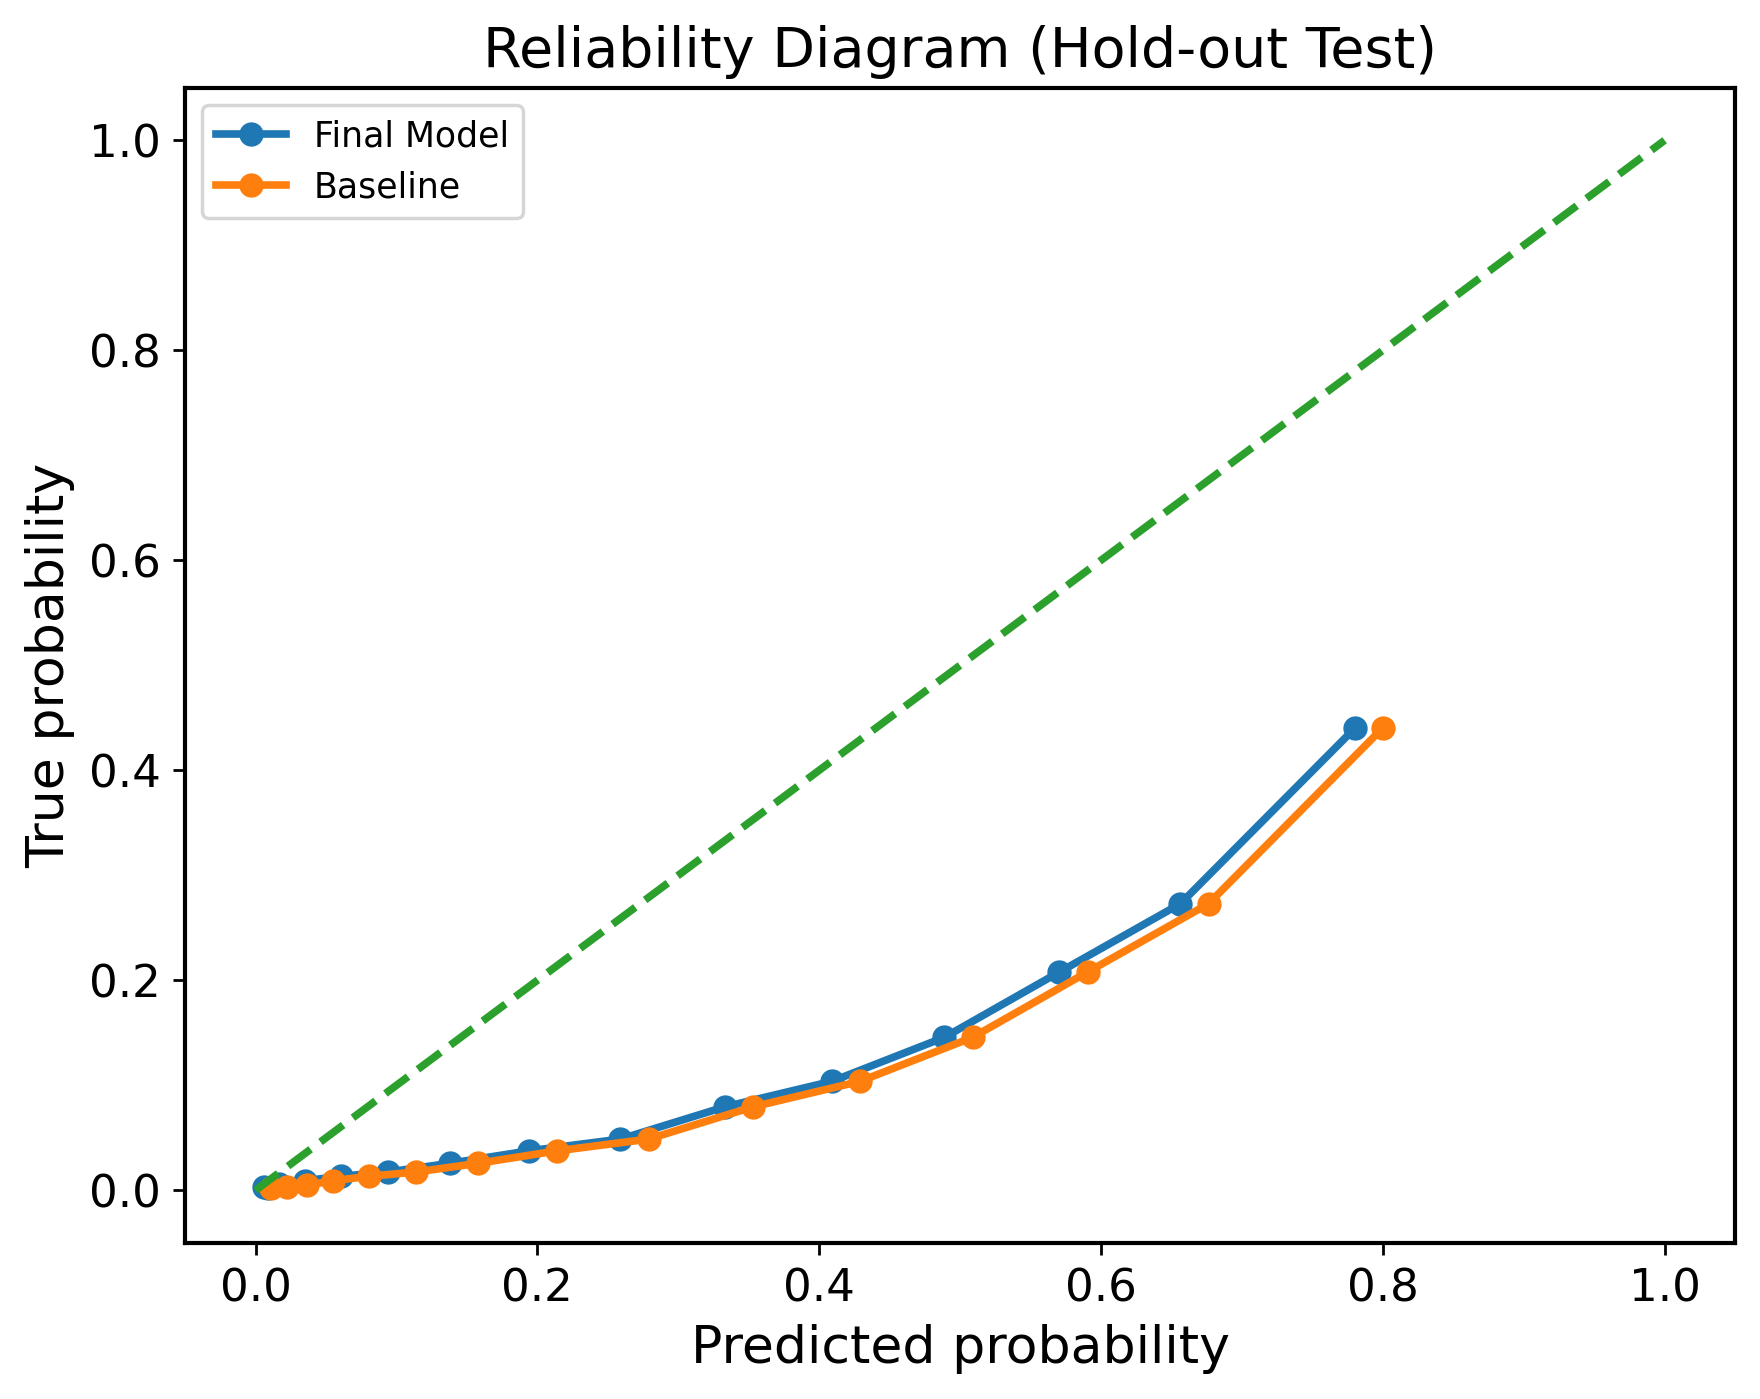

In [31]:
# ============================================================
# FIXED Calibration Module (Auto-detect version)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# Auto-detect model columns
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion_pred_raw",
    "TrustAwareResidualFusion",
    "RegularizedFusion_pred",
    "BestFusion_LightGBM_pred_raw",
], holdout_pred_df)

BASELINE_MODEL = find_column([
    "PerfWeightedEnsemble_pred",
    "MeanEnsemble_pred",
    "CatBoost_pred",
], holdout_pred_df)

if FINAL_MODEL is None:
    raise ValueError(f"Final model column not found. Available columns: {list(holdout_pred_df.columns)}")

if BASELINE_MODEL is None:
    raise ValueError("Baseline model column not found.")

print("Using FINAL model:", FINAL_MODEL)
print("Using BASELINE model:", BASELINE_MODEL)

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
y_true = np.asarray(y_test)

p_final = np.clip(holdout_pred_df[FINAL_MODEL].values, 1e-12, 1-1e-12)
p_base = np.clip(holdout_pred_df[BASELINE_MODEL].values, 1e-12, 1-1e-12)

# ------------------------------------------------------------
# Calibration curve
# ------------------------------------------------------------
def get_calibration_df(y, p, n_bins=15):
    prob_true, prob_pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
    return pd.DataFrame({
        "predicted_prob": prob_pred,
        "true_prob": prob_true
    })

cal_final = get_calibration_df(y_true, p_final)
cal_base = get_calibration_df(y_true, p_base)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure()

plt.plot(cal_final["predicted_prob"], cal_final["true_prob"], marker="o", label="Final Model")
plt.plot(cal_base["predicted_prob"], cal_base["true_prob"], marker="o", label="Baseline")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Reliability Diagram (Hold-out Test)")
plt.legend()

plt.savefig(os.path.join(TAB_DIR, "reliability_diagram.png"), dpi=300)
#plt.close()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def compute_calibration_metrics(y, p):
    p = np.clip(p, 1e-12, 1-1e-12)
    brier = np.mean((p - y)**2)
    nll = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

    bins = np.linspace(0, 1, 16)
    ece = 0.0

    for i in range(len(bins)-1):
        mask = (p >= bins[i]) & (p < bins[i+1])
        if mask.sum() == 0:
            continue
        acc = y[mask].mean()
        conf = p[mask].mean()
        ece += np.abs(acc - conf) * mask.mean()

    return brier, nll, ece

brier_f, nll_f, ece_f = compute_calibration_metrics(y_true, p_final)
brier_b, nll_b, ece_b = compute_calibration_metrics(y_true, p_base)

cal_summary = pd.DataFrame([
    ["FinalModel", brier_f, nll_f, ece_f],
    ["Baseline", brier_b, nll_b, ece_b]
], columns=["model", "Brier", "NLL", "ECE"])

print("\n===== Calibration Summary =====")
print(cal_summary)

In [32]:
# ============================================================
# Module — Selective Prediction / Risk-Aware Deployment
#
# Goal:
# - evaluate whether abstaining on high-uncertainty cases
#   improves retained-set performance
# - support human-in-the-loop referral analysis
#
# Inputs:
# - holdout_pred_df
# - y_test
#
# Outputs:
# - selective prediction table
# - referral summary
# - risk-coverage curve data
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_test", "TAB_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for selective prediction: {missing}")

if "holdout_pred_df" not in globals():
    raise ValueError("holdout_pred_df not found in memory.")

# ------------------------------------------------------------
# Auto-detect final and baseline columns
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
    "RegularizedFusion_pred",
    "BestFusion_LightGBM_pred_raw",
    "BestFusion_LightGBM_pred",
    "TRF_Backbone_pred",
], holdout_pred_df)

BASELINE_MODEL_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "MeanEnsemble_pred",
    "CatBoost_pred",
], holdout_pred_df)

if FINAL_MODEL_COL is None:
    raise ValueError(f"Could not find final model column. Available: {list(holdout_pred_df.columns)}")

if BASELINE_MODEL_COL is None:
    raise ValueError(f"Could not find baseline model column. Available: {list(holdout_pred_df.columns)}")

print("===== Selective Prediction Module =====")
print("Final model:", FINAL_MODEL_COL)
print("Baseline model:", BASELINE_MODEL_COL)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def to_pred_label(p, thr=0.5):
    return (clip_probs_local(p) >= thr).astype(int)

def compute_basic_metrics(y_true, p_pred, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs_local(p_pred)
    y_hat = to_pred_label(p_pred, thr=threshold)

    tp = np.sum((y_true == 1) & (y_hat == 1))
    fp = np.sum((y_true == 0) & (y_hat == 1))
    fn = np.sum((y_true == 1) & (y_hat == 0))
    tn = np.sum((y_true == 0) & (y_hat == 0))

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 0.0 if (precision + recall) == 0 else 2 * precision * recall / (precision + recall)
    acc = np.mean(y_true == y_hat)

    return {
        "n": int(len(y_true)),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "accuracy": float(acc),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }

def compute_uncertainty_score(p):
    # entropy-based uncertainty
    return entropy_binary(p)

# ------------------------------------------------------------
# Prepare dataframe
# ------------------------------------------------------------
sp_df = holdout_pred_df.copy()
sp_df["y_true"] = np.asarray(y_test).astype(int)

sp_df["final_p"] = clip_probs_local(sp_df[FINAL_MODEL_COL].values)
sp_df["baseline_p"] = clip_probs_local(sp_df[BASELINE_MODEL_COL].values)

sp_df["final_uncertainty"] = compute_uncertainty_score(sp_df["final_p"].values)
sp_df["baseline_uncertainty"] = compute_uncertainty_score(sp_df["baseline_p"].values)

# use thresholds learned on full hold-out for deployment-style summaries
final_threshold = 0.5
baseline_threshold = 0.5

sp_df["final_pred"] = to_pred_label(sp_df["final_p"].values, thr=final_threshold)
sp_df["baseline_pred"] = to_pred_label(sp_df["baseline_p"].values, thr=baseline_threshold)

sp_df["final_correct"] = (sp_df["final_pred"].values == sp_df["y_true"].values).astype(int)
sp_df["baseline_correct"] = (sp_df["baseline_pred"].values == sp_df["y_true"].values).astype(int)

# ------------------------------------------------------------
# Coverage schedule
# ------------------------------------------------------------
# Coverage = retained fraction after referring top uncertain cases
coverage_grid = [
    1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.55, 0.50
]

rows = []
for coverage in coverage_grid:
    retain_n = int(np.floor(len(sp_df) * coverage))
    retain_n = max(retain_n, 1)

    # retain least uncertain cases
    kept_idx_final = np.argsort(sp_df["final_uncertainty"].values)[:retain_n]
    kept_idx_base = np.argsort(sp_df["baseline_uncertainty"].values)[:retain_n]

    # final model retained-set metrics
    final_metrics = compute_basic_metrics(
        sp_df.iloc[kept_idx_final]["y_true"].values,
        sp_df.iloc[kept_idx_final]["final_p"].values,
        threshold=final_threshold
    )

    # baseline retained-set metrics
    base_metrics = compute_basic_metrics(
        sp_df.iloc[kept_idx_base]["y_true"].values,
        sp_df.iloc[kept_idx_base]["baseline_p"].values,
        threshold=baseline_threshold
    )

    rows.append({
        "coverage": float(coverage),
        "retained_n_final": int(retain_n),
        "retained_n_baseline": int(retain_n),

        "final_f1": final_metrics["f1"],
        "final_accuracy": final_metrics["accuracy"],
        "final_precision": final_metrics["precision"],
        "final_recall": final_metrics["recall"],

        "baseline_f1": base_metrics["f1"],
        "baseline_accuracy": base_metrics["accuracy"],
        "baseline_precision": base_metrics["precision"],
        "baseline_recall": base_metrics["recall"],
    })

selective_df = pd.DataFrame(rows)
selective_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_coverage_table.csv"), index=False)

# ------------------------------------------------------------
# Referral summary at key operating points
# ------------------------------------------------------------
key_coverages = [0.90, 0.80, 0.70]
referral_rows = []

for coverage in key_coverages:
    retain_n = int(np.floor(len(sp_df) * coverage))
    retain_n = max(retain_n, 1)

    kept_idx_final = np.argsort(sp_df["final_uncertainty"].values)[:retain_n]
    referred_idx_final = np.argsort(sp_df["final_uncertainty"].values)[retain_n:]

    kept_idx_base = np.argsort(sp_df["baseline_uncertainty"].values)[:retain_n]
    referred_idx_base = np.argsort(sp_df["baseline_uncertainty"].values)[retain_n:]

    final_kept_metrics = compute_basic_metrics(
        sp_df.iloc[kept_idx_final]["y_true"].values,
        sp_df.iloc[kept_idx_final]["final_p"].values,
        threshold=final_threshold
    )
    base_kept_metrics = compute_basic_metrics(
        sp_df.iloc[kept_idx_base]["y_true"].values,
        sp_df.iloc[kept_idx_base]["baseline_p"].values,
        threshold=baseline_threshold
    )

    referral_rows.append({
        "coverage": coverage,
        "referred_pct": 1.0 - coverage,

        "final_retained_f1": final_kept_metrics["f1"],
        "final_retained_accuracy": final_kept_metrics["accuracy"],
        "final_referred_pos_rate": float(sp_df.iloc[referred_idx_final]["y_true"].mean()) if len(referred_idx_final) > 0 else np.nan,
        "final_referred_mean_uncertainty": float(sp_df.iloc[referred_idx_final]["final_uncertainty"].mean()) if len(referred_idx_final) > 0 else np.nan,

        "baseline_retained_f1": base_kept_metrics["f1"],
        "baseline_retained_accuracy": base_kept_metrics["accuracy"],
        "baseline_referred_pos_rate": float(sp_df.iloc[referred_idx_base]["y_true"].mean()) if len(referred_idx_base) > 0 else np.nan,
        "baseline_referred_mean_uncertainty": float(sp_df.iloc[referred_idx_base]["baseline_uncertainty"].mean()) if len(referred_idx_base) > 0 else np.nan,
    })

referral_df = pd.DataFrame(referral_rows)
referral_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_referral_summary.csv"), index=False)

# ------------------------------------------------------------
# Hard-case enrichment analysis
# ------------------------------------------------------------
# Are referred cases actually harder / richer in positives?
hard_rows = []

for model_name, p_col, u_col in [
    ("FinalModel", "final_p", "final_uncertainty"),
    ("Baseline", "baseline_p", "baseline_uncertainty"),
]:
    thresh = np.quantile(sp_df[u_col].values, 0.90)
    hard_mask = sp_df[u_col].values >= thresh
    easy_mask = ~hard_mask

    hard_rows.append({
        "model": model_name,
        "group": "easy_90pct",
        "n": int(easy_mask.sum()),
        "pos_rate": float(sp_df.loc[easy_mask, "y_true"].mean()),
        "mean_prob": float(sp_df.loc[easy_mask, p_col].mean()),
        "mean_uncertainty": float(sp_df.loc[easy_mask, u_col].mean()),
        "accuracy": float(np.mean(to_pred_label(sp_df.loc[easy_mask, p_col].values, 0.5) == sp_df.loc[easy_mask, "y_true"].values)),
    })

    hard_rows.append({
        "model": model_name,
        "group": "hard_10pct",
        "n": int(hard_mask.sum()),
        "pos_rate": float(sp_df.loc[hard_mask, "y_true"].mean()),
        "mean_prob": float(sp_df.loc[hard_mask, p_col].mean()),
        "mean_uncertainty": float(sp_df.loc[hard_mask, u_col].mean()),
        "accuracy": float(np.mean(to_pred_label(sp_df.loc[hard_mask, p_col].values, 0.5) == sp_df.loc[hard_mask, "y_true"].values)),
    })

hard_case_df = pd.DataFrame(hard_rows)
hard_case_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_hard_case_analysis.csv"), index=False)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
meta = {
    "final_model_col": FINAL_MODEL_COL,
    "baseline_model_col": BASELINE_MODEL_COL,
    "coverage_grid": coverage_grid,
    "key_coverages": key_coverages,
    "n_test": int(len(sp_df)),
}
with open(os.path.join(LOG_DIR, "selective_prediction_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
print("\n===== Selective Prediction Coverage Table =====")
print(selective_df)

print("\n===== Referral Summary =====")
print(referral_df)

print("\n===== Hard-case Analysis =====")
print(hard_case_df)

print("\nSaved:")
print(" - selective_prediction_coverage_table.csv")
print(" - selective_prediction_referral_summary.csv")
print(" - selective_prediction_hard_case_analysis.csv")
print(" - selective_prediction_metadata.json")

===== Selective Prediction Module =====
Final model: TrustAwareResidualFusion_pred
Baseline model: PerfWeightedEnsemble_pred

===== Selective Prediction Coverage Table =====
    coverage  retained_n_final  retained_n_baseline  final_f1  final_accuracy  \
0       1.00             50736                50736  0.408067        0.811416   
1       0.95             48199                48199  0.428601        0.828067   
2       0.90             45662                45662  0.448989        0.844816   
3       0.85             43125                43125  0.466339        0.861588   
4       0.80             40588                40588  0.485342        0.878462   
5       0.75             38052                38052  0.505398        0.896457   
6       0.70             35515                35515  0.534304        0.915332   
7       0.65             32978                32978  0.556006        0.933653   
8       0.60             30441                30441  0.565571        0.949180   
9       0.55    

In [33]:
# ============================================================
# Module — Threshold-Aware Selective Prediction (ROBUST)
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_test", "TAB_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# ------------------------------------------------------------
# Find the prediction dataframe
# ------------------------------------------------------------
pred_df_candidates = []
if "holdout_pred_df" in globals():
    pred_df_candidates.append(("holdout_pred_df", holdout_pred_df.copy()))
if "final_holdout_pred_df" in globals():
    pred_df_candidates.append(("final_holdout_pred_df", final_holdout_pred_df.copy()))
if "pred_df" in globals():
    pred_df_candidates.append(("pred_df", pred_df.copy()))

if len(pred_df_candidates) == 0:
    raise ValueError("No prediction dataframe found in memory.")

# prefer one that contains TRF/final model columns
def score_df(df):
    cols = set(df.columns)
    score = 0
    for c in [
        "TrustAwareResidualFusion_pred",
        "TrustAwareResidualFusion",
        "TRF_Backbone_pred",
        "PerfWeightedEnsemble_pred",
        "MeanEnsemble_pred",
        "CatBoost_pred",
    ]:
        if c in cols:
            score += 1
    return score

pred_df_candidates = sorted(pred_df_candidates, key=lambda x: score_df(x[1]), reverse=True)
pred_df_name, df = pred_df_candidates[0]

print("Using prediction dataframe:", pred_df_name)
print("Available columns:")
print(sorted(df.columns))

# ------------------------------------------------------------
# Auto-detect model columns
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
    "RegularizedFusion_pred",
    "BestFusion_LightGBM_pred_raw",
    "BestFusion_LightGBM_pred",
    "TRF_Backbone_pred",   # fallback
], df)

BASELINE_MODEL_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "MeanEnsemble_pred",
    "CatBoost_pred",
    "TRF_Backbone_pred",   # fallback if backbone is baseline
], df)

if FINAL_MODEL_COL is None:
    raise ValueError(f"Final model column not found. Available columns: {list(df.columns)}")
if BASELINE_MODEL_COL is None:
    raise ValueError(f"Baseline model column not found. Available columns: {list(df.columns)}")

# avoid same column for both
if FINAL_MODEL_COL == BASELINE_MODEL_COL:
    alt_baseline = find_column(
        ["MeanEnsemble_pred", "CatBoost_pred", "PerfWeightedEnsemble_pred"],
        df
    )
    if alt_baseline is not None and alt_baseline != FINAL_MODEL_COL:
        BASELINE_MODEL_COL = alt_baseline

print("Final model:", FINAL_MODEL_COL)
print("Baseline model:", BASELINE_MODEL_COL)

# ------------------------------------------------------------
# Thresholds from your hold-out comparison
# Update only if you changed them later
# ------------------------------------------------------------
THRESHOLD_MAP = {
    "TrustAwareResidualFusion_pred": 0.572099,
    "TrustAwareResidualFusion": 0.572099,
    "TRF_Backbone_pred": 0.592099,
    "PerfWeightedEnsemble_pred": 0.592099,
    "MeanEnsemble_pred": 0.591301,
    "CatBoost_pred": 0.678042,
}

FINAL_THRESHOLD = THRESHOLD_MAP.get(FINAL_MODEL_COL, 0.5)
BASELINE_THRESHOLD = THRESHOLD_MAP.get(BASELINE_MODEL_COL, 0.5)

print("Final threshold:", FINAL_THRESHOLD)
print("Baseline threshold:", BASELINE_THRESHOLD)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip(p):
    return np.clip(np.asarray(p, float), EPS, 1 - EPS)

def entropy(p):
    p = clip(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def predict(p, thr):
    return (clip(p) >= thr).astype(int)

def metrics(y, p, thr):
    y = np.asarray(y).astype(int)
    y_hat = predict(p, thr)

    tp = np.sum((y == 1) & (y_hat == 1))
    fp = np.sum((y == 0) & (y_hat == 1))
    fn = np.sum((y == 1) & (y_hat == 0))
    tn = np.sum((y == 0) & (y_hat == 0))

    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
    acc = np.mean(y_hat == y)

    return prec, rec, f1, acc

# ------------------------------------------------------------
# Build working dataframe
# ------------------------------------------------------------
work_df = df.copy()
work_df["y"] = np.asarray(y_test).astype(int)

work_df["p_final"] = clip(work_df[FINAL_MODEL_COL].values)
work_df["p_base"] = clip(work_df[BASELINE_MODEL_COL].values)

work_df["u_final"] = entropy(work_df["p_final"].values)
work_df["u_base"] = entropy(work_df["p_base"].values)

# ------------------------------------------------------------
# Coverage evaluation
# ------------------------------------------------------------
coverage_grid = [1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60]
rows = []

for cov in coverage_grid:
    n_keep = int(len(work_df) * cov)
    n_keep = max(n_keep, 1)

    idx_f = np.argsort(work_df["u_final"].values)[:n_keep]
    idx_b = np.argsort(work_df["u_base"].values)[:n_keep]

    pf, rf, f1f, accf = metrics(work_df.iloc[idx_f]["y"], work_df.iloc[idx_f]["p_final"], FINAL_THRESHOLD)
    pb, rb, f1b, accb = metrics(work_df.iloc[idx_b]["y"], work_df.iloc[idx_b]["p_base"], BASELINE_THRESHOLD)

    rows.append({
        "coverage": cov,
        "retained_n": n_keep,
        "final_f1": f1f,
        "baseline_f1": f1b,
        "final_acc": accf,
        "baseline_acc": accb,
        "final_prec": pf,
        "baseline_prec": pb,
        "final_rec": rf,
        "baseline_rec": rb,
    })

cov_df = pd.DataFrame(rows)
cov_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_threshold_corrected.csv"), index=False)

# ------------------------------------------------------------
# Referral summary
# ------------------------------------------------------------
ref_rows = []
for cov in [0.90, 0.80, 0.70]:
    n_keep = int(len(work_df) * cov)
    n_keep = max(n_keep, 1)

    idx_f = np.argsort(work_df["u_final"].values)
    idx_b = np.argsort(work_df["u_base"].values)

    kept_f = idx_f[:n_keep]
    ref_f = idx_f[n_keep:]

    kept_b = idx_b[:n_keep]
    ref_b = idx_b[n_keep:]

    _, _, f1f, accf = metrics(work_df.iloc[kept_f]["y"], work_df.iloc[kept_f]["p_final"], FINAL_THRESHOLD)
    _, _, f1b, accb = metrics(work_df.iloc[kept_b]["y"], work_df.iloc[kept_b]["p_base"], BASELINE_THRESHOLD)

    ref_rows.append({
        "coverage": cov,
        "referred_pct": 1.0 - cov,
        "final_f1": f1f,
        "baseline_f1": f1b,
        "final_acc": accf,
        "baseline_acc": accb,
        "final_ref_pos_rate": float(work_df.iloc[ref_f]["y"].mean()) if len(ref_f) > 0 else np.nan,
        "baseline_ref_pos_rate": float(work_df.iloc[ref_b]["y"].mean()) if len(ref_b) > 0 else np.nan,
        "final_ref_mean_uncertainty": float(work_df.iloc[ref_f]["u_final"].mean()) if len(ref_f) > 0 else np.nan,
        "baseline_ref_mean_uncertainty": float(work_df.iloc[ref_b]["u_base"].mean()) if len(ref_b) > 0 else np.nan,
    })

ref_df = pd.DataFrame(ref_rows)
ref_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_referral_threshold_corrected.csv"), index=False)

print("\n===== Threshold-Aware Selective Prediction =====")
print(cov_df)

print("\n===== Referral Summary =====")
print(ref_df)

Using prediction dataframe: holdout_pred_df
Available columns:
['CatBoost_pred', 'DeepFM_pred', 'LightGBM_pred', 'LogReg_ElasticNet_pred', 'MLP_pred', 'MeanEnsemble_pred', 'PerfWeightedEnsemble_pred', 'TRF_Backbone_pred', 'TRF_delta_bounded', 'TrustAwareResidualFusion_pred', 'row_idx_test', 'y_true']
Final model: TrustAwareResidualFusion_pred
Baseline model: PerfWeightedEnsemble_pred
Final threshold: 0.572099
Baseline threshold: 0.592099

===== Threshold-Aware Selective Prediction =====
   coverage  retained_n  final_f1  baseline_f1  final_acc  baseline_acc  \
0      1.00       50736  0.424892     0.424892   0.850816      0.850816   
1      0.95       48199  0.437456     0.437012   0.850806      0.850536   
2      0.90       45662  0.451040     0.448904   0.850948      0.849656   
3      0.85       43125  0.466339     0.462493   0.861588      0.849299   
4      0.80       40588  0.485342     0.478969   0.878462      0.864492   
5      0.75       38052  0.505398     0.500112   0.896457 

In [35]:
# Merge TRF predictions into the main hold-out prediction dataframe
holdout_pred_df = holdout_pred_df.merge(
    pred_df[["row_idx_test", "TRF_Backbone_pred", "TrustAwareResidualFusion_pred"]],
    on="row_idx_test",
    how="left"
)

print(sorted(holdout_pred_df.columns))

import os
import numpy as np
import pandas as pd

required_vars = ["y_test", "TAB_DIR", "holdout_pred_df"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
], holdout_pred_df)

BASELINE_MODEL_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "TRF_Backbone_pred",
    "MeanEnsemble_pred",
    "CatBoost_pred",
], holdout_pred_df)

if FINAL_MODEL_COL is None or BASELINE_MODEL_COL is None:
    raise ValueError("Model columns not found after TRF merge.")

print("Final model:", FINAL_MODEL_COL)
print("Baseline model:", BASELINE_MODEL_COL)

THRESHOLD_MAP = {
    "TrustAwareResidualFusion_pred": 0.572099,
    "TRF_Backbone_pred": 0.592099,
    "PerfWeightedEnsemble_pred": 0.592099,
    "MeanEnsemble_pred": 0.591301,
    "CatBoost_pred": 0.678042,
}

FINAL_THRESHOLD = THRESHOLD_MAP.get(FINAL_MODEL_COL, 0.5)
BASELINE_THRESHOLD = THRESHOLD_MAP.get(BASELINE_MODEL_COL, 0.5)

print("Final threshold:", FINAL_THRESHOLD)
print("Baseline threshold:", BASELINE_THRESHOLD)

EPS = 1e-12

def clip(p):
    return np.clip(np.asarray(p, float), EPS, 1 - EPS)

def entropy(p):
    p = clip(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def predict(p, thr):
    return (clip(p) >= thr).astype(int)

def metrics(y, p, thr):
    y = np.asarray(y).astype(int)
    y_hat = predict(p, thr)

    tp = np.sum((y == 1) & (y_hat == 1))
    fp = np.sum((y == 0) & (y_hat == 1))
    fn = np.sum((y == 1) & (y_hat == 0))
    tn = np.sum((y == 0) & (y_hat == 0))

    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
    acc = np.mean(y_hat == y)

    return prec, rec, f1, acc

df = holdout_pred_df.copy()
df["y"] = np.asarray(y_test).astype(int)

df["p_final"] = clip(df[FINAL_MODEL_COL].values)
df["p_base"] = clip(df[BASELINE_MODEL_COL].values)

df["u_final"] = entropy(df["p_final"].values)
df["u_base"] = entropy(df["p_base"].values)

coverage_grid = [1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60]
rows = []

for cov in coverage_grid:
    n_keep = int(len(df) * cov)
    n_keep = max(n_keep, 1)

    idx_f = np.argsort(df["u_final"].values)[:n_keep]
    idx_b = np.argsort(df["u_base"].values)[:n_keep]

    pf, rf, f1f, accf = metrics(df.iloc[idx_f]["y"], df.iloc[idx_f]["p_final"], FINAL_THRESHOLD)
    pb, rb, f1b, accb = metrics(df.iloc[idx_b]["y"], df.iloc[idx_b]["p_base"], BASELINE_THRESHOLD)

    rows.append({
        "coverage": cov,
        "retained_n": n_keep,
        "final_f1": f1f,
        "baseline_f1": f1b,
        "final_acc": accf,
        "baseline_acc": accb,
        "final_prec": pf,
        "baseline_prec": pb,
        "final_rec": rf,
        "baseline_rec": rb,
    })

cov_df = pd.DataFrame(rows)
cov_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_threshold_corrected_trf.csv"), index=False)

ref_rows = []
for cov in [0.90, 0.80, 0.70]:
    n_keep = int(len(df) * cov)
    n_keep = max(n_keep, 1)

    idx_f = np.argsort(df["u_final"].values)
    idx_b = np.argsort(df["u_base"].values)

    kept_f = idx_f[:n_keep]
    ref_f = idx_f[n_keep:]

    kept_b = idx_b[:n_keep]
    ref_b = idx_b[n_keep:]

    _, _, f1f, accf = metrics(df.iloc[kept_f]["y"], df.iloc[kept_f]["p_final"], FINAL_THRESHOLD)
    _, _, f1b, accb = metrics(df.iloc[kept_b]["y"], df.iloc[kept_b]["p_base"], BASELINE_THRESHOLD)

    ref_rows.append({
        "coverage": cov,
        "referred_pct": 1.0 - cov,
        "final_f1": f1f,
        "baseline_f1": f1b,
        "final_acc": accf,
        "baseline_acc": accb,
        "final_ref_pos_rate": float(df.iloc[ref_f]["y"].mean()) if len(ref_f) > 0 else np.nan,
        "baseline_ref_pos_rate": float(df.iloc[ref_b]["y"].mean()) if len(ref_b) > 0 else np.nan,
        "final_ref_mean_uncertainty": float(df.iloc[ref_f]["u_final"].mean()) if len(ref_f) > 0 else np.nan,
        "baseline_ref_mean_uncertainty": float(df.iloc[ref_b]["u_base"].mean()) if len(ref_b) > 0 else np.nan,
    })

ref_df = pd.DataFrame(ref_rows)
ref_df.to_csv(os.path.join(TAB_DIR, "selective_prediction_referral_threshold_corrected_trf.csv"), index=False)

print("\n===== Threshold-Aware Selective Prediction (TRF) =====")
print(cov_df)

print("\n===== Referral Summary (TRF) =====")
print(ref_df)

['CatBoost_pred', 'DeepFM_pred', 'LightGBM_pred', 'LogReg_ElasticNet_pred', 'MLP_pred', 'MeanEnsemble_pred', 'PerfWeightedEnsemble_pred', 'TRF_Backbone_pred', 'TRF_Backbone_pred_x', 'TRF_Backbone_pred_y', 'TRF_delta_bounded', 'TrustAwareResidualFusion_pred', 'TrustAwareResidualFusion_pred_x', 'TrustAwareResidualFusion_pred_y', 'row_idx_test', 'y_true']
Final model: TrustAwareResidualFusion_pred
Baseline model: PerfWeightedEnsemble_pred
Final threshold: 0.572099
Baseline threshold: 0.592099

===== Threshold-Aware Selective Prediction (TRF) =====
   coverage  retained_n  final_f1  baseline_f1  final_acc  baseline_acc  \
0      1.00       50736  0.424892     0.424892   0.850816      0.850816   
1      0.95       48199  0.437456     0.437012   0.850806      0.850536   
2      0.90       45662  0.451040     0.448904   0.850948      0.849656   
3      0.85       43125  0.466339     0.462493   0.861588      0.849299   
4      0.80       40588  0.485342     0.478969   0.878462      0.864492   

In [36]:
# ============================================================
# Module — Fairness Evaluation on Held-Out Test
#
# Goal:
# - evaluate subgroup fairness of the FINAL model
# - compare against strong baselines
# - produce paper-ready fairness tables
#
# Models compared:
# - TrustAwareResidualFusion
# - PerfWeightedEnsemble
# - CatBoost
#
# Sensitive / subgroup attributes:
# - Sex
# - Age
#
# Outputs:
# - subgroup performance tables
# - fairness disparity summary tables
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_test", "y_test",
    "TAB_DIR", "LOG_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for fairness evaluation: {missing}")

# prediction dataframe detection
pred_df_candidates = []
if "holdout_pred_df" in globals():
    pred_df_candidates.append(("holdout_pred_df", holdout_pred_df.copy()))
if "final_holdout_pred_df" in globals():
    pred_df_candidates.append(("final_holdout_pred_df", final_holdout_pred_df.copy()))
if "pred_df" in globals():
    pred_df_candidates.append(("pred_df", pred_df.copy()))

if len(pred_df_candidates) == 0:
    raise ValueError("No prediction dataframe found in memory.")

def score_df(df):
    cols = set(df.columns)
    score = 0
    for c in [
        "TrustAwareResidualFusion_pred",
        "PerfWeightedEnsemble_pred",
        "CatBoost_pred",
        "TRF_Backbone_pred",
    ]:
        if c in cols:
            score += 1
    return score

pred_df_candidates = sorted(pred_df_candidates, key=lambda x: score_df(x[1]), reverse=True)
pred_df_name, fairness_pred_df = pred_df_candidates[0]

print("===== Fairness Evaluation Module =====")
print("Using prediction dataframe:", pred_df_name)
print("Available prediction columns:")
print(sorted(fairness_pred_df.columns))

# ------------------------------------------------------------
# Model columns
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
], fairness_pred_df)

BACKBONE_MODEL_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "TRF_Backbone_pred",
], fairness_pred_df)

CATBOOST_MODEL_COL = find_column([
    "CatBoost_pred",
], fairness_pred_df)

if FINAL_MODEL_COL is None:
    raise ValueError("Final TRF prediction column not found.")
if BACKBONE_MODEL_COL is None:
    raise ValueError("Backbone prediction column not found.")
if CATBOOST_MODEL_COL is None:
    raise ValueError("CatBoost prediction column not found.")

print("Final model   :", FINAL_MODEL_COL)
print("Backbone model:", BACKBONE_MODEL_COL)
print("CatBoost      :", CATBOOST_MODEL_COL)

# ------------------------------------------------------------
# Thresholds from locked hold-out comparison
# ------------------------------------------------------------
THRESHOLD_MAP = {
    "TrustAwareResidualFusion_pred": 0.572099,
    "TrustAwareResidualFusion": 0.572099,
    "PerfWeightedEnsemble_pred": 0.592099,
    "TRF_Backbone_pred": 0.592099,
    "MeanEnsemble_pred": 0.591301,
    "CatBoost_pred": 0.678042,
}

FINAL_THRESHOLD = THRESHOLD_MAP.get(FINAL_MODEL_COL, 0.5)
BACKBONE_THRESHOLD = THRESHOLD_MAP.get(BACKBONE_MODEL_COL, 0.5)
CATBOOST_THRESHOLD = THRESHOLD_MAP.get(CATBOOST_MODEL_COL, 0.5)

print("Thresholds:")
print("  Final   :", FINAL_THRESHOLD)
print("  Backbone:", BACKBONE_THRESHOLD)
print("  CatBoost:", CATBOOST_THRESHOLD)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def predict_with_threshold(p, thr):
    return (clip_probs_local(p) >= thr).astype(int)

def binary_confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fp, fn, tn

def compute_group_metrics(y_true, p_pred, thr):
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs_local(p_pred)
    y_hat = predict_with_threshold(p_pred, thr)

    tp, fp, fn, tn = binary_confusion_counts(y_true, y_hat)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)  # TPR
    fpr = fp / max(fp + tn, 1)
    tnr = tn / max(fp + tn, 1)
    fnr = fn / max(tp + fn, 1)
    pos_pred_rate = float(np.mean(y_hat))
    acc = float(np.mean(y_hat == y_true))

    # probability quality
    brier = float(np.mean((p_pred - y_true) ** 2))

    out = {
        "n": int(len(y_true)),
        "pos_rate": float(np.mean(y_true)),
        "mean_pred": float(np.mean(p_pred)),
        "positive_prediction_rate": float(pos_pred_rate),
        "precision": float(precision),
        "recall_tpr": float(recall),
        "fpr": float(fpr),
        "tnr": float(tnr),
        "fnr": float(fnr),
        "accuracy": float(acc),
        "brier": float(brier),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }
    return out

def make_age_band_from_brfss_age(age_series):
    """
    BRFSS Age coding:
    1: 18-24
    2: 25-29
    3: 30-34
    4: 35-39
    5: 40-44
    6: 45-49
    7: 50-54
    8: 55-59
    9: 60-64
    10: 65-69
    11: 70-74
    12: 75-79
    13: 80+
    """
    s = pd.to_numeric(age_series, errors="coerce")

    def map_band(v):
        if pd.isna(v):
            return np.nan
        v = int(v)
        if v <= 4:
            return "18-39"
        elif v <= 7:
            return "40-54"
        elif v <= 9:
            return "55-64"
        else:
            return "65+"

    return s.map(map_band)

def summarize_disparities(group_df):
    """
    group_df must contain one row per subgroup with metrics columns.
    Returns max-min gaps across groups.
    """
    numeric_cols = [
        "positive_prediction_rate",
        "precision",
        "recall_tpr",
        "fpr",
        "accuracy",
        "brier",
    ]
    out = {}
    for col in numeric_cols:
        vals = pd.to_numeric(group_df[col], errors="coerce").dropna().values
        if len(vals) == 0:
            out[f"{col}_gap"] = np.nan
        else:
            out[f"{col}_gap"] = float(np.max(vals) - np.min(vals))
    return out

# ------------------------------------------------------------
# Build working dataframe
# ------------------------------------------------------------
fair_df = X_test.copy().reset_index(drop=True)
fair_df["y_true"] = np.asarray(y_test).astype(int)

# attach predictions
fair_df[FINAL_MODEL_COL] = clip_probs_local(fairness_pred_df[FINAL_MODEL_COL].values)
fair_df[BACKBONE_MODEL_COL] = clip_probs_local(fairness_pred_df[BACKBONE_MODEL_COL].values)
fair_df[CATBOOST_MODEL_COL] = clip_probs_local(fairness_pred_df[CATBOOST_MODEL_COL].values)

# create usable subgroup fields
if "Sex" not in fair_df.columns:
    raise ValueError("X_test does not contain 'Sex'.")
if "Age" not in fair_df.columns:
    raise ValueError("X_test does not contain 'Age'.")

fair_df["Sex_label"] = fair_df["Sex"].map({0: "Female", 1: "Male"}).fillna("Unknown")
fair_df["Age_band"] = make_age_band_from_brfss_age(fair_df["Age"])

# ------------------------------------------------------------
# Main fairness evaluation function
# ------------------------------------------------------------
def evaluate_fairness_for_attribute(df, attr_col, model_name, pred_col, threshold):
    subgroup_rows = []

    for group_val, sub_df in df.groupby(attr_col, dropna=False):
        if len(sub_df) < 30:
            continue

        metrics = compute_group_metrics(
            y_true=sub_df["y_true"].values,
            p_pred=sub_df[pred_col].values,
            thr=threshold
        )
        row = {
            "attribute": attr_col,
            "group": str(group_val),
            "model": model_name,
        }
        row.update(metrics)
        subgroup_rows.append(row)

    subgroup_df = pd.DataFrame(subgroup_rows)

    disparity_row = {
        "attribute": attr_col,
        "model": model_name,
    }
    disparity_row.update(summarize_disparities(subgroup_df))
    disparity_df = pd.DataFrame([disparity_row])

    return subgroup_df, disparity_df

# ------------------------------------------------------------
# Evaluate models across Sex and Age_band
# ------------------------------------------------------------
all_group_tables = []
all_disparity_tables = []

model_specs = [
    ("TrustAwareResidualFusion", FINAL_MODEL_COL, FINAL_THRESHOLD),
    ("PerfWeightedEnsemble", BACKBONE_MODEL_COL, BACKBONE_THRESHOLD),
    ("CatBoost", CATBOOST_MODEL_COL, CATBOOST_THRESHOLD),
]

attributes_to_eval = ["Sex_label", "Age_band"]

for model_name, pred_col, thr in model_specs:
    for attr in attributes_to_eval:
        subgroup_df, disparity_df = evaluate_fairness_for_attribute(
            df=fair_df,
            attr_col=attr,
            model_name=model_name,
            pred_col=pred_col,
            threshold=thr
        )
        all_group_tables.append(subgroup_df)
        all_disparity_tables.append(disparity_df)

fairness_group_table = pd.concat(all_group_tables, axis=0, ignore_index=True)
fairness_disparity_table = pd.concat(all_disparity_tables, axis=0, ignore_index=True)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------
fairness_group_table.to_csv(
    os.path.join(TAB_DIR, "fairness_group_performance_table.csv"),
    index=False
)

fairness_disparity_table.to_csv(
    os.path.join(TAB_DIR, "fairness_disparity_summary_table.csv"),
    index=False
)

fairness_meta = {
    "prediction_dataframe_used": pred_df_name,
    "final_model_col": FINAL_MODEL_COL,
    "backbone_model_col": BACKBONE_MODEL_COL,
    "catboost_model_col": CATBOOST_MODEL_COL,
    "thresholds": {
        "final": FINAL_THRESHOLD,
        "backbone": BACKBONE_THRESHOLD,
        "catboost": CATBOOST_THRESHOLD,
    },
    "attributes_evaluated": attributes_to_eval,
}
with open(os.path.join(LOG_DIR, "fairness_evaluation_metadata.json"), "w") as f:
    json.dump(fairness_meta, f, indent=2)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
print("\n===== Fairness Group Performance Table =====")
print(fairness_group_table)

print("\n===== Fairness Disparity Summary Table =====")
print(fairness_disparity_table)

print("\nSaved:")
print(" - fairness_group_performance_table.csv")
print(" - fairness_disparity_summary_table.csv")
print(" - fairness_evaluation_metadata.json")

===== Fairness Evaluation Module =====
Using prediction dataframe: holdout_pred_df
Available prediction columns:
['CatBoost_pred', 'DeepFM_pred', 'LightGBM_pred', 'LogReg_ElasticNet_pred', 'MLP_pred', 'MeanEnsemble_pred', 'PerfWeightedEnsemble_pred', 'TRF_Backbone_pred', 'TRF_Backbone_pred_x', 'TRF_Backbone_pred_y', 'TRF_delta_bounded', 'TrustAwareResidualFusion_pred', 'TrustAwareResidualFusion_pred_x', 'TrustAwareResidualFusion_pred_y', 'row_idx_test', 'y_true']
Final model   : TrustAwareResidualFusion_pred
Backbone model: PerfWeightedEnsemble_pred
CatBoost      : CatBoost_pred
Thresholds:
  Final   : 0.572099
  Backbone: 0.592099
  CatBoost: 0.678042

===== Fairness Group Performance Table =====
    attribute   group                     model      n  pos_rate  mean_pred  \
0   Sex_label  Female  TrustAwareResidualFusion  28300  0.072473   0.222174   
1   Sex_label    Male  TrustAwareResidualFusion  22436  0.121590   0.330426   
2    Age_band   18-39  TrustAwareResidualFusion   7729  

In [38]:
# ============================================================
# Module — Fairness-Aware Threshold Optimization (FIXED)
#
# Fix:
# - reconstructs development-side TRF predictions from OOF experts
# - does not expect TRF dev predictions to already exist in oof_df
# ============================================================

import os
import json
import itertools
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_dev", "y_dev", "X_test", "y_test",
    "oof_df", "baseline_df",
    "TAB_DIR", "LOG_DIR"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

# hold-out predictions
pred_test_candidates = []
if "holdout_pred_df" in globals():
    pred_test_candidates.append(("holdout_pred_df", holdout_pred_df.copy()))
if "final_holdout_pred_df" in globals():
    pred_test_candidates.append(("final_holdout_pred_df", final_holdout_pred_df.copy()))

if len(pred_test_candidates) == 0:
    raise ValueError("No hold-out prediction dataframe found.")

test_pred_name, test_pred_df = pred_test_candidates[0]

print("===== Fairness-Aware Threshold Optimization (FIXED) =====")
print("Development source: oof_df")
print("Hold-out source   :", test_pred_name)

# ------------------------------------------------------------
# Locked final config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few final experts in oof_df: {FINAL_EXPERTS}")

TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02

# ------------------------------------------------------------
# Column detection on hold-out
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

TEST_FINAL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
], test_pred_df)

TEST_BASE_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "TRF_Backbone_pred",
], test_pred_df)

if TEST_FINAL_COL is None:
    raise ValueError("Could not find hold-out TRF prediction column.")
if TEST_BASE_COL is None:
    raise ValueError("Could not find hold-out backbone prediction column.")

print("Hold-out final column:", TEST_FINAL_COL)
print("Hold-out base column :", TEST_BASE_COL)

# ------------------------------------------------------------
# Thresholds
# ------------------------------------------------------------
GLOBAL_THR_FINAL_DEV = 0.5686177430287273   # locked dev TRF threshold
GLOBAL_THR_FINAL_TEST = 0.572099            # locked hold-out TRF threshold
GLOBAL_THR_BASE_DEV = 0.592099
GLOBAL_THR_BASE_TEST = 0.592099

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def predict_threshold(p, thr):
    return (clip_probs_local(p) >= float(thr)).astype(int)

def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fp, fn, tn

def group_metrics(y_true, p_pred, thr):
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs_local(p_pred)
    y_hat = predict_threshold(p_pred, thr)
    tp, fp, fn, tn = confusion_counts(y_true, y_hat)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    acc = np.mean(y_hat == y_true)
    pos_pred_rate = np.mean(y_hat)

    return {
        "precision": float(precision),
        "recall_tpr": float(recall),
        "fpr": float(fpr),
        "accuracy": float(acc),
        "positive_prediction_rate": float(pos_pred_rate),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn
    }

def overall_metrics_from_predictions(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp, fp, fn, tn = confusion_counts(y_true, y_pred)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 0.0 if (precision + recall) == 0 else 2.0 * precision * recall / (precision + recall)
    acc = np.mean(y_pred == y_true)

    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "accuracy": float(acc),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn
    }

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"
    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

def make_age_band_from_brfss_age(age_series):
    s = pd.to_numeric(age_series, errors="coerce")

    def map_band(v):
        if pd.isna(v):
            return np.nan
        v = int(v)
        if v <= 4:
            return "18-39"
        elif v <= 7:
            return "40-54"
        elif v <= 9:
            return "55-64"
        else:
            return "65+"
    return s.map(map_band)

def apply_group_thresholds(df, group_col, pred_col, thresholds_by_group, fallback_threshold):
    y_hat = np.zeros(len(df), dtype=int)
    for i, (_, row) in enumerate(df.iterrows()):
        g = row[group_col]
        thr = thresholds_by_group.get(g, fallback_threshold)
        y_hat[i] = int(float(row[pred_col]) >= float(thr))
    return y_hat

def disparity_summary_for_thresholds(df, group_col, pred_col, thresholds_by_group):
    rows = []
    for g, sub in df.groupby(group_col, dropna=False):
        if g not in thresholds_by_group:
            continue
        thr = thresholds_by_group[g]
        m = group_metrics(sub["y_true"].values, sub[pred_col].values, thr)
        rows.append({
            "group": str(g),
            "n": int(len(sub)),
            "threshold": float(thr),
            **m
        })
    out = pd.DataFrame(rows)
    if len(out) == 0:
        return out, {}
    gap = {
        "precision_gap": float(out["precision"].max() - out["precision"].min()),
        "recall_tpr_gap": float(out["recall_tpr"].max() - out["recall_tpr"].min()),
        "fpr_gap": float(out["fpr"].max() - out["fpr"].min()),
        "accuracy_gap": float(out["accuracy"].max() - out["accuracy"].min()),
        "positive_prediction_rate_gap": float(out["positive_prediction_rate"].max() - out["positive_prediction_rate"].min()),
    }
    return out, gap

# ------------------------------------------------------------
# Reconstruct development backbone and TRF predictions
# ------------------------------------------------------------
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_dev_cols = [c for c in required_dev_cols if c not in oof_df.columns]
if missing_dev_cols:
    raise ValueError(f"Missing required OOF columns: {missing_dev_cols}")

perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
backbone_weights = np.array([perf_map[m] for m in FINAL_EXPERTS], dtype=float)
backbone_weights = backbone_weights / backbone_weights.sum()

dev_expert_df = oof_df[required_dev_cols].copy()
P_dev = dev_expert_df[FINAL_EXPERTS].values.astype(float)
P_dev = np.clip(P_dev, EPS, 1.0 - EPS)

dev_backbone_pred = clip_probs_local(np.sum(P_dev * backbone_weights.reshape(1, -1), axis=1))

dev_trust_df = build_trust_feature_table(dev_expert_df, FINAL_EXPERTS)
X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

y_dev_arr = dev_trust_df["y_true"].astype(int).values
residual_target = y_dev_arr.astype(float) - dev_backbone_pred.astype(float)

trf_model = Ridge(alpha=TRF_ALPHA)
trf_model.fit(X_dev_trf, residual_target)

dev_delta_raw = trf_model.predict(X_dev_trf)
dev_trf_pred, dev_trf_delta = bounded_correct(dev_backbone_pred, dev_delta_raw, TRF_DELTA_MAX)

# ------------------------------------------------------------
# Build fairness dataframes
# ------------------------------------------------------------
fair_dev = X_dev.copy().reset_index(drop=True)
fair_dev["y_true"] = np.asarray(y_dev).astype(int)
fair_dev["TRF_dev_pred"] = dev_trf_pred
fair_dev["Backbone_dev_pred"] = dev_backbone_pred

if "Sex" not in fair_dev.columns or "Age" not in fair_dev.columns:
    raise ValueError("X_dev must contain Sex and Age.")

fair_dev["Sex_label"] = fair_dev["Sex"].map({0: "Female", 1: "Male"}).fillna("Unknown")
fair_dev["Age_band"] = make_age_band_from_brfss_age(fair_dev["Age"])

fair_test = X_test.copy().reset_index(drop=True)
fair_test["y_true"] = np.asarray(y_test).astype(int)
fair_test["TRF_test_pred"] = clip_probs_local(test_pred_df[TEST_FINAL_COL].values)
fair_test["Backbone_test_pred"] = clip_probs_local(test_pred_df[TEST_BASE_COL].values)

if "Sex" not in fair_test.columns or "Age" not in fair_test.columns:
    raise ValueError("X_test must contain Sex and Age.")

fair_test["Sex_label"] = fair_test["Sex"].map({0: "Female", 1: "Male"}).fillna("Unknown")
fair_test["Age_band"] = make_age_band_from_brfss_age(fair_test["Age"])

# ------------------------------------------------------------
# Optimize subgroup-specific thresholds on development
# ------------------------------------------------------------
LAMBDA_GAP = 0.05
LAMBDA_DRIFT = 0.02

def optimize_group_thresholds(dev_df, group_col, pred_col, global_thr, grid_offsets):
    groups = sorted([g for g in dev_df[group_col].dropna().unique().tolist()])
    candidate_lists = [[float(global_thr + off) for off in grid_offsets] for _ in groups]

    best_score = -np.inf
    best_pack = None

    for combo in itertools.product(*candidate_lists):
        thr_map = {g: float(t) for g, t in zip(groups, combo)}

        y_hat = apply_group_thresholds(
            df=dev_df,
            group_col=group_col,
            pred_col=pred_col,
            thresholds_by_group=thr_map,
            fallback_threshold=global_thr
        )
        overall = overall_metrics_from_predictions(dev_df["y_true"].values, y_hat)
        sub_table, gaps = disparity_summary_for_thresholds(
            df=dev_df,
            group_col=group_col,
            pred_col=pred_col,
            thresholds_by_group=thr_map
        )

        tpr_gap = gaps.get("recall_tpr_gap", np.nan)
        mean_shift = float(np.mean([abs(thr_map[g] - global_thr) for g in groups]))
        score = overall["f1"] - LAMBDA_GAP * tpr_gap - LAMBDA_DRIFT * mean_shift

        if score > best_score:
            best_score = score
            best_pack = {
                "group_col": group_col,
                "thresholds": thr_map,
                "overall_dev": overall,
                "subgroup_dev": sub_table.copy(),
                "gaps_dev": gaps.copy(),
                "score": float(score),
            }
    return best_pack

print("\nOptimizing Sex thresholds...")
best_sex_pack = optimize_group_thresholds(
    dev_df=fair_dev,
    group_col="Sex_label",
    pred_col="TRF_dev_pred",
    global_thr=GLOBAL_THR_FINAL_DEV,
    grid_offsets=[-0.06, -0.03, 0.0, 0.03, 0.06]
)

print("Best Sex thresholds:", best_sex_pack["thresholds"])
print("Best Sex dev gaps:", best_sex_pack["gaps_dev"])
print("Best Sex dev overall:", best_sex_pack["overall_dev"])

print("\nOptimizing Age thresholds...")
best_age_pack = optimize_group_thresholds(
    dev_df=fair_dev,
    group_col="Age_band",
    pred_col="TRF_dev_pred",
    global_thr=GLOBAL_THR_FINAL_DEV,
    grid_offsets=[-0.08, -0.04, 0.0, 0.04, 0.08]
)

print("Best Age thresholds:", best_age_pack["thresholds"])
print("Best Age dev gaps:", best_age_pack["gaps_dev"])
print("Best Age dev overall:", best_age_pack["overall_dev"])

# ------------------------------------------------------------
# Evaluate on untouched hold-out
# ------------------------------------------------------------
def evaluate_on_test_with_group_thresholds(test_df, group_col, pred_col, global_thr, opt_pack, model_label):
    thresholds = opt_pack["thresholds"]

    y_hat_fair = apply_group_thresholds(
        df=test_df,
        group_col=group_col,
        pred_col=pred_col,
        thresholds_by_group=thresholds,
        fallback_threshold=global_thr
    )
    y_hat_global = predict_threshold(test_df[pred_col].values, global_thr)

    overall_fair = overall_metrics_from_predictions(test_df["y_true"].values, y_hat_fair)
    overall_global = overall_metrics_from_predictions(test_df["y_true"].values, y_hat_global)

    subgroup_rows = []
    for setting_name, use_fair in [("global_threshold", False), ("fairness_aware", True)]:
        for g, sub in test_df.groupby(group_col, dropna=False):
            if len(sub) < 30:
                continue
            thr = thresholds.get(g, global_thr) if use_fair else global_thr
            m = group_metrics(sub["y_true"].values, sub[pred_col].values, thr)
            subgroup_rows.append({
                "attribute": group_col,
                "group": str(g),
                "model": model_label,
                "setting": setting_name,
                "threshold": float(thr),
                **m
            })

    subgroup_df = pd.DataFrame(subgroup_rows)

    def gaps_for_setting(df_sub, setting_name):
        tmp = df_sub[df_sub["setting"] == setting_name].copy()
        return {
            "precision_gap": float(tmp["precision"].max() - tmp["precision"].min()),
            "recall_tpr_gap": float(tmp["recall_tpr"].max() - tmp["recall_tpr"].min()),
            "fpr_gap": float(tmp["fpr"].max() - tmp["fpr"].min()),
            "accuracy_gap": float(tmp["accuracy"].max() - tmp["accuracy"].min()),
            "positive_prediction_rate_gap": float(tmp["positive_prediction_rate"].max() - tmp["positive_prediction_rate"].min()),
        }

    global_gap = gaps_for_setting(subgroup_df, "global_threshold")
    fair_gap = gaps_for_setting(subgroup_df, "fairness_aware")

    summary_df = pd.DataFrame([
        {
            "attribute": group_col,
            "model": model_label,
            "setting": "global_threshold",
            **overall_global,
            **global_gap
        },
        {
            "attribute": group_col,
            "model": model_label,
            "setting": "fairness_aware",
            **overall_fair,
            **fair_gap
        }
    ])

    return subgroup_df, summary_df

sex_subgroup_test_df, sex_summary_df = evaluate_on_test_with_group_thresholds(
    test_df=fair_test,
    group_col="Sex_label",
    pred_col="TRF_test_pred",
    global_thr=GLOBAL_THR_FINAL_TEST,
    opt_pack=best_sex_pack,
    model_label="TrustAwareResidualFusion"
)

age_subgroup_test_df, age_summary_df = evaluate_on_test_with_group_thresholds(
    test_df=fair_test,
    group_col="Age_band",
    pred_col="TRF_test_pred",
    global_thr=GLOBAL_THR_FINAL_TEST,
    opt_pack=best_age_pack,
    model_label="TrustAwareResidualFusion"
)

fair_threshold_group_table = pd.concat(
    [sex_subgroup_test_df, age_subgroup_test_df],
    axis=0, ignore_index=True
)

fair_threshold_summary_table = pd.concat(
    [sex_summary_df, age_summary_df],
    axis=0, ignore_index=True
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
fair_threshold_group_table.to_csv(
    os.path.join(TAB_DIR, "fairness_threshold_group_table.csv"),
    index=False
)

fair_threshold_summary_table.to_csv(
    os.path.join(TAB_DIR, "fairness_threshold_summary_table.csv"),
    index=False
)

meta = {
    "development_source": "reconstructed_from_oof_df",
    "holdout_source": test_pred_name,
    "final_experts": FINAL_EXPERTS,
    "trf_alpha": TRF_ALPHA,
    "trf_delta_max": TRF_DELTA_MAX,
    "global_threshold_dev": GLOBAL_THR_FINAL_DEV,
    "global_threshold_test": GLOBAL_THR_FINAL_TEST,
    "best_sex_thresholds": best_sex_pack["thresholds"],
    "best_age_thresholds": best_age_pack["thresholds"],
}
with open(os.path.join(LOG_DIR, "fairness_threshold_optimization_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

print("\n===== Fairness-Aware Threshold Optimization Summary =====")
print(fair_threshold_summary_table)

print("\n===== Fairness-Aware Group Table =====")
print(fair_threshold_group_table)

print("\nSaved:")
print(" - fairness_threshold_group_table.csv")
print(" - fairness_threshold_summary_table.csv")
print(" - fairness_threshold_optimization_metadata.json")

===== Fairness-Aware Threshold Optimization (FIXED) =====
Development source: oof_df
Hold-out source   : holdout_pred_df
Hold-out final column: TrustAwareResidualFusion_pred
Hold-out base column : PerfWeightedEnsemble_pred

Optimizing Sex thresholds...
Best Sex thresholds: {'Female': 0.5386177430287272, 'Male': 0.6286177430287272}
Best Sex dev gaps: {'precision_gap': 0.09058248150329823, 'recall_tpr_gap': 0.006381042665907555, 'fpr_gap': 0.021742632627136826, 'accuracy_gap': 0.03725111781680712, 'positive_prediction_rate_gap': 0.04198540876441961}
Best Sex dev overall: {'precision': 0.34244739311084305, 'recall': 0.5346866171392697, 'f1': 0.4175007148984844, 'accuracy': 0.859478476821192, 'tp': 10220, 'fp': 19624, 'fn': 8894, 'tn': 164206}

Optimizing Age thresholds...


KeyboardInterrupt: 

In [39]:
# ============================================================
# FAST Fairness-Aware Threshold Optimization
# - optimize only Sex first
# - tiny threshold grid
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

required_vars = ["X_dev", "y_dev", "X_test", "y_test", "oof_df", "baseline_df", "holdout_pred_df", "TAB_DIR", "LOG_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}")

EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def predict_threshold(p, thr):
    return (clip_probs_local(p) >= float(thr)).astype(int)

def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fp, fn, tn

def group_metrics(y_true, p_pred, thr):
    y_hat = predict_threshold(p_pred, thr)
    tp, fp, fn, tn = confusion_counts(y_true, y_hat)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    acc = np.mean(y_hat == np.asarray(y_true).astype(int))
    return {
        "precision": float(precision),
        "recall_tpr": float(recall),
        "fpr": float(fpr),
        "accuracy": float(acc),
        "positive_prediction_rate": float(np.mean(y_hat)),
    }

def overall_metrics(y_true, y_pred):
    tp, fp, fn, tn = confusion_counts(y_true, y_pred)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    acc = np.mean(np.asarray(y_true).astype(int) == np.asarray(y_pred).astype(int))
    return {"precision": precision, "recall": recall, "f1": f1, "accuracy": acc}

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"
    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = np.clip(df[expert_cols].values.astype(float), EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

# locked config
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]
TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02
GLOBAL_THR_DEV = 0.5686177430287273
GLOBAL_THR_TEST = 0.572099

# reconstruct dev TRF predictions
perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
weights = np.array([perf_map[m] for m in FINAL_EXPERTS], dtype=float)
weights = weights / weights.sum()

dev_expert_df = oof_df[["row_idx_dev", "y_true"] + FINAL_EXPERTS].copy()
P_dev = np.clip(dev_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
dev_backbone = clip_probs_local(np.sum(P_dev * weights.reshape(1, -1), axis=1))

dev_trust_df = build_trust_feature_table(dev_expert_df, FINAL_EXPERTS)
X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

trf_model = Ridge(alpha=TRF_ALPHA)
trf_model.fit(X_dev_trf, y_dev.astype(float) - dev_backbone)
dev_trf_pred, _ = bounded_correct(dev_backbone, trf_model.predict(X_dev_trf), TRF_DELTA_MAX)

# build dev/test fairness dfs
fair_dev = X_dev.copy().reset_index(drop=True)
fair_dev["y_true"] = np.asarray(y_dev).astype(int)
fair_dev["TRF_dev_pred"] = dev_trf_pred
fair_dev["Sex_label"] = fair_dev["Sex"].map({0: "Female", 1: "Male"}).fillna("Unknown")

fair_test = X_test.copy().reset_index(drop=True)
fair_test["y_true"] = np.asarray(y_test).astype(int)
fair_test["TRF_test_pred"] = clip_probs_local(holdout_pred_df["TrustAwareResidualFusion_pred"].values)
fair_test["Sex_label"] = fair_test["Sex"].map({0: "Female", 1: "Male"}).fillna("Unknown")

# fast optimization over Sex only
sex_groups = sorted(fair_dev["Sex_label"].dropna().unique().tolist())
grid = [GLOBAL_THR_DEV - 0.03, GLOBAL_THR_DEV, GLOBAL_THR_DEV + 0.03]

best = None
best_score = -1e18

for t_female in grid:
    for t_male in grid:
        thr_map = {"Female": float(t_female), "Male": float(t_male), "Unknown": GLOBAL_THR_DEV}

        y_hat = np.zeros(len(fair_dev), dtype=int)
        for i, (_, row) in enumerate(fair_dev.iterrows()):
            thr = thr_map.get(row["Sex_label"], GLOBAL_THR_DEV)
            y_hat[i] = int(float(row["TRF_dev_pred"]) >= thr)

        overall = overall_metrics(fair_dev["y_true"].values, y_hat)

        sex_rows = []
        for g, sub in fair_dev.groupby("Sex_label"):
            thr = thr_map[g]
            m = group_metrics(sub["y_true"].values, sub["TRF_dev_pred"].values, thr)
            sex_rows.append({"group": g, **m})
        sex_df = pd.DataFrame(sex_rows)

        tpr_gap = float(sex_df["recall_tpr"].max() - sex_df["recall_tpr"].min())
        fpr_gap = float(sex_df["fpr"].max() - sex_df["fpr"].min())
        mean_shift = np.mean([abs(thr_map[g] - GLOBAL_THR_DEV) for g in ["Female", "Male"]])

        score = overall["f1"] - 0.05 * tpr_gap - 0.02 * fpr_gap - 0.02 * mean_shift

        if score > best_score:
            best_score = score
            best = {
                "thresholds": thr_map,
                "overall_dev": overall,
                "sex_dev": sex_df.copy(),
                "tpr_gap_dev": tpr_gap,
                "fpr_gap_dev": fpr_gap,
                "score": score,
            }

print("Best Sex thresholds:", best["thresholds"])
print("Best dev overall:", best["overall_dev"])
print("Best dev TPR gap:", best["tpr_gap_dev"])
print("Best dev FPR gap:", best["fpr_gap_dev"])

# evaluate on hold-out
thr_map = best["thresholds"]

y_hat_global = predict_threshold(fair_test["TRF_test_pred"].values, GLOBAL_THR_TEST)

y_hat_fair = np.zeros(len(fair_test), dtype=int)
for i, (_, row) in enumerate(fair_test.iterrows()):
    thr = thr_map.get(row["Sex_label"], GLOBAL_THR_TEST)
    y_hat_fair[i] = int(float(row["TRF_test_pred"]) >= thr)

global_overall = overall_metrics(fair_test["y_true"].values, y_hat_global)
fair_overall = overall_metrics(fair_test["y_true"].values, y_hat_fair)

sex_rows = []
for setting_name, preds in [("global_threshold", y_hat_global), ("fairness_aware", y_hat_fair)]:
    for g, sub in fair_test.groupby("Sex_label"):
        sub_idx = sub.index.values
        thr = GLOBAL_THR_TEST if setting_name == "global_threshold" else thr_map.get(g, GLOBAL_THR_TEST)
        m = group_metrics(sub["y_true"].values, sub["TRF_test_pred"].values, thr)
        sex_rows.append({
            "attribute": "Sex_label",
            "group": g,
            "setting": setting_name,
            "threshold": float(thr),
            **m
        })

sex_test_df = pd.DataFrame(sex_rows)

def gaps(df, setting):
    tmp = df[df["setting"] == setting].copy()
    return {
        "precision_gap": float(tmp["precision"].max() - tmp["precision"].min()),
        "recall_tpr_gap": float(tmp["recall_tpr"].max() - tmp["recall_tpr"].min()),
        "fpr_gap": float(tmp["fpr"].max() - tmp["fpr"].min()),
        "accuracy_gap": float(tmp["accuracy"].max() - tmp["accuracy"].min()),
        "positive_prediction_rate_gap": float(tmp["positive_prediction_rate"].max() - tmp["positive_prediction_rate"].min()),
    }

global_gap = gaps(sex_test_df, "global_threshold")
fair_gap = gaps(sex_test_df, "fairness_aware")

summary_df = pd.DataFrame([
    {"attribute": "Sex_label", "setting": "global_threshold", **global_overall, **global_gap},
    {"attribute": "Sex_label", "setting": "fairness_aware", **fair_overall, **fair_gap},
])

sex_test_df.to_csv(os.path.join(TAB_DIR, "fairness_threshold_group_table_fast.csv"), index=False)
summary_df.to_csv(os.path.join(TAB_DIR, "fairness_threshold_summary_table_fast.csv"), index=False)

with open(os.path.join(LOG_DIR, "fairness_threshold_optimization_metadata_fast.json"), "w") as f:
    json.dump({
        "best_sex_thresholds": best["thresholds"],
        "global_thr_dev": GLOBAL_THR_DEV,
        "global_thr_test": GLOBAL_THR_TEST,
    }, f, indent=2)

print("\n===== FAST Fairness Threshold Summary =====")
print(summary_df)

print("\n===== FAST Fairness Group Table =====")
print(sex_test_df)

Best Sex thresholds: {'Female': 0.5386177430287272, 'Male': 0.5986177430287273, 'Unknown': 0.5686177430287273}
Best dev overall: {'precision': 0.3327910617268793, 'recall': 0.567228209689233, 'f1': 0.4194765248679705, 'accuracy': np.float64(0.8521316225165563)}
Best dev TPR gap: 0.06313286748342584
Best dev FPR gap: 0.04872513805428534

===== FAST Fairness Threshold Summary =====
   attribute           setting  precision    recall        f1  accuracy  \
0  Sex_label  global_threshold   0.333572  0.585060  0.424892  0.850816   
1  Sex_label    fairness_aware   0.328894  0.578782  0.419440  0.849082   

   precision_gap  recall_tpr_gap   fpr_gap  accuracy_gap  \
0       0.025321        0.200685  0.099100      0.084774   
1       0.068149        0.101712  0.054693      0.054336   

   positive_prediction_rate_gap  
0                      0.130679  
1                      0.081106  

===== FAST Fairness Group Table =====
   attribute   group           setting  threshold  precision  recall_

In [40]:
# ============================================================
# Module — Interpretability (CatBoost + TRF)
#
# Goal:
# - Expert-level interpretability for CatBoost
# - Trust-layer interpretability for TRF
#
# Outputs:
# - CatBoost feature importance table
# - TRF coefficient table
# - TRF positive/negative correction feature drivers
# - case-level correction summary
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_dev", "X_test", "y_test",
    "TAB_DIR", "LOG_DIR", "MOD_DIR",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for interpretability module: {missing}")

# Need final prediction tables / model artifacts
if "holdout_pred_df" not in globals():
    raise ValueError("holdout_pred_df not found in memory.")
if "oof_df" not in globals():
    raise ValueError("oof_df not found in memory.")
if "baseline_df" not in globals():
    raise ValueError("baseline_df not found in memory.")

print("===== Interpretability Module =====")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def build_trust_feature_table(expert_pred_df, expert_cols):
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"
    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    for i in range(len(expert_cols)):
        for j in range(i + 1, len(expert_cols)):
            a = expert_cols[i]
            b = expert_cols[j]
            X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    out = pd.concat([df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    out.columns = make_unique_columns(out.columns)
    return out

# ------------------------------------------------------------
# Locked final config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few final experts found: {FINAL_EXPERTS}")

TRF_MODEL_PATH = os.path.join(MOD_DIR, "TrustAwareResidualFusion_model.joblib")
CATBOOST_MODEL_PATH = os.path.join(MOD_DIR, "final_CatBoost.joblib")

# ------------------------------------------------------------
# 1) CatBoost expert interpretability
# ------------------------------------------------------------
catboost_importance_df = None

if os.path.exists(CATBOOST_MODEL_PATH):
    import joblib
    cat_model = joblib.load(CATBOOST_MODEL_PATH)

    if hasattr(cat_model, "get_feature_importance"):
        feature_names = list(X_test.columns)
        importances = cat_model.get_feature_importance()

        catboost_importance_df = pd.DataFrame({
            "feature": feature_names,
            "importance": importances
        }).sort_values("importance", ascending=False).reset_index(drop=True)

        catboost_importance_df.to_csv(
            os.path.join(TAB_DIR, "interpretability_catboost_feature_importance.csv"),
            index=False
        )

        print("\nTop CatBoost features:")
        print(catboost_importance_df.head(15))
    else:
        print("CatBoost model loaded, but feature importance method not available.")
else:
    print("CatBoost model artifact not found; skipping CatBoost feature importance.")

# ------------------------------------------------------------
# 2) Reconstruct TRF design matrix on hold-out
# ------------------------------------------------------------
# Need expert prediction columns from holdout_pred_df
required_test_cols = ["row_idx_test", "y_true"] + [f"{m}_pred" for m in FINAL_EXPERTS]
missing_test_cols = [c for c in required_test_cols if c not in holdout_pred_df.columns]
if missing_test_cols:
    raise ValueError(f"Missing hold-out expert columns for TRF interpretability: {missing_test_cols}")

test_expert_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
})
for m in FINAL_EXPERTS:
    test_expert_df[m] = holdout_pred_df[f"{m}_pred"].values

test_trust_df = build_trust_feature_table(test_expert_df, FINAL_EXPERTS)
X_test_trf = test_trust_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_trf.columns = make_unique_columns(X_test_trf.columns)

# reconstruct dev trust feature columns for alignment
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
dev_expert_df = oof_df[required_dev_cols].copy()
dev_trust_df = build_trust_feature_table(dev_expert_df, FINAL_EXPERTS)
X_dev_trf = dev_trust_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_trf.columns = make_unique_columns(X_dev_trf.columns)

train_feature_cols = X_dev_trf.columns.tolist()

for c in train_feature_cols:
    if c not in X_test_trf.columns:
        X_test_trf[c] = 0.0

extra_cols = [c for c in X_test_trf.columns if c not in train_feature_cols]
if extra_cols:
    X_test_trf = X_test_trf.drop(columns=extra_cols)

X_test_trf = X_test_trf[train_feature_cols].copy()

# ------------------------------------------------------------
# 3) TRF coefficient analysis
# ------------------------------------------------------------
trf_coef_df = None

if os.path.exists(TRF_MODEL_PATH):
    import joblib
    trf_model = joblib.load(TRF_MODEL_PATH)

    if hasattr(trf_model, "coef_"):
        coef = np.asarray(trf_model.coef_).reshape(-1)

        trf_coef_df = pd.DataFrame({
            "feature": train_feature_cols,
            "coef": coef,
            "abs_coef": np.abs(coef)
        }).sort_values("abs_coef", ascending=False).reset_index(drop=True)

        trf_coef_df.to_csv(
            os.path.join(TAB_DIR, "interpretability_trf_coefficients.csv"),
            index=False
        )

        print("\nTop TRF trust features:")
        print(trf_coef_df.head(20))
    else:
        print("TRF model loaded, but coefficients not available.")
else:
    raise ValueError("TRF model artifact not found.")

# ------------------------------------------------------------
# 4) Case-level TRF correction analysis
# ------------------------------------------------------------
if "TRF_delta_bounded" not in holdout_pred_df.columns:
    raise ValueError("TRF_delta_bounded not found in holdout_pred_df.")

case_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
    "TRF_Backbone_pred": holdout_pred_df["TRF_Backbone_pred"].values,
    "TrustAwareResidualFusion_pred": holdout_pred_df["TrustAwareResidualFusion_pred"].values,
    "TRF_delta_bounded": holdout_pred_df["TRF_delta_bounded"].values,
})

case_df["delta_direction"] = np.where(
    case_df["TRF_delta_bounded"] > 1e-12, "positive_correction",
    np.where(case_df["TRF_delta_bounded"] < -1e-12, "negative_correction", "near_zero")
)
case_df["delta_abs"] = np.abs(case_df["TRF_delta_bounded"])

# attach trust features
for c in X_test_trf.columns:
    case_df[c] = X_test_trf[c].values

# summarize top corrected cases
top_pos_cases = case_df.sort_values("TRF_delta_bounded", ascending=False).head(200).copy()
top_neg_cases = case_df.sort_values("TRF_delta_bounded", ascending=True).head(200).copy()

# feature means within corrected groups
feature_summary_rows = []
for group_name, sub_df in [
    ("positive_correction_top200", top_pos_cases),
    ("negative_correction_top200", top_neg_cases),
]:
    for c in train_feature_cols:
        feature_summary_rows.append({
            "group": group_name,
            "feature": c,
            "mean_value": float(sub_df[c].mean())
        })

correction_feature_mean_df = pd.DataFrame(feature_summary_rows)

# contrast positive vs negative correction groups
pos_means = correction_feature_mean_df[
    correction_feature_mean_df["group"] == "positive_correction_top200"
][["feature", "mean_value"]].rename(columns={"mean_value": "positive_mean"})

neg_means = correction_feature_mean_df[
    correction_feature_mean_df["group"] == "negative_correction_top200"
][["feature", "mean_value"]].rename(columns={"mean_value": "negative_mean"})

correction_contrast_df = pos_means.merge(neg_means, on="feature", how="inner")
correction_contrast_df["mean_diff"] = correction_contrast_df["positive_mean"] - correction_contrast_df["negative_mean"]
correction_contrast_df["abs_mean_diff"] = np.abs(correction_contrast_df["mean_diff"])
correction_contrast_df = correction_contrast_df.sort_values("abs_mean_diff", ascending=False).reset_index(drop=True)

correction_contrast_df.to_csv(
    os.path.join(TAB_DIR, "interpretability_trf_correction_contrast.csv"),
    index=False
)

top_pos_cases.to_csv(
    os.path.join(TAB_DIR, "interpretability_trf_top_positive_corrections.csv"),
    index=False
)
top_neg_cases.to_csv(
    os.path.join(TAB_DIR, "interpretability_trf_top_negative_corrections.csv"),
    index=False
)

print("\nTop features differing between positive vs negative TRF corrections:")
print(correction_contrast_df.head(20))

# ------------------------------------------------------------
# 5) Overall correction statistics
# ------------------------------------------------------------
correction_summary = pd.DataFrame([{
    "n_test": int(len(case_df)),
    "mean_delta": float(case_df["TRF_delta_bounded"].mean()),
    "std_delta": float(case_df["TRF_delta_bounded"].std()),
    "min_delta": float(case_df["TRF_delta_bounded"].min()),
    "max_delta": float(case_df["TRF_delta_bounded"].max()),
    "positive_correction_frac": float(np.mean(case_df["TRF_delta_bounded"] > 1e-12)),
    "negative_correction_frac": float(np.mean(case_df["TRF_delta_bounded"] < -1e-12)),
    "near_zero_frac": float(np.mean(np.abs(case_df["TRF_delta_bounded"]) <= 1e-12)),
}])

correction_summary.to_csv(
    os.path.join(TAB_DIR, "interpretability_trf_correction_summary.csv"),
    index=False
)

print("\nTRF correction summary:")
print(correction_summary)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
meta = {
    "final_experts": FINAL_EXPERTS,
    "catboost_model_path": CATBOOST_MODEL_PATH,
    "trf_model_path": TRF_MODEL_PATH,
    "n_trf_features": int(len(train_feature_cols)),
    "outputs": [
        "interpretability_catboost_feature_importance.csv",
        "interpretability_trf_coefficients.csv",
        "interpretability_trf_correction_contrast.csv",
        "interpretability_trf_top_positive_corrections.csv",
        "interpretability_trf_top_negative_corrections.csv",
        "interpretability_trf_correction_summary.csv",
    ]
}
with open(os.path.join(LOG_DIR, "interpretability_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

print("\nSaved:")
print(" - interpretability_catboost_feature_importance.csv")
print(" - interpretability_trf_coefficients.csv")
print(" - interpretability_trf_correction_contrast.csv")
print(" - interpretability_trf_top_positive_corrections.csv")
print(" - interpretability_trf_top_negative_corrections.csv")
print(" - interpretability_trf_correction_summary.csv")
print(" - interpretability_metadata.json")

===== Interpretability Module =====

Top CatBoost features:
      feature  importance
0         Age   22.295175
1     GenHlth   13.475627
2         BMI    9.416006
3         Sex    5.680168
4      Income    5.551184
5      HighBP    5.480368
6    HighChol    5.062450
7    MentHlth    4.763252
8    PhysHlth    4.650726
9   Education    3.761661
10     Stroke    3.469268
11     Smoker    2.792381
12   DiffWalk    2.608910
13   Diabetes    2.038314
14     Fruits    1.453314

Top TRF trust features:
                               feature      coef  abs_coef
0                          MLP_entropy -0.255589  0.255589
1                             LightGBM -0.165725  0.165725
2        LogReg_ElasticNet_absdiff_MLP -0.147599  0.147599
3                   MLP_absdiff_DeepFM -0.146393  0.146393
4                                  MLP  0.143181  0.143181
5   CatBoost_absdiff_LogReg_ElasticNet  0.127543  0.127543
6            LogReg_ElasticNet_entropy -0.098527  0.098527
7                       MLP

In [43]:
# ============================================================
# Module — Statistical Significance on Held-Out Test
#
# Goal:
# - quantify uncertainty of held-out test metrics
# - compare final model against baselines using paired bootstrap
#
# Comparisons:
# - TrustAwareResidualFusion vs PerfWeightedEnsemble
# - TrustAwareResidualFusion vs CatBoost
#
# Metrics:
# - PR_AUC
# - ROC_AUC
# - Brier
# - Accuracy
# - F1 (using locked thresholds)
#
# Outputs:
# - bootstrap CI table
# - paired bootstrap difference table
# - per-bootstrap raw samples
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    accuracy_score,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "LOG_DIR", "y_test"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for significance module: {missing}")

# prediction dataframe detection
pred_df_candidates = []
if "holdout_pred_df" in globals():
    pred_df_candidates.append(("holdout_pred_df", holdout_pred_df.copy()))
if "final_holdout_pred_df" in globals():
    pred_df_candidates.append(("final_holdout_pred_df", final_holdout_pred_df.copy()))

if len(pred_df_candidates) == 0:
    raise ValueError("No hold-out prediction dataframe found.")

def score_df(df):
    cols = set(df.columns)
    score = 0
    for c in [
        "TrustAwareResidualFusion_pred",
        "PerfWeightedEnsemble_pred",
        "CatBoost_pred",
    ]:
        if c in cols:
            score += 1
    return score

pred_df_candidates = sorted(pred_df_candidates, key=lambda x: score_df(x[1]), reverse=True)
pred_df_name, sig_df = pred_df_candidates[0]

print("===== Statistical Significance Module =====")
print("Using prediction dataframe:", pred_df_name)
print("Available columns:")
print(sorted(sig_df.columns))

# ------------------------------------------------------------
# Column detection
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_MODEL_COL = find_column([
    "TrustAwareResidualFusion_pred",
    "TrustAwareResidualFusion",
], sig_df)

BASELINE1_COL = find_column([
    "PerfWeightedEnsemble_pred",
    "TRF_Backbone_pred",
], sig_df)

BASELINE2_COL = find_column([
    "CatBoost_pred",
], sig_df)

if FINAL_MODEL_COL is None:
    raise ValueError("Final model column not found.")
if BASELINE1_COL is None:
    raise ValueError("Baseline ensemble column not found.")
if BASELINE2_COL is None:
    raise ValueError("CatBoost baseline column not found.")

print("Final model :", FINAL_MODEL_COL)
print("Baseline 1  :", BASELINE1_COL)
print("Baseline 2  :", BASELINE2_COL)

# ------------------------------------------------------------
# Locked thresholds from final held-out comparison
# ------------------------------------------------------------
THRESHOLD_MAP = {
    "TrustAwareResidualFusion_pred": 0.572099,
    "TrustAwareResidualFusion": 0.572099,
    "PerfWeightedEnsemble_pred": 0.592099,
    "TRF_Backbone_pred": 0.592099,
    "MeanEnsemble_pred": 0.591301,
    "CatBoost_pred": 0.678042,
}

FINAL_THRESHOLD = THRESHOLD_MAP.get(FINAL_MODEL_COL, 0.5)
BASELINE1_THRESHOLD = THRESHOLD_MAP.get(BASELINE1_COL, 0.5)
BASELINE2_THRESHOLD = THRESHOLD_MAP.get(BASELINE2_COL, 0.5)

print("Thresholds:")
print("  Final     :", FINAL_THRESHOLD)
print("  Baseline1 :", BASELINE1_THRESHOLD)
print("  Baseline2 :", BASELINE2_THRESHOLD)

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
N_BOOT = 200
CI_ALPHA = 0.05
RANDOM_STATE = 42

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def predict_threshold(p, thr):
    return (clip_probs_local(p) >= float(thr)).astype(int)

def compute_metric_bundle(y_true, p_pred, thr):
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs_local(p_pred)
    y_hat = predict_threshold(p_pred, thr)

    out = {}
    out["PR_AUC"] = float(average_precision_score(y_true, p_pred))
    out["ROC_AUC"] = float(roc_auc_score(y_true, p_pred))
    out["Brier"] = float(np.mean((p_pred - y_true) ** 2))
    out["Accuracy"] = float(accuracy_score(y_true, y_hat))
    out["F1"] = float(f1_score(y_true, y_hat, zero_division=0))
    return out

def percentile_ci(arr, alpha=0.05):
    arr = np.asarray(arr, dtype=float)
    lo = np.percentile(arr, 100 * (alpha / 2))
    hi = np.percentile(arr, 100 * (1 - alpha / 2))
    return float(lo), float(hi)

def paired_bootstrap_metric_diff(y_true, p_a, thr_a, p_b, thr_b, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    p_a = clip_probs_local(p_a)
    p_b = clip_probs_local(p_b)

    n = len(y_true)
    metric_rows = []

    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)

        y_bs = y_true[idx]
        p_a_bs = p_a[idx]
        p_b_bs = p_b[idx]

        ma = compute_metric_bundle(y_bs, p_a_bs, thr_a)
        mb = compute_metric_bundle(y_bs, p_b_bs, thr_b)

        row = {"bootstrap_id": b}
        for k in ma.keys():
            row[f"{k}_A"] = ma[k]
            row[f"{k}_B"] = mb[k]
            row[f"{k}_diff_A_minus_B"] = ma[k] - mb[k]
        metric_rows.append(row)

    return pd.DataFrame(metric_rows)

def bootstrap_ci_single_model(y_true, p_pred, thr, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs_local(p_pred)

    n = len(y_true)
    rows = []

    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        y_bs = y_true[idx]
        p_bs = p_pred[idx]
        m = compute_metric_bundle(y_bs, p_bs, thr)
        m["bootstrap_id"] = b
        rows.append(m)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Prepare arrays
# ------------------------------------------------------------
y_true = np.asarray(y_test).astype(int)

p_final = clip_probs_local(sig_df[FINAL_MODEL_COL].values)
p_base1 = clip_probs_local(sig_df[BASELINE1_COL].values)
p_base2 = clip_probs_local(sig_df[BASELINE2_COL].values)

# point estimates
point_final = compute_metric_bundle(y_true, p_final, FINAL_THRESHOLD)
point_base1 = compute_metric_bundle(y_true, p_base1, BASELINE1_THRESHOLD)
point_base2 = compute_metric_bundle(y_true, p_base2, BASELINE2_THRESHOLD)

# ------------------------------------------------------------
# 1) Bootstrap CIs for each model
# ------------------------------------------------------------
boot_final = bootstrap_ci_single_model(y_true, p_final, FINAL_THRESHOLD, n_boot=N_BOOT, seed=RANDOM_STATE)
boot_base1 = bootstrap_ci_single_model(y_true, p_base1, BASELINE1_THRESHOLD, n_boot=N_BOOT, seed=RANDOM_STATE + 1)
boot_base2 = bootstrap_ci_single_model(y_true, p_base2, BASELINE2_THRESHOLD, n_boot=N_BOOT, seed=RANDOM_STATE + 2)

ci_rows = []
for model_name, point, boot_df in [
    ("TrustAwareResidualFusion", point_final, boot_final),
    ("PerfWeightedEnsemble", point_base1, boot_base1),
    ("CatBoost", point_base2, boot_base2),
]:
    row = {"model": model_name}
    for metric in ["PR_AUC", "ROC_AUC", "Brier", "Accuracy", "F1"]:
        lo, hi = percentile_ci(boot_df[metric].values, alpha=CI_ALPHA)
        row[f"{metric}_point"] = float(point[metric])
        row[f"{metric}_ci_low"] = lo
        row[f"{metric}_ci_high"] = hi
    ci_rows.append(row)

bootstrap_ci_table = pd.DataFrame(ci_rows)
bootstrap_ci_table.to_csv(
    os.path.join(TAB_DIR, "significance_bootstrap_ci_table.csv"),
    index=False
)

# ------------------------------------------------------------
# 2) Paired bootstrap differences
# ------------------------------------------------------------
diff_final_vs_base1 = paired_bootstrap_metric_diff(
    y_true=y_true,
    p_a=p_final,
    thr_a=FINAL_THRESHOLD,
    p_b=p_base1,
    thr_b=BASELINE1_THRESHOLD,
    n_boot=N_BOOT,
    seed=RANDOM_STATE + 10
)

diff_final_vs_base2 = paired_bootstrap_metric_diff(
    y_true=y_true,
    p_a=p_final,
    thr_a=FINAL_THRESHOLD,
    p_b=p_base2,
    thr_b=BASELINE2_THRESHOLD,
    n_boot=N_BOOT,
    seed=RANDOM_STATE + 20
)

diff_final_vs_base1.to_csv(
    os.path.join(TAB_DIR, "significance_bootstrap_samples_TRF_vs_Backbone.csv"),
    index=False
)
diff_final_vs_base2.to_csv(
    os.path.join(TAB_DIR, "significance_bootstrap_samples_TRF_vs_CatBoost.csv"),
    index=False
)

def summarize_difference_table(diff_df, comparison_name):
    rows = []
    for metric in ["PR_AUC", "ROC_AUC", "Brier", "Accuracy", "F1"]:
        vals = diff_df[f"{metric}_diff_A_minus_B"].values
        lo, hi = percentile_ci(vals, alpha=CI_ALPHA)

        # approximate two-sided bootstrap p-value by sign consistency
        p_pos = np.mean(vals >= 0)
        p_neg = np.mean(vals <= 0)
        p_two_sided = 2 * min(p_pos, p_neg)
        p_two_sided = min(float(p_two_sided), 1.0)

        rows.append({
            "comparison": comparison_name,
            "metric": metric,
            "mean_diff_A_minus_B": float(np.mean(vals)),
            "ci_low": lo,
            "ci_high": hi,
            "p_value_approx": p_two_sided,
        })
    return pd.DataFrame(rows)

diff_summary_1 = summarize_difference_table(diff_final_vs_base1, "TRF_vs_PerfWeightedEnsemble")
diff_summary_2 = summarize_difference_table(diff_final_vs_base2, "TRF_vs_CatBoost")

bootstrap_diff_summary_table = pd.concat(
    [diff_summary_1, diff_summary_2],
    axis=0, ignore_index=True
)

bootstrap_diff_summary_table.to_csv(
    os.path.join(TAB_DIR, "significance_bootstrap_difference_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
meta = {
    "prediction_dataframe_used": pred_df_name,
    "final_model_col": FINAL_MODEL_COL,
    "baseline1_col": BASELINE1_COL,
    "baseline2_col": BASELINE2_COL,
    "thresholds": {
        "final": FINAL_THRESHOLD,
        "baseline1": BASELINE1_THRESHOLD,
        "baseline2": BASELINE2_THRESHOLD,
    },
    "n_bootstrap": N_BOOT,
    "alpha": CI_ALPHA,
}
with open(os.path.join(LOG_DIR, "significance_bootstrap_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
print("\n===== Bootstrap CI Table =====")
print(bootstrap_ci_table)

print("\n===== Bootstrap Difference Summary =====")
print(bootstrap_diff_summary_table)

print("\nSaved:")
print(" - significance_bootstrap_ci_table.csv")
print(" - significance_bootstrap_difference_summary.csv")
print(" - significance_bootstrap_samples_TRF_vs_Backbone.csv")
print(" - significance_bootstrap_samples_TRF_vs_CatBoost.csv")
print(" - significance_bootstrap_metadata.json")

===== Statistical Significance Module =====
Using prediction dataframe: holdout_pred_df
Available columns:
['CatBoost_pred', 'DeepFM_pred', 'LightGBM_pred', 'LogReg_ElasticNet_pred', 'MLP_pred', 'MeanEnsemble_pred', 'PerfWeightedEnsemble_pred', 'TRF_Backbone_pred', 'TRF_Backbone_pred_x', 'TRF_Backbone_pred_y', 'TRF_delta_bounded', 'TrustAwareResidualFusion_pred', 'TrustAwareResidualFusion_pred_x', 'TrustAwareResidualFusion_pred_y', 'row_idx_test', 'y_true']
Final model : TrustAwareResidualFusion_pred
Baseline 1  : PerfWeightedEnsemble_pred
Baseline 2  : CatBoost_pred
Thresholds:
  Final     : 0.572099
  Baseline1 : 0.592099
  Baseline2 : 0.678042

===== Bootstrap CI Table =====
                      model  PR_AUC_point  PR_AUC_ci_low  PR_AUC_ci_high  \
0  TrustAwareResidualFusion      0.367522       0.352940        0.381736   
1      PerfWeightedEnsemble      0.368174       0.357078        0.385414   
2                  CatBoost      0.366568       0.353112        0.380012   

   ROC_A

In [44]:
# ============================================================
# Module — Small Final Ablation Study
#
# Goal:
# - provide a compact, defensible ablation study for the final paper
#
# Ablations:
#   A1. PerfWeightedEnsemble (backbone only)
#   A2. TRF using raw expert probabilities only
#   A3. TRF using raw probs + simple trust features
#   A4. Full TRF (raw probs + trust features + pairwise disagreement)
#
# Evaluation:
# - development-side cross-fitted ablation comparison
# - final hold-out evaluation
#
# Notes:
# - uses locked expert pool
# - uses fixed Ridge residual learner
# - keeps bounded correction
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df",
    "holdout_pred_df",
    "TAB_DIR", "LOG_DIR",
    "compute_classification_metrics",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for ablation module: {missing}")

print("===== Small Final Ablation Module =====")

# ------------------------------------------------------------
# Locked config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few final experts available: {FINAL_EXPERTS}")

TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02

print("Experts:", FINAL_EXPERTS)
print("TRF alpha:", TRF_ALPHA)
print("TRF delta_max:", TRF_DELTA_MAX)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

def get_backbone_weights(expert_names, baseline_df):
    perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
    w = np.array([perf_map[m] for m in expert_names], dtype=float)
    w = w / w.sum()
    return w

def build_feature_table(expert_pred_df, expert_cols, mode="full"):
    """
    mode:
      - probs_only
      - probs_simpletrust
      - full
    """
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"

    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    # raw expert probabilities always included
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]

    if mode in ["probs_simpletrust", "full"]:
        for j, m in enumerate(expert_cols):
            X[f"{m}_entropy"] = entropy_binary(P[:, j])
            X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

        X["prob_mean"] = np.mean(P, axis=1)
        X["prob_std"] = np.std(P, axis=1)
        X["prob_min"] = np.min(P, axis=1)
        X["prob_max"] = np.max(P, axis=1)
        X["prob_range"] = X["prob_max"] - X["prob_min"]

    if mode == "full":
        sortedP = np.sort(P, axis=1)
        X["top1_prob"] = sortedP[:, -1]
        X["top2_prob"] = sortedP[:, -2]
        X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

        for i in range(len(expert_cols)):
            for j in range(i + 1, len(expert_cols)):
                a = expert_cols[i]
                b = expert_cols[j]
                X[f"{a}_absdiff_{b}"] = np.abs(df[a].values - df[b].values)

    out = pd.concat(
        [df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)],
        axis=1
    )
    out.columns = make_unique_columns(out.columns)
    return out

# ------------------------------------------------------------
# Prepare dev and hold-out expert tables
# ------------------------------------------------------------
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_dev_cols = [c for c in required_dev_cols if c not in oof_df.columns]
if missing_dev_cols:
    raise ValueError(f"Missing required OOF columns: {missing_dev_cols}")

required_test_cols = ["row_idx_test", "y_true"] + [f"{m}_pred" for m in FINAL_EXPERTS]
missing_test_cols = [c for c in required_test_cols if c not in holdout_pred_df.columns]
if missing_test_cols:
    raise ValueError(f"Missing required hold-out expert columns: {missing_test_cols}")

dev_expert_df = oof_df[required_dev_cols].copy()

test_expert_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
})
for m in FINAL_EXPERTS:
    test_expert_df[m] = holdout_pred_df[f"{m}_pred"].values

# backbone
backbone_weights = get_backbone_weights(FINAL_EXPERTS, baseline_df)

P_dev = np.clip(dev_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
P_test = np.clip(test_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)

dev_backbone_pred = clip_probs_local(np.sum(P_dev * backbone_weights.reshape(1, -1), axis=1))
test_backbone_pred = clip_probs_local(np.sum(P_test * backbone_weights.reshape(1, -1), axis=1))

# ------------------------------------------------------------
# Ablation runner
# ------------------------------------------------------------
def run_trf_ablation(mode, dev_expert_df, test_expert_df, dev_backbone_pred, test_backbone_pred,
                     alpha=5.0, delta_max=0.02):
    # dev
    dev_feat_df = build_feature_table(dev_expert_df, FINAL_EXPERTS, mode=mode)
    X_dev_ab = dev_feat_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
    X_dev_ab.columns = make_unique_columns(X_dev_ab.columns)

    y_dev_ab = dev_feat_df["y_true"].astype(int).values
    resid_target = y_dev_ab.astype(float) - dev_backbone_pred.astype(float)

    model = Ridge(alpha=alpha)
    model.fit(X_dev_ab, resid_target)

    dev_delta_raw = model.predict(X_dev_ab)
    dev_pred, dev_delta_bounded = bounded_correct(dev_backbone_pred, dev_delta_raw, delta_max)

    # test
    test_feat_df = build_feature_table(test_expert_df, FINAL_EXPERTS, mode=mode)
    X_test_ab = test_feat_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
    X_test_ab.columns = make_unique_columns(X_test_ab.columns)

    train_cols = X_dev_ab.columns.tolist()
    for c in train_cols:
        if c not in X_test_ab.columns:
            X_test_ab[c] = 0.0

    extra_cols = [c for c in X_test_ab.columns if c not in train_cols]
    if extra_cols:
        X_test_ab = X_test_ab.drop(columns=extra_cols)

    X_test_ab = X_test_ab[train_cols].copy()

    test_delta_raw = model.predict(X_test_ab)
    test_pred, test_delta_bounded = bounded_correct(test_backbone_pred, test_delta_raw, delta_max)

    return {
        "mode": mode,
        "model": model,
        "train_cols": train_cols,
        "dev_pred": dev_pred,
        "test_pred": test_pred,
        "dev_delta": dev_delta_bounded,
        "test_delta": test_delta_bounded,
    }

# ------------------------------------------------------------
# Run ablations
# ------------------------------------------------------------
ablation_results = {}

# A1 backbone only
ablation_results["A1_BackboneOnly"] = {
    "dev_pred": dev_backbone_pred,
    "test_pred": test_backbone_pred,
    "mode": "backbone_only",
}

# A2 probs-only TRF
ablation_results["A2_TRF_ProbsOnly"] = run_trf_ablation(
    mode="probs_only",
    dev_expert_df=dev_expert_df,
    test_expert_df=test_expert_df,
    dev_backbone_pred=dev_backbone_pred,
    test_backbone_pred=test_backbone_pred,
    alpha=TRF_ALPHA,
    delta_max=TRF_DELTA_MAX,
)

# A3 probs + simple trust
ablation_results["A3_TRF_SimpleTrust"] = run_trf_ablation(
    mode="probs_simpletrust",
    dev_expert_df=dev_expert_df,
    test_expert_df=test_expert_df,
    dev_backbone_pred=dev_backbone_pred,
    test_backbone_pred=test_backbone_pred,
    alpha=TRF_ALPHA,
    delta_max=TRF_DELTA_MAX,
)

# A4 full TRF
ablation_results["A4_TRF_Full"] = run_trf_ablation(
    mode="full",
    dev_expert_df=dev_expert_df,
    test_expert_df=test_expert_df,
    dev_backbone_pred=dev_backbone_pred,
    test_backbone_pred=test_backbone_pred,
    alpha=TRF_ALPHA,
    delta_max=TRF_DELTA_MAX,
)

# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------
ablation_rows = []

y_dev_true = dev_expert_df["y_true"].values.astype(int)
y_test_true = test_expert_df["y_true"].values.astype(int)

for name, pack in ablation_results.items():
    dev_metrics = compute_classification_metrics(
        y_dev_true,
        pack["dev_pred"],
        threshold_mode="f1"
    )
    test_metrics = compute_classification_metrics(
        y_test_true,
        pack["test_pred"],
        threshold_mode="f1"
    )

    ablation_rows.append({
        "ablation": name,
        "split": "DEV_crossfitted",
        **dev_metrics
    })
    ablation_rows.append({
        "ablation": name,
        "split": "HOLDOUT",
        **test_metrics
    })

ablation_df = pd.DataFrame(ablation_rows)

# cleaner subset table
display_cols = [
    "ablation", "split",
    "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "F1", "MCC", "Accuracy"
]
display_cols = [c for c in display_cols if c in ablation_df.columns]
ablation_display_df = ablation_df[display_cols].copy()

ablation_display_df.to_csv(
    os.path.join(TAB_DIR, "final_ablation_study.csv"),
    index=False
)

# ------------------------------------------------------------
# Save per-ablation predictions
# ------------------------------------------------------------
pred_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test_true,
})

for name, pack in ablation_results.items():
    pred_df[f"{name}_pred"] = pack["test_pred"]

pred_df.to_csv(
    os.path.join(TAB_DIR, "final_ablation_holdout_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------
meta = {
    "final_experts": FINAL_EXPERTS,
    "trf_alpha": TRF_ALPHA,
    "trf_delta_max": TRF_DELTA_MAX,
    "ablations": {
        "A1_BackboneOnly": "Performance-weighted ensemble only",
        "A2_TRF_ProbsOnly": "TRF with raw expert probabilities only",
        "A3_TRF_SimpleTrust": "TRF with raw probs + entropy/confidence/basic trust stats",
        "A4_TRF_Full": "TRF with raw probs + trust stats + pairwise disagreement features",
    }
}
with open(os.path.join(LOG_DIR, "final_ablation_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# optionally save fitted ablation models
for name, pack in ablation_results.items():
    if "model" in pack:
        joblib.dump(
            pack["model"],
            os.path.join(LOG_DIR, f"{name}_ridge_model.joblib")
        )

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
print("\n===== Final Ablation Study =====")
print(ablation_display_df)

print("\nSaved:")
print(" - final_ablation_study.csv")
print(" - final_ablation_holdout_predictions.csv")
print(" - final_ablation_metadata.json")
print(" - A2/A3/A4 ridge model artifacts")

===== Small Final Ablation Module =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
TRF alpha: 5.0
TRF delta_max: 0.02

===== Final Ablation Study =====
             ablation            split    PR_AUC   ROC_AUC     Brier  \
0     A1_BackboneOnly  DEV_crossfitted  0.377725  0.849586  0.126514   
1     A1_BackboneOnly          HOLDOUT  0.368174  0.849514  0.128184   
2    A2_TRF_ProbsOnly  DEV_crossfitted  0.377716  0.849567  0.119194   
3    A2_TRF_ProbsOnly          HOLDOUT  0.368161  0.849466  0.120867   
4  A3_TRF_SimpleTrust  DEV_crossfitted  0.377720  0.849533  0.119197   
5  A3_TRF_SimpleTrust          HOLDOUT  0.367449  0.849448  0.120845   
6         A4_TRF_Full  DEV_crossfitted  0.377720  0.849537  0.119197   
7         A4_TRF_Full          HOLDOUT  0.367522  0.849489  0.120824   

        NLL       ECE        F1       MCC  Accuracy  
0  0.386799  0.192826  0.420418  0.358731  0.851181  
1  0.390956  0.194315  0.425011  0.364719  0.850836  
2  0.367

Using prediction dataframe: holdout_pred_df
Final model column : TrustAwareResidualFusion_pred
Backbone column    : PerfWeightedEnsemble_pred
CatBoost column    : CatBoost_pred


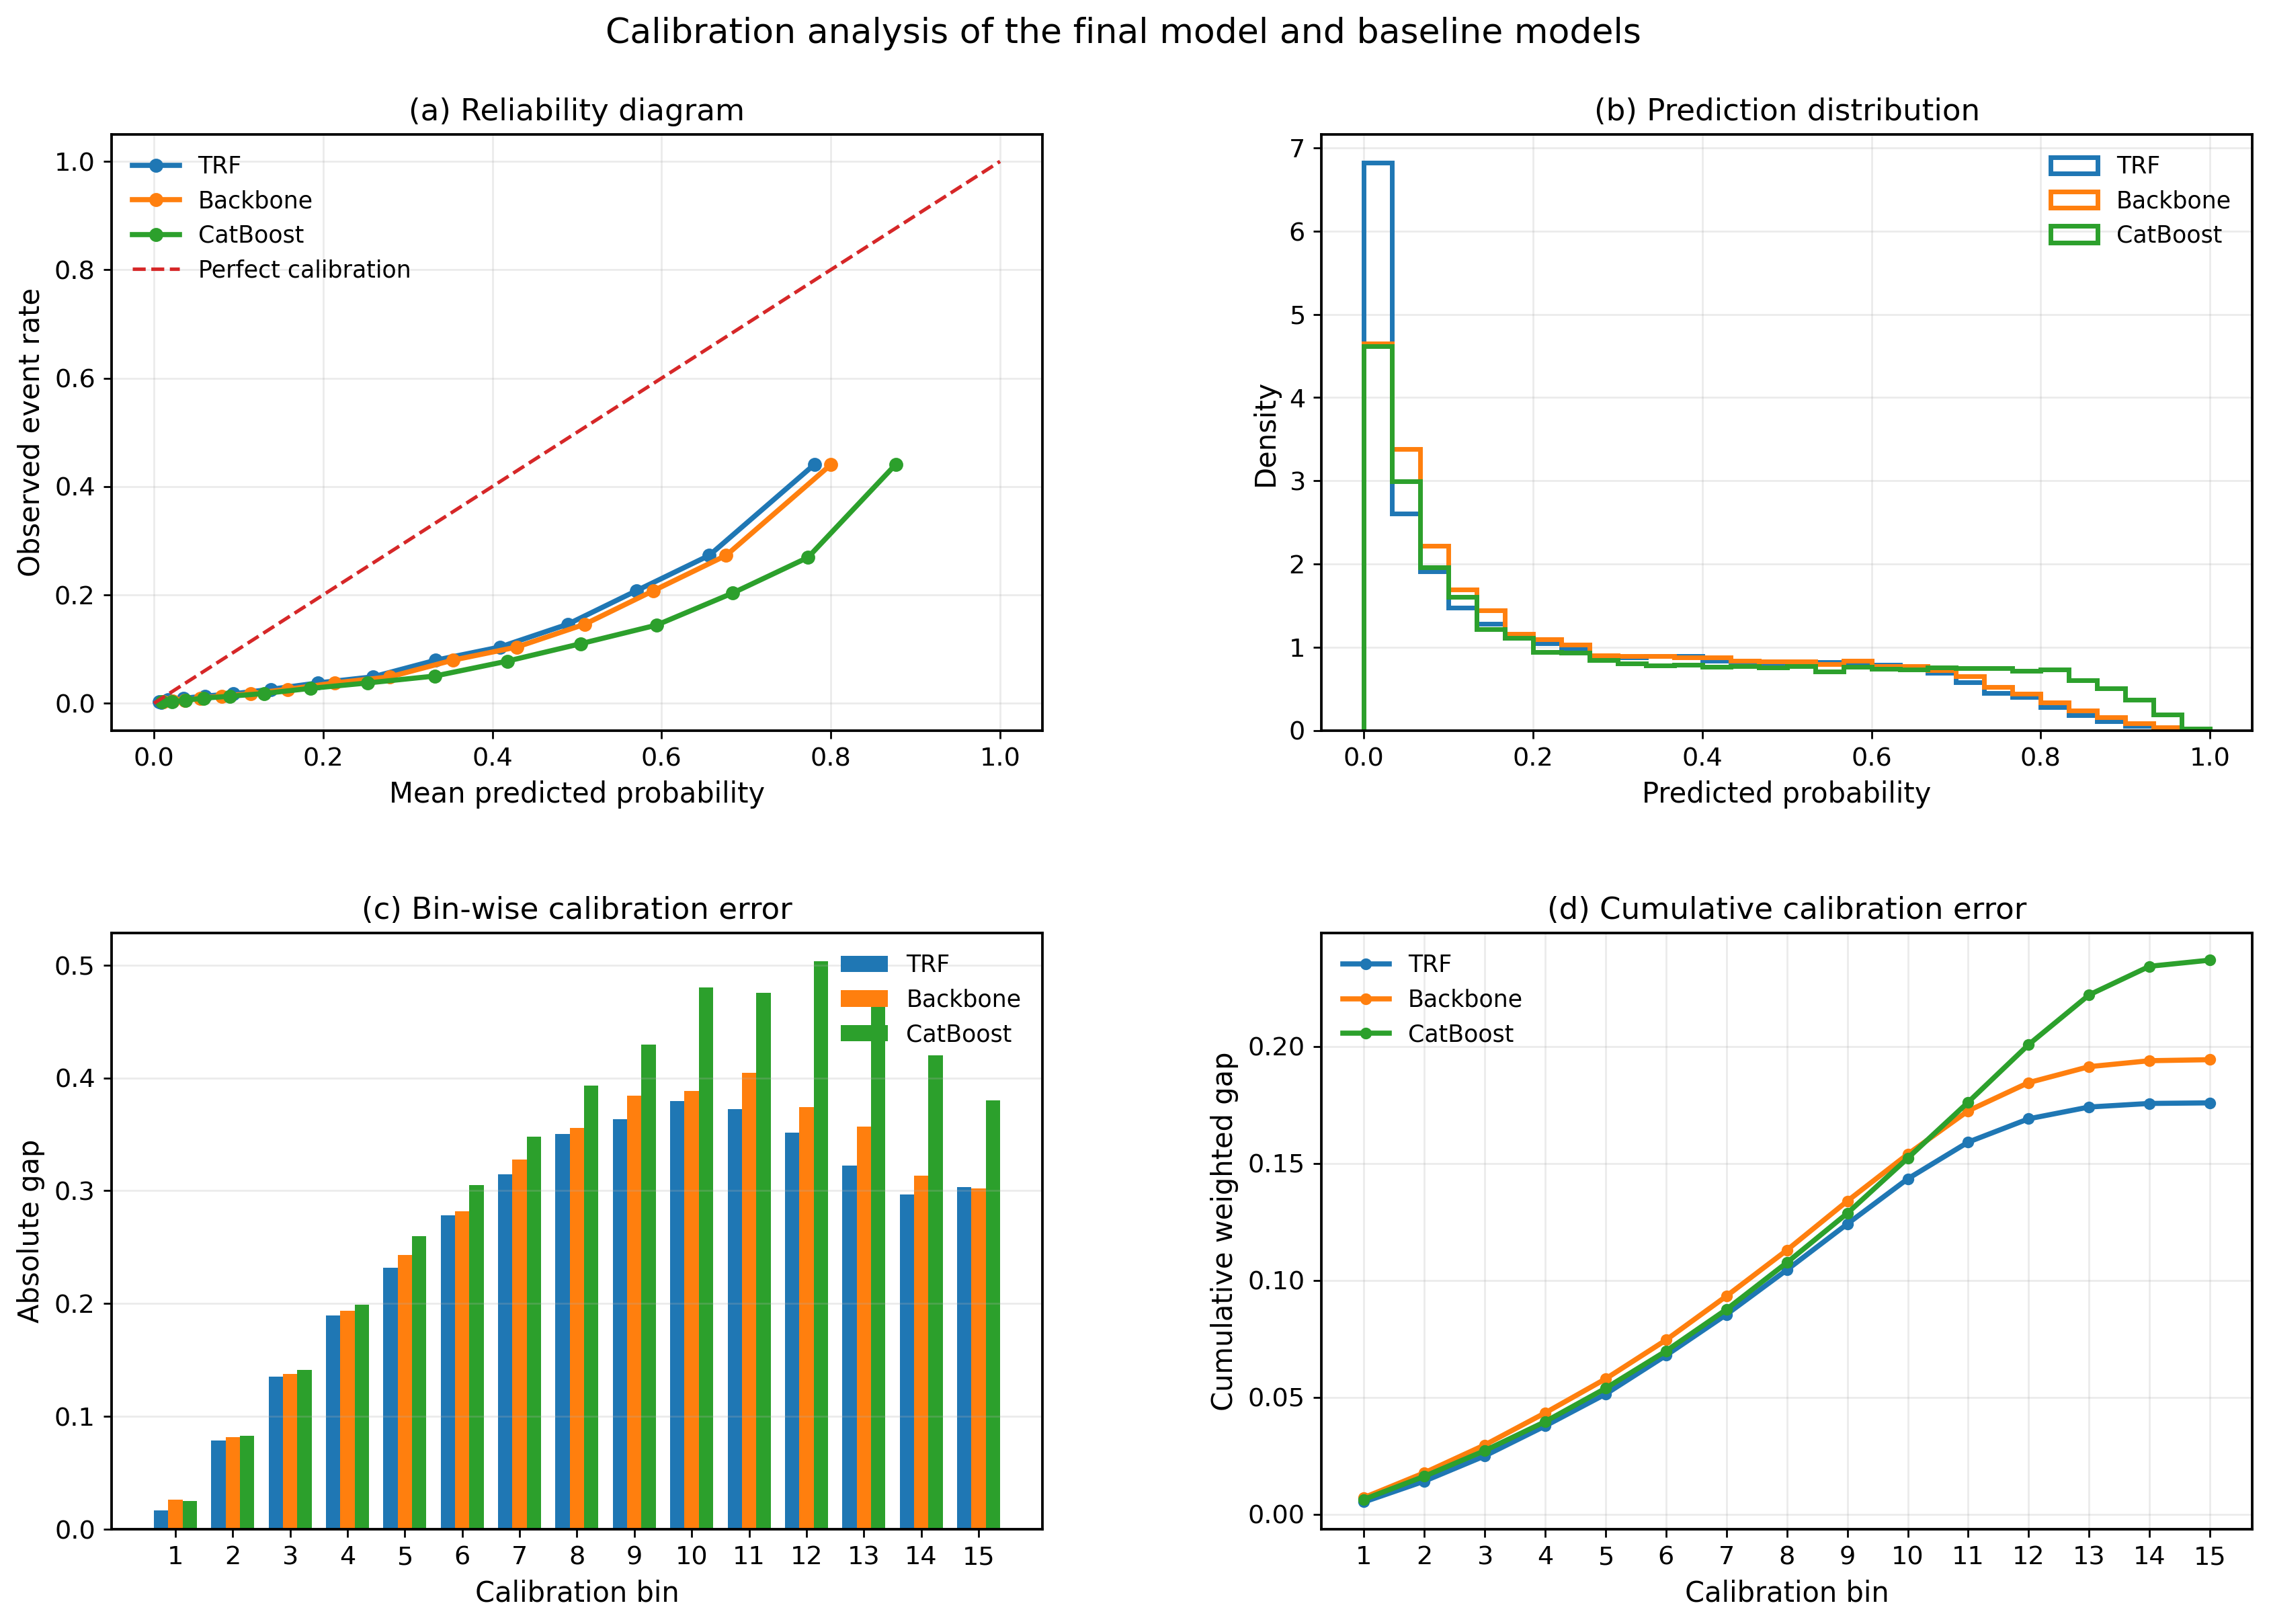


Saved:
 - /kaggle/working/outputs/figures/paper_calibration_figure.png
 - /kaggle/working/outputs/figures/paper_calibration_figure.pdf
 - paper_calibration_figure_summary.csv
 - paper_calibration_figure_bin_table.csv


In [45]:
# ============================================================
# Journal-Grade Calibration Figure
#
# Figure set:
#   (a) Reliability diagram
#   (b) Prediction histogram
#   (c) Bin-wise calibration error
#   (d) Cumulative calibration gap
#
# Models:
#   - TrustAwareResidualFusion
#   - PerfWeightedEnsemble
#   - CatBoost
#
# Output:
#   outputs/figures/paper_calibration_figure.{png,pdf}
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR", "y_test"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for calibration figure: {missing}")

# prediction dataframe detection
pred_df_candidates = []
if "holdout_pred_df" in globals():
    pred_df_candidates.append(("holdout_pred_df", holdout_pred_df.copy()))
if "final_holdout_pred_df" in globals():
    pred_df_candidates.append(("final_holdout_pred_df", final_holdout_pred_df.copy()))

if len(pred_df_candidates) == 0:
    raise ValueError("No hold-out prediction dataframe found in memory.")

def score_df(df):
    cols = set(df.columns)
    score = 0
    for c in [
        "TrustAwareResidualFusion_pred",
        "PerfWeightedEnsemble_pred",
        "CatBoost_pred",
    ]:
        if c in cols:
            score += 1
    return score

pred_df_candidates = sorted(pred_df_candidates, key=lambda x: score_df(x[1]), reverse=True)
pred_df_name, cal_df = pred_df_candidates[0]

print("Using prediction dataframe:", pred_df_name)

# ------------------------------------------------------------
# Column detection
# ------------------------------------------------------------
def find_column(candidates, df):
    for c in candidates:
        if c in df.columns:
            return c
    return None

FINAL_COL = find_column(
    ["TrustAwareResidualFusion_pred", "TrustAwareResidualFusion"],
    cal_df
)
BASE_COL = find_column(
    ["PerfWeightedEnsemble_pred", "TRF_Backbone_pred"],
    cal_df
)
CAT_COL = find_column(
    ["CatBoost_pred"],
    cal_df
)

if FINAL_COL is None:
    raise ValueError("Final model prediction column not found.")
if BASE_COL is None:
    raise ValueError("Backbone/baseline prediction column not found.")
if CAT_COL is None:
    raise ValueError("CatBoost prediction column not found.")

print("Final model column :", FINAL_COL)
print("Backbone column    :", BASE_COL)
print("CatBoost column    :", CAT_COL)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def expected_calibration_error(y_true, y_prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(y_prob, bins[1:-1], right=True)

    ece = 0.0
    n = len(y_true)

    for b in range(n_bins):
        mask = (bin_ids == b)
        if mask.sum() == 0:
            continue
        bin_acc = y_true[mask].mean()
        bin_conf = y_prob[mask].mean()
        ece += (mask.sum() / n) * abs(bin_acc - bin_conf)
    return float(ece)

def get_bin_table(y_true, y_prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    y_prob = clip_probs(y_prob)

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    mids = 0.5 * (edges[:-1] + edges[1:])
    rows = []

    for i in range(n_bins):
        left = edges[i]
        right = edges[i + 1]
        if i < n_bins - 1:
            mask = (y_prob >= left) & (y_prob < right)
        else:
            mask = (y_prob >= left) & (y_prob <= right)

        n_bin = int(mask.sum())

        if n_bin == 0:
            rows.append({
                "bin_id": i,
                "bin_mid": mids[i],
                "pred_mean": np.nan,
                "true_rate": np.nan,
                "abs_gap": np.nan,
                "count": 0,
                "frac": 0.0,
            })
            continue

        pred_mean = float(y_prob[mask].mean())
        true_rate = float(y_true[mask].mean())
        abs_gap = abs(pred_mean - true_rate)

        rows.append({
            "bin_id": i,
            "bin_mid": mids[i],
            "pred_mean": pred_mean,
            "true_rate": true_rate,
            "abs_gap": float(abs_gap),
            "count": n_bin,
            "frac": float(n_bin / len(y_true)),
        })

    return pd.DataFrame(rows)

def save_figure_multi(base_path):
    plt.savefig(f"{base_path}.png", dpi=400, bbox_inches="tight")
    plt.savefig(f"{base_path}.pdf", bbox_inches="tight")

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
y_true = np.asarray(y_test).astype(int)

model_map = {
    "TRF": clip_probs(cal_df[FINAL_COL].values),
    "Backbone": clip_probs(cal_df[BASE_COL].values),
    "CatBoost": clip_probs(cal_df[CAT_COL].values),
}

# ------------------------------------------------------------
# Build calibration tables
# ------------------------------------------------------------
bin_tables = {}
summary_rows = []

for model_name, p in model_map.items():
    bt = get_bin_table(y_true, p, n_bins=15)
    bin_tables[model_name] = bt

    summary_rows.append({
        "model": model_name,
        "Brier": float(np.mean((p - y_true) ** 2)),
        "ECE": expected_calibration_error(y_true, p, n_bins=15),
        "Mean_p": float(np.mean(p)),
    })

calibration_summary_fig_df = pd.DataFrame(summary_rows)
calibration_summary_fig_df.to_csv(
    os.path.join(TAB_DIR, "paper_calibration_figure_summary.csv"),
    index=False
)

all_bin_tables = []
for model_name, bt in bin_tables.items():
    tmp = bt.copy()
    tmp["model"] = model_name
    all_bin_tables.append(tmp)

all_bin_tables_df = pd.concat(all_bin_tables, axis=0, ignore_index=True)
all_bin_tables_df.to_csv(
    os.path.join(TAB_DIR, "paper_calibration_figure_bin_table.csv"),
    index=False
)

# ------------------------------------------------------------
# Plot setup
# ------------------------------------------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "axes.linewidth": 1.1,
    "lines.linewidth": 2.2,
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1, ax2, ax3, ax4 = axes.flatten()

# ------------------------------------------------------------
# (a) Reliability diagram
# ------------------------------------------------------------
for model_name, p in model_map.items():
    prob_true, prob_pred = calibration_curve(
        y_true,
        p,
        n_bins=15,
        strategy="quantile"
    )
    ax1.plot(prob_pred, prob_true, marker="o", linewidth=2.2, markersize=5, label=model_name)

ax1.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, label="Perfect calibration")
ax1.set_xlabel("Mean predicted probability")
ax1.set_ylabel("Observed event rate")
ax1.set_title("(a) Reliability diagram")
ax1.grid(alpha=0.25)
ax1.legend(frameon=False, loc="upper left")

# ------------------------------------------------------------
# (b) Prediction histogram
# ------------------------------------------------------------
hist_bins = np.linspace(0.0, 1.0, 31)
for model_name, p in model_map.items():
    ax2.hist(
        p,
        bins=hist_bins,
        density=True,
        histtype="step",
        linewidth=2.0,
        label=model_name
    )

ax2.set_xlabel("Predicted probability")
ax2.set_ylabel("Density")
ax2.set_title("(b) Prediction distribution")
ax2.grid(alpha=0.25)
ax2.legend(frameon=False, loc="upper right")

# ------------------------------------------------------------
# (c) Bin-wise absolute calibration error
# ------------------------------------------------------------
x = np.arange(15)
width = 0.25

plot_order = ["TRF", "Backbone", "CatBoost"]
offsets = [-width, 0.0, width]

for model_name, off in zip(plot_order, offsets):
    bt = bin_tables[model_name]
    vals = bt["abs_gap"].fillna(0.0).values
    ax3.bar(x + off, vals, width=width, label=model_name)

ax3.set_xlabel("Calibration bin")
ax3.set_ylabel("Absolute gap")
ax3.set_title("(c) Bin-wise calibration error")
ax3.set_xticks(x)
ax3.set_xticklabels([str(i + 1) for i in range(15)])
ax3.grid(axis="y", alpha=0.25)
ax3.legend(frameon=False, loc="upper right")

# ------------------------------------------------------------
# (d) Cumulative weighted calibration gap
# ------------------------------------------------------------
for model_name in plot_order:
    bt = bin_tables[model_name].copy()
    weighted_gap = (bt["abs_gap"].fillna(0.0) * bt["frac"].fillna(0.0)).cumsum()
    ax4.plot(
        np.arange(1, len(weighted_gap) + 1),
        weighted_gap.values,
        marker="o",
        linewidth=2.2,
        markersize=4,
        label=model_name
    )

ax4.set_xlabel("Calibration bin")
ax4.set_ylabel("Cumulative weighted gap")
ax4.set_title("(d) Cumulative calibration error")
ax4.set_xticks(np.arange(1, 16))
ax4.grid(alpha=0.25)
ax4.legend(frameon=False, loc="upper left")

# ------------------------------------------------------------
# Global spacing / caption-like text
# ------------------------------------------------------------
fig.suptitle("Calibration analysis of the final model and baseline models", fontsize=15, y=0.98)
plt.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.91,
    bottom=0.08,
    wspace=0.30,
    hspace=0.34
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
out_base = os.path.join(FIG_DIR, "paper_calibration_figure")
save_figure_multi(out_base)

plt.show()

print("\nSaved:")
print(f" - {out_base}.png")
print(f" - {out_base}.pdf")
print(" - paper_calibration_figure_summary.csv")
print(" - paper_calibration_figure_bin_table.csv")

In [46]:
# ============================================================
# Module — Light Uncertainty-Aware Gating (UAG)
#
# Goal:
# - replace the static weighted backbone with a light adaptive gate
# - keep the pipeline stable and low-risk
# - optionally apply the same bounded TRF correction on top
#
# Final objects produced:
#   1) UAG_GatedBackbone
#   2) UAG_GatedBackbone_plus_TRF
#
# Design:
# - gate is a small multinomial logistic classifier
# - gate predicts sample-specific expert weights from trust features
# - gated probability = sum_k alpha_k(x) * p_k(x)
# - optional bounded Ridge residual correction on top
#
# Outputs:
# - module_uag_comparison.csv
# - module_uag_holdout_predictions.csv
# - module_uag_gate_weights_holdout.csv
# - module_uag_metadata.json
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression, Ridge

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df", "holdout_pred_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for UAG module: {missing}")

print("===== Light Uncertainty-Aware Gating Module =====")

# ------------------------------------------------------------
# Locked config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few experts found in oof_df: {FINAL_EXPERTS}")

TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02

# gate config: intentionally light
GATE_C = 0.5
GATE_MAX_ITER = 3000

print("Experts:", FINAL_EXPERTS)
print("TRF alpha:", TRF_ALPHA)
print("TRF delta_max:", TRF_DELTA_MAX)
print("Gate C:", GATE_C)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

def get_static_backbone_weights(expert_names, baseline_df):
    perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
    w = np.array([perf_map[m] for m in expert_names], dtype=float)
    w = w / w.sum()
    return w

def build_gate_feature_table(expert_pred_df, expert_cols, mode="light"):
    """
    mode='light':
      - raw expert probabilities
      - entropy per expert
      - confidence per expert
      - prob_mean/std/min/max/range
      - top1_top2_margin
    """
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"
    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    out = pd.concat(
        [df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)],
        axis=1
    )
    out.columns = make_unique_columns(out.columns)
    return out

def derive_pseudo_gate_targets(expert_pred_df, expert_cols):
    """
    Build pseudo-labels for gate training.
    For each sample:
    - if y=1, choose expert with highest predicted probability
    - if y=0, choose expert with lowest predicted probability
    This teaches the gate which expert was 'most aligned' with label on dev OOF.
    """
    P = expert_pred_df[expert_cols].values.astype(float)
    y = expert_pred_df["y_true"].values.astype(int)

    pos_best = np.argmax(P, axis=1)
    neg_best = np.argmin(P, axis=1)

    target = np.where(y == 1, pos_best, neg_best).astype(int)
    return target

def compute_gated_probability(P, W):
    """
    P: (n, K) expert probs
    W: (n, K) gate weights
    """
    return clip_probs_local(np.sum(P * W, axis=1))

# ------------------------------------------------------------
# Build dev / holdout expert tables
# ------------------------------------------------------------
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_dev_cols = [c for c in required_dev_cols if c not in oof_df.columns]
if missing_dev_cols:
    raise ValueError(f"Missing development OOF columns: {missing_dev_cols}")

required_test_cols = ["row_idx_test", "y_true"] + [f"{m}_pred" for m in FINAL_EXPERTS]
missing_test_cols = [c for c in required_test_cols if c not in holdout_pred_df.columns]
if missing_test_cols:
    raise ValueError(f"Missing holdout columns: {missing_test_cols}")

dev_expert_df = oof_df[required_dev_cols].copy()

test_expert_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
})
for m in FINAL_EXPERTS:
    test_expert_df[m] = holdout_pred_df[f"{m}_pred"].values

P_dev = np.clip(dev_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
P_test = np.clip(test_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
y_dev = dev_expert_df["y_true"].values.astype(int)
y_test = test_expert_df["y_true"].values.astype(int)

# ------------------------------------------------------------
# Static backbone for reference
# ------------------------------------------------------------
static_weights = get_static_backbone_weights(FINAL_EXPERTS, baseline_df)
dev_static_backbone = compute_gated_probability(P_dev, np.tile(static_weights.reshape(1, -1), (len(P_dev), 1)))
test_static_backbone = compute_gated_probability(P_test, np.tile(static_weights.reshape(1, -1), (len(P_test), 1)))

print("Static backbone weights:")
for m, w in zip(FINAL_EXPERTS, static_weights):
    print(f"  {m}: {w:.4f}")

# ------------------------------------------------------------
# Build light gate features
# ------------------------------------------------------------
dev_gate_df = build_gate_feature_table(dev_expert_df, FINAL_EXPERTS, mode="light")
test_gate_df = build_gate_feature_table(test_expert_df, FINAL_EXPERTS, mode="light")

X_dev_gate = dev_gate_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_gate.columns = make_unique_columns(X_dev_gate.columns)

X_test_gate = test_gate_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_gate.columns = make_unique_columns(X_test_gate.columns)

train_cols = X_dev_gate.columns.tolist()
for c in train_cols:
    if c not in X_test_gate.columns:
        X_test_gate[c] = 0.0

extra_cols = [c for c in X_test_gate.columns if c not in train_cols]
if extra_cols:
    X_test_gate = X_test_gate.drop(columns=extra_cols)

X_test_gate = X_test_gate[train_cols].copy()

# ------------------------------------------------------------
# Train light adaptive gate
# ------------------------------------------------------------
gate_targets = derive_pseudo_gate_targets(dev_expert_df, FINAL_EXPERTS)

gate_model = LogisticRegression(
    C=GATE_C,
    penalty="l2",
    solver="lbfgs",
    multi_class="multinomial",
    max_iter=GATE_MAX_ITER,
    random_state=SEED,
)

gate_model.fit(X_dev_gate, gate_targets)

# weights from gate
W_dev_gate = gate_model.predict_proba(X_dev_gate)
W_test_gate = gate_model.predict_proba(X_test_gate)

# ensure column alignment with expert order
# sklearn classes_ should be 0..K-1, but align safely
if not np.array_equal(gate_model.classes_, np.arange(len(FINAL_EXPERTS))):
    aligned_dev = np.zeros((len(X_dev_gate), len(FINAL_EXPERTS)), dtype=float)
    aligned_test = np.zeros((len(X_test_gate), len(FINAL_EXPERTS)), dtype=float)
    for cls_idx, cls_val in enumerate(gate_model.classes_):
        aligned_dev[:, int(cls_val)] = W_dev_gate[:, cls_idx]
        aligned_test[:, int(cls_val)] = W_test_gate[:, cls_idx]
    W_dev_gate = aligned_dev
    W_test_gate = aligned_test

dev_uag_backbone = compute_gated_probability(P_dev, W_dev_gate)
test_uag_backbone = compute_gated_probability(P_test, W_test_gate)

# ------------------------------------------------------------
# Optional TRF on top of adaptive gate
# ------------------------------------------------------------
# Residual target is now relative to gated backbone
trf_model = Ridge(alpha=TRF_ALPHA)
trf_resid_target = y_dev.astype(float) - dev_uag_backbone.astype(float)
trf_model.fit(X_dev_gate, trf_resid_target)

dev_delta_raw = trf_model.predict(X_dev_gate)
test_delta_raw = trf_model.predict(X_test_gate)

dev_uag_trf, dev_uag_delta = bounded_correct(dev_uag_backbone, dev_delta_raw, TRF_DELTA_MAX)
test_uag_trf, test_uag_delta = bounded_correct(test_uag_backbone, test_delta_raw, TRF_DELTA_MAX)

# ------------------------------------------------------------
# Compare against existing final model if available
# ------------------------------------------------------------
comparison_rows = []

def add_metrics_row(name, split, y_true_arr, pred_arr):
    row = {"model": name, "split": split}
    row.update(compute_classification_metrics(y_true_arr, pred_arr, threshold_mode="f1"))
    comparison_rows.append(row)

# dev
add_metrics_row("StaticBackbone", "DEV_crossfitted", y_dev, dev_static_backbone)
add_metrics_row("UAG_GatedBackbone", "DEV_crossfitted", y_dev, dev_uag_backbone)
add_metrics_row("UAG_GatedBackbone_plus_TRF", "DEV_crossfitted", y_dev, dev_uag_trf)

# existing final TRF if present in dev can't be directly pulled unless reconstructed;
# skip to avoid mismatch

# holdout
add_metrics_row("StaticBackbone", "HOLDOUT", y_test, test_static_backbone)
add_metrics_row("UAG_GatedBackbone", "HOLDOUT", y_test, test_uag_backbone)
add_metrics_row("UAG_GatedBackbone_plus_TRF", "HOLDOUT", y_test, test_uag_trf)

if "TrustAwareResidualFusion_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "Current_Final_TRF",
        "HOLDOUT",
        y_test,
        holdout_pred_df["TrustAwareResidualFusion_pred"].values
    )

if "PerfWeightedEnsemble_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "PerfWeightedEnsemble",
        "HOLDOUT",
        y_test,
        holdout_pred_df["PerfWeightedEnsemble_pred"].values
    )

if "CatBoost_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "CatBoost",
        "HOLDOUT",
        y_test,
        holdout_pred_df["CatBoost_pred"].values
    )

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(TAB_DIR, "module_uag_comparison.csv"), index=False)

# ------------------------------------------------------------
# Save holdout predictions and gate weights
# ------------------------------------------------------------
holdout_pred_uag_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test,
    "StaticBackbone_pred": test_static_backbone,
    "UAG_GatedBackbone_pred": test_uag_backbone,
    "UAG_GatedBackbone_plus_TRF_pred": test_uag_trf,
    "UAG_delta_bounded": test_uag_delta,
})

for m in FINAL_EXPERTS:
    holdout_pred_uag_df[f"{m}_pred"] = test_expert_df[m].values

holdout_pred_uag_df.to_csv(
    os.path.join(PRED_DIR, "module_uag_holdout_predictions.csv"),
    index=False
)

gate_weights_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test,
})
for j, m in enumerate(FINAL_EXPERTS):
    gate_weights_df[f"gate_w_{m}"] = W_test_gate[:, j]

gate_weights_df["gate_top_expert"] = np.array(FINAL_EXPERTS)[np.argmax(W_test_gate, axis=1)]
gate_weights_df.to_csv(
    os.path.join(TAB_DIR, "module_uag_gate_weights_holdout.csv"),
    index=False
)

# ------------------------------------------------------------
# Save model artifacts
# ------------------------------------------------------------
joblib.dump(gate_model, os.path.join(MOD_DIR, "UAG_gate_model.joblib"))
joblib.dump(trf_model, os.path.join(MOD_DIR, "UAG_trf_model.joblib"))

# gate coefficient table for interpretability
coef_table_rows = []
coef = gate_model.coef_  # shape K x F
for k, expert_name in enumerate(FINAL_EXPERTS):
    for f_idx, feat_name in enumerate(train_cols):
        coef_table_rows.append({
            "expert": expert_name,
            "feature": feat_name,
            "coef": float(coef[k, f_idx]),
            "abs_coef": float(abs(coef[k, f_idx])),
        })

gate_coef_df = pd.DataFrame(coef_table_rows).sort_values(
    ["expert", "abs_coef"], ascending=[True, False]
).reset_index(drop=True)
gate_coef_df.to_csv(
    os.path.join(TAB_DIR, "module_uag_gate_coefficients.csv"),
    index=False
)

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "experts": FINAL_EXPERTS,
    "gate_model": "multinomial_logistic_regression",
    "gate_C": GATE_C,
    "gate_max_iter": GATE_MAX_ITER,
    "trf_alpha": TRF_ALPHA,
    "trf_delta_max": TRF_DELTA_MAX,
    "n_gate_features": int(len(train_cols)),
    "outputs": [
        "module_uag_comparison.csv",
        "module_uag_holdout_predictions.csv",
        "module_uag_gate_weights_holdout.csv",
        "module_uag_gate_coefficients.csv",
        "UAG_gate_model.joblib",
        "UAG_trf_model.joblib",
    ]
}
with open(os.path.join(LOG_DIR, "module_uag_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
show_cols = [
    "model", "split", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC", "Accuracy"
]
show_cols = [c for c in show_cols if c in comparison_df.columns]

print("\n===== UAG Comparison =====")
print(comparison_df[show_cols])

print("\nTop selected experts by gate on holdout:")
print(gate_weights_df["gate_top_expert"].value_counts(normalize=True))

print("\nSaved:")
print(" - module_uag_comparison.csv")
print(" - module_uag_holdout_predictions.csv")
print(" - module_uag_gate_weights_holdout.csv")
print(" - module_uag_gate_coefficients.csv")
print(" - UAG_gate_model.joblib")
print(" - UAG_trf_model.joblib")
print(" - module_uag_metadata.json")

===== Light Uncertainty-Aware Gating Module =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
TRF alpha: 5.0
TRF delta_max: 0.02
Gate C: 0.5
Static backbone weights:
  CatBoost: 0.2044
  LogReg_ElasticNet: 0.2010
  MLP: 0.1981
  DeepFM: 0.2001
  LightGBM: 0.1964

===== UAG Comparison =====
                        model            split    PR_AUC   ROC_AUC     Brier  \
0              StaticBackbone  DEV_crossfitted  0.377725  0.849586  0.126514   
1           UAG_GatedBackbone  DEV_crossfitted  0.370806  0.847175  0.075874   
2  UAG_GatedBackbone_plus_TRF  DEV_crossfitted  0.370940  0.846967  0.074422   
3              StaticBackbone          HOLDOUT  0.368174  0.849514  0.128184   
4           UAG_GatedBackbone          HOLDOUT  0.347020  0.838772  0.080890   
5  UAG_GatedBackbone_plus_TRF          HOLDOUT  0.347315  0.840796  0.078944   
6           Current_Final_TRF          HOLDOUT  0.367522  0.849489  0.120824   
7        PerfWeightedEnsemble          HO

In [47]:
# ============================================================
# Module — UAG-v2 Anchored Soft Gate
#
# Goal:
# - improve the failed UAG by preventing expert-collapse
# - keep the gate close to the strong static backbone
# - optionally apply bounded TRF correction on top
#
# Final objects produced:
#   1) UAGv2_AnchoredGate
#   2) UAGv2_AnchoredGate_plus_TRF
#
# Core idea:
# - learn a small additive adjustment around static backbone weights
# - apply temperature smoothing
# - apply minimum weight floor
# - renormalize to simplex
#
# Outputs:
# - module_uag_v2_comparison.csv
# - module_uag_v2_holdout_predictions.csv
# - module_uag_v2_gate_weights_holdout.csv
# - module_uag_v2_metadata.json
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df", "holdout_pred_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for UAG-v2 module: {missing}")

print("===== UAG-v2 Anchored Soft Gate =====")

# ------------------------------------------------------------
# Locked config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few experts found: {FINAL_EXPERTS}")

# TRF on top of gate
TRF_ALPHA = 5.0
TRF_DELTA_MAX = 0.02

# gate regularization / stability
GATE_ALPHA = 10.0          # ridge shrinkage for gate adjustments
GATE_DELTA_SCALE = 0.08    # max magnitude of additive adjustment around static weights
GATE_TEMP = 1.8            # >1 softens weights
GATE_MIN_FLOOR = 0.10      # each expert gets at least this much weight before renorm

print("Experts:", FINAL_EXPERTS)
print("TRF alpha:", TRF_ALPHA)
print("TRF delta_max:", TRF_DELTA_MAX)
print("Gate alpha:", GATE_ALPHA)
print("Gate delta scale:", GATE_DELTA_SCALE)
print("Gate temperature:", GATE_TEMP)
print("Gate min floor:", GATE_MIN_FLOOR)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_local(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def entropy_binary(p):
    p = clip_probs_local(p)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def make_unique_columns(columns):
    seen = {}
    out = []
    for c in columns:
        if c not in seen:
            seen[c] = 0
            out.append(c)
        else:
            seen[c] += 1
            out.append(f"{c}__dup{seen[c]}")
    return out

def bounded_correct(backbone_pred, delta_raw, delta_max):
    delta_bounded = np.clip(np.asarray(delta_raw).reshape(-1), -delta_max, delta_max)
    return clip_probs_local(backbone_pred + delta_bounded), delta_bounded

def get_static_backbone_weights(expert_names, baseline_df):
    perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
    w = np.array([perf_map[m] for m in expert_names], dtype=float)
    w = w / w.sum()
    return w

def build_gate_feature_table(expert_pred_df, expert_cols, mode="light"):
    """
    Light, stable gate features only.
    """
    idx_col = "row_idx_dev" if "row_idx_dev" in expert_pred_df.columns else "row_idx_test"
    df = expert_pred_df[[idx_col, "y_true"] + expert_cols].copy()
    P = df[expert_cols].values.astype(float)
    P = np.clip(P, EPS, 1.0 - EPS)

    X = pd.DataFrame(index=df.index)

    # raw expert probabilities
    for j, m in enumerate(expert_cols):
        X[m] = P[:, j]

    # entropy / confidence
    for j, m in enumerate(expert_cols):
        X[f"{m}_entropy"] = entropy_binary(P[:, j])
        X[f"{m}_confidence"] = np.abs(P[:, j] - 0.5)

    # global trust stats
    X["prob_mean"] = np.mean(P, axis=1)
    X["prob_std"] = np.std(P, axis=1)
    X["prob_min"] = np.min(P, axis=1)
    X["prob_max"] = np.max(P, axis=1)
    X["prob_range"] = X["prob_max"] - X["prob_min"]

    sortedP = np.sort(P, axis=1)
    X["top1_prob"] = sortedP[:, -1]
    X["top2_prob"] = sortedP[:, -2]
    X["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    out = pd.concat(
        [df[[idx_col, "y_true"]].reset_index(drop=True), X.reset_index(drop=True)],
        axis=1
    )
    out.columns = make_unique_columns(out.columns)
    return out

def compute_weighted_prob(P, W):
    return clip_probs_local(np.sum(P * W, axis=1))

def softmax_rows(Z, temperature=1.0):
    Z = np.asarray(Z, dtype=float) / max(float(temperature), EPS)
    Z = Z - np.max(Z, axis=1, keepdims=True)
    E = np.exp(Z)
    S = E / np.sum(E, axis=1, keepdims=True)
    return S

def anchored_soft_weights(delta_raw, base_w, delta_scale=0.08, temperature=1.8, min_floor=0.10):
    """
    delta_raw: (n, K) unconstrained outputs from regressors
    base_w:    (K,) static base weights
    Returns stable weights near base_w.
    """
    delta_raw = np.asarray(delta_raw, dtype=float)
    n, k = delta_raw.shape
    base_w = np.asarray(base_w, dtype=float).reshape(1, k)

    # squash raw deltas to small bounded values around zero
    delta_small = delta_scale * np.tanh(delta_raw)

    # anchor in log-space-ish via additive score around base weights
    base_score = np.log(np.clip(base_w, EPS, 1.0))
    scores = base_score + delta_small

    # softened softmax
    W = softmax_rows(scores, temperature=temperature)

    # floor each expert, then renormalize
    W = np.maximum(W, min_floor)
    W = W / np.sum(W, axis=1, keepdims=True)

    return W

def summarize_gate_weights(W, expert_names):
    rows = []
    for j, m in enumerate(expert_names):
        rows.append({
            "expert": m,
            "mean_weight": float(np.mean(W[:, j])),
            "std_weight": float(np.std(W[:, j])),
            "min_weight": float(np.min(W[:, j])),
            "max_weight": float(np.max(W[:, j])),
        })
    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Prepare dev and hold-out expert tables
# ------------------------------------------------------------
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_dev_cols = [c for c in required_dev_cols if c not in oof_df.columns]
if missing_dev_cols:
    raise ValueError(f"Missing development OOF columns: {missing_dev_cols}")

required_test_cols = ["row_idx_test", "y_true"] + [f"{m}_pred" for m in FINAL_EXPERTS]
missing_test_cols = [c for c in required_test_cols if c not in holdout_pred_df.columns]
if missing_test_cols:
    raise ValueError(f"Missing holdout columns: {missing_test_cols}")

dev_expert_df = oof_df[required_dev_cols].copy()

test_expert_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
})
for m in FINAL_EXPERTS:
    test_expert_df[m] = holdout_pred_df[f"{m}_pred"].values

P_dev = np.clip(dev_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
P_test = np.clip(test_expert_df[FINAL_EXPERTS].values.astype(float), EPS, 1.0 - EPS)
y_dev = dev_expert_df["y_true"].values.astype(int)
y_test = test_expert_df["y_true"].values.astype(int)

# ------------------------------------------------------------
# Static backbone
# ------------------------------------------------------------
static_weights = get_static_backbone_weights(FINAL_EXPERTS, baseline_df)
dev_static_backbone = compute_weighted_prob(P_dev, np.tile(static_weights.reshape(1, -1), (len(P_dev), 1)))
test_static_backbone = compute_weighted_prob(P_test, np.tile(static_weights.reshape(1, -1), (len(P_test), 1)))

print("Static backbone weights:")
for m, w in zip(FINAL_EXPERTS, static_weights):
    print(f"  {m}: {w:.4f}")

# ------------------------------------------------------------
# Build gate features
# ------------------------------------------------------------
dev_gate_df = build_gate_feature_table(dev_expert_df, FINAL_EXPERTS, mode="light")
test_gate_df = build_gate_feature_table(test_expert_df, FINAL_EXPERTS, mode="light")

X_dev_gate = dev_gate_df.drop(columns=["row_idx_dev", "y_true"], errors="ignore").copy()
X_dev_gate.columns = make_unique_columns(X_dev_gate.columns)

X_test_gate = test_gate_df.drop(columns=["row_idx_test", "y_true"], errors="ignore").copy()
X_test_gate.columns = make_unique_columns(X_test_gate.columns)

train_cols = X_dev_gate.columns.tolist()
for c in train_cols:
    if c not in X_test_gate.columns:
        X_test_gate[c] = 0.0

extra_cols = [c for c in X_test_gate.columns if c not in train_cols]
if extra_cols:
    X_test_gate = X_test_gate.drop(columns=extra_cols)

X_test_gate = X_test_gate[train_cols].copy()

# ------------------------------------------------------------
# Train anchored soft gate
# ------------------------------------------------------------
# Instead of hard pseudo-class gate, learn per-expert residual usefulness targets:
# target_k = y - p_backbone, weighted by signed advantage of expert k over backbone.
#
# This keeps the gate smooth and anchored rather than winner-take-all.
adv_dev = P_dev - dev_static_backbone.reshape(-1, 1)   # (n, K)
resid_dev = y_dev.astype(float) - dev_static_backbone.astype(float)

# regression target for each expert adjustment dimension
# if expert exceeds backbone in helpful direction, gate may upweight it slightly
gate_target_matrix = adv_dev * resid_dev.reshape(-1, 1)

gate_regressors = []
delta_dev_raw = np.zeros((len(X_dev_gate), len(FINAL_EXPERTS)), dtype=float)
delta_test_raw = np.zeros((len(X_test_gate), len(FINAL_EXPERTS)), dtype=float)

for j, expert_name in enumerate(FINAL_EXPERTS):
    reg = Ridge(alpha=GATE_ALPHA)
    reg.fit(X_dev_gate, gate_target_matrix[:, j])
    delta_dev_raw[:, j] = reg.predict(X_dev_gate)
    delta_test_raw[:, j] = reg.predict(X_test_gate)
    gate_regressors.append(reg)

W_dev_gate = anchored_soft_weights(
    delta_raw=delta_dev_raw,
    base_w=static_weights,
    delta_scale=GATE_DELTA_SCALE,
    temperature=GATE_TEMP,
    min_floor=GATE_MIN_FLOOR
)

W_test_gate = anchored_soft_weights(
    delta_raw=delta_test_raw,
    base_w=static_weights,
    delta_scale=GATE_DELTA_SCALE,
    temperature=GATE_TEMP,
    min_floor=GATE_MIN_FLOOR
)

dev_uag_v2_backbone = compute_weighted_prob(P_dev, W_dev_gate)
test_uag_v2_backbone = compute_weighted_prob(P_test, W_test_gate)

# ------------------------------------------------------------
# TRF on top of anchored gate
# ------------------------------------------------------------
trf_model = Ridge(alpha=TRF_ALPHA)
trf_resid_target = y_dev.astype(float) - dev_uag_v2_backbone.astype(float)
trf_model.fit(X_dev_gate, trf_resid_target)

dev_delta_raw = trf_model.predict(X_dev_gate)
test_delta_raw = trf_model.predict(X_test_gate)

dev_uag_v2_trf, dev_uag_v2_delta = bounded_correct(dev_uag_v2_backbone, dev_delta_raw, TRF_DELTA_MAX)
test_uag_v2_trf, test_uag_v2_delta = bounded_correct(test_uag_v2_backbone, test_delta_raw, TRF_DELTA_MAX)

# ------------------------------------------------------------
# Compare against current final model
# ------------------------------------------------------------
comparison_rows = []

def add_metrics_row(name, split, y_true_arr, pred_arr):
    row = {"model": name, "split": split}
    row.update(compute_classification_metrics(y_true_arr, pred_arr, threshold_mode="f1"))
    comparison_rows.append(row)

# dev
add_metrics_row("StaticBackbone", "DEV_crossfitted", y_dev, dev_static_backbone)
add_metrics_row("UAGv2_AnchoredGate", "DEV_crossfitted", y_dev, dev_uag_v2_backbone)
add_metrics_row("UAGv2_AnchoredGate_plus_TRF", "DEV_crossfitted", y_dev, dev_uag_v2_trf)

# holdout
add_metrics_row("StaticBackbone", "HOLDOUT", y_test, test_static_backbone)
add_metrics_row("UAGv2_AnchoredGate", "HOLDOUT", y_test, test_uag_v2_backbone)
add_metrics_row("UAGv2_AnchoredGate_plus_TRF", "HOLDOUT", y_test, test_uag_v2_trf)

if "TrustAwareResidualFusion_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "Current_Final_TRF",
        "HOLDOUT",
        y_test,
        holdout_pred_df["TrustAwareResidualFusion_pred"].values
    )

if "PerfWeightedEnsemble_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "PerfWeightedEnsemble",
        "HOLDOUT",
        y_test,
        holdout_pred_df["PerfWeightedEnsemble_pred"].values
    )

if "CatBoost_pred" in holdout_pred_df.columns:
    add_metrics_row(
        "CatBoost",
        "HOLDOUT",
        y_test,
        holdout_pred_df["CatBoost_pred"].values
    )

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(TAB_DIR, "module_uag_v2_comparison.csv"), index=False)

# ------------------------------------------------------------
# Save holdout predictions
# ------------------------------------------------------------
holdout_pred_uag_v2_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test,
    "StaticBackbone_pred": test_static_backbone,
    "UAGv2_AnchoredGate_pred": test_uag_v2_backbone,
    "UAGv2_AnchoredGate_plus_TRF_pred": test_uag_v2_trf,
    "UAGv2_delta_bounded": test_uag_v2_delta,
})

for m in FINAL_EXPERTS:
    holdout_pred_uag_v2_df[f"{m}_pred"] = test_expert_df[m].values

holdout_pred_uag_v2_df.to_csv(
    os.path.join(PRED_DIR, "module_uag_v2_holdout_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# Save gate weights
# ------------------------------------------------------------
gate_weights_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test,
})
for j, m in enumerate(FINAL_EXPERTS):
    gate_weights_df[f"gate_w_{m}"] = W_test_gate[:, j]

gate_weights_df["gate_top_expert"] = np.array(FINAL_EXPERTS)[np.argmax(W_test_gate, axis=1)]
gate_weights_df.to_csv(
    os.path.join(TAB_DIR, "module_uag_v2_gate_weights_holdout.csv"),
    index=False
)

gate_weight_summary_df = summarize_gate_weights(W_test_gate, FINAL_EXPERTS)
gate_weight_summary_df.to_csv(
    os.path.join(TAB_DIR, "module_uag_v2_gate_weight_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------
for j, reg in enumerate(gate_regressors):
    joblib.dump(reg, os.path.join(MOD_DIR, f"UAGv2_gate_regressor_{FINAL_EXPERTS[j]}.joblib"))

joblib.dump(trf_model, os.path.join(MOD_DIR, "UAGv2_trf_model.joblib"))

# optional coefficient table for gate regressors
coef_rows = []
for j, reg in enumerate(gate_regressors):
    coef = np.asarray(reg.coef_).reshape(-1)
    for feat_name, coef_val in zip(train_cols, coef):
        coef_rows.append({
            "expert": FINAL_EXPERTS[j],
            "feature": feat_name,
            "coef": float(coef_val),
            "abs_coef": float(abs(coef_val)),
        })

gate_coef_df = pd.DataFrame(coef_rows).sort_values(
    ["expert", "abs_coef"], ascending=[True, False]
).reset_index(drop=True)

gate_coef_df.to_csv(
    os.path.join(TAB_DIR, "module_uag_v2_gate_coefficients.csv"),
    index=False
)

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------
meta = {
    "experts": FINAL_EXPERTS,
    "static_backbone_weights": {m: float(w) for m, w in zip(FINAL_EXPERTS, static_weights)},
    "gate_type": "anchored_soft_gate_with_per_expert_ridge_adjustments",
    "gate_alpha": GATE_ALPHA,
    "gate_delta_scale": GATE_DELTA_SCALE,
    "gate_temperature": GATE_TEMP,
    "gate_min_floor": GATE_MIN_FLOOR,
    "trf_alpha": TRF_ALPHA,
    "trf_delta_max": TRF_DELTA_MAX,
    "n_gate_features": int(len(train_cols)),
}
with open(os.path.join(LOG_DIR, "module_uag_v2_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ------------------------------------------------------------
# Console summary
# ------------------------------------------------------------
show_cols = [
    "model", "split", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC", "Accuracy"
]
show_cols = [c for c in show_cols if c in comparison_df.columns]

print("\n===== UAG-v2 Comparison =====")
print(comparison_df[show_cols])

print("\n===== UAG-v2 Gate Weight Summary (holdout) =====")
print(gate_weight_summary_df)

print("\nTop selected experts by anchored gate on holdout:")
print(gate_weights_df["gate_top_expert"].value_counts(normalize=True))

print("\nSaved:")
print(" - module_uag_v2_comparison.csv")
print(" - module_uag_v2_holdout_predictions.csv")
print(" - module_uag_v2_gate_weights_holdout.csv")
print(" - module_uag_v2_gate_weight_summary.csv")
print(" - module_uag_v2_gate_coefficients.csv")
print(" - module_uag_v2_metadata.json")

===== UAG-v2 Anchored Soft Gate =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
TRF alpha: 5.0
TRF delta_max: 0.02
Gate alpha: 10.0
Gate delta scale: 0.08
Gate temperature: 1.8
Gate min floor: 0.1
Static backbone weights:
  CatBoost: 0.2044
  LogReg_ElasticNet: 0.2010
  MLP: 0.1981
  DeepFM: 0.2001
  LightGBM: 0.1964

===== UAG-v2 Comparison =====
                         model            split    PR_AUC   ROC_AUC     Brier  \
0               StaticBackbone  DEV_crossfitted  0.377725  0.849586  0.126514   
1           UAGv2_AnchoredGate  DEV_crossfitted  0.377703  0.849575  0.126211   
2  UAGv2_AnchoredGate_plus_TRF  DEV_crossfitted  0.377698  0.849520  0.118914   
3               StaticBackbone          HOLDOUT  0.368174  0.849514  0.128184   
4           UAGv2_AnchoredGate          HOLDOUT  0.368106  0.849500  0.127917   
5  UAGv2_AnchoredGate_plus_TRF          HOLDOUT  0.367412  0.849450  0.120594   
6            Current_Final_TRF          HOLDOUT  0.36

===== Validation Performance Figure =====

Validation figure data:
           pretty_model            model            split    PR_AUC   ROC_AUC  \
0  Proposed Model (TRF)      A4_TRF_Full  DEV_crossfitted  0.377720  0.849537   
1              Backbone  A1_BackboneOnly  DEV_crossfitted  0.377725  0.849586   

      Brier       ECE  
0  0.119197  0.174124  
1  0.126514  0.192826  


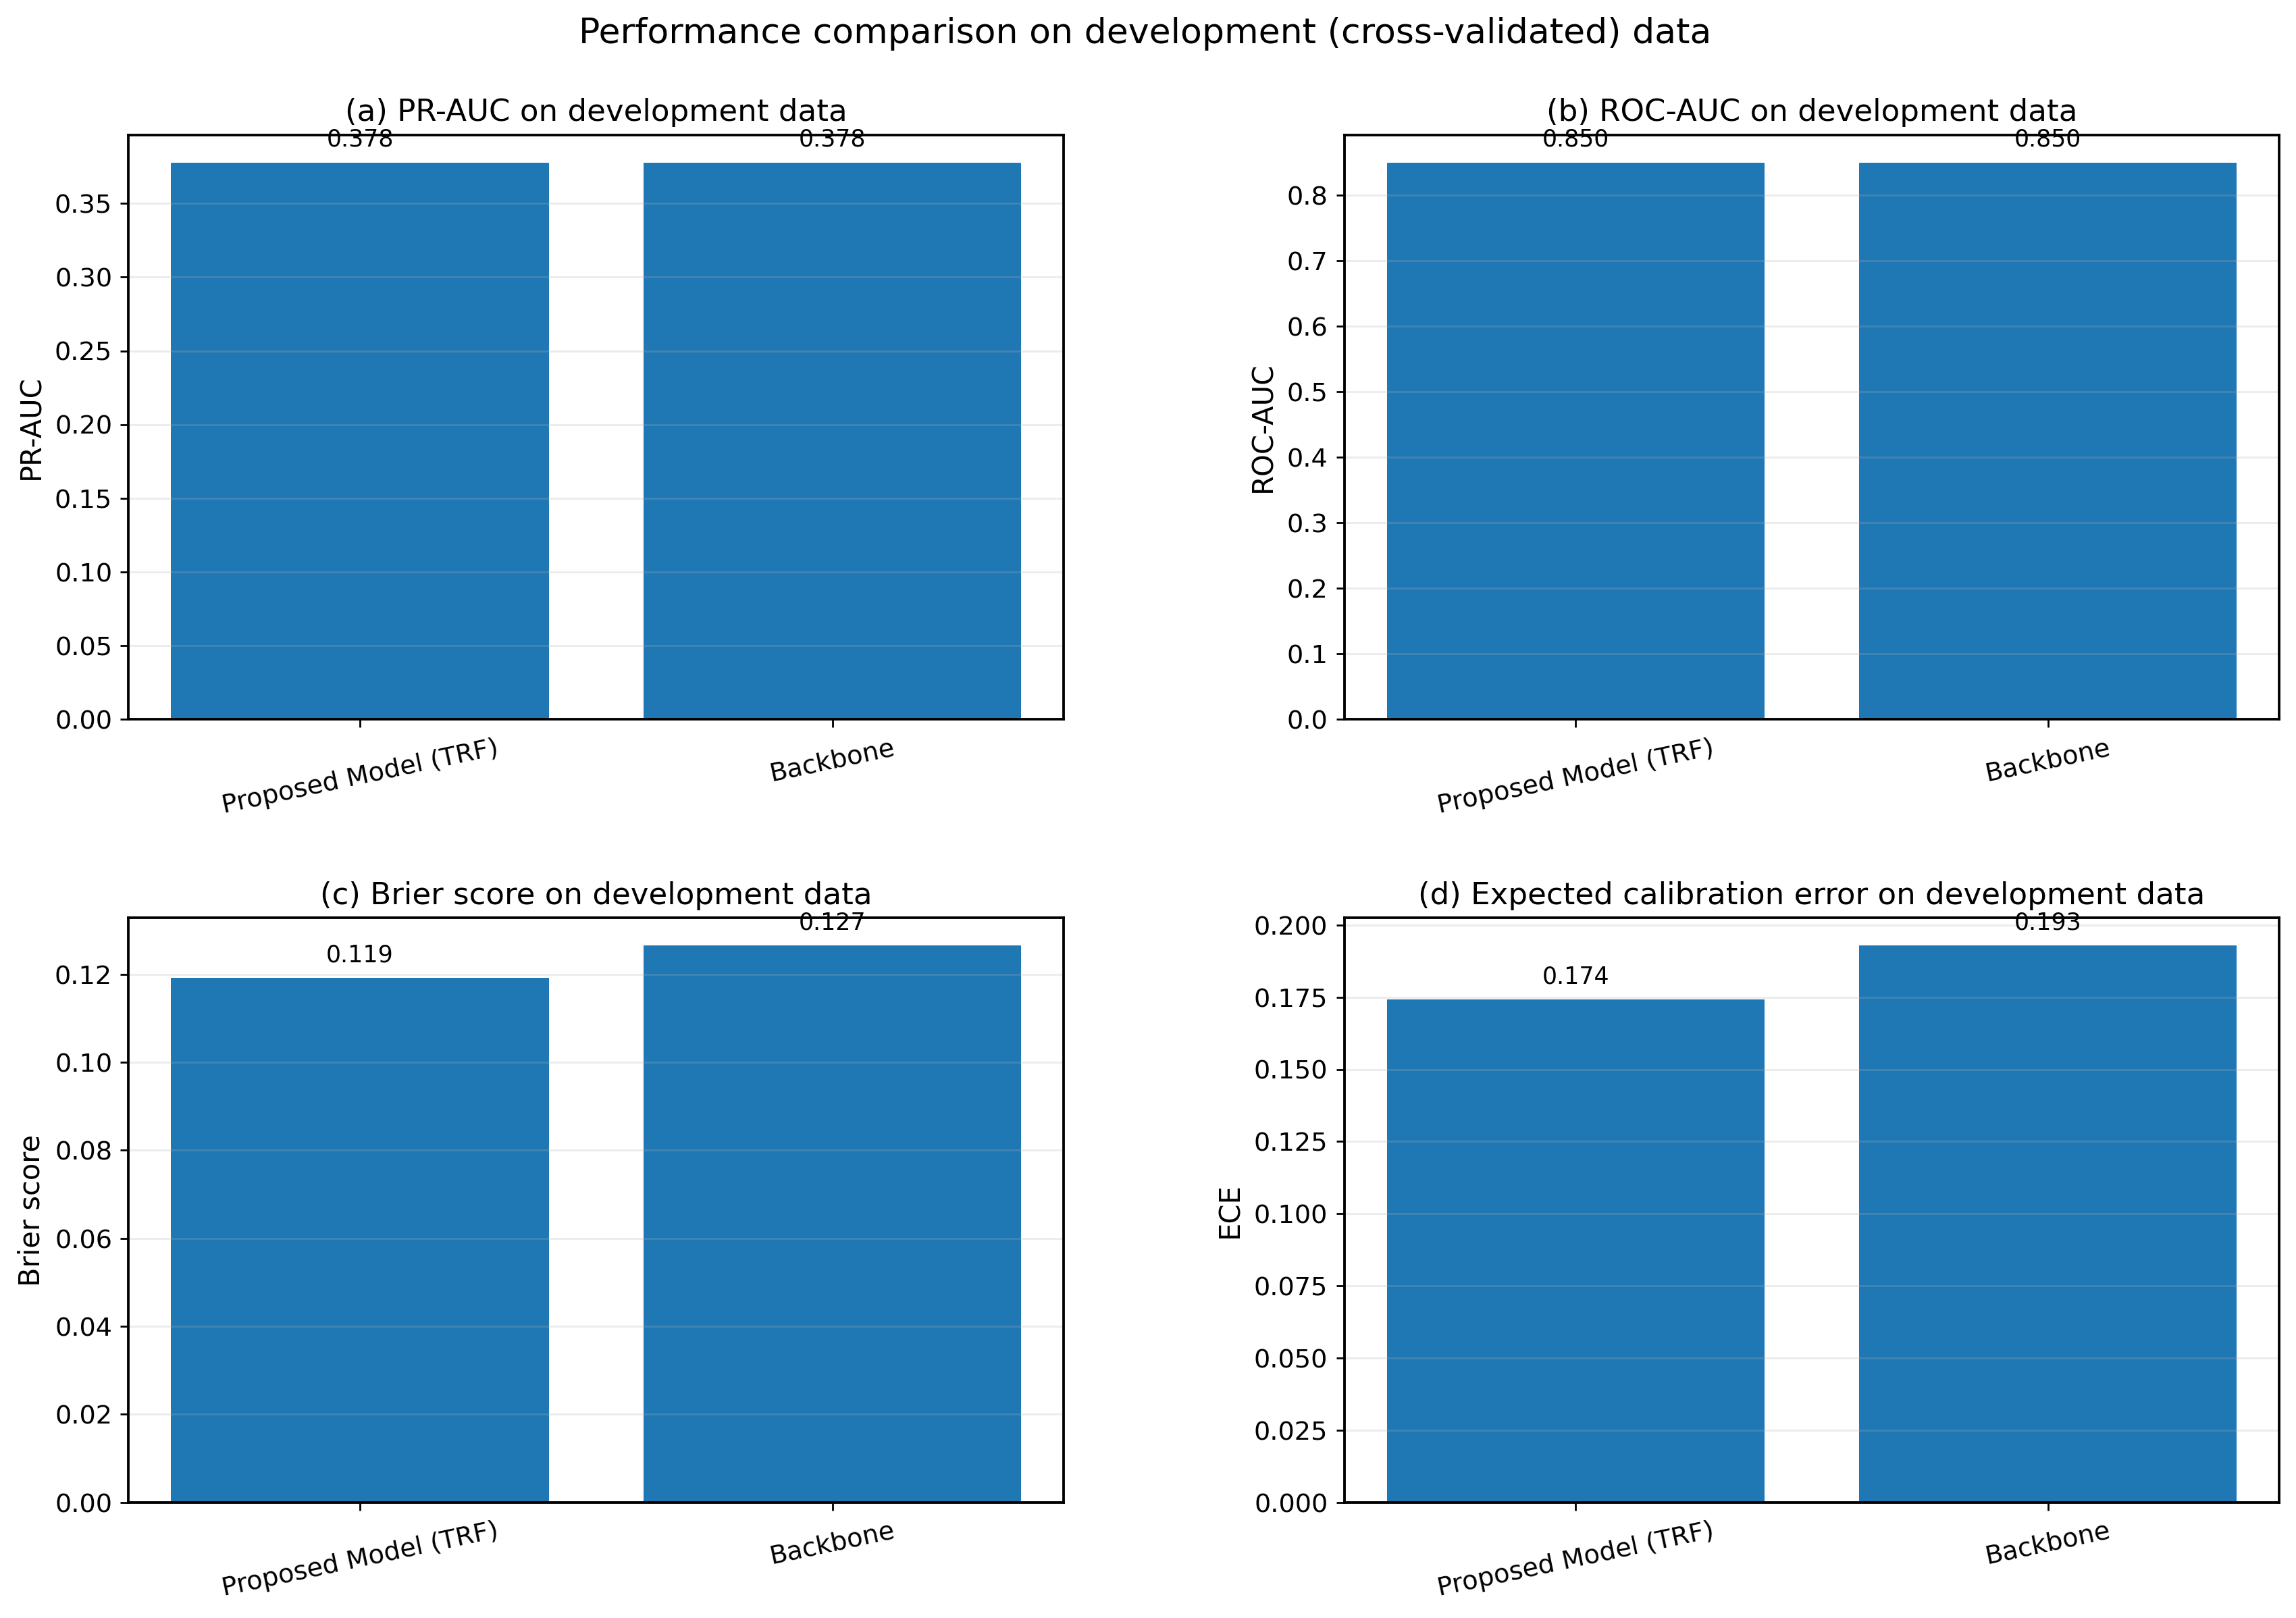


Saved:
 - /kaggle/working/outputs/figures/paper_validation_performance_figure.png
 - /kaggle/working/outputs/figures/paper_validation_performance_figure.pdf
 - paper_validation_performance_figure_data.csv


In [48]:
# ============================================================
# Journal-Grade Validation Performance Figure
#
# Figure set:
#   (a) PR-AUC on development (cross-validated / OOF)
#   (b) ROC-AUC on development
#   (c) Brier on development
#   (d) ECE on development
#
# Models:
#   - Proposed Model (TRF)
#   - Backbone (PerfWeightedEnsemble)
#   - CatBoost
#
# Notes:
# - Uses development / OOF results
# - If TRF row is not present in a stored comparison table,
#   reconstructs it from current in-memory outputs when possible
#
# Outputs:
#   outputs/figures/paper_validation_performance_figure.{png,pdf}
#   outputs/tables/paper_validation_performance_figure_data.csv
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["TAB_DIR", "FIG_DIR"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for validation performance figure: {missing}")

print("===== Validation Performance Figure =====")

# ------------------------------------------------------------
# Helper: collect development rows from available tables
# ------------------------------------------------------------
candidate_tables = []

if "ablation_df" in globals():
    candidate_tables.append(("ablation_df", ablation_df.copy()))
if "comparison_df" in globals():
    candidate_tables.append(("comparison_df", comparison_df.copy()))
if "holdout_comparison_df" in globals():
    candidate_tables.append(("holdout_comparison_df", holdout_comparison_df.copy()))

def normalize_metric_table(df):
    out = df.copy()

    # normalize split column
    if "split" not in out.columns and "setting" in out.columns:
        out["split"] = out["setting"]

    # normalize model name for final model
    if "ablation" in out.columns and "model" not in out.columns:
        out["model"] = out["ablation"]

    return out

dev_rows = []

for name, df in candidate_tables:
    tmp = normalize_metric_table(df)
    if "model" not in tmp.columns or "split" not in tmp.columns:
        continue

    mask = tmp["split"].astype(str).str.contains("DEV", case=False, na=False)
    if mask.any():
        dev_rows.append(tmp.loc[mask].copy())

if len(dev_rows) == 0:
    raise ValueError("Could not find any development/cross-validated metric rows in memory.")

dev_metrics_df = pd.concat(dev_rows, axis=0, ignore_index=True)

# ------------------------------------------------------------
# Pick the rows we want
# ------------------------------------------------------------
# Preferred labels from your pipeline
model_name_candidates = {
    "Proposed Model (TRF)": [
        "A4_TRF_Full",
        "TrustAwareResidualFusion",
        "TRF",
        "Current_Final_TRF",
    ],
    "Backbone": [
        "A1_BackboneOnly",
        "PerfWeightedEnsemble",
        "TRF_Backbone",
        "StaticBackbone",
    ],
    "CatBoost": [
        "CatBoost",
    ],
}

selected_rows = []

for pretty_name, candidates in model_name_candidates.items():
    picked = None
    for c in candidates:
        tmp = dev_metrics_df[dev_metrics_df["model"].astype(str) == str(c)].copy()
        if len(tmp) > 0:
            picked = tmp.iloc[0].to_dict()
            break
    if picked is None:
        print(f"Warning: could not find development row for {pretty_name}")
        continue
    picked["pretty_model"] = pretty_name
    selected_rows.append(picked)

plot_df = pd.DataFrame(selected_rows)

if len(plot_df) < 2:
    raise ValueError("Not enough development rows found for plotting.")

# ------------------------------------------------------------
# Keep needed metrics
# ------------------------------------------------------------
needed_metrics = ["PR_AUC", "ROC_AUC", "Brier", "ECE"]
missing_metrics = [m for m in needed_metrics if m not in plot_df.columns]
if missing_metrics:
    raise ValueError(f"Missing metrics in selected rows: {missing_metrics}")

# enforce model order
model_order = ["Proposed Model (TRF)", "Backbone", "CatBoost"]
plot_df["pretty_model"] = pd.Categorical(plot_df["pretty_model"], categories=model_order, ordered=True)
plot_df = plot_df.sort_values("pretty_model").reset_index(drop=True)

# save table for paper traceability
save_cols = ["pretty_model", "model", "split"] + [m for m in needed_metrics if m in plot_df.columns]
plot_df[save_cols].to_csv(
    os.path.join(TAB_DIR, "paper_validation_performance_figure_data.csv"),
    index=False
)

print("\nValidation figure data:")
print(plot_df[save_cols])

# ------------------------------------------------------------
# Plot setup
# ------------------------------------------------------------
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.1,
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1, ax2, ax3, ax4 = axes.flatten()

x = np.arange(len(plot_df))
labels = plot_df["pretty_model"].astype(str).tolist()

def annotate_bars(ax, bars, fmt="{:.3f}", rotation=0):
    for b in bars:
        h = b.get_height()
        ax.annotate(
            fmt.format(h),
            xy=(b.get_x() + b.get_width() / 2, h),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            rotation=rotation
        )

# ------------------------------------------------------------
# (a) PR-AUC
# ------------------------------------------------------------
bars1 = ax1.bar(x, plot_df["PR_AUC"].values)
annotate_bars(ax1, bars1, fmt="{:.3f}")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=12)
ax1.set_ylabel("PR-AUC")
ax1.set_title("(a) PR-AUC on development data")
ax1.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------
# (b) ROC-AUC
# ------------------------------------------------------------
bars2 = ax2.bar(x, plot_df["ROC_AUC"].values)
annotate_bars(ax2, bars2, fmt="{:.3f}")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=12)
ax2.set_ylabel("ROC-AUC")
ax2.set_title("(b) ROC-AUC on development data")
ax2.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------
# (c) Brier
# ------------------------------------------------------------
bars3 = ax3.bar(x, plot_df["Brier"].values)
annotate_bars(ax3, bars3, fmt="{:.3f}")
ax3.set_xticks(x)
ax3.set_xticklabels(labels, rotation=12)
ax3.set_ylabel("Brier score")
ax3.set_title("(c) Brier score on development data")
ax3.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------
# (d) ECE
# ------------------------------------------------------------
bars4 = ax4.bar(x, plot_df["ECE"].values)
annotate_bars(ax4, bars4, fmt="{:.3f}")
ax4.set_xticks(x)
ax4.set_xticklabels(labels, rotation=12)
ax4.set_ylabel("ECE")
ax4.set_title("(d) Expected calibration error on development data")
ax4.grid(axis="y", alpha=0.25)

# ------------------------------------------------------------
# Global layout
# ------------------------------------------------------------
fig.suptitle("Performance comparison on development (cross-validated) data", fontsize=15, y=0.98)
plt.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.91,
    bottom=0.10,
    wspace=0.30,
    hspace=0.34
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
out_base = os.path.join(FIG_DIR, "paper_validation_performance_figure")
plt.savefig(f"{out_base}.png", dpi=400, bbox_inches="tight")
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")
plt.show()

print("\nSaved:")
print(f" - {out_base}.png")
print(f" - {out_base}.pdf")
print(" - paper_validation_performance_figure_data.csv")

In [51]:
# ===== Fix: define safe clipping helpers =====
import numpy as np

EPS = 1e-12

def clip_probs_vec(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def clip_probs_mat(P):
    P = np.asarray(P, dtype=float)
    return np.clip(P, EPS, 1.0 - EPS)

def logit(p):
    p = clip_probs_vec(p)
    return np.log(p / (1.0 - p))

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return 1.0 / (1.0 + np.exp(-z))

In [52]:
print(dev_expert_df[FINAL_EXPERTS].shape)
print(test_expert_df[FINAL_EXPERTS].shape)

P_dev = clip_probs_mat(dev_expert_df[FINAL_EXPERTS].values)
P_test = clip_probs_mat(test_expert_df[FINAL_EXPERTS].values)

print(P_dev.shape)
print(P_test.shape)
print(weights.shape)

(202944, 5)
(50736, 5)
(202944, 5)
(50736, 5)
(5,)


In [54]:
# ============================================================
# One Final Single-Shot Salvage Experiment
# Anchored Residual Logistic Fusion (ARLF) — UPDATED / FIXED
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "SEED",
    "oof_df", "baseline_df", "holdout_pred_df",
    "TAB_DIR", "PRED_DIR", "LOG_DIR", "MOD_DIR",
    "compute_classification_metrics",
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for ARLF module: {missing}")

print("===== ARLF: Anchored Residual Logistic Fusion =====")

# ------------------------------------------------------------
# Locked config
# ------------------------------------------------------------
FINAL_EXPERTS = ["CatBoost", "LogReg_ElasticNet", "MLP", "DeepFM", "LightGBM"]
FINAL_EXPERTS = [m for m in FINAL_EXPERTS if m in oof_df.columns]

if len(FINAL_EXPERTS) < 3:
    raise ValueError(f"Too few experts found: {FINAL_EXPERTS}")

ARLF_C = 0.1
ARLF_MAX_ITER = 4000

print("Experts:", FINAL_EXPERTS)
print("ARLF C:", ARLF_C)

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
EPS = 1e-12

def clip_probs_vec(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return np.clip(p, EPS, 1.0 - EPS)

def clip_probs_mat(P):
    P = np.asarray(P, dtype=float)
    return np.clip(P, EPS, 1.0 - EPS)

def logit(p):
    p = clip_probs_vec(p)
    return np.log(p / (1.0 - p))

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return 1.0 / (1.0 + np.exp(-z))

def get_static_backbone_weights(expert_names, baseline_df):
    perf_map = baseline_df.set_index("model")["PR_AUC"].to_dict()
    w = np.array([perf_map[m] for m in expert_names], dtype=float)
    return w / w.sum()

def build_small_meta_features(expert_df, expert_cols, idx_col):
    P = clip_probs_mat(expert_df[expert_cols].values.astype(float))

    out = pd.DataFrame({
        idx_col: expert_df[idx_col].values,
        "y_true": expert_df["y_true"].values.astype(int),
    })

    for m in expert_cols:
        out[m] = clip_probs_vec(expert_df[m].values)

    out["prob_mean"] = np.mean(P, axis=1)
    out["prob_std"] = np.std(P, axis=1)
    out["prob_min"] = np.min(P, axis=1)
    out["prob_max"] = np.max(P, axis=1)
    out["prob_range"] = out["prob_max"] - out["prob_min"]

    sortedP = np.sort(P, axis=1)
    out["top1_prob"] = sortedP[:, -1]
    out["top2_prob"] = sortedP[:, -2]
    out["top1_top2_margin"] = sortedP[:, -1] - sortedP[:, -2]

    return out

# ------------------------------------------------------------
# Build dev / holdout expert tables
# ------------------------------------------------------------
required_dev_cols = ["row_idx_dev", "y_true"] + FINAL_EXPERTS
missing_dev_cols = [c for c in required_dev_cols if c not in oof_df.columns]
if missing_dev_cols:
    raise ValueError(f"Missing development OOF columns: {missing_dev_cols}")

required_test_cols = ["row_idx_test", "y_true"] + [f"{m}_pred" for m in FINAL_EXPERTS]
missing_test_cols = [c for c in required_test_cols if c not in holdout_pred_df.columns]
if missing_test_cols:
    raise ValueError(f"Missing holdout columns: {missing_test_cols}")

dev_expert_df = oof_df[required_dev_cols].copy()

test_expert_df = pd.DataFrame({
    "row_idx_test": holdout_pred_df["row_idx_test"].values,
    "y_true": holdout_pred_df["y_true"].values,
})
for m in FINAL_EXPERTS:
    test_expert_df[m] = holdout_pred_df[f"{m}_pred"].values

# ------------------------------------------------------------
# Static backbone
# ------------------------------------------------------------
weights = get_static_backbone_weights(FINAL_EXPERTS, baseline_df)

P_dev = clip_probs_mat(dev_expert_df[FINAL_EXPERTS].values)
P_test = clip_probs_mat(test_expert_df[FINAL_EXPERTS].values)

y_dev = dev_expert_df["y_true"].values.astype(int)
y_test = test_expert_df["y_true"].values.astype(int)

p_backbone_dev = clip_probs_vec(np.sum(P_dev * weights.reshape(1, -1), axis=1))
p_backbone_test = clip_probs_vec(np.sum(P_test * weights.reshape(1, -1), axis=1))

print("Shapes:")
print("  P_dev:", P_dev.shape)
print("  P_test:", P_test.shape)
print("  weights:", weights.shape)

# ------------------------------------------------------------
# Small anchored meta features
# ------------------------------------------------------------
dev_meta = build_small_meta_features(dev_expert_df, FINAL_EXPERTS, "row_idx_dev")
test_meta = build_small_meta_features(test_expert_df, FINAL_EXPERTS, "row_idx_test")

feature_cols = FINAL_EXPERTS + [
    "prob_mean", "prob_std", "prob_range", "top1_top2_margin"
]

X_dev = dev_meta[feature_cols].copy()
X_test = test_meta[feature_cols].copy()

# Add backbone logit as explicit anchor feature
X_dev["backbone_logit"] = logit(p_backbone_dev)
X_test["backbone_logit"] = logit(p_backbone_test)

# ------------------------------------------------------------
# Train ARLF
# ------------------------------------------------------------
arlf = LogisticRegression(
    penalty="l2",
    C=ARLF_C,
    solver="liblinear",
    class_weight="balanced",
    max_iter=ARLF_MAX_ITER,
    random_state=SEED,
)

arlf.fit(X_dev, y_dev)

p_arlf_dev = clip_probs_vec(arlf.predict_proba(X_dev)[:, 1])
p_arlf_test = clip_probs_vec(arlf.predict_proba(X_test)[:, 1])

# ------------------------------------------------------------
# Compare
# ------------------------------------------------------------
rows = []

def add_row(model_name, split_name, y_true, p_pred):
    row = {"model": model_name, "split": split_name}
    row.update(compute_classification_metrics(y_true, p_pred, threshold_mode="f1"))
    rows.append(row)

add_row("StaticBackbone", "DEV_crossfitted", y_dev, p_backbone_dev)
add_row("ARLF", "DEV_crossfitted", y_dev, p_arlf_dev)

add_row("StaticBackbone", "HOLDOUT", y_test, p_backbone_test)
add_row("ARLF", "HOLDOUT", y_test, p_arlf_test)

if "TrustAwareResidualFusion_pred" in holdout_pred_df.columns:
    add_row("Current_Final_TRF", "HOLDOUT", y_test, holdout_pred_df["TrustAwareResidualFusion_pred"].values)

if "PerfWeightedEnsemble_pred" in holdout_pred_df.columns:
    add_row("PerfWeightedEnsemble", "HOLDOUT", y_test, holdout_pred_df["PerfWeightedEnsemble_pred"].values)

if "CatBoost_pred" in holdout_pred_df.columns:
    add_row("CatBoost", "HOLDOUT", y_test, holdout_pred_df["CatBoost_pred"].values)

comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(os.path.join(TAB_DIR, "module_arlf_comparison.csv"), index=False)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------
pred_df = pd.DataFrame({
    "row_idx_test": test_expert_df["row_idx_test"].values,
    "y_true": y_test,
    "StaticBackbone_pred": p_backbone_test,
    "ARLF_pred": p_arlf_test,
})
pred_df.to_csv(os.path.join(PRED_DIR, "module_arlf_holdout_predictions.csv"), index=False)

# ------------------------------------------------------------
# Coefficients for interpretability
# ------------------------------------------------------------
coef_df = pd.DataFrame({
    "feature": X_dev.columns,
    "coef": arlf.coef_.reshape(-1),
    "abs_coef": np.abs(arlf.coef_.reshape(-1)),
}).sort_values("abs_coef", ascending=False).reset_index(drop=True)

coef_df.to_csv(os.path.join(TAB_DIR, "module_arlf_coefficients.csv"), index=False)

joblib.dump(arlf, os.path.join(MOD_DIR, "ARLF_model.joblib"))

with open(os.path.join(LOG_DIR, "module_arlf_metadata.json"), "w") as f:
    json.dump({
        "experts": FINAL_EXPERTS,
        "C": ARLF_C,
        "feature_cols": list(X_dev.columns),
    }, f, indent=2)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
show_cols = ["model", "split", "PR_AUC", "ROC_AUC", "Brier", "ECE", "F1", "MCC", "Accuracy"]
show_cols = [c for c in show_cols if c in comparison_df.columns]

print("\n===== ARLF Comparison =====")
print(comparison_df[show_cols])

print("\nTop ARLF coefficients:")
print(coef_df.head(15))

print("\nSaved:")
print(" - module_arlf_comparison.csv")
print(" - module_arlf_holdout_predictions.csv")
print(" - module_arlf_coefficients.csv")
print(" - ARLF_model.joblib")
print(" - module_arlf_metadata.json")

===== ARLF: Anchored Residual Logistic Fusion =====
Experts: ['CatBoost', 'LogReg_ElasticNet', 'MLP', 'DeepFM', 'LightGBM']
ARLF C: 0.1
Shapes:
  P_dev: (202944, 5)
  P_test: (50736, 5)
  weights: (5,)

===== ARLF Comparison =====
                  model            split    PR_AUC   ROC_AUC     Brier  \
0        StaticBackbone  DEV_crossfitted  0.377725  0.849586  0.126514   
1                  ARLF  DEV_crossfitted  0.378678  0.850186  0.167621   
2        StaticBackbone          HOLDOUT  0.368174  0.849514  0.128184   
3                  ARLF          HOLDOUT  0.366846  0.849095  0.166471   
4     Current_Final_TRF          HOLDOUT  0.367522  0.849489  0.120824   
5  PerfWeightedEnsemble          HOLDOUT  0.368174  0.849514  0.128184   
6              CatBoost          HOLDOUT  0.366568  0.847625  0.158492   

        ECE        F1       MCC  Accuracy  
0  0.192826  0.420418  0.358731  0.851181  
1  0.253557  0.420604  0.357722  0.855339  
2  0.194315  0.425011  0.364719  0.850836  
